In [1]:
import pandas as pd

job_ids = pd.read_csv(
    "../data/raw/mit_supercloud/labelled_jobids.csv"
)

job_stats = pd.read_csv(
    "../data/raw/mit_supercloud/labelled_job_stats.csv"
)

job_ids.head()

,id_job,model
0,25664193915111,dimenet
1,42371679622969,schnet
2,64971010680493,conv
3,75737118513639,pna
4,68345852389234,dimenet


In [2]:
print(job_ids.shape)
print(job_ids.columns.tolist())
print(job_ids.head(10))

(3430, 2)
['id_job', 'model']
           id_job    model
0  25664193915111  dimenet
1  42371679622969   schnet
2  64971010680493     conv
3  75737118513639      pna
4  68345852389234  dimenet
5  55635858367332   schnet
6  15609644815926     conv
7  32008563524845  dimenet
8  56507584426656   schnet
9  52703854959199     conv


In [3]:
model_counts = (
    job_ids["model"]
    .value_counts()
    .rename_axis("model")
    .reset_index(name="job_count")
)

model_counts

,model,job_count
0,inception4,243
1,inception3,241
2,vgg19,199
3,bert-base-uncased,189
4,vgg11,185
5,vgg16,176
6,distilbert-base-uncased,172
7,U3-32,165
8,U3-128,165
9,U4-32,163


In [4]:
job_ids["model"].nunique()

26

In [5]:
job_ids["model"].value_counts()

model
inception4                 243
inception3                 241
vgg19                      199
bert-base-uncased          189
vgg11                      185
vgg16                      176
distilbert-base-uncased    172
U3-32                      165
U3-128                     165
U4-32                      163
U3-64                      159
U4-64                      158
U5-32                      158
U5-64                      158
U4-128                     157
U5-128                     148
resnet50                   111
resnet50_v1.5               91
resnet101                   77
resnet152                   76
resnet152_v2                54
resnet101_v2                54
schnet                      39
dimenet                     33
conv                        32
pna                         27
Name: count, dtype: int64

In [6]:
job_stats

,model,count
0,U3-128,165
1,U3-32,165
2,U3-64,159
3,U4-128,157
4,U4-32,163
5,U4-64,158
6,U5-128,148
7,U5-32,158
8,U5-64,158
9,bert-base-uncased,189


In [7]:
print(job_stats.shape)
print(job_stats.columns.tolist())

(26, 2)
['model', 'count']


In [8]:
job_stats.head(20)

,model,count
0,U3-128,165
1,U3-32,165
2,U3-64,159
3,U4-128,157
4,U4-32,163
5,U4-64,158
6,U5-128,148
7,U5-32,158
8,U5-64,158
9,bert-base-uncased,189


In [9]:
model_counts = (
    job_ids["model"]
    .value_counts()
    .rename_axis("model")
    .reset_index(name="job_count")
)

model_counts

,model,job_count
0,inception4,243
1,inception3,241
2,vgg19,199
3,bert-base-uncased,189
4,vgg11,185
5,vgg16,176
6,distilbert-base-uncased,172
7,U3-32,165
8,U3-128,165
9,U4-32,163


In [10]:
print("Unique models:", job_ids["model"].nunique())

Unique models: 26


In [11]:
print("Job stats shape:", job_stats.shape)
print("Job stats columns:", job_stats.columns.tolist())

job_stats.head(20)

Job stats shape: (26, 2)
Job stats columns: ['model', 'count']


,model,count
0,U3-128,165
1,U3-32,165
2,U3-64,159
3,U4-128,157
4,U4-32,163
5,U4-64,158
6,U5-128,148
7,U5-32,158
8,U5-64,158
9,bert-base-uncased,189


In [14]:
# MIT Supercloud: identify GPU jobs from scheduler metadata

import pandas as pd
import numpy as np
from pathlib import Path

MIT_RAW = Path("../data/raw/mit_supercloud")

# Load only the columns needed to identify GPU jobs
scheduler_log_path = MIT_RAW / "slurm-log.csv"

scheduler_log_df = pd.read_csv(
    scheduler_log_path,
    usecols=["id_job", "tres_req"]
)

print(f"Scheduler log shape: {scheduler_log_df.shape}")
print(f"Columns loaded: {scheduler_log_df.columns.tolist()}")

Scheduler log shape: (395914, 2)
Columns loaded: ['id_job', 'tres_req']


In [15]:
# Identify GPU jobs using MIT's verified TRES mapping
# 1001 = gpu:tesla
# 1002 = gpu:volta

gpu_idx = scheduler_log_df["tres_req"].astype(str).str.contains(
    r"1001|1002",
    regex=True,
    na=False
)

gpu_job_ids = np.unique(
    scheduler_log_df.loc[gpu_idx, "id_job"].values
)

print(f"Total scheduler records: {len(scheduler_log_df):,}")
print(f"GPU scheduler records: {gpu_idx.sum():,}")
print(f"Unique GPU job IDs: {len(gpu_job_ids):,}")

Total scheduler records: 395,914
GPU scheduler records: 98,176
Unique GPU job IDs: 98,176


In [16]:
# Cross-reference GPU jobs with MIT's labeled AI workloads

labeled_gpu_jobs = job_ids[
    job_ids["id_job"].isin(gpu_job_ids)
].copy()

print(f"Labeled AI jobs: {len(job_ids):,}")
print(f"Labeled AI jobs with GPU scheduler records: {len(labeled_gpu_jobs):,}")

print("\nWorkload distribution:")
print(labeled_gpu_jobs["model"].value_counts())

Labeled AI jobs: 3,430
Labeled AI jobs with GPU scheduler records: 3,430

Workload distribution:
model
inception4                 243
inception3                 241
vgg19                      199
bert-base-uncased          189
vgg11                      185
vgg16                      176
distilbert-base-uncased    172
U3-32                      165
U3-128                     165
U4-32                      163
U3-64                      159
U4-64                      158
U5-32                      158
U5-64                      158
U4-128                     157
U5-128                     148
resnet50                   111
resnet50_v1.5               91
resnet101                   77
resnet152                   76
resnet152_v2                54
resnet101_v2                54
schnet                      39
dimenet                     33
conv                        32
pna                         27
Name: count, dtype: int64


In [17]:
# Select one representative real job for each labeled workload

pilot_jobs = (
    labeled_gpu_jobs
    .groupby("model", group_keys=False)
    .sample(n=1, random_state=42)
    .sort_values("model")
    .reset_index(drop=True)
)

print(f"Pilot jobs selected: {len(pilot_jobs)}")
display(pilot_jobs)

Pilot jobs selected: 26


,id_job,model
0,25713459161743,U3-128
1,29381280178268,U3-32
2,74636684972411,U3-64
3,59638293409445,U4-128
4,68307271431118,U4-32
5,48020198141948,U4-64
6,59030654331752,U5-128
7,18242747496687,U5-32
8,79150048009801,U5-64
9,8427789164283,bert-base-uncased


In [18]:
# Prepare our pilot job IDs for locating GPU telemetry

pilot_job_ids = pilot_jobs["id_job"].astype(str).tolist()

print(f"Pilot jobs: {len(pilot_job_ids)}")
print(pilot_job_ids)

Pilot jobs: 26
['25713459161743', '29381280178268', '74636684972411', '59638293409445', '68307271431118', '48020198141948', '59030654331752', '18242747496687', '79150048009801', '8427789164283', '15179646833041', '9761351256032', '2304959634945', '59464190077432', '80384695883841', '36230628475012', '55788973536832', '80249445248004', '15305255756787', '42978538849394', '44317307973280', '38596192451856', '18203079158032', '78604982814993', '13063192210942', '48510612336879']


In [19]:
# Inspect the three real GPU telemetry files

from pathlib import Path
import pandas as pd

GPU_RAW = Path("../data/raw/mit_supercloud/gpu")

gpu_files = list(GPU_RAW.glob("*.csv"))

print(f"GPU telemetry files found: {len(gpu_files)}")

for file in gpu_files:
    print(f"{file.name} — {file.stat().st_size / (1024**2):.2f} MB")

GPU telemetry files found: 3
18203079158032-r4327055-n136082.csv — 6.85 MB
8427789164283-r629115-n43543.csv — 15.15 MB
68307271431118-r1682297-n911952.csv — 5.63 MB


In [20]:
# Inspect the first telemetry file

sample_gpu_file = gpu_files[0]

gpu_sample = pd.read_csv(sample_gpu_file, nrows=5)

print("File:", sample_gpu_file.name)
print("Columns:")
print(gpu_sample.columns.tolist())

display(gpu_sample)

File: 18203079158032-r4327055-n136082.csv
Columns:
['timestamp', 'gpu_index', 'utilization_gpu_pct', 'utilization_memory_pct', 'memory_free_MiB', 'memory_used_MiB', 'temperature_gpu', 'temperature_memory', 'power_draw_W', 'pcie_link_width_current']


,timestamp,gpu_index,utilization_gpu_pct,utilization_memory_pct,memory_free_MiB,memory_used_MiB,temperature_gpu,temperature_memory,power_draw_W,pcie_link_width_current
0,1.629195e+09,0,0,0,32510,0,30,28,25.95,16
1,1.629195e+09,1,0,0,32510,0,29,27,26.27,16
2,1.629195e+09,0,0,0,32510,0,30,28,25.95,16
3,1.629195e+09,1,0,0,32510,0,29,27,26.26,16
4,1.629195e+09,0,0,0,32510,0,30,27,25.97,16


In [21]:
# Examine timestamp resolution and GPU coverage

gpu_df = pd.read_csv(sample_gpu_file)

gpu_df["timestamp_dt"] = pd.to_datetime(
    gpu_df["timestamp"],
    unit="s",
    utc=True
)

print(f"Rows: {len(gpu_df):,}")
print(f"Unique GPUs: {gpu_df['gpu_index'].nunique()}")
print(f"GPU indices: {sorted(gpu_df['gpu_index'].unique())}")

print("\nTime range:")
print(f"Start: {gpu_df['timestamp_dt'].min()}")
print(f"End:   {gpu_df['timestamp_dt'].max()}")

print("\nSampling intervals:")
print(
    gpu_df["timestamp"]
    .sort_values()
    .diff()
    .value_counts()
    .head(10)
)

Rows: 145,574
Unique GPUs: 2
GPU indices: [np.int64(0), np.int64(1)]

Time range:
Start: 2021-08-17 10:05:06.279000044+00:00
End:   2021-08-17 12:14:44.177000046+00:00

Sampling intervals:
timestamp
0.003    47779
0.103    35780
0.103    16148
0.105     4944
0.004     4734
0.003     4603
0.102     3802
0.006     3785
0.104     3715
0.106     3705
Name: count, dtype: int64


In [22]:
# Calculate timestamp intervals independently for each GPU

gpu_df["timestamp_dt"] = pd.to_datetime(
    gpu_df["timestamp"],
    unit="s",
    utc=True
)

gpu_df = gpu_df.sort_values(
    ["gpu_index", "timestamp_dt"]
).reset_index(drop=True)

gpu_df["interval_seconds"] = (
    gpu_df.groupby("gpu_index")["timestamp_dt"]
    .diff()
    .dt.total_seconds()
)

for gpu_id, group in gpu_df.groupby("gpu_index"):
    intervals = group["interval_seconds"].dropna()

    print(f"\nGPU {gpu_id}")
    print(f"Observations: {len(group):,}")
    print(f"Median interval: {intervals.median():.4f} seconds")
    print(f"Mean interval: {intervals.mean():.4f} seconds")
    print(f"P95 interval: {intervals.quantile(0.95):.4f} seconds")
    print(f"Intervals <= 0.2 sec: {(intervals <= 0.2).mean() * 100:.2f}%")


GPU 0
Observations: 72,787
Median interval: 0.1060 seconds
Mean interval: 0.1069 seconds
P95 interval: 0.1090 seconds
Intervals <= 0.2 sec: 100.00%

GPU 1
Observations: 72,787
Median interval: 0.1060 seconds
Mean interval: 0.1069 seconds
P95 interval: 0.1090 seconds
Intervals <= 0.2 sec: 100.00%


In [23]:
# Validate telemetry cadence across all three pilot jobs

for file in sorted(gpu_files):
    df = pd.read_csv(file)

    df["timestamp_dt"] = pd.to_datetime(
        df["timestamp"],
        unit="s",
        utc=True
    )

    print(f"\n{'=' * 70}")
    print(f"File: {file.name}")
    print(f"Rows: {len(df):,}")
    print(f"GPUs: {df['gpu_index'].nunique()}")
    print(f"GPU IDs: {sorted(df['gpu_index'].unique())}")
    print(f"Start: {df['timestamp_dt'].min()}")
    print(f"End:   {df['timestamp_dt'].max()}")

    for gpu_id, group in df.groupby("gpu_index"):
        group = group.sort_values("timestamp_dt")
        intervals = group["timestamp_dt"].diff().dt.total_seconds().dropna()

        print(
            f"  GPU {gpu_id}: "
            f"median={intervals.median():.4f}s, "
            f"mean={intervals.mean():.4f}s, "
            f"P95={intervals.quantile(0.95):.4f}s"
        )


File: 18203079158032-r4327055-n136082.csv
Rows: 145,574
GPUs: 2
GPU IDs: [np.int64(0), np.int64(1)]
Start: 2021-08-17 10:05:06.279000044+00:00
End:   2021-08-17 12:14:44.177000046+00:00
  GPU 0: median=0.1060s, mean=0.1069s, P95=0.1090s
  GPU 1: median=0.1060s, mean=0.1069s, P95=0.1090s

File: 68307271431118-r1682297-n911952.csv
Rows: 119,670
GPUs: 2
GPU IDs: [np.int64(0), np.int64(1)]
Start: 2021-05-14 09:07:41.611999989+00:00
End:   2021-05-14 10:54:08.460000038+00:00
  GPU 0: median=0.1060s, mean=0.1067s, P95=0.1090s
  GPU 1: median=0.1060s, mean=0.1067s, P95=0.1090s

File: 8427789164283-r629115-n43543.csv
Rows: 328,984
GPUs: 2
GPU IDs: [np.int64(0), np.int64(1)]
Start: 2021-07-02 06:42:23.903000116+00:00
End:   2021-07-02 11:35:36.849999905+00:00
  GPU 0: median=0.1070s, mean=0.1070s, P95=0.1090s
  GPU 1: median=0.1070s, mean=0.1070s, P95=0.1090s


In [24]:
# Map telemetry files to their verified MIT workload labels

pilot_metadata = {
    "18203079158032": {
        "model": "schnet",
        "workload_family": "GNN"
    },
    "68307271431118": {
        "model": "U4-32",
        "workload_family": "Vision"
    },
    "8427789164283": {
        "model": "bert-base-uncased",
        "workload_family": "NLP"
    }
}

print(pilot_metadata)

{'18203079158032': {'model': 'schnet', 'workload_family': 'GNN'}, '68307271431118': {'model': 'U4-32', 'workload_family': 'Vision'}, '8427789164283': {'model': 'bert-base-uncased', 'workload_family': 'NLP'}}


In [25]:
# Transform raw GPU telemetry into a 1-second analytical dataset

def aggregate_gpu_telemetry(file_path, job_id, model, workload_family):
    df = pd.read_csv(file_path)

    # Convert Unix epoch timestamps to UTC datetime
    df["timestamp"] = pd.to_datetime(
        df["timestamp"],
        unit="s",
        utc=True
    )

    # Add job metadata
    df["job_id"] = str(job_id)
    df["model"] = model
    df["workload_family"] = workload_family

    # Create 1-second time buckets
    df["timestamp_1s"] = df["timestamp"].dt.floor("1s")

    # Aggregate while retaining GPU-level information
    aggregated = (
        df.groupby(
            [
                "job_id",
                "model",
                "workload_family",
                "gpu_index",
                "timestamp_1s"
            ],
            as_index=False
        )
        .agg(
            gpu_utilization_pct=("utilization_gpu_pct", "mean"),
            memory_utilization_pct=("utilization_memory_pct", "mean"),
            memory_used_MiB=("memory_used_MiB", "mean"),
            memory_free_MiB=("memory_free_MiB", "mean"),
            temperature_gpu_avg=("temperature_gpu", "mean"),
            temperature_gpu_max=("temperature_gpu", "max"),
            temperature_memory_avg=("temperature_memory", "mean"),
            power_draw_W=("power_draw_W", "mean"),
            pcie_link_width_current=("pcie_link_width_current", "mean"),
            raw_observation_count=("timestamp", "count")
        )
    )

    return aggregated


# Build the analytical dataset for all three pilot jobs
pilot_aggregated = []

for file in sorted(gpu_files):
    job_id = next(
        job_id for job_id in pilot_metadata
        if job_id in file.name
    )

    metadata = pilot_metadata[job_id]

    aggregated = aggregate_gpu_telemetry(
        file_path=file,
        job_id=job_id,
        model=metadata["model"],
        workload_family=metadata["workload_family"]
    )

    pilot_aggregated.append(aggregated)

pilot_gpu_df = pd.concat(
    pilot_aggregated,
    ignore_index=True
)

print(f"Raw telemetry rows: {sum(len(pd.read_csv(f)) for f in gpu_files):,}")
print(f"Aggregated rows: {len(pilot_gpu_df):,}")

display(pilot_gpu_df.head())

Raw telemetry rows: 594,228
Aggregated rows: 63,522


,job_id,model,workload_family,gpu_index,timestamp_1s,gpu_utilization_pct,memory_utilization_pct,memory_used_MiB,memory_free_MiB,temperature_gpu_avg,temperature_gpu_max,temperature_memory_avg,power_draw_W,pcie_link_width_current,raw_observation_count
0,18203079158032,schnet,GNN,0,2021-08-17 10:05:06+00:00,0.0,0.0,0.0,32510.0,30.0,30,27.714286,25.960000,16.0,7
1,18203079158032,schnet,GNN,0,2021-08-17 10:05:07+00:00,0.0,0.0,0.0,32510.0,30.0,30,27.888889,25.961111,16.0,9
2,18203079158032,schnet,GNN,0,2021-08-17 10:05:08+00:00,0.0,0.0,0.0,32510.0,30.0,30,27.800000,25.939000,16.0,10
3,18203079158032,schnet,GNN,0,2021-08-17 10:05:09+00:00,0.0,0.0,0.0,32510.0,30.0,30,27.777778,25.952222,16.0,9
4,18203079158032,schnet,GNN,0,2021-08-17 10:05:10+00:00,0.0,0.0,0.0,32510.0,30.0,30,27.888889,26.001111,16.0,9


In [26]:
# Save the first processed real-data telemetry dataset

PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

processed_path = PROCESSED_DIR / "mit_gpu_telemetry_pilot_1s.csv"

pilot_gpu_df.to_csv(
    processed_path,
    index=False
)

print(f"Saved: {processed_path}")
print(f"Rows: {len(pilot_gpu_df):,}")
print(f"Columns: {len(pilot_gpu_df.columns)}")
print(f"File size: {processed_path.stat().st_size / (1024**2):.2f} MB")

Saved: ../data/processed/mit_gpu_telemetry_pilot_1s.csv
Rows: 63,522
Columns: 15
File size: 8.90 MB


In [27]:
# Basic data-quality checks

print("Missing values:")
display(
    pilot_gpu_df.isna()
    .sum()
    .sort_values(ascending=False)
)

print("\nUnique jobs:")
print(pilot_gpu_df["job_id"].nunique())

print("\nWorkload families:")
print(pilot_gpu_df["workload_family"].value_counts())

print("\nGPU counts by job:")
display(
    pilot_gpu_df
    .groupby(["job_id", "model"])["gpu_index"]
    .nunique()
)

Missing values:


job_id                     0
model                      0
workload_family            0
gpu_index                  0
timestamp_1s               0
gpu_utilization_pct        0
memory_utilization_pct     0
memory_used_MiB            0
memory_free_MiB            0
temperature_gpu_avg        0
temperature_gpu_max        0
temperature_memory_avg     0
power_draw_W               0
pcie_link_width_current    0
raw_observation_count      0
dtype: int64


Unique jobs:
3

Workload families:
workload_family
NLP       35188
GNN       15558
Vision    12776
Name: count, dtype: int64

GPU counts by job:


job_id          model            
18203079158032  schnet               2
68307271431118  U4-32                2
8427789164283   bert-base-uncased    2
Name: gpu_index, dtype: int64

In [28]:
# Build job-level performance summary

job_summary = (
    pilot_gpu_df
    .groupby(["job_id", "model", "workload_family"])
    .agg(
        gpu_count=("gpu_index", "nunique"),
        duration_seconds=("timestamp_1s", "nunique"),
        avg_gpu_utilization_pct=("gpu_utilization_pct", "mean"),
        max_gpu_utilization_pct=("gpu_utilization_pct", "max"),
        avg_memory_utilization_pct=("memory_utilization_pct", "mean"),
        max_memory_utilization_pct=("memory_utilization_pct", "max"),
        avg_power_draw_W=("power_draw_W", "mean"),
        max_power_draw_W=("power_draw_W", "max"),
        avg_gpu_temperature_C=("temperature_gpu_avg", "mean"),
        max_gpu_temperature_C=("temperature_gpu_max", "max"),
        avg_memory_used_MiB=("memory_used_MiB", "mean"),
        max_memory_used_MiB=("memory_used_MiB", "max"),
    )
    .reset_index()
)

# Derived metrics
job_summary["duration_hours"] = (
    job_summary["duration_seconds"] / 3600
)

# Approximate GPU energy:
# average power per GPU × duration
job_summary["estimated_gpu_energy_Wh"] = (
    job_summary["avg_power_draw_W"]
    * job_summary["duration_hours"]
)

# GPU-hours consumed by the job
job_summary["gpu_hours"] = (
    job_summary["gpu_count"]
    * job_summary["duration_hours"]
)

# Energy per GPU-hour
job_summary["Wh_per_GPU_hour"] = (
    job_summary["estimated_gpu_energy_Wh"]
    / job_summary["gpu_hours"]
)

display(job_summary)

,job_id,model,workload_family,gpu_count,duration_seconds,avg_gpu_utilization_pct,max_gpu_utilization_pct,avg_memory_utilization_pct,max_memory_utilization_pct,avg_power_draw_W,max_power_draw_W,avg_gpu_temperature_C,max_gpu_temperature_C,avg_memory_used_MiB,max_memory_used_MiB,duration_hours,estimated_gpu_energy_Wh,gpu_hours,Wh_per_GPU_hour
0,18203079158032,schnet,GNN,2,7779,63.065493,89.800000,38.913526,50.444444,122.899587,158.562000,47.599311,54,5095.479973,5807.0,2.160833,265.565524,4.321667,61.449793
1,68307271431118,U4-32,Vision,2,6388,71.303453,83.200000,36.803660,42.222222,127.382422,156.393333,63.214878,72,31001.761127,31075.0,1.774444,226.033032,3.548889,63.691211
2,8427789164283,bert-base-uncased,NLP,2,17594,77.726340,92.666667,8.281163,14.111111,62.925498,106.912222,41.953202,44,3190.057155,4165.0,4.887222,307.530894,9.774444,31.462749


In [29]:
# Correct the energy and GPU-hour calculations

# Total estimated GPU energy across all GPUs
job_summary["estimated_total_gpu_energy_Wh"] = (
    job_summary["avg_power_draw_W"]
    * job_summary["duration_hours"]
    * job_summary["gpu_count"]
)

# Total GPU-hours consumed
job_summary["gpu_hours"] = (
    job_summary["gpu_count"]
    * job_summary["duration_hours"]
)

# GPU-hours weighted by observed utilization
job_summary["effective_gpu_hours"] = (
    job_summary["gpu_hours"]
    * job_summary["avg_gpu_utilization_pct"]
    / 100
)

# Energy required per effective GPU-hour
job_summary["Wh_per_effective_GPU_hour"] = (
    job_summary["estimated_total_gpu_energy_Wh"]
    / job_summary["effective_gpu_hours"]
)

display(
    job_summary[
        [
            "model",
            "workload_family",
            "gpu_count",
            "duration_hours",
            "avg_gpu_utilization_pct",
            "avg_power_draw_W",
            "avg_gpu_temperature_C",
            "estimated_total_gpu_energy_Wh",
            "gpu_hours",
            "effective_gpu_hours",
            "Wh_per_effective_GPU_hour"
        ]
    ]
)

,model,workload_family,gpu_count,duration_hours,avg_gpu_utilization_pct,avg_power_draw_W,avg_gpu_temperature_C,estimated_total_gpu_energy_Wh,gpu_hours,effective_gpu_hours,Wh_per_effective_GPU_hour
0,schnet,GNN,2,2.160833,63.065493,122.899587,47.599311,531.131048,4.321667,2.725480,194.876123
1,U4-32,Vision,2,1.774444,71.303453,127.382422,63.214878,452.066064,3.548889,2.530480,178.648323
2,bert-base-uncased,NLP,2,4.887222,77.726340,62.925498,41.953202,615.061788,9.774444,7.597318,80.957753


In [30]:
# Check the GPU resource type for our three pilot jobs

pilot_job_id_strings = list(pilot_metadata.keys())

pilot_scheduler = scheduler_log_df[
    scheduler_log_df["id_job"].astype(str).isin(pilot_job_id_strings)
].copy()

pilot_scheduler["gpu_type"] = np.select(
    [
        pilot_scheduler["tres_req"].astype(str).str.contains("1001", na=False),
        pilot_scheduler["tres_req"].astype(str).str.contains("1002", na=False)
    ],
    [
        "Tesla",
        "Volta"
    ],
    default="Unknown"
)

display(
    pilot_scheduler[
        ["id_job", "tres_req", "gpu_type"]
    ]
)

,id_job,tres_req,gpu_type
196000,68307271431118,"1=40,2=340000,4=1,5=40,1002=2",Volta
244753,8427789164283,"1=40,2=340000,4=1,5=40,1002=2",Volta
295209,18203079158032,"1=40,2=340000,4=1,5=40,1002=2",Volta


In [31]:
# Build a manifest for all telemetry files belonging to the 26 pilot jobs

pilot_ids = set(pilot_jobs["id_job"].astype(str))

manifest_rows = []

for d in range(100):
    directory = f"{d:04d}"

    # We'll populate this from the S3 listing we already discovered.
    # For now, create the metadata structure from our pilot jobs.
    pass

In [32]:
import pandas as pd
from pathlib import Path

# Read the S3 object listing created in Terminal
listing = pd.read_csv(
    "/tmp/mit_gpu_listing.csv",
    header=None,
    names=["s3_directory", "date", "time", "size_bytes", "filename"]
)

# Extract job ID from the filename
listing["job_id"] = listing["filename"].str.split("-").str[0]

# Load workload metadata
job_ids = pd.read_csv("../data/raw/mit_supercloud/labelled_jobids.csv")
job_ids["id_job"] = job_ids["id_job"].astype(str)

# Rename for joining
job_metadata = job_ids.rename(columns={"id_job": "job_id"})

# Map model information
manifest = listing.merge(
    job_metadata,
    on="job_id",
    how="left"
)

# Map workload families
def classify_workload(model):
    model = str(model).lower()

    if any(x in model for x in ["bert", "distilbert"]):
        return "NLP"
    elif any(x in model for x in ["dimenet", "schnet", "pna", "conv"]):
        return "GNN"
    elif any(x in model for x in ["vgg", "resnet", "inception", "u3", "u4", "u5"]):
        return "Vision"
    else:
        return "Other"

manifest["workload_family"] = manifest["model"].apply(classify_workload)

# Construct exact S3 URI
manifest["s3_uri"] = (
    "s3://mit-supercloud-dataset/"
    "datacenter-challenge/202201/gpu/"
    + manifest["s3_directory"].astype(str)
    + "/"
    + manifest["filename"]
)

# Order columns
manifest = manifest[
    [
        "job_id",
        "model",
        "workload_family",
        "s3_directory",
        "filename",
        "size_bytes",
        "date",
        "time",
        "s3_uri"
    ]
]

# Save reproducible manifest
output_path = Path("../data/reference/mit_supercloud_gpu_pilot_manifest.csv")
manifest.to_csv(output_path, index=False)

print(f"Manifest saved to: {output_path}")
print(f"Telemetry files: {len(manifest)}")
print(f"Unique jobs: {manifest['job_id'].nunique()}")
print(f"Total size: {manifest['size_bytes'].sum() / (1024**2):.2f} MB")

Manifest saved to: ../data/reference/mit_supercloud_gpu_pilot_manifest.csv
Telemetry files: 35
Unique jobs: 26
Total size: 375.84 MB


In [33]:
print(manifest.head())
print()
print("Files by workload family:")
print(manifest["workload_family"].value_counts())
print()
print("Files per job:")
print(manifest.groupby(["job_id", "model"]).size())

           job_id         model workload_family  s3_directory  \
0  59638293409445        U4-128          Vision             1   
1  59638293409445        U4-128          Vision             1   
2  18203079158032        schnet             GNN             9   
3  15305255756787     resnet152          Vision            15   
4  42978538849394  resnet152_v2          Vision            16   

                              filename  size_bytes        date      time  \
0  59638293409445-r3117156-n136082.csv     6249329  2022-01-19  19:53:14   
1  59638293409445-r9352821-n830961.csv     6245933  2022-01-19  19:53:14   
2  18203079158032-r4327055-n136082.csv     7182459  2022-01-19  20:24:13   
3  15305255756787-r6760045-n685852.csv    29277112  2022-01-19  20:49:20   
4  42978538849394-r3405251-n208530.csv    14686745  2022-01-19  20:54:15   

                                              s3_uri  
0  s3://mit-supercloud-dataset/datacenter-challen...  
1  s3://mit-supercloud-dataset/datacenter-

In [34]:
# Load GPU-related scheduler information
scheduler_gpu = pd.read_csv(
    "../data/raw/mit_supercloud/slurm-log.csv",
    usecols=["id_job", "tres_req"]
)

scheduler_gpu["id_job"] = scheduler_gpu["id_job"].astype(str)

# Keep only jobs represented in our 26-job pilot
pilot_scheduler = scheduler_gpu[
    scheduler_gpu["id_job"].isin(manifest["job_id"].unique())
].copy()

# Identify GPU type from TRES request
def get_gpu_type(tres_req):
    tres_req = str(tres_req)

    has_tesla = "1001" in tres_req
    has_volta = "1002" in tres_req

    if has_tesla and has_volta:
        return "Tesla + Volta"
    elif has_tesla:
        return "Tesla"
    elif has_volta:
        return "Volta"
    else:
        return "Unknown"

pilot_scheduler["gpu_type"] = pilot_scheduler["tres_req"].apply(get_gpu_type)

# Keep one row per job
gpu_metadata = (
    pilot_scheduler[
        ["id_job", "gpu_type", "tres_req"]
    ]
    .drop_duplicates("id_job")
    .rename(columns={"id_job": "job_id"})
)

# Join hardware information to the telemetry manifest
manifest = manifest.merge(
    gpu_metadata,
    on="job_id",
    how="left"
)

print("GPU type distribution:")
print(manifest[["job_id", "model", "gpu_type"]].drop_duplicates()["gpu_type"].value_counts())

print("\nMissing GPU types:")
print(manifest["gpu_type"].isna().sum())

GPU type distribution:
gpu_type
Volta    26
Name: count, dtype: int64

Missing GPU types:
0


In [35]:
manifest[
    ["job_id", "model", "workload_family", "gpu_type"]
].drop_duplicates().sort_values("model")

,job_id,model,workload_family,gpu_type
13,25713459161743,U3-128,Vision,Volta
19,29381280178268,U3-32,Vision,Volta
20,74636684972411,U3-64,Vision,Volta
0,59638293409445,U4-128,Vision,Volta
34,68307271431118,U4-32,Vision,Volta
21,48020198141948,U4-64,Vision,Volta
30,59030654331752,U5-128,Vision,Volta
5,18242747496687,U5-32,Vision,Volta
26,79150048009801,U5-64,Vision,Volta
27,8427789164283,bert-base-uncased,NLP,Volta


In [36]:
# Save the completed hardware-aware manifest

manifest_path = "../data/reference/mit_supercloud_gpu_pilot_manifest.csv"

manifest.to_csv(manifest_path, index=False)

print(f"Saved: {manifest_path}")
print(f"Telemetry files: {len(manifest)}")
print(f"Unique jobs: {manifest['job_id'].nunique()}")
print(f"Missing models: {manifest['model'].isna().sum()}")
print(f"Missing GPU types: {manifest['gpu_type'].isna().sum()}")
print(f"Total telemetry size: {manifest['size_bytes'].sum() / (1024**2):.2f} MB")

Saved: ../data/reference/mit_supercloud_gpu_pilot_manifest.csv
Telemetry files: 35
Unique jobs: 26
Missing models: 0
Missing GPU types: 0
Total telemetry size: 375.84 MB


In [37]:
manifest.groupby(
    ["workload_family", "gpu_type"]
).agg(
    jobs=("job_id", "nunique"),
    files=("filename", "count"),
    size_MB=("size_bytes", lambda x: x.sum() / (1024**2))
).reset_index()

,workload_family,gpu_type,jobs,files,size_MB
0,GNN,Volta,4,4,78.670388
1,NLP,Volta,2,2,23.974129
2,Vision,Volta,20,29,273.197573


In [38]:
from pathlib import Path
import pandas as pd

gpu_dir = Path("../data/raw/mit_supercloud/gpu")

# Files expected from our manifest
expected_files = set(manifest["filename"])

# Files actually downloaded
actual_files = {
    f.name for f in gpu_dir.iterdir()
    if f.is_file()
}

missing_files = expected_files - actual_files
unexpected_files = actual_files - expected_files

print(f"Expected files:   {len(expected_files)}")
print(f"Downloaded files: {len(actual_files)}")
print(f"Missing files:    {len(missing_files)}")
print(f"Unexpected files: {len(unexpected_files)}")

if missing_files:
    print("\nMissing:")
    for f in sorted(missing_files):
        print(f)

if unexpected_files:
    print("\nUnexpected:")
    for f in sorted(unexpected_files):
        print(f)

Expected files:   35
Downloaded files: 35
Missing files:    0
Unexpected files: 0


In [40]:

from pathlib import Path
import sys

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

sys.path.insert(0, str(project_root))

from src.ingestion.mit_supercloud import (
    load_gpu_telemetry,
    validate_gpu_file,
)

gpu_dir = project_root / "data" / "raw" / "mit_supercloud" / "gpu"

test_file = gpu_dir / "18203079158032-r4327055-n136082.csv"

test_summary = validate_gpu_file(test_file)

test_summary


ImportError: cannot import name 'load_gpu_telemetry' from 'src.ingestion.mit_supercloud' (/Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/src/ingestion/mit_supercloud.py)

In [41]:

from pathlib import Path
import importlib
import src.ingestion.mit_supercloud as mit_supercloud

# Show the exact file Python is using
print("Module location:")
print(mit_supercloud.__file__)

# Show the functions currently defined in the imported module
print("\nFunctions available:")
print([
    name for name in dir(mit_supercloud)
    if callable(getattr(mit_supercloud, name))
    and not name.startswith("_")
])

# Reload the module to pick up saved changes
importlib.reload(mit_supercloud)

print("\nFunctions after reload:")
print([
    name for name in dir(mit_supercloud)
    if callable(getattr(mit_supercloud, name))
    and not name.startswith("_")
])

# Inspect the actual saved source code
source_path = Path(mit_supercloud.__file__)
print("\nSaved file contents:")
print(source_path.read_text())


Module location:
/Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/src/ingestion/mit_supercloud.py

Functions available:
[]

Functions after reload:
['Path', 'load_gpu_telemetry', 'validate_gpu_file']

Saved file contents:

from pathlib import Path

import pandas as pd


EXPECTED_COLUMNS = [
    "timestamp",
    "gpu_index",
    "utilization_gpu_pct",
    "utilization_memory_pct",
    "memory_free_MiB",
    "memory_used_MiB",
    "temperature_gpu",
    "temperature_memory",
    "power_draw_W",
    "pcie_link_width_current",
]


def load_gpu_telemetry(file_path: str | Path) -> pd.DataFrame:
    """Load one raw GPU telemetry CSV and validate its schema."""
    file_path = Path(file_path)

    if not file_path.is_file():
        raise FileNotFoundError(f"Telemetry file not found: {file_path}")

    df = pd.read_csv(file_path)

    missing_columns = sorted(set(EXPECTED_COLUMNS) - set(df.columns))
    unexpected_columns = sorted(set(df.columns) - set(EXPECTED_COLUMNS))

  

In [42]:

from src.ingestion.mit_supercloud import (
    load_gpu_telemetry,
    validate_gpu_file,
)

test_file = gpu_dir / "18203079158032-r4327055-n136082.csv"

test_summary = validate_gpu_file(test_file)

print(test_summary)


{'filename': '18203079158032-r4327055-n136082.csv', 'rows': 145574, 'gpu_count': 2, 'missing_values': 0, 'duplicate_rows': 0, 'invalid_timestamps': 0, 'start_timestamp': Timestamp('2021-08-17 10:05:06.279000044+0000', tz='UTC'), 'end_timestamp': Timestamp('2021-08-17 12:14:44.177000046+0000', tz='UTC')}


In [45]:

import pandas as pd

gpu_files = sorted(gpu_dir.glob("*.csv"))

quality_report = pd.DataFrame(
    validate_gpu_file(file_path)
    for file_path in gpu_files
)

print(f"Files validated: {len(quality_report)}")
print(f"Total raw rows: {quality_report['rows'].sum():,}")
print(f"Files with missing values: {(quality_report['missing_values'] > 0).sum()}")
print(f"Files with duplicate rows: {(quality_report['duplicate_rows'] > 0).sum()}")
print(f"Files with invalid timestamps: {(quality_report['invalid_timestamps'] > 0).sum()}")
print(f"Files with fewer than 2 GPUs: {(quality_report['gpu_count'] < 2).sum()}")

quality_report.head()


ValueError: 13063192210942-r2652301-n830961.csv contains unexpected columns: ['clocks_current_memory_MHz', 'clocks_current_sm_MHz', 'clocks_current_video_MHz', 'power_limit_W']

In [46]:

import importlib
import inspect
import src.ingestion.mit_supercloud as mit_supercloud

importlib.reload(mit_supercloud)

print(inspect.getsource(mit_supercloud.load_gpu_telemetry))


def load_gpu_telemetry(file_path: str | Path) -> pd.DataFrame:
    """Load one raw GPU telemetry CSV and validate required columns."""
    file_path = Path(file_path)

    if not file_path.is_file():
        raise FileNotFoundError(f"Telemetry file not found: {file_path}")

    df = pd.read_csv(file_path)

    missing_columns = sorted(set(EXPECTED_COLUMNS) - set(df.columns))

    if missing_columns:
        raise ValueError(
            f"{file_path.name} is missing required columns: {missing_columns}"
        )

    # Preserve extra source columns and parse timestamps in memory.
    if pd.api.types.is_numeric_dtype(df["timestamp"]):
        df["timestamp"] = pd.to_datetime(
            df["timestamp"], unit="s", utc=True, errors="coerce"
        )
    else:
        df["timestamp"] = pd.to_datetime(
            df["timestamp"], utc=True, errors="coerce"
        )

    if df["timestamp"].isna().any():
        raise ValueError(
            f"{file_path.name} contains invalid timestamps."

In [47]:
quality_report = pd.DataFrame(
    mit_supercloud.validate_gpu_file(file_path)
    for file_path in sorted(gpu_dir.glob("*.csv"))
)

In [48]:

import importlib
import src.ingestion.mit_supercloud as mit_supercloud

# Reload the latest saved Python module
importlib.reload(mit_supercloud)

print("Loader function:", mit_supercloud.load_gpu_telemetry)
print("Validator function:", mit_supercloud.validate_gpu_file)

# Select the first available telemetry file
test_file = sorted(gpu_dir.glob("*.csv"))[0]
print("\nTesting file:", test_file.name)

# Run validation on that file
print("\nValidation result:")
print(mit_supercloud.validate_gpu_file(test_file))


Loader function: <function load_gpu_telemetry at 0x11da30180>
Validator function: <function validate_gpu_file at 0x11da31440>

Testing file: 13063192210942-r2652301-n830961.csv

Validation result:
{'filename': '13063192210942-r2652301-n830961.csv', 'rows': 75118, 'gpu_count': 2, 'missing_values': 0, 'duplicate_rows': 0, 'invalid_timestamps': 0, 'start_timestamp': Timestamp('2021-09-25 16:16:08.207000017+0000', tz='UTC'), 'end_timestamp': Timestamp('2021-09-25 17:23:42.565999985+0000', tz='UTC')}


In [49]:

import pandas as pd

gpu_files = sorted(gpu_dir.glob("*.csv"))

quality_report = pd.DataFrame(
    mit_supercloud.validate_gpu_file(file_path)
    for file_path in gpu_files
)

print(f"Files validated: {len(quality_report)}")
print(f"Total raw rows: {quality_report['rows'].sum():,}")
print(f"Files with missing values: {(quality_report['missing_values'] > 0).sum()}")
print(f"Files with duplicate rows: {(quality_report['duplicate_rows'] > 0).sum()}")
print(f"Files with invalid timestamps: {(quality_report['invalid_timestamps'] > 0).sum()}")
print(f"Files with fewer than 2 GPUs: {(quality_report['gpu_count'] < 2).sum()}")

print("\nFiles with extra columns:")
print(
    quality_report.loc[
        quality_report["extra_columns"] != "",
        ["filename", "extra_columns"]
    ].to_string(index=False)
)


Files validated: 35
Total raw rows: 7,793,133
Files with missing values: 0
Files with duplicate rows: 0
Files with invalid timestamps: 0
Files with fewer than 2 GPUs: 6

Files with extra columns:


KeyError: 'extra_columns'

In [50]:

import importlib
import src.ingestion.mit_supercloud as mit_supercloud

importlib.reload(mit_supercloud)

quality_report = pd.DataFrame(
    mit_supercloud.validate_gpu_file(file_path)
    for file_path in sorted(gpu_dir.glob("*.csv"))
)

print(f"Files validated: {len(quality_report)}")
print(f"Total raw rows: {quality_report['rows'].sum():,}")
print(f"Files with missing values: {(quality_report['missing_values'] > 0).sum()}")
print(f"Files with duplicate rows: {(quality_report['duplicate_rows'] > 0).sum()}")
print(f"Files with invalid timestamps: {(quality_report['invalid_timestamps'] > 0).sum()}")
print(f"Files with fewer than 2 GPUs: {(quality_report['gpu_count'] < 2).sum()}")

print("\nFiles with extra columns:")
extra_report = quality_report.loc[
    quality_report["extra_columns"] != "",
    ["filename", "extra_columns"]
]
print(extra_report.to_string(index=False))


Files validated: 35
Total raw rows: 7,793,133
Files with missing values: 0
Files with duplicate rows: 0
Files with invalid timestamps: 0
Files with fewer than 2 GPUs: 6

Files with extra columns:
                           filename                                                                             extra_columns
13063192210942-r2652301-n830961.csv clocks_current_memory_MHz, clocks_current_sm_MHz, clocks_current_video_MHz, power_limit_W
13063192210942-r4822976-n139058.csv clocks_current_memory_MHz, clocks_current_sm_MHz, clocks_current_video_MHz, power_limit_W
13063192210942-r8015356-n386398.csv clocks_current_memory_MHz, clocks_current_sm_MHz, clocks_current_video_MHz, power_limit_W
13063192210942-r8015356-n976057.csv clocks_current_memory_MHz, clocks_current_sm_MHz, clocks_current_video_MHz, power_limit_W


In [51]:

# Save the raw telemetry quality report
quality_report_path = (
    project_root / "data" / "reference" /
    "mit_supercloud_gpu_pilot_quality_report.csv"
)

quality_report.to_csv(quality_report_path, index=False)

print(f"Quality report saved to:\n{quality_report_path}")

# Inspect files with fewer than two distinct GPU indices
print("\nFiles with fewer than 2 distinct GPUs:")
print(
    quality_report.loc[
        quality_report["gpu_count"] < 2,
        ["filename", "rows", "gpu_count"]
    ].to_string(index=False)
)

# Show the GPU-index distribution
print("\nDistribution of distinct GPU indices per file:")
print(quality_report["gpu_count"].value_counts().sort_index())


Quality report saved to:
/Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/reference/mit_supercloud_gpu_pilot_quality_report.csv

Files with fewer than 2 distinct GPUs:
                           filename   rows  gpu_count
15305255756787-r6760045-n685852.csv 585605          1
18242747496687-r6760045-n685852.csv  15934          1
48020198141948-r9352821-n830961.csv  23886          1
59030654331752-r8579942-n208530.csv 195651          1
78604982814993-r9192091-n386398.csv 391075          1
80384695883841-r6760045-n830961.csv 378043          1

Distribution of distinct GPU indices per file:
gpu_count
1     6
2    29
Name: count, dtype: int64


In [52]:

import importlib
import src.transformation.gpu_telemetry as gpu_telemetry

importlib.reload(gpu_telemetry)

# Select one manifest entry
test_row = manifest.loc[
    manifest["filename"] == "18203079158032-r4327055-n136082.csv"
].iloc[0]

test_transformed = gpu_telemetry.aggregate_gpu_telemetry(
    file_path=gpu_dir / test_row["filename"],
    job_id=str(test_row["job_id"]),
    model=test_row["model"],
    workload_family=test_row["workload_family"],
)

print("Transformed rows:", len(test_transformed))
print("Columns:", test_transformed.columns.tolist())
print("\nPreview:")
display(test_transformed.head())


Transformed rows: 2
Columns: ['job_id', 'model', 'workload_family', 'gpu_index', 'timestamp_1s', 'utilization_gpu_pct', 'utilization_memory_pct', 'memory_used_MiB', 'memory_free_MiB', 'temperature_gpu_avg', 'temperature_gpu_max', 'temperature_memory_avg', 'power_draw_W', 'pcie_link_width_current', 'raw_observation_count']

Preview:


,job_id,model,workload_family,gpu_index,timestamp_1s,utilization_gpu_pct,utilization_memory_pct,memory_used_MiB,memory_free_MiB,temperature_gpu_avg,temperature_gpu_max,temperature_memory_avg,power_draw_W,pcie_link_width_current,raw_observation_count
0,18203079158032,schnet,GNN,0,1970-01-01 00:00:01+00:00,62.087928,38.975023,4443.126959,28066.873041,50.290835,54,52.168478,123.372546,16.0,72787
1,18203079158032,schnet,GNN,1,1970-01-01 00:00:01+00:00,64.067512,38.871048,5750.056576,26759.943424,44.913130,48,45.616388,122.469374,16.0,72787


In [53]:

import importlib
import src.transformation.gpu_telemetry as gpu_telemetry

importlib.reload(gpu_telemetry)

test_transformed = gpu_telemetry.aggregate_gpu_telemetry(
    file_path=gpu_dir / test_row["filename"],
    job_id=str(test_row["job_id"]),
    model=test_row["model"],
    workload_family=test_row["workload_family"],
)

print("Transformed rows:", len(test_transformed))
print("Unique GPUs:", test_transformed["gpu_index"].nunique())
print("Start:", test_transformed["timestamp_1s"].min())
print("End:", test_transformed["timestamp_1s"].max())
print("Total raw observations represented:",
      test_transformed["raw_observation_count"].sum())

display(test_transformed.head())


Transformed rows: 15558
Unique GPUs: 2
Start: 2021-08-17 10:05:06+00:00
End: 2021-08-17 12:14:44+00:00
Total raw observations represented: 145574


,job_id,model,workload_family,gpu_index,timestamp_1s,utilization_gpu_pct,utilization_memory_pct,memory_used_MiB,memory_free_MiB,temperature_gpu_avg,temperature_gpu_max,temperature_memory_avg,power_draw_W,pcie_link_width_current,raw_observation_count
0,18203079158032,schnet,GNN,0,2021-08-17 10:05:06+00:00,0.0,0.0,0.0,32510.0,30.0,30,27.714286,25.960000,16.0,7
1,18203079158032,schnet,GNN,0,2021-08-17 10:05:07+00:00,0.0,0.0,0.0,32510.0,30.0,30,27.888889,25.961111,16.0,9
2,18203079158032,schnet,GNN,0,2021-08-17 10:05:08+00:00,0.0,0.0,0.0,32510.0,30.0,30,27.800000,25.939000,16.0,10
3,18203079158032,schnet,GNN,0,2021-08-17 10:05:09+00:00,0.0,0.0,0.0,32510.0,30.0,30,27.777778,25.952222,16.0,9
4,18203079158032,schnet,GNN,0,2021-08-17 10:05:10+00:00,0.0,0.0,0.0,32510.0,30.0,30,27.888889,26.001111,16.0,9


In [54]:

import importlib
import pandas as pd
import src.transformation.gpu_telemetry as gpu_telemetry

importlib.reload(gpu_telemetry)

transformed_parts = []

for _, row in manifest.iterrows():
    file_path = gpu_dir / row["filename"]

    part = gpu_telemetry.aggregate_gpu_telemetry(
        file_path=file_path,
        job_id=str(row["job_id"]),
        model=row["model"],
        workload_family=row["workload_family"],
    )

    transformed_parts.append(part)

    print(
        f"Processed {row['filename']}: "
        f"{len(part):,} one-second GPU records"
    )

# Combine the individual file-level aggregates
pilot_gpu_1s = pd.concat(
    transformed_parts,
    ignore_index=True
)

# Inspect duplicate analytical keys before any further aggregation
key_columns = [
    "job_id",
    "gpu_index",
    "timestamp_1s",
]

duplicate_key_rows = pilot_gpu_1s.duplicated(
    subset=key_columns,
    keep=False
)

print("\n--- Combined transformation summary ---")
print(f"Files processed: {len(transformed_parts)}")
print(f"Combined records: {len(pilot_gpu_1s):,}")
print(f"Unique jobs: {pilot_gpu_1s['job_id'].nunique()}")
print(f"Unique models: {pilot_gpu_1s['model'].nunique()}")
print(f"Duplicate job/GPU/second rows: {duplicate_key_rows.sum():,}")
print(
    "Raw observations represented: "
    f"{pilot_gpu_1s['raw_observation_count'].sum():,}"
)


Processed 59638293409445-r3117156-n136082.csv: 13,332 one-second GPU records
Processed 59638293409445-r9352821-n830961.csv: 13,332 one-second GPU records
Processed 18203079158032-r4327055-n136082.csv: 15,558 one-second GPU records
Processed 15305255756787-r6760045-n685852.csv: 60,555 one-second GPU records
Processed 42978538849394-r3405251-n208530.csv: 31,344 one-second GPU records
Processed 18242747496687-r6760045-n685852.csv: 1,648 one-second GPU records
Processed 78604982814993-r9192091-n386398.csv: 40,523 one-second GPU records
Processed 80384695883841-r6760045-n830961.csv: 39,054 one-second GPU records
Processed 36230628475012-r9555635-n139058.csv: 5,848 one-second GPU records
Processed 13063192210942-r2652301-n830961.csv: 8,110 one-second GPU records
Processed 13063192210942-r4822976-n139058.csv: 8,110 one-second GPU records
Processed 13063192210942-r8015356-n386398.csv: 8,110 one-second GPU records
Processed 13063192210942-r8015356-n976057.csv: 8,110 one-second GPU records
Proce

In [55]:

# Inspect duplicate analytical keys without modifying the data.

key_columns = ["job_id", "gpu_index", "timestamp_1s"]

duplicate_rows = pilot_gpu_1s[
    pilot_gpu_1s.duplicated(subset=key_columns, keep=False)
].copy()

print("Duplicate-marked rows:", f"{len(duplicate_rows):,}")
print(
    "Distinct duplicate keys:",
    f"{duplicate_rows[key_columns].drop_duplicates().shape[0]:,}"
)

print("\n--- Jobs with the most duplicate-marked rows ---")
print(
    duplicate_rows.groupby(["job_id", "model"], dropna=False)
    .size()
    .sort_values(ascending=False)
    .head(15)
    .to_string()
)

print("\n--- Duplicate group sizes ---")
group_sizes = (
    duplicate_rows.groupby(key_columns, dropna=False)
    .size()
    .value_counts()
    .sort_index()
)
print(group_sizes.to_string())

print("\n--- Example duplicate keys and measurements ---")
measurement_columns = [
    "utilization_gpu_pct",
    "utilization_memory_pct",
    "memory_used_MiB",
    "power_draw_W",
    "raw_observation_count",
]

example_keys = (
    duplicate_rows[key_columns]
    .drop_duplicates()
    .head(10)
)

examples = duplicate_rows.merge(
    example_keys,
    on=key_columns,
    how="inner",
)

print(
    examples[
        key_columns + measurement_columns
    ].sort_values(key_columns).to_string(index=False)
)

print("\n--- Exact duplicates across all transformed columns ---")
print(
    "Exact duplicate rows:",
    f"{pilot_gpu_1s.duplicated(keep=False).sum():,}"
)


Duplicate-marked rows: 221,852
Distinct duplicate keys: 102,816

--- Jobs with the most duplicate-marked rows ---
job_id          model        
80249445248004  resnet101_v2     67004
55788973536832  resnet101        52116
13063192210942  vgg16            32440
59638293409445  U4-128           26664
44317307973280  resnet50         24100
25713459161743  U3-128           11788
38596192451856  resnet50_v1.5     7740

--- Duplicate group sizes ---
2    94706
4     8110

--- Example duplicate keys and measurements ---
        job_id  gpu_index              timestamp_1s  utilization_gpu_pct  utilization_memory_pct  memory_used_MiB  power_draw_W  raw_observation_count
59638293409445          0 2021-05-11 13:51:54+00:00                  0.0                     0.0         0.000000     53.430000                      5
59638293409445          0 2021-05-11 13:51:54+00:00                  0.0                     0.0         0.000000     55.102000                      5
59638293409445          0 20

In [56]:

# Trace duplicate records back to their original telemetry files.

import pandas as pd
import src.transformation.gpu_telemetry as gpu_telemetry

duplicate_job_ids = set(duplicate_rows["job_id"].astype(str))

affected_manifest = manifest[
    manifest["job_id"].astype(str).isin(duplicate_job_ids)
].copy()

parts_with_source = []

for _, row in affected_manifest.iterrows():
    part = gpu_telemetry.aggregate_gpu_telemetry(
        file_path=gpu_dir / row["filename"],
        job_id=str(row["job_id"]),
        model=row["model"],
        workload_family=row["workload_family"],
    )

    part["source_filename"] = row["filename"]
    parts_with_source.append(part)

affected_data = pd.concat(parts_with_source, ignore_index=True)

key_columns = ["job_id", "gpu_index", "timestamp_1s"]

# Keep only records participating in duplicate analytical keys.
duplicate_source_rows = affected_data[
    affected_data.duplicated(subset=key_columns, keep=False)
].copy()

print("Affected files:", len(affected_manifest))
print("Affected transformed records:", f"{len(affected_data):,}")
print("Duplicate-marked records:", f"{len(duplicate_source_rows):,}")

print("\n--- Files contributing to duplicate keys ---")
file_contributions = (
    duplicate_source_rows.groupby(
        ["job_id", "model", "source_filename"]
    )
    .agg(
        duplicate_marked_rows=("timestamp_1s", "size"),
        gpu_indices=("gpu_index", "nunique"),
        first_timestamp=("timestamp_1s", "min"),
        last_timestamp=("timestamp_1s", "max"),
    )
    .sort_values(["job_id", "source_filename"])
)

print(file_contributions.to_string())

print("\n--- Example duplicate keys with file provenance ---")
example_keys = (
    duplicate_source_rows[key_columns]
    .drop_duplicates()
    .head(12)
)

examples = duplicate_source_rows.merge(
    example_keys,
    on=key_columns,
    how="inner",
)

measurement_columns = [
    "utilization_gpu_pct",
    "memory_used_MiB",
    "power_draw_W",
    "raw_observation_count",
]

print(
    examples[
        key_columns + ["source_filename"] + measurement_columns
    ]
    .sort_values(key_columns + ["source_filename"])
    .to_string(index=False)
)


Affected files: 16
Affected transformed records: 221,854
Duplicate-marked records: 221,852

--- Files contributing to duplicate keys ---
                                                                  duplicate_marked_rows  gpu_indices           first_timestamp            last_timestamp
job_id         model         source_filename                                                                                                            
13063192210942 vgg16         13063192210942-r2652301-n830961.csv                   8110            2 2021-09-25 16:16:08+00:00 2021-09-25 17:23:42+00:00
                             13063192210942-r4822976-n139058.csv                   8110            2 2021-09-25 16:16:08+00:00 2021-09-25 17:23:42+00:00
                             13063192210942-r8015356-n386398.csv                   8110            2 2021-09-25 16:16:08+00:00 2021-09-25 17:23:42+00:00
                             13063192210942-r8015356-n976057.csv                   8110           

In [57]:

# Compare two raw files from the same job and overlapping time window.

file_a = gpu_dir / "59638293409445-r3117156-n136082.csv"
file_b = gpu_dir / "59638293409445-r9352821-n830961.csv"

raw_a = pd.read_csv(file_a)
raw_b = pd.read_csv(file_b)

for name, df in [("File A", raw_a), ("File B", raw_b)]:
    print(f"\n--- {name} ---")
    print("Rows:", f"{len(df):,}")
    print("GPU indices:", sorted(df["gpu_index"].dropna().unique().tolist()))
    print("Columns:", df.columns.tolist())
    print("First timestamps:", df["timestamp"].head(3).tolist())

# Normalize timestamps for comparison.
def normalize_timestamp(series):
    if pd.api.types.is_numeric_dtype(series):
        return pd.to_datetime(series, unit="s", utc=True)
    return pd.to_datetime(series, utc=True)

raw_a["timestamp_utc"] = normalize_timestamp(raw_a["timestamp"])
raw_b["timestamp_utc"] = normalize_timestamp(raw_b["timestamp"])

comparison_keys = ["timestamp_utc", "gpu_index"]

measurement_columns = [
    "utilization_gpu_pct",
    "utilization_memory_pct",
    "memory_used_MiB",
    "power_draw_W",
    "temperature_gpu",
]

comparison = raw_a[
    comparison_keys + measurement_columns
].merge(
    raw_b[comparison_keys + measurement_columns],
    on=comparison_keys,
    how="inner",
    suffixes=("_a", "_b"),
)

print("\n--- Raw timestamp overlap ---")
print("Matching timestamp/GPU pairs:", f"{len(comparison):,}")
print("Raw rows in A:", f"{len(raw_a):,}")
print("Raw rows in B:", f"{len(raw_b):,}")

print("\n--- Example matched measurements ---")
print(comparison.head(10).to_string(index=False))

print("\n--- Mean absolute difference by measurement ---")
for column in measurement_columns:
    difference = (
        comparison[f"{column}_a"] - comparison[f"{column}_b"]
    ).abs()
    print(f"{column}: {difference.mean():.4f}")



--- File A ---
Rows: 124,130
GPU indices: [0, 1]
Columns: ['timestamp', 'gpu_index', 'utilization_gpu_pct', 'utilization_memory_pct', 'memory_free_MiB', 'memory_used_MiB', 'temperature_gpu', 'temperature_memory', 'power_draw_W', 'pcie_link_width_current']
First timestamps: [1620741114.486, 1620741114.489, 1620741114.592]

--- File B ---
Rows: 124,054
GPU indices: [0, 1]
Columns: ['timestamp', 'gpu_index', 'utilization_gpu_pct', 'utilization_memory_pct', 'memory_free_MiB', 'memory_used_MiB', 'temperature_gpu', 'temperature_memory', 'power_draw_W', 'pcie_link_width_current']
First timestamps: [1620741114.485, 1620741114.491, 1620741114.594]

--- Raw timestamp overlap ---
Matching timestamp/GPU pairs: 1,081
Raw rows in A: 124,130
Raw rows in B: 124,054

--- Example matched measurements ---
                      timestamp_utc  gpu_index  utilization_gpu_pct_a  utilization_memory_pct_a  memory_used_MiB_a  power_draw_W_a  temperature_gpu_a  utilization_gpu_pct_b  utilization_memory_pct_b  m

In [58]:

# Inspect filename resource/node identifiers and their relationships to jobs.

import re

resource_summary = affected_manifest[
    ["job_id", "model", "filename"]
].copy()

resource_summary["resource_id"] = resource_summary["filename"].str.extract(
    r"-r(\d+)-"
)
resource_summary["node_id"] = resource_summary["filename"].str.extract(
    r"-n(\d+)\.csv$"
)

print("--- Affected file identifiers ---")
print(
    resource_summary.sort_values(["job_id", "filename"])
    .to_string(index=False)
)

print("\n--- Files per job and distinct identifiers ---")
print(
    resource_summary.groupby(["job_id", "model"])
    .agg(
        file_count=("filename", "nunique"),
        resource_id_count=("resource_id", "nunique"),
        node_id_count=("node_id", "nunique"),
        resource_ids=("resource_id", lambda s: ", ".join(sorted(s.unique()))),
        node_ids=("node_id", lambda s: ", ".join(sorted(s.unique()))),
    )
    .to_string()
)


--- Affected file identifiers ---
        job_id         model                            filename resource_id node_id
13063192210942         vgg16 13063192210942-r2652301-n830961.csv     2652301  830961
13063192210942         vgg16 13063192210942-r4822976-n139058.csv     4822976  139058
13063192210942         vgg16 13063192210942-r8015356-n386398.csv     8015356  386398
13063192210942         vgg16 13063192210942-r8015356-n976057.csv     8015356  976057
25713459161743        U3-128 25713459161743-r4858666-n976057.csv     4858666  976057
25713459161743        U3-128 25713459161743-r9352821-n830961.csv     9352821  830961
38596192451856 resnet50_v1.5 38596192451856-r7343737-n976057.csv     7343737  976057
38596192451856 resnet50_v1.5 38596192451856-r9102715-n976057.csv     9102715  976057
44317307973280      resnet50 44317307973280-r3117156-n139058.csv     3117156  139058
44317307973280      resnet50 44317307973280-r3879907-n139058.csv     3879907  139058
55788973536832     resnet101 55

In [59]:

import importlib
import pandas as pd
import src.transformation.gpu_telemetry as gpu_telemetry

importlib.reload(gpu_telemetry)

transformed_parts = []

for _, row in manifest.iterrows():
    part = gpu_telemetry.aggregate_gpu_telemetry(
        file_path=gpu_dir / row["filename"],
        job_id=str(row["job_id"]),
        model=row["model"],
        workload_family=row["workload_family"],
    )
    transformed_parts.append(part)

    print(
        f"Processed {row['filename']}: "
        f"{len(part):,} one-second GPU records"
    )

pilot_gpu_1s = pd.concat(
    transformed_parts,
    ignore_index=True,
)

# A key now identifies a GPU stream within its original file.
key_columns = [
    "job_id",
    "source_filename",
    "gpu_index",
    "timestamp_1s",
]

duplicate_key_mask = pilot_gpu_1s.duplicated(
    subset=key_columns,
    keep=False,
)

print("\n--- File-aware transformation summary ---")
print(f"Files processed: {len(transformed_parts)}")
print(f"Combined records: {len(pilot_gpu_1s):,}")
print(f"Unique jobs: {pilot_gpu_1s['job_id'].nunique()}")
print(
    "Unique source files:",
    pilot_gpu_1s["source_filename"].nunique(),
)
print(
    "Duplicate keys within source files:",
    f"{duplicate_key_mask.sum():,}",
)
print(
    "Raw observations represented:",
    f"{pilot_gpu_1s['raw_observation_count'].sum():,}",
)
print(
    "Cross-file overlapping job/GPU/second rows:",
    f"{pilot_gpu_1s.duplicated(
        subset=['job_id', 'gpu_index', 'timestamp_1s'],
        keep=False
    ).sum():,}",
)


Processed 59638293409445-r3117156-n136082.csv: 13,332 one-second GPU records
Processed 59638293409445-r9352821-n830961.csv: 13,332 one-second GPU records
Processed 18203079158032-r4327055-n136082.csv: 15,558 one-second GPU records
Processed 15305255756787-r6760045-n685852.csv: 60,555 one-second GPU records
Processed 42978538849394-r3405251-n208530.csv: 31,344 one-second GPU records
Processed 18242747496687-r6760045-n685852.csv: 1,648 one-second GPU records
Processed 78604982814993-r9192091-n386398.csv: 40,523 one-second GPU records
Processed 80384695883841-r6760045-n830961.csv: 39,054 one-second GPU records
Processed 36230628475012-r9555635-n139058.csv: 5,848 one-second GPU records
Processed 13063192210942-r2652301-n830961.csv: 8,110 one-second GPU records
Processed 13063192210942-r4822976-n139058.csv: 8,110 one-second GPU records
Processed 13063192210942-r8015356-n386398.csv: 8,110 one-second GPU records
Processed 13063192210942-r8015356-n976057.csv: 8,110 one-second GPU records
Proce

In [60]:

from pathlib import Path

# Define output paths.
processed_dir = project_root / "data" / "processed"
reference_dir = project_root / "data" / "reference"

processed_dir.mkdir(parents=True, exist_ok=True)
reference_dir.mkdir(parents=True, exist_ok=True)

dataset_path = processed_dir / "mit_supercloud_gpu_pilot_1s_all_files.csv"
overlap_path = reference_dir / "mit_supercloud_gpu_pilot_cross_file_overlaps.csv"

# Save the file-aware transformed dataset.
pilot_gpu_1s.to_csv(dataset_path, index=False)

# Record overlapping keys for further investigation.
cross_file_key = ["job_id", "gpu_index", "timestamp_1s"]

overlap_mask = pilot_gpu_1s.duplicated(
    subset=cross_file_key,
    keep=False,
)

overlap_records = pilot_gpu_1s.loc[overlap_mask].copy()

overlap_summary = (
    overlap_records.groupby(
        cross_file_key,
        as_index=False,
        dropna=False,
    )
    .agg(
        source_file_count=("source_filename", "nunique"),
        source_files=(
            "source_filename",
            lambda s: " | ".join(sorted(s.unique())),
        ),
        record_count=("source_filename", "size"),
    )
)

overlap_summary.to_csv(overlap_path, index=False)

# Verify the files were written and report sizes.
print("Dataset saved:", dataset_path)
print("Dataset size (MiB):", round(dataset_path.stat().st_size / (1024**2), 2))

print("\nOverlap report saved:", overlap_path)
print("Distinct overlapping keys:", f"{len(overlap_summary):,}")
print("Records in overlapping keys:", f"{len(overlap_records):,}")

print("\n--- Final integrity checks ---")
print("Rows:", f"{len(pilot_gpu_1s):,}")
print("Unique jobs:", pilot_gpu_1s["job_id"].nunique())
print("Unique files:", pilot_gpu_1s["source_filename"].nunique())
print(
    "Raw observation count preserved:",
    pilot_gpu_1s["raw_observation_count"].sum() == 7_793_133,
)
print(
    "Within-file duplicate keys:",
    pilot_gpu_1s.duplicated(
        subset=[
            "job_id",
            "source_filename",
            "gpu_index",
            "timestamp_1s",
        ],
        keep=False,
    ).sum(),
)


Dataset saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_gpu_pilot_1s_all_files.csv
Dataset size (MiB): 146.75

Overlap report saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/reference/mit_supercloud_gpu_pilot_cross_file_overlaps.csv
Distinct overlapping keys: 102,816
Records in overlapping keys: 221,852

--- Final integrity checks ---
Rows: 828,531
Unique jobs: 26
Unique files: 35
Raw observation count preserved: True
Within-file duplicate keys: 0


In [61]:

import pandas as pd

overlap_path = (
    project_root
    / "data"
    / "reference"
    / "mit_supercloud_gpu_pilot_cross_file_overlaps.csv"
)

overlap_summary = pd.read_csv(overlap_path)

print("--- Overlap report overview ---")
print("Overlapping keys:", f"{len(overlap_summary):,}")
print(
    "Keys involving 2 source files:",
    (overlap_summary["source_file_count"] == 2).sum(),
)
print(
    "Keys involving more than 2 source files:",
    (overlap_summary["source_file_count"] > 2).sum(),
)

print("\n--- Jobs with the most overlapping keys ---")
job_overlap_summary = (
    overlap_summary.groupby("job_id", as_index=False)
    .agg(
        overlapping_keys=("timestamp_1s", "size"),
        max_source_files=("source_file_count", "max"),
    )
    .sort_values("overlapping_keys", ascending=False)
)

print(job_overlap_summary.head(15).to_string(index=False))

print("\n--- Example overlap records ---")
print(overlap_summary.head(10).to_string(index=False))


--- Overlap report overview ---
Overlapping keys: 102,816
Keys involving 2 source files: 94706
Keys involving more than 2 source files: 8110

--- Jobs with the most overlapping keys ---
        job_id  overlapping_keys  max_source_files
80249445248004             33502                 2
55788973536832             26058                 2
59638293409445             13332                 2
44317307973280             12050                 2
13063192210942              8110                 4
25713459161743              5894                 2
38596192451856              3870                 2

--- Example overlap records ---
        job_id  gpu_index              timestamp_1s  source_file_count                                                                                                                                          source_files  record_count
13063192210942          0 2021-09-25 16:16:08+00:00                  4 13063192210942-r2652301-n830961.csv | 13063192210942-r4822976-n1390

In [62]:

from pathlib import Path

for folder in [
    project_root / "data" / "raw",
    project_root / "data" / "reference",
]:
    print(f"\n--- {folder} ---")
    for path in sorted(folder.rglob("*")):
        if path.is_file() and any(
            term in path.name.lower()
            for term in [
                "slurm-log",
                "labelled-slurm",
                "labelled_jobids",
                "tres-mapping",
            ]
        ):
            print(path.relative_to(project_root))



--- /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/raw ---
data/raw/mit_supercloud/labelled_jobids.csv
data/raw/mit_supercloud/slurm-log.csv
data/raw/mit_supercloud/tres-mapping.txt

--- /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/reference ---


In [63]:

from pathlib import Path
import pandas as pd

raw_dir = project_root / "data" / "raw" / "mit_supercloud"

slurm_path = raw_dir / "slurm-log.csv"
labels_path = raw_dir / "labelled_jobids.csv"
tres_path = raw_dir / "tres-mapping.txt"

# Inspect scheduler schema and sample records.
slurm_sample = pd.read_csv(slurm_path, nrows=5)

print("--- Scheduler log ---")
print("Columns:")
print(slurm_sample.columns.tolist())
print("\nSample:")
print(slurm_sample.to_string(index=False))

# Inspect labeled-job schema.
labels_sample = pd.read_csv(labels_path, nrows=5)

print("\n--- Labeled job IDs ---")
print("Columns:")
print(labels_sample.columns.tolist())
print("\nSample:")
print(labels_sample.to_string(index=False))

# Inspect the resource mapping.
print("\n--- TRES mapping ---")
print(tres_path.read_text()[:3000])


--- Scheduler log ---
Columns:
['id_job', 'id_array_job', 'id_array_task', 'id_user', 'kill_requid', 'nodes_alloc', 'nodelist', 'cpus_req', 'derived_ec', 'exit_code', 'gres_used', 'array_max_tasks', 'array_task_pending', 'constraints', 'flags', 'mem_req', 'partition', 'priority', 'state', 'timelimit', 'time_submit', 'time_eligible', 'time_start', 'time_end', 'time_suspended', 'track_steps', 'tres_alloc', 'tres_req', 'job_type']

Sample:
        id_job   id_array_job  id_array_task        id_user    kill_requid  nodes_alloc             nodelist  cpus_req  derived_ec  exit_code  gres_used  array_max_tasks  array_task_pending constraints  flags             mem_req partition  priority  state  timelimit  time_submit  time_eligible  time_start   time_end  time_suspended  track_steps             tres_alloc               tres_req          job_type
82691694838059 38873353215144           2504 42770088536256 61026541062099            1 ['r9189566-n911952']        20           0          0       

In [64]:

import ast
import pandas as pd

raw_dir = project_root / "data" / "raw" / "mit_supercloud"

slurm = pd.read_csv(
    raw_dir / "slurm-log.csv",
    low_memory=False,
)

# Normalize job IDs for joining.
slurm["id_job"] = slurm["id_job"].astype(str)
manifest_for_check = manifest.copy()
manifest_for_check["job_id"] = manifest_for_check["job_id"].astype(str)

# Keep only scheduler records for our 26 pilot jobs.
pilot_ids = set(manifest_for_check["job_id"])
slurm_pilot = slurm[slurm["id_job"].isin(pilot_ids)].copy()

print("--- Scheduler match coverage ---")
print("Pilot jobs:", len(pilot_ids))
print("Matched scheduler records:", f"{len(slurm_pilot):,}")
print("Matched distinct job IDs:", slurm_pilot["id_job"].nunique())

# Extract resource and node IDs from telemetry filenames.
file_map = manifest_for_check[
    ["job_id", "model", "filename"]
].copy()

file_map["resource_id"] = file_map["filename"].str.extract(
    r"-r(\d+)-"
)
file_map["node_id"] = file_map["filename"].str.extract(
    r"-n(\d+)\.csv$"
)

def parse_nodelist(value):
    """Parse scheduler nodelist values such as ['r9189566-n911952']."""
    if pd.isna(value):
        return []
    if isinstance(value, list):
        return [str(item) for item in value]
    try:
        parsed = ast.literal_eval(str(value))
        if isinstance(parsed, list):
            return [str(item) for item in parsed]
        return [str(parsed)]
    except (ValueError, SyntaxError):
        return [str(value)]

slurm_pilot["parsed_nodelist"] = slurm_pilot["nodelist"].apply(
    parse_nodelist
)

# Summarize node names for each scheduler job.
scheduler_allocations = (
    slurm_pilot.groupby("id_job", as_index=False)
    .agg(
        scheduler_record_count=("id_job", "size"),
        nodes_alloc=("nodes_alloc", "max"),
        scheduler_nodelists=(
            "parsed_nodelist",
            lambda groups: sorted({
                node
                for group in groups
                for node in group
            }),
        ),
        tres_req_values=(
            "tres_req",
            lambda s: " | ".join(sorted(s.dropna().astype(str).unique())),
        ),
        tres_alloc_values=(
            "tres_alloc",
            lambda s: " | ".join(sorted(s.dropna().astype(str).unique())),
        ),
    )
    .rename(columns={"id_job": "job_id"})
)

file_map = file_map.merge(
    scheduler_allocations,
    on="job_id",
    how="left",
)

file_map["scheduler_node_match"] = file_map.apply(
    lambda row: (
        any(
            f"-n{row['node_id']}" in node
            for node in row["scheduler_nodelists"]
        )
        if isinstance(row["scheduler_nodelists"], list)
        else False
    ),
    axis=1,
)

print("\n--- Telemetry files vs scheduler allocations ---")
print(
    file_map[
        [
            "job_id",
            "model",
            "filename",
            "resource_id",
            "node_id",
            "nodes_alloc",
            "scheduler_nodelists",
            "scheduler_node_match",
            "tres_req_values",
            "tres_alloc_values",
        ]
    ].to_string(index=False)
)

print("\n--- Node-list match summary ---")
print(
    file_map["scheduler_node_match"]
    .value_counts(dropna=False)
    .to_string()
)


--- Scheduler match coverage ---
Pilot jobs: 26
Matched scheduler records: 26
Matched distinct job IDs: 26

--- Telemetry files vs scheduler allocations ---
        job_id                   model                            filename resource_id node_id  nodes_alloc                                                      scheduler_nodelists  scheduler_node_match                  tres_req_values                tres_alloc_values
59638293409445                  U4-128 59638293409445-r3117156-n136082.csv     3117156  136082            2                                     [r3117156-n136082, r9352821-n830961]                  True    1=80,2=680000,4=2,5=80,1002=4    1=80,2=680000,4=2,5=80,1002=4
59638293409445                  U4-128 59638293409445-r9352821-n830961.csv     9352821  830961            2                                     [r3117156-n136082, r9352821-n830961]                  True    1=80,2=680000,4=2,5=80,1002=4    1=80,2=680000,4=2,5=80,1002=4
18203079158032                  schn

In [65]:

import re
import pandas as pd

# One row per job from the scheduler allocation summary.
allocation_check = scheduler_allocations.copy()

def extract_gpu_allocation(tres_value):
    """Extract GPU counts from Slurm TRES strings using the TRES mapping."""
    if pd.isna(tres_value):
        return {}

    allocations = {}
    for item in str(tres_value).split(","):
        match = re.fullmatch(r"\s*(\d+)=(\d+)\s*", item)
        if not match:
            continue

        tres_id, count = match.groups()

        # GPU TRES IDs from tres-mapping.txt:
        # 1001 = Tesla, 1002 = Volta
        if tres_id in {"1001", "1002"}:
            allocations[tres_id] = int(count)

    return allocations

allocation_check["gpu_allocations"] = (
    allocation_check["tres_alloc_values"]
    .apply(extract_gpu_allocation)
)

allocation_check["scheduler_gpu_count"] = (
    allocation_check["gpu_allocations"]
    .apply(lambda d: sum(d.values()))
)

# Count distinct observed GPU indices per job across its files.
# This is a diagnostic only; it is not yet a physical-GPU count.
telemetry_gpu_counts = (
    pilot_gpu_1s.groupby("job_id", as_index=False)
    .agg(
        source_file_count=("source_filename", "nunique"),
        distinct_gpu_indices=("gpu_index", "nunique"),
    )
)

allocation_check = allocation_check.merge(
    telemetry_gpu_counts,
    on="job_id",
    how="left",
)

allocation_check["telemetry_index_count_matches_allocation"] = (
    allocation_check["distinct_gpu_indices"]
    == allocation_check["scheduler_gpu_count"]
)

print("--- Scheduler allocation vs telemetry ---")
print(
    allocation_check[
        [
            "job_id",
            "scheduler_gpu_count",
            "source_file_count",
            "distinct_gpu_indices",
            "gpu_allocations",
            "telemetry_index_count_matches_allocation",
        ]
    ].to_string(index=False)
)

print("\n--- Summary ---")
print(
    "Jobs where distinct GPU indices equal allocated GPU count:",
    int(
        allocation_check[
            "telemetry_index_count_matches_allocation"
        ].sum()
    ),
    "of",
    len(allocation_check),
)


--- Scheduler allocation vs telemetry ---
        job_id  scheduler_gpu_count  source_file_count  distinct_gpu_indices gpu_allocations  telemetry_index_count_matches_allocation
13063192210942                    8                  4                     2     {'1002': 8}                                     False
15179646833041                    2                  1                     2     {'1002': 2}                                      True
15305255756787                    1                  1                     1     {'1002': 1}                                      True
18203079158032                    2                  1                     2     {'1002': 2}                                      True
18242747496687                    1                  1                     1     {'1002': 1}                                      True
 2304959634945                    2                  1                     2     {'1002': 2}                                      True
2571345916174

In [66]:

import re
import pandas as pd

# Recover node and resource IDs from the retained source filename.
pilot_gpu_1s["resource_id"] = (
    pilot_gpu_1s["source_filename"].str.extract(r"-r(\d+)-")[0]
)
pilot_gpu_1s["node_id"] = (
    pilot_gpu_1s["source_filename"].str.extract(r"-n(\d+)\.csv$")[0]
)

# Candidate identity: job + node + GPU index.
pilot_gpu_1s["candidate_device_key"] = (
    pilot_gpu_1s["job_id"].astype(str)
    + "|"
    + pilot_gpu_1s["node_id"].astype(str)
    + "|gpu"
    + pilot_gpu_1s["gpu_index"].astype(str)
)

device_counts = (
    pilot_gpu_1s.groupby("job_id", as_index=False)
    .agg(
        source_files=("source_filename", "nunique"),
        nodes=("node_id", "nunique"),
        candidate_devices=("candidate_device_key", "nunique"),
    )
)

device_check = allocation_check[
    ["job_id", "scheduler_gpu_count"]
].merge(device_counts, on="job_id", how="left")

device_check["candidate_matches_allocation"] = (
    device_check["candidate_devices"]
    == device_check["scheduler_gpu_count"]
)

print("--- Candidate node-aware device counts ---")
print(device_check.to_string(index=False))

print("\n--- Summary ---")
print(
    "Jobs matching scheduler GPU allocation:",
    int(device_check["candidate_matches_allocation"].sum()),
    "of",
    len(device_check),
)

print("\n--- Same-node, same-GPU streams from multiple files ---")
same_node_gpu = (
    pilot_gpu_1s.groupby(
        ["job_id", "node_id", "gpu_index"],
        as_index=False,
    )
    .agg(
        source_file_count=("source_filename", "nunique"),
        source_files=(
            "source_filename",
            lambda s: " | ".join(sorted(s.unique())),
        ),
    )
)

print(
    same_node_gpu[same_node_gpu["source_file_count"] > 1]
    .to_string(index=False)
)


--- Candidate node-aware device counts ---
        job_id  scheduler_gpu_count  source_files  nodes  candidate_devices  candidate_matches_allocation
13063192210942                    8             4      4                  8                          True
15179646833041                    2             1      1                  2                          True
15305255756787                    1             1      1                  1                          True
18203079158032                    2             1      1                  2                          True
18242747496687                    1             1      1                  1                          True
 2304959634945                    2             1      1                  2                          True
25713459161743                    4             2      2                  4                          True
29381280178268                    4             1      1                  2                         False
362

In [67]:

# Inspect the four same-node, same-GPU-index file pairs.

ambiguous_jobs = [
    "38596192451856",
    "44317307973280",
    "55788973536832",
    "80249445248004",
]

for job_id in ambiguous_jobs:
    files = (
        affected_manifest[
            affected_manifest["job_id"].astype(str) == job_id
        ]["filename"]
        .tolist()
    )

    print(f"\n{'=' * 80}")
    print(f"Job: {job_id}")
    print("Files:", files)

    for filename in files:
        file_path = gpu_dir / filename
        raw = pd.read_csv(file_path)

        if pd.api.types.is_numeric_dtype(raw["timestamp"]):
            timestamps = pd.to_datetime(
                raw["timestamp"], unit="s", utc=True
            )
        else:
            timestamps = pd.to_datetime(
                raw["timestamp"], utc=True
            )

        print(f"\n{filename}")
        print("Rows:", f"{len(raw):,}")
        print("GPU indices:", sorted(raw["gpu_index"].unique().tolist()))
        print("Start:", timestamps.min())
        print("End:", timestamps.max())
        print(
            "Mean power by GPU:",
            raw.groupby("gpu_index")["power_draw_W"]
            .mean()
            .round(2)
            .to_dict(),
        )
        print(
            "Mean GPU utilization by GPU:",
            raw.groupby("gpu_index")["utilization_gpu_pct"]
            .mean()
            .round(2)
            .to_dict(),
        )



Job: 38596192451856
Files: ['38596192451856-r7343737-n976057.csv', '38596192451856-r9102715-n976057.csv']

38596192451856-r7343737-n976057.csv
Rows: 36,178
GPU indices: [0, 1]
Start: 2021-06-05 21:59:54.127000093+00:00
End: 2021-06-05 22:32:08.589999914+00:00
Mean power by GPU: {0: 188.44, 1: 181.76}
Mean GPU utilization by GPU: {0: 91.08, 1: 91.89}

38596192451856-r9102715-n976057.csv
Rows: 36,188
GPU indices: [0, 1]
Start: 2021-06-05 21:59:54.134999990+00:00
End: 2021-06-05 22:32:08.589999914+00:00
Mean power by GPU: {0: 185.53, 1: 177.69}
Mean GPU utilization by GPU: {0: 92.05, 1: 92.02}

Job: 44317307973280
Files: ['44317307973280-r3117156-n139058.csv', '44317307973280-r3879907-n139058.csv']

44317307973280-r3117156-n139058.csv
Rows: 112,602
GPU indices: [0, 1]
Start: 2021-05-21 06:57:12.947000027+00:00
End: 2021-05-21 08:37:36.124000072+00:00
Mean power by GPU: {0: 210.08, 1: 194.15}
Mean GPU utilization by GPU: {0: 96.22, 1: 95.7}

44317307973280-r3879907-n139058.csv
Rows: 112,7

In [68]:

import numpy as np
import pandas as pd

ambiguous_jobs = [
    "38596192451856",
    "44317307973280",
    "55788973536832",
    "80249445248004",
]

def load_raw_for_comparison(filename):
    df = pd.read_csv(gpu_dir / filename)

    df["timestamp"] = pd.to_datetime(
        df["timestamp"],
        unit="s",
        utc=True,
    )

    df["timestamp_1s"] = df["timestamp"].dt.floor("1s")

    return df

for job_id in ambiguous_jobs:
    files = (
        affected_manifest.loc[
            affected_manifest["job_id"].astype(str) == job_id,
            "filename",
        ]
        .tolist()
    )

    if len(files) != 2:
        continue

    a = load_raw_for_comparison(files[0])
    b = load_raw_for_comparison(files[1])

    keys = ["timestamp_1s", "gpu_index"]

    # Aggregate independently to one-second means for comparison.
    measurement_columns = [
        "utilization_gpu_pct",
        "utilization_memory_pct",
        "memory_used_MiB",
        "power_draw_W",
        "temperature_gpu",
    ]

    a_1s = a.groupby(keys)[measurement_columns].mean().reset_index()
    b_1s = b.groupby(keys)[measurement_columns].mean().reset_index()

    matched = a_1s.merge(
        b_1s,
        on=keys,
        suffixes=("_a", "_b"),
        how="inner",
    )

    print(f"\n--- Job {job_id} ---")
    print("One-second keys in file A:", f"{len(a_1s):,}")
    print("One-second keys in file B:", f"{len(b_1s):,}")
    print("Matched one-second keys:", f"{len(matched):,}")

    for col in measurement_columns:
        difference = (
            matched[f"{col}_a"] - matched[f"{col}_b"]
        ).abs()

        print(
            f"{col}: mean absolute difference = "
            f"{difference.mean():.3f}"
        )



--- Job 38596192451856 ---
One-second keys in file A: 3,870
One-second keys in file B: 3,870
Matched one-second keys: 3,870
utilization_gpu_pct: mean absolute difference = 1.065
utilization_memory_pct: mean absolute difference = 0.916
memory_used_MiB: mean absolute difference = 2.731
power_draw_W: mean absolute difference = 6.522
temperature_gpu: mean absolute difference = 2.035

--- Job 44317307973280 ---
One-second keys in file A: 12,050
One-second keys in file B: 12,050
Matched one-second keys: 12,050
utilization_gpu_pct: mean absolute difference = 0.918
utilization_memory_pct: mean absolute difference = 1.324
memory_used_MiB: mean absolute difference = 0.327
power_draw_W: mean absolute difference = 8.245
temperature_gpu: mean absolute difference = 1.351

--- Job 55788973536832 ---
One-second keys in file A: 26,060
One-second keys in file B: 26,058
Matched one-second keys: 26,058
utilization_gpu_pct: mean absolute difference = 3.279
utilization_memory_pct: mean absolute difference 

In [69]:

import pandas as pd

ambiguous_jobs = [
    "38596192451856",
    "44317307973280",
    "55788973536832",
    "80249445248004",
]

measurement_columns = [
    "utilization_gpu_pct",
    "utilization_memory_pct",
    "memory_used_MiB",
    "power_draw_W",
    "temperature_gpu",
]

comparison_results = []

for job_id in ambiguous_jobs:
    files = (
        affected_manifest.loc[
            affected_manifest["job_id"].astype(str) == job_id,
            "filename",
        ].tolist()
    )

    a = load_raw_for_comparison(files[0])
    b = load_raw_for_comparison(files[1])

    keys = ["timestamp_1s", "gpu_index"]

    a_1s = a.groupby(keys)[measurement_columns].mean().reset_index()
    b_1s = b.groupby(keys)[measurement_columns].mean().reset_index()

    matched = a_1s.merge(
        b_1s,
        on=keys,
        suffixes=("_a", "_b"),
        how="inner",
    )

    for col in measurement_columns:
        series_a = matched[f"{col}_a"]
        series_b = matched[f"{col}_b"]

        comparison_results.append({
            "job_id": job_id,
            "metric": col,
            "matched_seconds": len(matched),
            "correlation": series_a.corr(series_b),
            "mean_absolute_difference": (
                series_a - series_b
            ).abs().mean(),
        })

comparison_results = pd.DataFrame(comparison_results)

print(
    comparison_results.round(3).to_string(index=False)
)


        job_id                 metric  matched_seconds  correlation  mean_absolute_difference
38596192451856    utilization_gpu_pct             3870        0.987                     1.065
38596192451856 utilization_memory_pct             3870        0.986                     0.916
38596192451856        memory_used_MiB             3870        0.999                     2.731
38596192451856           power_draw_W             3870        0.948                     6.522
38596192451856        temperature_gpu             3870        0.962                     2.035
44317307973280    utilization_gpu_pct            12050        0.989                     0.918
44317307973280 utilization_memory_pct            12050        0.958                     1.324
44317307973280        memory_used_MiB            12050        1.000                     0.327
44317307973280           power_draw_W            12050        0.840                     8.245
44317307973280        temperature_gpu            12050      

In [70]:

import pandas as pd

# Extract the complete anonymized node identifier: r<rack>-n<node>.
pilot_gpu_1s["node_id"] = (
    pilot_gpu_1s["source_filename"]
    .str.extract(r"-(r\d+-n\d+)\.csv$")[0]
)

if pilot_gpu_1s["node_id"].isna().any():
    raise ValueError("Some filenames do not contain a valid rack/node identifier.")

# Preserve rack and node identity together.
pilot_gpu_1s["candidate_device_key"] = (
    pilot_gpu_1s["job_id"].astype(str)
    + "|"
    + pilot_gpu_1s["node_id"]
    + "|gpu"
    + pilot_gpu_1s["gpu_index"].astype(str)
)

device_counts = (
    pilot_gpu_1s.groupby("job_id", as_index=False)
    .agg(
        source_files=("source_filename", "nunique"),
        observed_nodes=("node_id", "nunique"),
        candidate_devices=("candidate_device_key", "nunique"),
    )
)

device_check = allocation_check[
    ["job_id", "scheduler_gpu_count", "scheduler_nodelists"]
].merge(
    device_counts,
    on="job_id",
    how="left",
)

device_check["candidate_matches_allocation"] = (
    device_check["candidate_devices"]
    == device_check["scheduler_gpu_count"]
)

print("--- Corrected rack/node-aware identity check ---")
print(
    device_check[
        [
            "job_id",
            "scheduler_gpu_count",
            "source_files",
            "observed_nodes",
            "candidate_devices",
            "candidate_matches_allocation",
        ]
    ].to_string(index=False)
)

print("\n--- Allocation mismatches ---")
print(
    device_check.loc[
        ~device_check["candidate_matches_allocation"],
        [
            "job_id",
            "scheduler_gpu_count",
            "observed_nodes",
            "candidate_devices",
            "scheduler_nodelists",
        ],
    ].to_string(index=False)
)


--- Corrected rack/node-aware identity check ---
        job_id  scheduler_gpu_count  source_files  observed_nodes  candidate_devices  candidate_matches_allocation
13063192210942                    8             4               4                  8                          True
15179646833041                    2             1               1                  2                          True
15305255756787                    1             1               1                  1                          True
18203079158032                    2             1               1                  2                          True
18242747496687                    1             1               1                  1                          True
 2304959634945                    2             1               1                  2                          True
25713459161743                    4             2               2                  4                          True
29381280178268                 

In [71]:
# Check which raw telemetry files exist for the affected job
job_id = "29381280178268"

matching_files = [
    (p.name, round(p.stat().st_size / 1024**2, 2))
    for p in gpu_dir.glob(f"{job_id}*")
]

print("Local telemetry files:")
for filename, size_mb in matching_files:
    print(f"{filename} — {size_mb} MB")

print("\nMatching manifest entries:")
display(
    manifest.loc[
        manifest["job_id"].astype(str).eq(job_id),
        ["job_id", "model", "filename", "s3_uri"]
    ]
)

Local telemetry files:
29381280178268-r1682297-n976057.csv — 2.5 MB

Matching manifest entries:


,job_id,model,filename,s3_uri
19,29381280178268,U3-32,29381280178268-r1682297-n976057.csv,s3://mit-supercloud-dataset/datacenter-challen...


In [72]:
import subprocess

missing_filename = "29381280178268-r3041626-n976057.csv"

s3_uri = (
    "s3://mit-supercloud-dataset/"
    "datacenter-challenge/202201/gpu/0000/"
    + missing_filename
)

result = subprocess.run(
    [
        "aws", "s3", "ls",
        s3_uri,
        "--no-sign-request",
    ],
    capture_output=True,
    text=True,
)

print("S3 URI:", s3_uri)
print("Return code:", result.returncode)
print("Output:", result.stdout.strip() or "(no output)")
print("Error:", result.stderr.strip() or "(no error)")

FileNotFoundError: [Errno 2] No such file or directory: 'aws'

In [73]:
import shutil
import sys
import os

print("Python executable:", sys.executable)
print("AWS CLI found on PATH:", shutil.which("aws"))
print("Current PATH:")
print(os.environ.get("PATH", ""))

Python executable: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/.venv/bin/python
AWS CLI found on PATH: None
Current PATH:
/Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/.venv/bin:/Users/sanjaykajeepeta/.antigravity-ide/antigravity-ide/bin:/Users/sanjaykajeepeta/opt/anaconda3/bin:/Users/sanjaykajeepeta/opt/anaconda3/condabin:/Library/Frameworks/Python.framework/Versions/3.12/bin:/usr/local/bin:/System/Cryptexes/App/usr/bin:/usr/bin:/bin:/usr/sbin:/sbin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/local/bin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/bin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/appleinternal/bin:/opt/pmk/env/global/bin:/Library/Apple/usr/bin


In [74]:
import requests

missing_filename = "29381280178268-r3041626-n976057.csv"

url = (
    "https://mit-supercloud-dataset.s3.amazonaws.com/"
    "datacenter-challenge/202201/gpu/0000/"
    + missing_filename
)

try:
    response = requests.head(url, timeout=20)

    print("HTTP status:", response.status_code)
    print("Content length:", response.headers.get("Content-Length"))
    print("Content type:", response.headers.get("Content-Type"))

    if response.status_code == 200:
        print("RESULT: File exists in the public S3 location.")
    elif response.status_code == 404:
        print("RESULT: File was not found at this exact S3 path.")
    else:
        print("RESULT: Inconclusive; inspect the status and headers.")

except requests.RequestException as exc:
    print("Request failed:", repr(exc))

HTTP status: 404
Content length: None
Content type: application/xml
RESULT: File was not found at this exact S3 path.


In [75]:
import requests

bucket_url = "https://mit-supercloud-dataset.s3.amazonaws.com/"
prefix = "datacenter-challenge/202201/gpu/"
target = "29381280178268-r3041626-n976057.csv"

matches = []
continuation_token = None
pages_checked = 0

while True:
    params = {
        "list-type": "2",
        "prefix": prefix,
        "max-keys": 1000,
    }
    if continuation_token:
        params["continuation-token"] = continuation_token

    response = requests.get(bucket_url, params=params, timeout=30)
    response.raise_for_status()

    import xml.etree.ElementTree as ET
    root = ET.fromstring(response.content)
    ns = {"s3": "http://s3.amazonaws.com/doc/2006-03-01/"}

    pages_checked += 1

    for item in root.findall(".//s3:Contents", ns):
        key = item.findtext("s3:Key", namespaces=ns)
        if key and key.endswith("/" + target):
            size = item.findtext("s3:Size", namespaces=ns)
            matches.append((key, size))

    truncated = root.findtext("s3:IsTruncated", namespaces=ns) == "true"
    if not truncated:
        break

    continuation_token = root.findtext(
        "s3:NextContinuationToken", namespaces=ns
    )

print("Pages checked:", pages_checked)
print("Matching objects:", len(matches))
for key, size in matches:
    print(f"s3://mit-supercloud-dataset/{key} — {size} bytes")

Pages checked: 110
Matching objects: 0


In [76]:
import requests
import xml.etree.ElementTree as ET

bucket_url = "https://mit-supercloud-dataset.s3.amazonaws.com/"
prefix = "datacenter-challenge/202201/gpu/"
job_id = "29381280178268"

ns = {"s3": "http://s3.amazonaws.com/doc/2006-03-01/"}
continuation_token = None
job_objects = []

while True:
    params = {
        "list-type": "2",
        "prefix": prefix,
        "max-keys": 1000,
    }
    if continuation_token:
        params["continuation-token"] = continuation_token

    response = requests.get(bucket_url, params=params, timeout=30)
    response.raise_for_status()
    root = ET.fromstring(response.content)

    for item in root.findall(".//s3:Contents", ns):
        key = item.findtext("s3:Key", namespaces=ns)
        size = item.findtext("s3:Size", namespaces=ns)

        if key and key.rsplit("/", 1)[-1].startswith(job_id):
            job_objects.append((key, size))

    if root.findtext("s3:IsTruncated", namespaces=ns) != "true":
        break

    continuation_token = root.findtext(
        "s3:NextContinuationToken", namespaces=ns
    )

print(f"Objects found for job {job_id}: {len(job_objects)}")
for key, size in job_objects:
    print(f"{key} — {size} bytes")

Objects found for job 29381280178268: 1
datacenter-challenge/202201/gpu/0057/29381280178268-r1682297-n976057.csv — 2619585 bytes


In [77]:
job_id = "29381280178268"

print("Scheduler allocation:")
display(
    allocation_check.loc[
        allocation_check["job_id"].astype(str).eq(job_id)
    ]
)

print("\nManifest entry:")
display(
    manifest.loc[
        manifest["job_id"].astype(str).eq(job_id),
        ["job_id", "model", "filename", "gpu_type", "tres_req"]
    ]
)

print("\nTelemetry coverage:")
job_data = pilot_gpu_1s.loc[
    pilot_gpu_1s["job_id"].astype(str).eq(job_id)
]

print("Source files:", job_data["source_filename"].nunique())
print("Rack/node IDs:", sorted(job_data["node_id"].dropna().unique()))
print("Observed GPU indices:", sorted(job_data["gpu_index"].unique()))
print("One-second records:", len(job_data))
print("Observed time range:",
      job_data["timestamp_1s"].min(), "to", job_data["timestamp_1s"].max())

Scheduler allocation:


,job_id,scheduler_record_count,nodes_alloc,scheduler_nodelists,tres_req_values,tres_alloc_values,gpu_allocations,scheduler_gpu_count,source_file_count,distinct_gpu_indices,telemetry_index_count_matches_allocation
7,29381280178268,1,2,"[r1682297-n976057, r3041626-n976057]","1=80,2=768000,4=2,5=80,1002=4","1=80,2=768000,4=2,5=80,1002=4",{'1002': 4},4,1,2,False



Manifest entry:


,job_id,model,filename,gpu_type,tres_req
19,29381280178268,U3-32,29381280178268-r1682297-n976057.csv,Volta,"1=80,2=768000,4=2,5=80,1002=4"



Telemetry coverage:
Source files: 1
Rack/node IDs: ['r1682297-n976057']
Observed GPU indices: [np.int64(0), np.int64(1)]
One-second records: 5612
Observed time range: 2021-05-09 07:03:54+00:00 to 2021-05-09 07:50:39+00:00


In [78]:
from pathlib import Path
import pandas as pd

project_root = Path.cwd()
while not (project_root / "data").exists() and project_root != project_root.parent:
    project_root = project_root.parent

coverage_report = device_check.copy()

coverage_report["coverage_status"] = (
    coverage_report["candidate_matches_allocation"]
    .map({True: "complete_device_count", False: "incomplete_or_unresolved"})
)

job_id = "29381280178268"
coverage_report.loc[
    coverage_report["job_id"].astype(str).eq(job_id),
    "coverage_status"
] = "incomplete_source_telemetry"

coverage_path = (
    project_root
    / "data/reference/mit_supercloud_gpu_pilot_coverage_report.csv"
)

coverage_report.to_csv(coverage_path, index=False)

print("Saved:", coverage_path)
print("\nCoverage status counts:")
print(coverage_report["coverage_status"].value_counts())

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/reference/mit_supercloud_gpu_pilot_coverage_report.csv

Coverage status counts:
coverage_status
complete_device_count          25
incomplete_source_telemetry     1
Name: count, dtype: int64


In [79]:
# Identify duplicate one-second measurements for the same physical GPU.
device_key = [
    "job_id",
    "node_id",
    "gpu_index",
    "timestamp_1s",
]

duplicate_mask = pilot_gpu_1s.duplicated(device_key, keep=False)

print("Total transformed rows:", len(pilot_gpu_1s))
print("Rows in duplicate device-time groups:", int(duplicate_mask.sum()))
print(
    "Distinct duplicate device-time keys:",
    pilot_gpu_1s.loc[duplicate_mask, device_key]
    .drop_duplicates()
    .shape[0],
)

if duplicate_mask.any():
    display(
        pilot_gpu_1s.loc[duplicate_mask]
        .sort_values(device_key)
        .head(20)
    )
else:
    print("PASS: No duplicate measurements for a GPU at the same second.")

Total transformed rows: 828531
Rows in duplicate device-time groups: 0
Distinct duplicate device-time keys: 0
PASS: No duplicate measurements for a GPU at the same second.


In [80]:
from pathlib import Path
from src.transformation.gpu_telemetry import aggregate_gpu_telemetry

# Select one file from the existing pilot manifest.
test_row = manifest.iloc[0]

test_file = gpu_dir / test_row["filename"]

test_result = aggregate_gpu_telemetry(
    file_path=test_file,
    job_id=str(test_row["job_id"]),
    model=test_row["model"],
    workload_family=test_row["workload_family"],
)

print("Test file:", test_file.name)
print("Transformed rows:", len(test_result))

print("\nIdentity columns:")
display(
    test_result[
        [
            "job_id",
            "source_filename",
            "rack_node_id",
            "rack_id",
            "node_number",
            "gpu_index",
            "timestamp_1s",
        ]
    ].head()
)

print("\nMissing rack/node identities:")
print(test_result["rack_node_id"].isna().sum())

print("\nUnique rack/node IDs:")
print(test_result["rack_node_id"].unique())

Test file: 59638293409445-r3117156-n136082.csv
Transformed rows: 13332

Identity columns:


KeyError: "['rack_node_id', 'rack_id', 'node_number'] not in index"

In [81]:
import importlib
import src.transformation.gpu_telemetry as gpu_transform

importlib.reload(gpu_transform)

aggregate_gpu_telemetry = gpu_transform.aggregate_gpu_telemetry

print("GROUP_COLUMNS:")
print(gpu_transform.GROUP_COLUMNS)

print("\nFunction module:")
print(aggregate_gpu_telemetry.__module__)

GROUP_COLUMNS:
['job_id', 'source_filename', 'rack_node_id', 'rack_id', 'node_number', 'model', 'workload_family', 'gpu_index', 'timestamp_1s']

Function module:
src.transformation.gpu_telemetry


In [82]:
test_row = manifest.iloc[0]
test_file = gpu_dir / test_row["filename"]

test_result = aggregate_gpu_telemetry(
    file_path=test_file,
    job_id=str(test_row["job_id"]),
    model=test_row["model"],
    workload_family=test_row["workload_family"],
)

print("Output columns:")
print(test_result.columns.tolist())

identity_columns = [
    "job_id",
    "source_filename",
    "rack_node_id",
    "rack_id",
    "node_number",
    "gpu_index",
    "timestamp_1s",
]

display(test_result[identity_columns].head())

Output columns:
['job_id', 'source_filename', 'rack_node_id', 'rack_id', 'node_number', 'model', 'workload_family', 'gpu_index', 'timestamp_1s', 'utilization_gpu_pct', 'utilization_memory_pct', 'memory_used_MiB', 'memory_free_MiB', 'temperature_gpu_avg', 'temperature_gpu_max', 'temperature_memory_avg', 'power_draw_W', 'pcie_link_width_current', 'raw_observation_count']


,job_id,source_filename,rack_node_id,rack_id,node_number,gpu_index,timestamp_1s
0,59638293409445,59638293409445-r3117156-n136082.csv,r3117156-n136082,r3117156,136082,0,2021-05-11 13:51:54+00:00
1,59638293409445,59638293409445-r3117156-n136082.csv,r3117156-n136082,r3117156,136082,0,2021-05-11 13:51:55+00:00
2,59638293409445,59638293409445-r3117156-n136082.csv,r3117156-n136082,r3117156,136082,0,2021-05-11 13:51:56+00:00
3,59638293409445,59638293409445-r3117156-n136082.csv,r3117156-n136082,r3117156,136082,0,2021-05-11 13:51:57+00:00
4,59638293409445,59638293409445-r3117156-n136082.csv,r3117156-n136082,r3117156,136082,0,2021-05-11 13:51:58+00:00


In [83]:
import pandas as pd
from pathlib import Path
from src.transformation.gpu_telemetry import aggregate_gpu_telemetry

transformed_parts = []

for _, row in manifest.iterrows():
    file_path = gpu_dir / row["filename"]

    part = aggregate_gpu_telemetry(
        file_path=file_path,
        job_id=str(row["job_id"]),
        model=row["model"],
        workload_family=row["workload_family"],
    )

    transformed_parts.append(part)

pilot_gpu_1s_v2 = pd.concat(
    transformed_parts,
    ignore_index=True,
)

# Validate identity fields.
identity_columns = ["rack_node_id", "rack_id", "node_number"]
missing_identity = pilot_gpu_1s_v2[identity_columns].isna().sum()

# Validate one measurement per device per second.
device_key = [
    "job_id",
    "rack_node_id",
    "gpu_index",
    "timestamp_1s",
]
duplicate_rows = pilot_gpu_1s_v2.duplicated(
    device_key, keep=False
).sum()

# Check source-file and job coverage.
print("Transformed rows:", len(pilot_gpu_1s_v2))
print("Source files:", pilot_gpu_1s_v2["source_filename"].nunique())
print("Unique jobs:", pilot_gpu_1s_v2["job_id"].nunique())
print("\nMissing identity values:")
print(missing_identity)
print("\nDuplicate device-time rows:", duplicate_rows)

# Save as a new version; do not overwrite the existing baseline.
output_path = (
    project_root
    / "data/processed/mit_supercloud_gpu_pilot_1s_all_files_v2.csv"
)

if missing_identity.any() or duplicate_rows:
    raise ValueError(
        "Validation failed. Do not save the rebuilt dataset."
    )

pilot_gpu_1s_v2.to_csv(output_path, index=False)
print("\nSaved:", output_path)

Transformed rows: 828531
Source files: 35
Unique jobs: 26

Missing identity values:
rack_node_id    0
rack_id         0
node_number     0
dtype: int64

Duplicate device-time rows: 0

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_gpu_pilot_1s_all_files_v2.csv


In [84]:
# Count physical GPUs using the complete rack/node identity.
device_counts_v2 = (
    pilot_gpu_1s_v2
    .groupby("job_id", as_index=False)
    .agg(
        source_files=("source_filename", "nunique"),
        observed_nodes=("rack_node_id", "nunique"),
        observed_gpus=(
            "rack_node_id",
            lambda s: pilot_gpu_1s_v2.loc[
                s.index, ["rack_node_id", "gpu_index"]
            ].drop_duplicates().shape[0],
        ),
    )
)

allocation_check_v2 = (
    allocation_check[
        ["job_id", "scheduler_gpu_count", "scheduler_nodelists"]
    ]
    .copy()
    .merge(device_counts_v2, on="job_id", how="left")
)

allocation_check_v2["allocation_matches"] = (
    allocation_check_v2["scheduler_gpu_count"]
    == allocation_check_v2["observed_gpus"]
)

print("Allocation matches:",
      int(allocation_check_v2["allocation_matches"].sum()),
      "of", len(allocation_check_v2))

print("\nMismatches:")
display(
    allocation_check_v2.loc[
        ~allocation_check_v2["allocation_matches"]
    ]
)

print("\nCoverage summary:")
display(
    allocation_check_v2[
        ["job_id", "scheduler_gpu_count", "observed_gpus",
         "source_files", "observed_nodes", "allocation_matches"]
    ].sort_values("allocation_matches")
)

Allocation matches: 25 of 26

Mismatches:


,job_id,scheduler_gpu_count,scheduler_nodelists,source_files,observed_nodes,observed_gpus,allocation_matches
7,29381280178268,4,"[r1682297-n976057, r3041626-n976057]",1,1,2,False



Coverage summary:


,job_id,scheduler_gpu_count,observed_gpus,source_files,observed_nodes,allocation_matches
7,29381280178268,4,2,1,1,False
0,13063192210942,8,8,4,4,True
23,80384695883841,1,1,1,1,True
22,80249445248004,4,4,2,2,True
21,79150048009801,2,2,1,1,True
20,78604982814993,1,1,1,1,True
19,74636684972411,2,2,1,1,True
18,68307271431118,2,2,1,1,True
17,59638293409445,4,4,2,2,True
16,59464190077432,2,2,1,1,True


In [85]:

import pandas as pd

df = pilot_gpu_1s_v2.sort_values(
    ["job_id", "rack_node_id", "gpu_index", "timestamp_1s"]
).copy()

device_keys = ["job_id", "rack_node_id", "gpu_index"]

df["seconds_since_previous"] = (
    df.groupby(device_keys)["timestamp_1s"]
    .diff()
    .dt.total_seconds()
)

gap_summary = (
    df.groupby(device_keys, as_index=False)
    .agg(
        observations=("timestamp_1s", "size"),
        start_time=("timestamp_1s", "min"),
        end_time=("timestamp_1s", "max"),
        max_gap_seconds=("seconds_since_previous", "max"),
        gap_count=("seconds_since_previous", lambda s: int((s > 1).sum())),
    )
)

gap_summary["span_seconds"] = (
    gap_summary["end_time"] - gap_summary["start_time"]
).dt.total_seconds() + 1

gap_summary["observed_second_coverage_pct"] = (
    gap_summary["observations"] / gap_summary["span_seconds"] * 100
)

print("Physical GPU streams:", len(gap_summary))
print("Streams with gaps:", int((gap_summary["gap_count"] > 0).sum()))
print("Streams with gaps > 10 seconds:",
      int((gap_summary["max_gap_seconds"] > 10).sum()))
print("Largest observed gap (seconds):",
      gap_summary["max_gap_seconds"].max())

print("\nLowest-coverage streams:")
display(
    gap_summary.sort_values("observed_second_coverage_pct")
    .head(15)
)

print("\nLargest gaps:")
display(
    gap_summary.sort_values("max_gap_seconds", ascending=False)
    .head(15)
)


Physical GPU streams: 64
Streams with gaps: 0
Streams with gaps > 10 seconds: 0
Largest observed gap (seconds): 1.0

Lowest-coverage streams:


,job_id,rack_node_id,gpu_index,observations,start_time,end_time,max_gap_seconds,gap_count,span_seconds,observed_second_coverage_pct
0,13063192210942,r2652301-n830961,0,4055,2021-09-25 16:16:08+00:00,2021-09-25 17:23:42+00:00,1.0,0,4055.0,100.0
34,48020198141948,r9352821-n830961,0,2482,2021-05-10 21:32:56+00:00,2021-05-10 22:14:17+00:00,1.0,0,2482.0,100.0
35,48510612336879,r6760045-n851693,0,38422,2021-06-12 13:39:22+00:00,2021-06-13 00:19:43+00:00,1.0,0,38422.0,100.0
36,48510612336879,r6760045-n851693,1,38422,2021-06-12 13:39:22+00:00,2021-06-13 00:19:43+00:00,1.0,0,38422.0,100.0
37,55788973536832,r4179716-n911952,0,13030,2021-06-11 22:12:26+00:00,2021-06-12 01:49:35+00:00,1.0,0,13030.0,100.0
38,55788973536832,r4179716-n911952,1,13030,2021-06-11 22:12:26+00:00,2021-06-12 01:49:35+00:00,1.0,0,13030.0,100.0
39,55788973536832,r6272977-n911952,0,13029,2021-06-11 22:12:27+00:00,2021-06-12 01:49:35+00:00,1.0,0,13029.0,100.0
40,55788973536832,r6272977-n911952,1,13029,2021-06-11 22:12:27+00:00,2021-06-12 01:49:35+00:00,1.0,0,13029.0,100.0
41,59030654331752,r8579942-n208530,0,20287,2021-05-12 22:43:41+00:00,2021-05-13 04:21:47+00:00,1.0,0,20287.0,100.0
42,59464190077432,r3405251-n208530,0,4966,2021-06-12 18:50:48+00:00,2021-06-12 20:13:33+00:00,1.0,0,4966.0,100.0



Largest gaps:


,job_id,rack_node_id,gpu_index,observations,start_time,end_time,max_gap_seconds,gap_count,span_seconds,observed_second_coverage_pct
0,13063192210942,r2652301-n830961,0,4055,2021-09-25 16:16:08+00:00,2021-09-25 17:23:42+00:00,1.0,0,4055.0,100.0
1,13063192210942,r2652301-n830961,1,4055,2021-09-25 16:16:08+00:00,2021-09-25 17:23:42+00:00,1.0,0,4055.0,100.0
34,48020198141948,r9352821-n830961,0,2482,2021-05-10 21:32:56+00:00,2021-05-10 22:14:17+00:00,1.0,0,2482.0,100.0
35,48510612336879,r6760045-n851693,0,38422,2021-06-12 13:39:22+00:00,2021-06-13 00:19:43+00:00,1.0,0,38422.0,100.0
36,48510612336879,r6760045-n851693,1,38422,2021-06-12 13:39:22+00:00,2021-06-13 00:19:43+00:00,1.0,0,38422.0,100.0
37,55788973536832,r4179716-n911952,0,13030,2021-06-11 22:12:26+00:00,2021-06-12 01:49:35+00:00,1.0,0,13030.0,100.0
38,55788973536832,r4179716-n911952,1,13030,2021-06-11 22:12:26+00:00,2021-06-12 01:49:35+00:00,1.0,0,13030.0,100.0
39,55788973536832,r6272977-n911952,0,13029,2021-06-11 22:12:27+00:00,2021-06-12 01:49:35+00:00,1.0,0,13029.0,100.0
40,55788973536832,r6272977-n911952,1,13029,2021-06-11 22:12:27+00:00,2021-06-12 01:49:35+00:00,1.0,0,13029.0,100.0
41,59030654331752,r8579942-n208530,0,20287,2021-05-12 22:43:41+00:00,2021-05-13 04:21:47+00:00,1.0,0,20287.0,100.0


In [86]:

import numpy as np
import pandas as pd

df = pilot_gpu_1s_v2.copy()

# Validate the power measurements before calculating energy.
df["power_draw_W"] = pd.to_numeric(
    df["power_draw_W"], errors="coerce"
)

print("Total rows:", len(df))
print("Missing power readings:", int(df["power_draw_W"].isna().sum()))
print("Negative power readings:", int((df["power_draw_W"] < 0).sum()))

if df["power_draw_W"].isna().any():
    raise ValueError("Missing power readings must be investigated first.")

if (df["power_draw_W"] < 0).any():
    raise ValueError("Negative power readings must be investigated first.")

# One row represents one observed second for one physical GPU.
device_keys = [
    "job_id",
    "rack_node_id",
    "gpu_index",
]

gpu_energy = (
    df.groupby(device_keys, as_index=False)
    .agg(
        model=("model", "first"),
        workload_family=("workload_family", "first"),
        observed_seconds=("timestamp_1s", "size"),
        start_time=("timestamp_1s", "min"),
        end_time=("timestamp_1s", "max"),
        mean_power_W=("power_draw_W", "mean"),
        peak_power_W=("power_draw_W", "max"),
        energy_Wh=("power_draw_W", lambda s: s.sum() / 3600),
    )
)

gpu_energy["energy_kWh"] = gpu_energy["energy_Wh"] / 1000

# Job-level totals are sums of observed GPU energy.
job_energy = (
    gpu_energy.groupby("job_id", as_index=False)
    .agg(
        model=("model", "first"),
        workload_family=("workload_family", "first"),
        observed_gpu_count=("gpu_index", "size"),
        total_observed_gpu_seconds=("observed_seconds", "sum"),
        observed_energy_Wh=("energy_Wh", "sum"),
        mean_gpu_power_W=("mean_power_W", "mean"),
        peak_gpu_power_W=("peak_power_W", "max"),
        telemetry_start=("start_time", "min"),
        telemetry_end=("end_time", "max"),
    )
)

job_energy = job_energy.merge(
    allocation_check_v2[
        ["job_id", "scheduler_gpu_count", "allocation_matches"]
    ],
    on="job_id",
    how="left",
)

job_energy["observed_energy_kWh"] = (
    job_energy["observed_energy_Wh"] / 1000
)

job_energy["telemetry_coverage_status"] = np.where(
    job_energy["allocation_matches"],
    "GPU allocation count matched",
    "INCOMPLETE: GPU allocation mismatch",
)

print("\nGPU energy records:", len(gpu_energy))
print("Jobs with energy estimates:", len(job_energy))

print("\nJob-level observed energy:")
display(
    job_energy.sort_values(
        "observed_energy_kWh", ascending=False
    )[
        [
            "job_id",
            "model",
            "workload_family",
            "observed_gpu_count",
            "scheduler_gpu_count",
            "observed_energy_kWh",
            "mean_gpu_power_W",
            "telemetry_coverage_status",
        ]
    ]
)


Total rows: 828531
Missing power readings: 0
Negative power readings: 0

GPU energy records: 64
Jobs with energy estimates: 26

Job-level observed energy:


,job_id,model,workload_family,observed_gpu_count,scheduler_gpu_count,observed_energy_kWh,mean_gpu_power_W,telemetry_coverage_status
25,9761351256032,dimenet,GNN,2,2,4.964583,141.092733,GPU allocation count matched
13,48510612336879,vgg19,Vision,2,2,4.298183,201.361952,GPU allocation count matched
2,15305255756787,resnet152,Vision,1,1,3.449551,205.076102,GPU allocation count matched
21,79150048009801,U5-64,Vision,2,2,3.038773,172.903132,GPU allocation count matched
22,80249445248004,resnet101_v2,Vision,4,4,2.676114,143.782595,GPU allocation count matched
14,55788973536832,resnet101,Vision,4,4,2.517179,173.871784,GPU allocation count matched
23,80384695883841,inception4,Vision,1,1,2.121948,195.601286,GPU allocation count matched
20,78604982814993,vgg11,Vision,1,1,2.087759,185.473254,GPU allocation count matched
10,42978538849394,resnet152_v2,Vision,2,2,1.703539,195.659179,GPU allocation count matched
1,15179646833041,conv,GNN,2,2,1.590255,198.148866,GPU allocation count matched


In [87]:

from pathlib import Path
import json

output_dir = project_root / "data" / "processed"
reference_dir = project_root / "data" / "reference"

output_dir.mkdir(parents=True, exist_ok=True)
reference_dir.mkdir(parents=True, exist_ok=True)

gpu_energy_path = output_dir / "mit_supercloud_gpu_energy_pilot_v1.csv"
job_energy_path = output_dir / "mit_supercloud_job_energy_pilot_v1.csv"
audit_path = reference_dir / "mit_supercloud_energy_pilot_audit_v1.json"

gpu_energy.to_csv(gpu_energy_path, index=False)
job_energy.to_csv(job_energy_path, index=False)

audit = {
    "dataset": "MIT Supercloud GPU telemetry pilot",
    "transformed_rows": int(len(pilot_gpu_1s_v2)),
    "source_files": int(pilot_gpu_1s_v2["source_filename"].nunique()),
    "jobs": int(job_energy["job_id"].nunique()),
    "physical_gpu_streams": int(len(gpu_energy)),
    "missing_power_readings": int(df["power_draw_W"].isna().sum()),
    "negative_power_readings": int((df["power_draw_W"] < 0).sum()),
    "duplicate_device_time_rows": int(
        pilot_gpu_1s_v2.duplicated(
            ["job_id", "rack_node_id", "gpu_index", "timestamp_1s"]
        ).sum()
    ),
    "scheduler_allocation_matches": int(
        allocation_check_v2["allocation_matches"].sum()
    ),
    "scheduler_allocation_total": int(len(allocation_check_v2)),
    "energy_method": (
        "Sum of one-second mean GPU power readings divided by 3600 "
        "to estimate Wh; divided by 1000 for kWh."
    ),
    "limitations": [
        "GPU energy only; excludes CPU, memory, cooling, and facility overhead.",
        "Observed telemetry intervals may not cover the complete scheduler runtime.",
        "U3-32 has telemetry for 2 of 4 allocated GPUs; its job energy is incomplete.",
        "Energy values are estimates derived from power telemetry, not direct energy-meter readings.",
        "Do not interpret individual jobs as controlled model-efficiency comparisons."
    ]
}

with open(audit_path, "w") as f:
    json.dump(audit, f, indent=2)

print("Saved GPU energy:", gpu_energy_path)
print("Saved job energy:", job_energy_path)
print("Saved audit:", audit_path)
print("\nCoverage statuses:")
print(job_energy["telemetry_coverage_status"].value_counts())


Saved GPU energy: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_gpu_energy_pilot_v1.csv
Saved job energy: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_job_energy_pilot_v1.csv
Saved audit: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/reference/mit_supercloud_energy_pilot_audit_v1.json

Coverage statuses:
telemetry_coverage_status
GPU allocation count matched           25
INCOMPLETE: GPU allocation mismatch     1
Name: count, dtype: int64


In [88]:

from pathlib import Path
import pandas as pd
import numpy as np

# Project paths
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

processed_dir = project_root / "data" / "processed"
reference_dir = project_root / "data" / "reference"

# Load existing, validated outputs
telemetry_path = (
    processed_dir / "mit_supercloud_gpu_pilot_1s_all_files_v2.csv"
)
gpu_energy_path = (
    processed_dir / "mit_supercloud_gpu_energy_pilot_v1.csv"
)
job_energy_path = (
    processed_dir / "mit_supercloud_job_energy_pilot_v1.csv"
)

telemetry = pd.read_csv(
    telemetry_path,
    parse_dates=["timestamp_1s"],
)
gpu_energy = pd.read_csv(gpu_energy_path)
job_energy = pd.read_csv(job_energy_path)

print("Telemetry shape:", telemetry.shape)
print("GPU energy shape:", gpu_energy.shape)
print("Job energy shape:", job_energy.shape)

print("\nTelemetry columns:")
print(telemetry.columns.tolist())

print("\nGPU energy columns:")
print(gpu_energy.columns.tolist())

print("\nJob energy columns:")
print(job_energy.columns.tolist())


Telemetry shape: (828531, 23)
GPU energy shape: (64, 12)
Job energy shape: (26, 14)

Telemetry columns:
['job_id', 'source_filename', 'rack_node_id', 'rack_id', 'node_number', 'model', 'workload_family', 'gpu_index', 'timestamp_1s', 'utilization_gpu_pct', 'utilization_memory_pct', 'memory_used_MiB', 'memory_free_MiB', 'temperature_gpu_avg', 'temperature_gpu_max', 'temperature_memory_avg', 'power_draw_W', 'pcie_link_width_current', 'raw_observation_count', 'clocks_current_memory_MHz', 'clocks_current_sm_MHz', 'clocks_current_video_MHz', 'power_limit_W']

GPU energy columns:
['job_id', 'rack_node_id', 'gpu_index', 'model', 'workload_family', 'observed_seconds', 'start_time', 'end_time', 'mean_power_W', 'peak_power_W', 'energy_Wh', 'energy_kWh']

Job energy columns:
['job_id', 'model', 'workload_family', 'observed_gpu_count', 'total_observed_gpu_seconds', 'observed_energy_Wh', 'mean_gpu_power_W', 'peak_gpu_power_W', 'telemetry_start', 'telemetry_end', 'scheduler_gpu_count', 'allocation_ma

In [89]:

# Step 2: Build GPU-stream and job-level workload KPIs

# Ensure telemetry metrics are numeric
metric_columns = [
    "utilization_gpu_pct",
    "utilization_memory_pct",
    "memory_used_MiB",
    "memory_free_MiB",
    "temperature_gpu_avg",
    "temperature_gpu_max",
    "temperature_memory_avg",
    "power_draw_W",
    "power_limit_W",
]

for col in metric_columns:
    telemetry[col] = pd.to_numeric(telemetry[col], errors="coerce")

# One record per observed physical GPU stream
gpu_kpis = (
    telemetry.groupby(
        ["job_id", "rack_node_id", "gpu_index", "model", "workload_family"],
        as_index=False,
    )
    .agg(
        observed_seconds=("timestamp_1s", "nunique"),
        mean_gpu_utilization_pct=("utilization_gpu_pct", "mean"),
        peak_gpu_utilization_pct=("utilization_gpu_pct", "max"),
        mean_memory_utilization_pct=("utilization_memory_pct", "mean"),
        mean_memory_used_MiB=("memory_used_MiB", "mean"),
        peak_memory_used_MiB=("memory_used_MiB", "max"),
        mean_gpu_temperature_C=("temperature_gpu_avg", "mean"),
        peak_gpu_temperature_C=("temperature_gpu_max", "max"),
        mean_memory_temperature_C=("temperature_memory_avg", "mean"),
        mean_power_W=("power_draw_W", "mean"),
        peak_power_W=("power_draw_W", "max"),
        mean_power_limit_W=("power_limit_W", "mean"),
        start_time=("timestamp_1s", "min"),
        end_time=("timestamp_1s", "max"),
    )
)

# Add observed GPU energy estimates
gpu_kpis = gpu_kpis.merge(
    gpu_energy[
        [
            "job_id",
            "rack_node_id",
            "gpu_index",
            "energy_Wh",
            "energy_kWh",
        ]
    ],
    on=["job_id", "rack_node_id", "gpu_index"],
    how="left",
    validate="one_to_one",
)

# Calculate power-limit ratio only where a valid limit exists
gpu_kpis["mean_power_limit_pct"] = np.where(
    gpu_kpis["mean_power_limit_W"] > 0,
    100 * gpu_kpis["mean_power_W"] / gpu_kpis["mean_power_limit_W"],
    np.nan,
)

print("GPU KPI shape:", gpu_kpis.shape)
print("\nMissing KPI values:")
print(
    gpu_kpis[
        [
            "mean_gpu_utilization_pct",
            "mean_gpu_temperature_C",
            "mean_power_W",
            "energy_Wh",
        ]
    ].isna().sum()
)

print("\nSample GPU KPIs:")
display(
    gpu_kpis[
        [
            "job_id",
            "model",
            "workload_family",
            "gpu_index",
            "observed_seconds",
            "mean_gpu_utilization_pct",
            "mean_gpu_temperature_C",
            "mean_power_W",
            "energy_kWh",
        ]
    ].head(10)
)



GPU KPI shape: (64, 22)

Missing KPI values:
mean_gpu_utilization_pct    0
mean_gpu_temperature_C      0
mean_power_W                0
energy_Wh                   0
dtype: int64

Sample GPU KPIs:


,job_id,model,workload_family,gpu_index,observed_seconds,mean_gpu_utilization_pct,mean_gpu_temperature_C,mean_power_W,energy_kWh
0,2304959634945,distilbert-base-uncased,NLP,0,10257,74.547093,48.308459,62.298183,0.177498
1,2304959634945,distilbert-base-uncased,NLP,1,10257,83.480856,48.967690,67.300415,0.191750
2,8427789164283,bert-base-uncased,NLP,0,17594,73.323164,42.120352,59.933398,0.292908
3,8427789164283,bert-base-uncased,NLP,1,17594,82.129516,41.786052,65.917599,0.322154
4,9761351256032,dimenet,GNN,0,63336,79.729677,60.595894,147.819219,2.600633
5,9761351256032,dimenet,GNN,1,63336,78.108742,50.263647,134.366248,2.363950
6,13063192210942,vgg16,Vision,0,4055,95.142957,55.939019,125.527052,0.141392
7,13063192210942,vgg16,Vision,1,4055,95.273010,53.469807,125.403447,0.141253
8,13063192210942,vgg16,Vision,0,4055,95.156950,53.710295,122.080905,0.137511
9,13063192210942,vgg16,Vision,1,4055,95.244235,50.685669,122.486246,0.137967


In [90]:

# Step 3: Workload-family analytics

# A. Summarize GPU-level operating characteristics by family
family_gpu_kpis = (
    gpu_kpis.groupby("workload_family", as_index=False)
    .agg(
        gpu_streams=("gpu_index", "size"),
        unique_jobs=("job_id", "nunique"),
        mean_gpu_utilization_pct=("mean_gpu_utilization_pct", "mean"),
        mean_memory_utilization_pct=("mean_memory_utilization_pct", "mean"),
        mean_gpu_temperature_C=("mean_gpu_temperature_C", "mean"),
        peak_gpu_temperature_C=("peak_gpu_temperature_C", "max"),
        mean_power_W=("mean_power_W", "mean"),
        mean_power_limit_pct=("mean_power_limit_pct", "mean"),
        total_observed_energy_kWh=("energy_kWh", "sum"),
    )
)

# B. Create one row per job with average utilization across its observed GPUs
job_utilization = (
    gpu_kpis.groupby(
        ["job_id", "model", "workload_family"],
        as_index=False,
    )
    .agg(
        job_mean_gpu_utilization_pct=("mean_gpu_utilization_pct", "mean"),
        job_mean_memory_utilization_pct=("mean_memory_utilization_pct", "mean"),
        job_mean_gpu_temperature_C=("mean_gpu_temperature_C", "mean"),
        job_peak_gpu_temperature_C=("peak_gpu_temperature_C", "max"),
        job_mean_power_W=("mean_power_W", "mean"),
    )
)

# Join the previously validated job energy table
job_analytics = job_utilization.merge(
    job_energy[
        [
            "job_id",
            "observed_gpu_count",
            "total_observed_gpu_seconds",
            "observed_energy_kWh",
            "telemetry_coverage_status",
        ]
    ],
    on="job_id",
    how="left",
    validate="one_to_one",
)

# B. Summarize jobs by workload family
family_job_kpis = (
    job_analytics.groupby("workload_family", as_index=False)
    .agg(
        jobs=("job_id", "nunique"),
        mean_job_gpu_utilization_pct=("job_mean_gpu_utilization_pct", "mean"),
        mean_job_memory_utilization_pct=("job_mean_memory_utilization_pct", "mean"),
        mean_job_gpu_temperature_C=("job_mean_gpu_temperature_C", "mean"),
        mean_job_power_W=("job_mean_power_W", "mean"),
        mean_observed_job_energy_kWh=("observed_energy_kWh", "mean"),
        median_observed_job_energy_kWh=("observed_energy_kWh", "median"),
    )
)

print("GPU-level workload summary:")
display(family_gpu_kpis.round(2))

print("\nJob-level workload summary:")
display(family_job_kpis.round(2))

print("\nJob coverage status:")
print(job_analytics["telemetry_coverage_status"].value_counts(dropna=False))


GPU-level workload summary:


,workload_family,gpu_streams,unique_jobs,mean_gpu_utilization_pct,mean_memory_utilization_pct,mean_gpu_temperature_C,peak_gpu_temperature_C,mean_power_W,mean_power_limit_pct,total_observed_energy_kWh
0,GNN,8,4,70.15,44.01,51.04,73,136.34,NaN,7.22
1,NLP,4,2,78.37,8.26,45.30,50,63.86,NaN,0.98
2,Vision,52,20,89.91,45.10,63.24,74,169.48,49.84,29.76



Job-level workload summary:


,workload_family,jobs,mean_job_gpu_utilization_pct,mean_job_memory_utilization_pct,mean_job_gpu_temperature_C,mean_job_power_W,mean_observed_job_energy_kWh,median_observed_job_energy_kWh
0,GNN,4,70.15,44.01,51.04,136.34,1.81,1.06
1,NLP,2,78.37,8.26,45.30,63.86,0.49,0.49
2,Vision,20,88.35,47.35,64.54,175.30,1.49,1.23



Job coverage status:
telemetry_coverage_status
GPU allocation count matched           25
INCOMPLETE: GPU allocation mismatch     1
Name: count, dtype: int64


In [91]:

# Step 4: Save workload analytics and create a coverage-aware summary

from pathlib import Path
import json

output_dir = project_root / "data" / "processed"
reference_dir = project_root / "data" / "reference"
output_dir.mkdir(parents=True, exist_ok=True)
reference_dir.mkdir(parents=True, exist_ok=True)

# Identify jobs whose observed GPU count matches scheduler allocation.
complete_jobs = job_analytics.loc[
    job_analytics["telemetry_coverage_status"]
    == "GPU allocation count matched"
].copy()

# Summarize only jobs with matching GPU allocation counts.
family_complete_job_kpis = (
    complete_jobs.groupby("workload_family", as_index=False)
    .agg(
        complete_jobs=("job_id", "nunique"),
        mean_job_gpu_utilization_pct=(
            "job_mean_gpu_utilization_pct", "mean"
        ),
        mean_job_memory_utilization_pct=(
            "job_mean_memory_utilization_pct", "mean"
        ),
        mean_job_gpu_temperature_C=(
            "job_mean_gpu_temperature_C", "mean"
        ),
        mean_job_power_W=("job_mean_power_W", "mean"),
        mean_observed_job_energy_kWh=("observed_energy_kWh", "mean"),
        median_observed_job_energy_kWh=("observed_energy_kWh", "median"),
    )
)

# Save reusable analytical datasets.
files_to_save = {
    "mit_supercloud_gpu_kpis_pilot_v1.csv": gpu_kpis,
    "mit_supercloud_job_analytics_pilot_v1.csv": job_analytics,
    "mit_supercloud_workload_family_gpu_kpis_v1.csv": family_gpu_kpis,
    "mit_supercloud_workload_family_job_kpis_v1.csv": family_job_kpis,
    "mit_supercloud_workload_family_complete_jobs_v1.csv":
        family_complete_job_kpis,
}

for filename, dataframe in files_to_save.items():
    path = output_dir / filename
    dataframe.to_csv(path, index=False)
    print(f"Saved: {path}")

# Save an audit of the workload analytics.
audit = {
    "source_dataset": "MIT Supercloud GPU telemetry pilot",
    "telemetry_rows": int(len(telemetry)),
    "gpu_kpi_rows": int(len(gpu_kpis)),
    "job_analytics_rows": int(len(job_analytics)),
    "workload_families": sorted(
        job_analytics["workload_family"].dropna().unique().tolist()
    ),
    "jobs_with_matching_gpu_allocation": int(len(complete_jobs)),
    "jobs_with_incomplete_gpu_allocation": int(
        len(job_analytics) - len(complete_jobs)
    ),
    "energy_measurement": "Estimated GPU energy from observed power telemetry",
    "limitations": [
        "Pilot sample is not a controlled workload benchmark.",
        "Observed telemetry may not cover complete scheduler runtime.",
        "One job has telemetry for only 2 of 4 allocated GPUs.",
        "GPU energy excludes CPU, memory, cooling, and facility overhead.",
        "Family summaries may be affected by differences in job duration and GPU count."
    ]
}

audit_path = reference_dir / "mit_supercloud_workload_analytics_audit_v1.json"
with open(audit_path, "w") as f:
    json.dump(audit, f, indent=2)

print(f"\nSaved audit: {audit_path}")

print("\nCoverage-aware job summary:")
display(family_complete_job_kpis.round(2))

print("\nAudit:")
print(json.dumps(audit, indent=2))


Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_gpu_kpis_pilot_v1.csv
Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_job_analytics_pilot_v1.csv
Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_workload_family_gpu_kpis_v1.csv
Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_workload_family_job_kpis_v1.csv
Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_workload_family_complete_jobs_v1.csv

Saved audit: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/reference/mit_supercloud_workload_analytics_audit_v1.json

Coverage-aware job summary:


,workload_family,complete_jobs,mean_job_gpu_utilization_pct,mean_job_memory_utilization_pct,mean_job_gpu_temperature_C,mean_job_power_W,mean_observed_job_energy_kWh,median_observed_job_energy_kWh
0,GNN,4,70.15,44.01,51.04,136.34,1.81,1.06
1,NLP,2,78.37,8.26,45.30,63.86,0.49,0.49
2,Vision,19,88.78,46.99,64.60,176.82,1.55,1.34



Audit:
{
  "source_dataset": "MIT Supercloud GPU telemetry pilot",
  "telemetry_rows": 828531,
  "gpu_kpi_rows": 64,
  "job_analytics_rows": 26,
  "workload_families": [
    "GNN",
    "NLP",
    "Vision"
  ],
  "jobs_with_matching_gpu_allocation": 25,
  "jobs_with_incomplete_gpu_allocation": 1,
  "energy_measurement": "Estimated GPU energy from observed power telemetry",
  "limitations": [
    "Pilot sample is not a controlled workload benchmark.",
    "Observed telemetry may not cover complete scheduler runtime.",
    "One job has telemetry for only 2 of 4 allocated GPUs.",
    "GPU energy excludes CPU, memory, cooling, and facility overhead.",
    "Family summaries may be affected by differences in job duration and GPU count."
  ]
}


Matplotlib is building the font cache; this may take a moment.


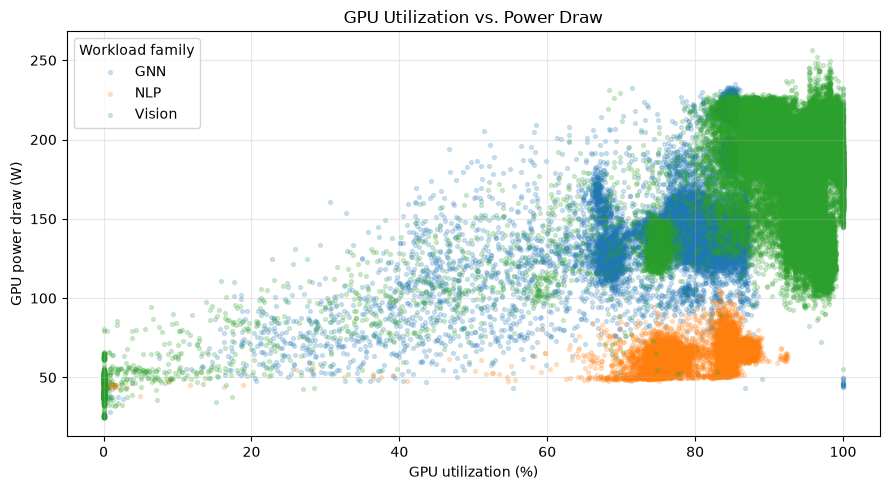

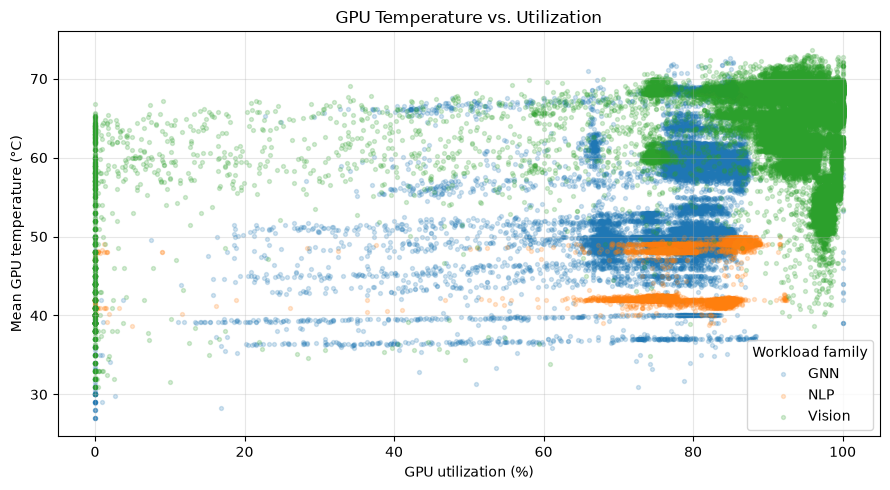

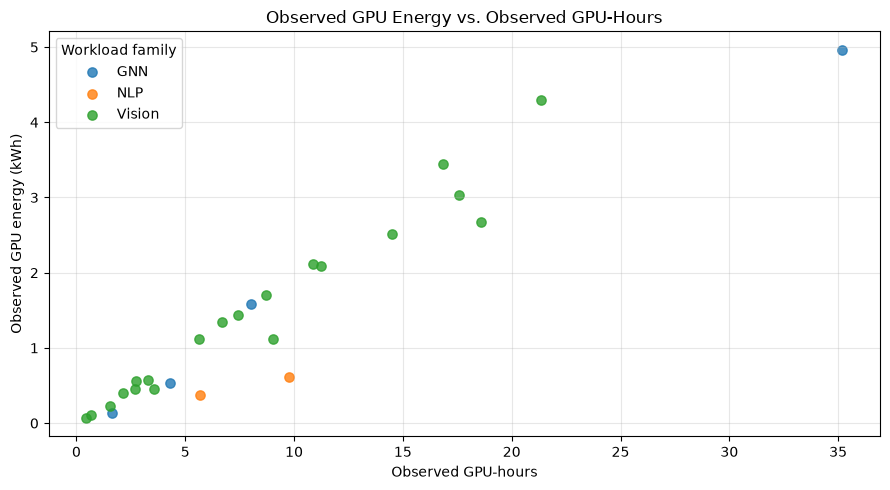

In [92]:

import matplotlib.pyplot as plt

# Plot 1: GPU utilization versus power draw
plot_sample = telemetry[
    [
        "workload_family",
        "utilization_gpu_pct",
        "power_draw_W",
        "temperature_gpu_avg",
    ]
].dropna()

# Sample for faster rendering while preserving reproducibility.
if len(plot_sample) > 100_000:
    plot_sample = plot_sample.sample(
        n=100_000, random_state=42
    )

fig, ax = plt.subplots(figsize=(9, 5))
for family, group in plot_sample.groupby("workload_family"):
    ax.scatter(
        group["utilization_gpu_pct"],
        group["power_draw_W"],
        alpha=0.2,
        s=8,
        label=family,
    )

ax.set_title("GPU Utilization vs. Power Draw")
ax.set_xlabel("GPU utilization (%)")
ax.set_ylabel("GPU power draw (W)")
ax.legend(title="Workload family")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Plot 2: GPU temperature versus utilization
fig, ax = plt.subplots(figsize=(9, 5))
for family, group in plot_sample.groupby("workload_family"):
    ax.scatter(
        group["utilization_gpu_pct"],
        group["temperature_gpu_avg"],
        alpha=0.2,
        s=8,
        label=family,
    )

ax.set_title("GPU Temperature vs. Utilization")
ax.set_xlabel("GPU utilization (%)")
ax.set_ylabel("Mean GPU temperature (°C)")
ax.legend(title="Workload family")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Plot 3: Job energy versus observed GPU-hours
job_plot = job_analytics.copy()

job_plot["observed_gpu_hours"] = (
    job_plot["total_observed_gpu_seconds"] / 3600
)

job_plot = job_plot.dropna(
    subset=["observed_gpu_hours", "observed_energy_kWh"]
)

fig, ax = plt.subplots(figsize=(9, 5))
for family, group in job_plot.groupby("workload_family"):
    ax.scatter(
        group["observed_gpu_hours"],
        group["observed_energy_kWh"],
        s=45,
        alpha=0.8,
        label=family,
    )

ax.set_title("Observed GPU Energy vs. Observed GPU-Hours")
ax.set_xlabel("Observed GPU-hours")
ax.set_ylabel("Observed GPU energy (kWh)")
ax.legend(title="Workload family")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [93]:

# Step 6: Quantify relationships and inspect operating states

analysis_df = telemetry[
    [
        "job_id",
        "rack_node_id",
        "model",
        "workload_family",
        "timestamp_1s",
        "utilization_gpu_pct",
        "utilization_memory_pct",
        "memory_used_MiB",
        "temperature_gpu_avg",
        "temperature_gpu_max",
        "power_draw_W",
        "power_limit_W",
    ]
].copy()

numeric_cols = [
    "utilization_gpu_pct",
    "utilization_memory_pct",
    "memory_used_MiB",
    "temperature_gpu_avg",
    "power_draw_W",
    "power_limit_W",
]

for col in numeric_cols:
    analysis_df[col] = pd.to_numeric(
        analysis_df[col], errors="coerce"
    )

# A. Correlations across observed telemetry rows.
# These are exploratory; rows within the same job are not independent.
print("Overall Pearson correlations:")
display(
    analysis_df[
        [
            "utilization_gpu_pct",
            "utilization_memory_pct",
            "temperature_gpu_avg",
            "power_draw_W",
        ]
    ].corr().round(3)
)

# B. Quantify zero-utilization and full-utilization observations.
analysis_df["utilization_state"] = np.select(
    [
        analysis_df["utilization_gpu_pct"].eq(0),
        analysis_df["utilization_gpu_pct"].ge(99),
    ],
    [
        "Zero utilization",
        "Near/full utilization",
    ],
    default="Intermediate utilization",
)

state_summary = (
    analysis_df.groupby(
        ["workload_family", "utilization_state"],
        as_index=False,
    )
    .agg(
        observations=("job_id", "size"),
        mean_power_W=("power_draw_W", "mean"),
        median_power_W=("power_draw_W", "median"),
        mean_temperature_C=("temperature_gpu_avg", "mean"),
    )
)

state_summary["observation_pct_within_family"] = (
    100 * state_summary["observations"]
    / state_summary.groupby("workload_family")["observations"]
      .transform("sum")
)

print("\nOperating-state summary:")
display(state_summary.round(2))

# C. Check whether zero-utilization observations have high power.
zero_util = analysis_df[
    analysis_df["utilization_gpu_pct"].eq(0)
].copy()

print("\nZero-utilization observations:", len(zero_util))
if not zero_util.empty:
    display(
        zero_util.groupby("workload_family", as_index=False)
        .agg(
            observations=("job_id", "size"),
            mean_power_W=("power_draw_W", "mean"),
            median_power_W=("power_draw_W", "median"),
            max_power_W=("power_draw_W", "max"),
            mean_memory_used_MiB=("memory_used_MiB", "mean"),
        )
        .round(2)
    )


Overall Pearson correlations:


,utilization_gpu_pct,utilization_memory_pct,temperature_gpu_avg,power_draw_W
utilization_gpu_pct,1.000,0.522,0.490,0.593
utilization_memory_pct,0.522,1.000,0.639,0.825
temperature_gpu_avg,0.490,0.639,1.000,0.794
power_draw_W,0.593,0.825,0.794,1.000



Operating-state summary:


,workload_family,utilization_state,observations,mean_power_W,median_power_W,mean_temperature_C,observation_pct_within_family
0,GNN,Intermediate utilization,175885,147.57,142.43,55.55,99.39
1,GNN,Near/full utilization,113,46.61,46.27,45.77,0.06
2,GNN,Zero utilization,972,36.48,37.19,36.06,0.55
3,NLP,Intermediate utilization,54998,63.88,64.24,44.43,98.74
4,NLP,Zero utilization,704,42.89,44.27,43.07,1.26
5,Vision,Intermediate utilization,475734,179.38,189.61,65.14,79.84
6,Vision,Near/full utilization,110760,192.99,193.21,64.77,18.59
7,Vision,Zero utilization,9365,45.27,45.53,48.15,1.57



Zero-utilization observations: 11041


,workload_family,observations,mean_power_W,median_power_W,max_power_W,mean_memory_used_MiB
0,GNN,972,36.48,37.19,59.33,4845.40
1,NLP,704,42.89,44.27,48.70,1614.27
2,Vision,9365,45.27,45.53,86.20,28852.52


In [94]:

# Step 7: Build initial anomaly-detection features

from sklearn.linear_model import LinearRegression

feature_df = telemetry[
    [
        "job_id",
        "source_filename",
        "rack_node_id",
        "rack_id",
        "node_number",
        "model",
        "workload_family",
        "gpu_index",
        "timestamp_1s",
        "utilization_gpu_pct",
        "utilization_memory_pct",
        "temperature_gpu_avg",
        "power_draw_W",
        "power_limit_W",
    ]
].copy()

numeric_features = [
    "utilization_gpu_pct",
    "utilization_memory_pct",
    "temperature_gpu_avg",
    "power_draw_W",
    "power_limit_W",
]

for col in numeric_features:
    feature_df[col] = pd.to_numeric(
        feature_df[col], errors="coerce"
    )

# Stable physical-GPU stream identity
stream_keys = ["job_id", "rack_node_id", "gpu_index"]

feature_df = feature_df.sort_values(
    stream_keys + ["timestamp_1s"]
).reset_index(drop=True)

# A. Rolling temperature baseline per GPU stream.
# Window uses up to 60 preceding observations, excluding the current row.
grouped_temp = feature_df.groupby(stream_keys)["temperature_gpu_avg"]

feature_df["rolling_temp_mean_C"] = grouped_temp.transform(
    lambda s: s.shift(1).rolling(60, min_periods=10).mean()
)
feature_df["rolling_temp_std_C"] = grouped_temp.transform(
    lambda s: s.shift(1).rolling(60, min_periods=10).std()
)

feature_df["temperature_deviation_C"] = (
    feature_df["temperature_gpu_avg"]
    - feature_df["rolling_temp_mean_C"]
)

feature_df["temperature_zscore"] = (
    feature_df["temperature_deviation_C"]
    / feature_df["rolling_temp_std_C"].replace(0, np.nan)
)

# B. Fit a simple baseline model to estimate expected power.
# This is a descriptive baseline, not a causal model.
model_df = feature_df.dropna(
    subset=[
        "power_draw_W",
        "utilization_gpu_pct",
        "utilization_memory_pct",
    ]
).copy()

model_df = model_df[
    model_df["workload_family"].notna()
]

power_model = LinearRegression()

X = pd.get_dummies(
    model_df[
        [
            "utilization_gpu_pct",
            "utilization_memory_pct",
            "workload_family",
        ]
    ],
    columns=["workload_family"],
    dtype=float,
)

y = model_df["power_draw_W"]

power_model.fit(X, y)

feature_df["expected_power_W"] = np.nan
feature_df["power_residual_W"] = np.nan

valid_power = feature_df[
    [
        "utilization_gpu_pct",
        "utilization_memory_pct",
        "workload_family",
        "power_draw_W",
    ]
].notna().all(axis=1)

X_all = pd.get_dummies(
    feature_df.loc[
        valid_power,
        [
            "utilization_gpu_pct",
            "utilization_memory_pct",
            "workload_family",
        ],
    ],
    columns=["workload_family"],
    dtype=float,
).reindex(columns=X.columns, fill_value=0)

predicted_power = power_model.predict(X_all)

feature_df.loc[valid_power, "expected_power_W"] = predicted_power
feature_df.loc[valid_power, "power_residual_W"] = (
    feature_df.loc[valid_power, "power_draw_W"].to_numpy()
    - predicted_power
)

# C. Candidate low-utilization/high-power condition.
# Use family-specific power percentiles rather than a universal watt threshold.
family_power_threshold = feature_df.groupby(
    "workload_family"
)["power_draw_W"].transform(lambda s: s.quantile(0.90))

feature_df["low_util_high_power_candidate"] = (
    (feature_df["utilization_gpu_pct"] < 20)
    & (feature_df["power_draw_W"] >= family_power_threshold)
)

# D. Flag persistent candidate conditions over 10 consecutive rows.
feature_df["candidate_condition_int"] = (
    feature_df["low_util_high_power_candidate"].astype(int)
)

feature_df["candidate_condition_10s"] = (
    feature_df.groupby(stream_keys)["candidate_condition_int"]
    .transform(lambda s: s.rolling(10, min_periods=10).sum().ge(10))
)

print("Feature dataset shape:", feature_df.shape)

print("\nMissing feature values:")
display(
    feature_df[
        [
            "temperature_deviation_C",
            "temperature_zscore",
            "expected_power_W",
            "power_residual_W",
        ]
    ].isna().sum().to_frame("missing_values")
)

print("\nCandidate-condition counts:")
print(
    feature_df[
        [
            "low_util_high_power_candidate",
            "candidate_condition_10s",
        ]
    ].sum()
)

print("\nExample candidate observations:")
display(
    feature_df.loc[
        feature_df["candidate_condition_10s"],
        [
            "job_id",
            "model",
            "workload_family",
            "rack_node_id",
            "gpu_index",
            "timestamp_1s",
            "utilization_gpu_pct",
            "power_draw_W",
            "expected_power_W",
            "power_residual_W",
            "temperature_deviation_C",
        ],
    ].head(10)
)


Feature dataset shape: (828531, 23)

Missing feature values:


,missing_values
temperature_deviation_C,640
temperature_zscore,1810
expected_power_W,0
power_residual_W,0



Candidate-condition counts:
low_util_high_power_candidate    0
candidate_condition_10s          0
dtype: int64

Example candidate observations:


,job_id,model,workload_family,rack_node_id,gpu_index,timestamp_1s,utilization_gpu_pct,power_draw_W,expected_power_W,power_residual_W,temperature_deviation_C


In [95]:

# Step 8: Diagnose power residuals and utilization thresholds

print("Power residual distribution (W):")
display(
    feature_df["power_residual_W"]
    .describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99])
    .to_frame("power_residual_W")
    .round(2)
)

print("\nAbsolute residual thresholds (W):")
display(
    feature_df["power_residual_W"]
    .abs()
    .quantile([0.90, 0.95, 0.99, 0.995, 0.999])
    .to_frame("absolute_residual_W")
    .round(2)
)

# Summarize lower utilization bands by family.
feature_df["utilization_band"] = pd.cut(
    feature_df["utilization_gpu_pct"],
    bins=[-0.01, 5, 10, 20, 40, 60, 80, 95, 100],
    labels=[
        "0-5%",
        "5-10%",
        "10-20%",
        "20-40%",
        "40-60%",
        "60-80%",
        "80-95%",
        "95-100%",
    ],
    include_lowest=True,
)

low_util_summary = (
    feature_df.groupby(
        ["workload_family", "utilization_band"],
        observed=False,
        as_index=False,
    )
    .agg(
        observations=("power_draw_W", "size"),
        median_power_W=("power_draw_W", "median"),
        p90_power_W=("power_draw_W", lambda s: s.quantile(0.90)),
        p90_abs_power_residual_W=(
            "power_residual_W",
            lambda s: s.abs().quantile(0.90),
        ),
    )
)

print("\nUtilization-band summary:")
display(low_util_summary.round(2))

# Inspect the strongest positive residuals.
print("\nTop 15 positive power residuals:")
display(
    feature_df.nlargest(15, "power_residual_W")[
        [
            "job_id",
            "model",
            "workload_family",
            "rack_node_id",
            "gpu_index",
            "timestamp_1s",
            "utilization_gpu_pct",
            "utilization_memory_pct",
            "power_draw_W",
            "expected_power_W",
            "power_residual_W",
            "temperature_gpu_avg",
        ]
    ].round(2)
)


Power residual distribution (W):


,power_residual_W
count,828531.00
mean,-0.00
std,20.74
min,-94.79
1%,-49.43
5%,-33.64
50%,-1.43
95%,35.00
99%,43.51
max,101.65



Absolute residual thresholds (W):


,absolute_residual_W
0.900,34.46
0.950,39.80
0.990,51.85
0.995,59.37
0.999,72.23



Utilization-band summary:


,workload_family,utilization_band,observations,median_power_W,p90_power_W,p90_abs_power_residual_W
0,GNN,0-5%,1063,37.21,45.78,12.46
1,GNN,5-10%,30,58.50,77.96,31.67
2,GNN,10-20%,343,68.70,87.50,23.81
3,GNN,20-40%,2713,78.01,107.75,29.31
4,GNN,40-60%,6718,112.70,153.19,47.05
5,GNN,60-80%,78206,142.79,159.06,27.79
6,GNN,80-95%,87781,143.90,218.32,37.31
7,GNN,95-100%,116,46.34,49.09,36.35
8,NLP,0-5%,970,44.04,45.53,34.50
9,NLP,5-10%,21,44.95,50.77,35.41



Top 15 positive power residuals:


/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/123295585.py:75: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,job_id,model,workload_family,rack_node_id,gpu_index,timestamp_1s,utilization_gpu_pct,utilization_memory_pct,power_draw_W,expected_power_W,power_residual_W,temperature_gpu_avg
410404,48510612336879,vgg19,Vision,r6760045-n851693,0,2021-06-12 13:39:45+00:00,94.67,8.22,215.67,114.02,101.65,60.44
448825,48510612336879,vgg19,Vision,r6760045-n851693,1,2021-06-12 13:39:44+00:00,98.20,9.40,219.12,117.84,101.29,57.10
327605,25713459161743,U3-128,Vision,r9352821-n830961,0,2021-05-28 16:05:43+00:00,98.67,13.11,218.76,124.67,94.09,47.67
57012,9761351256032,dimenet,GNN,r9192091-n386398,0,2021-08-16 10:41:59+00:00,65.67,27.33,202.15,112.02,90.13,68.44
612666,74636684972411,U3-64,Vision,r6760045-n851693,0,2021-05-16 11:02:27+00:00,65.44,35.22,237.00,147.89,89.12,66.56
613833,74636684972411,U3-64,Vision,r6760045-n851693,0,2021-05-16 11:21:54+00:00,66.67,36.22,238.05,150.26,87.79,66.44
57631,9761351256032,dimenet,GNN,r9192091-n386398,0,2021-08-16 10:52:18+00:00,67.67,30.22,204.13,118.14,85.99,69.00
613834,74636684972411,U3-64,Vision,r6760045-n851693,0,2021-05-16 11:21:55+00:00,68.50,37.00,237.81,152.54,85.27,66.80
324556,25713459161743,U3-128,Vision,r4858666-n976057,1,2021-05-28 16:04:01+00:00,99.11,10.33,204.00,119.94,84.06,44.89
321603,25713459161743,U3-128,Vision,r4858666-n976057,0,2021-05-28 16:03:55+00:00,98.44,11.11,205.05,121.00,84.04,45.44


In [96]:

# Step 9: Check hardware and power-limit coverage

diagnostic_df = feature_df.copy()

print("Power-limit coverage by workload family:")
power_limit_coverage = (
    diagnostic_df.groupby("workload_family", as_index=False)
    .agg(
        observations=("power_limit_W", "size"),
        valid_power_limits=("power_limit_W", "count"),
        unique_models=("model", "nunique"),
        unique_gpu_streams=(
            ["job_id", "rack_node_id", "gpu_index"],
            "nunique",
        ) if False else ("rack_node_id", "nunique"),
    )
)

power_limit_coverage["valid_power_limit_pct"] = (
    100 * power_limit_coverage["valid_power_limits"]
    / power_limit_coverage["observations"]
)

display(power_limit_coverage.round(2))

print("\nPower-limit distribution:")
display(
    diagnostic_df.groupby("workload_family")["power_limit_W"]
    .describe()
    .round(2)
)

print("\nModel and workload coverage:")
display(
    diagnostic_df.groupby(
        ["workload_family", "model"],
        as_index=False,
    )
    .agg(
        jobs=("job_id", "nunique"),
        gpu_streams=("rack_node_id", "nunique"),
        mean_power_W=("power_draw_W", "mean"),
        mean_utilization_pct=("utilization_gpu_pct", "mean"),
    )
    .round(2)
)


Power-limit coverage by workload family:


,workload_family,observations,valid_power_limits,unique_models,unique_gpu_streams,valid_power_limit_pct
0,GNN,176970,0,4,4,0.00
1,NLP,55702,0,2,2,0.00
2,Vision,595859,32440,20,24,5.44



Power-limit distribution:


,count,mean,std,min,25%,50%,75%,max
workload_family,,,,,,,,
GNN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NLP,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vision,32440.0,250.0,0.4,200.0,250.0,250.0,250.0,250.0



Model and workload coverage:


,workload_family,model,jobs,gpu_streams,mean_power_W,mean_utilization_pct
0,GNN,conv,1,1,198.15,80.58
1,GNN,dimenet,1,1,141.09,78.92
2,GNN,pna,1,1,83.23,58.02
3,GNN,schnet,1,1,122.90,63.07
4,NLP,bert-base-uncased,1,1,62.93,77.73
5,NLP,distilbert-base-uncased,1,1,64.80,79.01
6,Vision,U3-128,1,2,176.48,86.53
7,Vision,U3-32,1,1,146.55,80.14
8,Vision,U3-64,1,1,168.08,80.60
9,Vision,U4-128,1,2,194.20,92.54


In [97]:

# Step 10: Correct hardware-identity diagnostics

stream_key_cols = ["job_id", "rack_node_id", "gpu_index"]

corrected_family_coverage = (
    feature_df.groupby("workload_family", as_index=False)
    .agg(
        observations=("job_id", "size"),
        valid_power_limits=("power_limit_W", "count"),
        unique_models=("model", "nunique"),
        physical_gpu_streams=(
            "job_id",
            lambda s: feature_df.loc[s.index, stream_key_cols]
            .drop_duplicates()
            .shape[0],
        ),
    )
)

corrected_family_coverage["valid_power_limit_pct"] = (
    100 * corrected_family_coverage["valid_power_limits"]
    / corrected_family_coverage["observations"]
)

print("Corrected family coverage:")
display(corrected_family_coverage.round(2))

# Check whether workload families have enough jobs for a job-level split.
jobs_per_family = (
    job_analytics.groupby("workload_family", as_index=False)
    .agg(jobs=("job_id", "nunique"))
)

print("\nJobs per workload family:")
display(jobs_per_family)

print("\nAvailable cross-family features:")
candidate_features = [
    "utilization_gpu_pct",
    "utilization_memory_pct",
    "temperature_gpu_avg",
    "temperature_gpu_max",
    "temperature_memory_avg",
    "power_draw_W",
    "memory_used_MiB",
    "memory_free_MiB",
]

for col in candidate_features:
    if col in feature_df.columns:
        print(
            f"{col}: "
            f"{feature_df[col].notna().mean() * 100:.2f}% non-missing"
        )


Corrected family coverage:


,workload_family,observations,valid_power_limits,unique_models,physical_gpu_streams,valid_power_limit_pct
0,GNN,176970,0,4,8,0.00
1,NLP,55702,0,2,4,0.00
2,Vision,595859,32440,20,52,5.44



Jobs per workload family:


,workload_family,jobs
0,GNN,4
1,NLP,2
2,Vision,20



Available cross-family features:
utilization_gpu_pct: 100.00% non-missing
utilization_memory_pct: 100.00% non-missing
temperature_gpu_avg: 100.00% non-missing
power_draw_W: 100.00% non-missing


In [98]:

# Step 11: Job-aware Isolation Forest baseline

from sklearn.ensemble import IsolationForest
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

features = [
    "utilization_gpu_pct",
    "utilization_memory_pct",
    "temperature_gpu_avg",
    "power_draw_W",
]

# Exclude the job whose telemetry covers only 2 of 4 allocated GPUs.
incomplete_job_ids = job_analytics.loc[
    job_analytics["telemetry_coverage_status"]
    != "GPU allocation count matched",
    "job_id",
].tolist()

ml_df = feature_df.loc[
    ~feature_df["job_id"].isin(incomplete_job_ids)
].copy()

ml_df = ml_df.dropna(subset=features).reset_index(drop=True)

# Hold out entire jobs to prevent job-level leakage.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42,
)

train_idx, test_idx = next(
    splitter.split(
        ml_df[features],
        groups=ml_df["job_id"],
    )
)

train_df = ml_df.iloc[train_idx].copy()
test_df = ml_df.iloc[test_idx].copy()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("Training jobs:", train_df["job_id"].nunique())
print("Testing jobs:", test_df["job_id"].nunique())

print("\nHeld-out jobs by family:")
display(
    test_df[
        ["job_id", "workload_family"]
    ]
    .drop_duplicates()
    .groupby("workload_family", as_index=False)
    .agg(held_out_jobs=("job_id", "nunique"))
)

# Fit only on training observations.
# contamination=0.01 asks the model to flag roughly 1% of
# the training distribution as unusual; it is not a true fault rate.
iso_model = make_pipeline(
    StandardScaler(),
    IsolationForest(
        n_estimators=200,
        contamination=0.01,
        random_state=42,
        n_jobs=-1,
    ),
)

iso_model.fit(train_df[features])

# IsolationForest decision_function: lower means more anomalous.
test_df["anomaly_score"] = -iso_model.decision_function(
    test_df[features]
)

# Mark the most unusual 1% of held-out observations.
score_threshold = test_df["anomaly_score"].quantile(0.99)
test_df["anomaly_candidate"] = (
    test_df["anomaly_score"] >= score_threshold
)

print("\nHeld-out anomaly threshold:", round(score_threshold, 4))
print(
    "Candidate observations:",
    int(test_df["anomaly_candidate"].sum()),
    "of",
    len(test_df),
)
print(
    "Candidate rate (%):",
    round(100 * test_df["anomaly_candidate"].mean(), 3),
)

print("\nCandidate observations by family:")
display(
    test_df.groupby("workload_family", as_index=False)
    .agg(
        held_out_observations=("job_id", "size"),
        candidate_observations=("anomaly_candidate", "sum"),
        mean_anomaly_score=("anomaly_score", "mean"),
    )
    .round(4)
)

print("\nTop 15 candidate observations:")
display(
    test_df.nlargest(15, "anomaly_score")[
        [
            "job_id",
            "model",
            "workload_family",
            "rack_node_id",
            "gpu_index",
            "timestamp_1s",
            *features,
            "anomaly_score",
        ]
    ].round(3)
)


Training rows: 663652
Testing rows: 159267
Training jobs: 18
Testing jobs: 7

Held-out jobs by family:


,workload_family,held_out_jobs
0,GNN,1
1,NLP,1
2,Vision,5



Held-out anomaly threshold: 0.0011
Candidate observations: 1630 of 159267
Candidate rate (%): 1.023

Candidate observations by family:


,workload_family,held_out_observations,candidate_observations,mean_anomaly_score
0,GNN,5848,161,-0.0621
1,NLP,20514,123,-0.1169
2,Vision,132905,1346,-0.2450



Top 15 candidate observations:


/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/1753262412.py:122: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(3)


,job_id,model,workload_family,rack_node_id,gpu_index,timestamp_1s,utilization_gpu_pct,utilization_memory_pct,temperature_gpu_avg,power_draw_W,anomaly_score
333307,36230628475012,pna,GNN,r9555635-n139058,0,2021-08-17 17:09:50+00:00,1.556,0.0,29.000,27.676,0.03
333255,36230628475012,pna,GNN,r9555635-n139058,0,2021-08-17 17:08:58+00:00,0.000,0.0,30.000,25.352,0.03
333256,36230628475012,pna,GNN,r9555635-n139058,0,2021-08-17 17:08:59+00:00,0.000,0.0,30.000,25.276,0.03
333257,36230628475012,pna,GNN,r9555635-n139058,0,2021-08-17 17:09:00+00:00,0.000,0.0,30.000,25.273,0.03
333258,36230628475012,pna,GNN,r9555635-n139058,0,2021-08-17 17:09:01+00:00,0.000,0.0,30.000,25.181,0.03
333259,36230628475012,pna,GNN,r9555635-n139058,0,2021-08-17 17:09:02+00:00,0.000,0.0,30.000,25.229,0.03
333260,36230628475012,pna,GNN,r9555635-n139058,0,2021-08-17 17:09:03+00:00,0.000,0.0,30.000,25.249,0.03
333261,36230628475012,pna,GNN,r9555635-n139058,0,2021-08-17 17:09:04+00:00,0.000,0.0,30.000,25.220,0.03
333262,36230628475012,pna,GNN,r9555635-n139058,0,2021-08-17 17:09:05+00:00,0.000,0.0,30.000,25.200,0.03
333263,36230628475012,pna,GNN,r9555635-n139058,0,2021-08-17 17:09:06+00:00,0.000,0.0,30.000,25.267,0.03


In [99]:

# Step 12: Group anomaly candidates into contiguous events

scored = test_df.sort_values(
    ["job_id", "rack_node_id", "gpu_index", "timestamp_1s"]
).copy()

stream_keys = ["job_id", "rack_node_id", "gpu_index"]

# An event starts when the candidate status changes or there is a time gap.
scored["previous_candidate"] = (
    scored.groupby(stream_keys)["anomaly_candidate"].shift(1)
)
scored["previous_timestamp"] = (
    scored.groupby(stream_keys)["timestamp_1s"].shift(1)
)

scored["time_gap_seconds"] = (
    scored["timestamp_1s"] - scored["previous_timestamp"]
).dt.total_seconds()

scored["new_event"] = (
    scored["anomaly_candidate"]
    & (
        scored["previous_candidate"].ne(True)
        | scored["time_gap_seconds"].ne(1)
    )
)

scored["event_id"] = (
    scored.groupby(stream_keys)["new_event"].cumsum()
)

candidate_rows = scored[scored["anomaly_candidate"]].copy()

event_summary = (
    candidate_rows.groupby(
        stream_keys + ["event_id", "model", "workload_family"],
        as_index=False,
    )
    .agg(
        start_time=("timestamp_1s", "min"),
        end_time=("timestamp_1s", "max"),
        candidate_seconds=("timestamp_1s", "nunique"),
        mean_gpu_utilization_pct=("utilization_gpu_pct", "mean"),
        mean_memory_utilization_pct=("utilization_memory_pct", "mean"),
        mean_temperature_C=("temperature_gpu_avg", "mean"),
        mean_power_W=("power_draw_W", "mean"),
        max_anomaly_score=("anomaly_score", "max"),
    )
)

event_summary["duration_seconds"] = (
    event_summary["end_time"] - event_summary["start_time"]
).dt.total_seconds() + 1

print("Candidate rows:", len(candidate_rows))
print("Candidate events:", len(event_summary))

print("\nLongest candidate events:")
display(
    event_summary.sort_values(
        ["duration_seconds", "max_anomaly_score"],
        ascending=False,
    ).head(20).round(2)
)

print("\nCandidate events by workload family:")
display(
    event_summary.groupby("workload_family", as_index=False)
    .agg(
        events=("event_id", "count"),
        candidate_seconds=("candidate_seconds", "sum"),
        median_event_duration_s=("duration_seconds", "median"),
        max_event_duration_s=("duration_seconds", "max"),
    )
    .round(2)
)


Candidate rows: 1630
Candidate events: 179

Longest candidate events:


/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/2623287349.py:64: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).head(20).round(2)


,job_id,rack_node_id,gpu_index,event_id,model,workload_family,start_time,end_time,candidate_seconds,mean_gpu_utilization_pct,mean_memory_utilization_pct,mean_temperature_C,mean_power_W,max_anomaly_score,duration_seconds
77,25713459161743,r9352821-n830961,1,2,U3-128,Vision,2021-05-28 16:02:38+00:00,2021-05-28 16:05:44+00:00,187,0.04,0.00,38.84,39.12,0.01,187.0
65,25713459161743,r9352821-n830961,0,3,U3-128,Vision,2021-05-28 16:02:54+00:00,2021-05-28 16:05:41+00:00,168,0.03,0.00,39.38,40.46,0.01,168.0
53,25713459161743,r4858666-n976057,1,1,U3-128,Vision,2021-05-28 16:01:39+00:00,2021-05-28 16:04:00+00:00,142,0.10,0.01,38.88,37.18,0.02,142.0
54,25713459161743,r4858666-n976057,1,2,U3-128,Vision,2021-05-28 16:04:07+00:00,2021-05-28 16:05:49+00:00,103,0.23,0.00,38.38,37.21,0.02,103.0
44,25713459161743,r4858666-n976057,0,2,U3-128,Vision,2021-05-28 16:04:19+00:00,2021-05-28 16:05:49+00:00,91,0.24,0.01,39.61,38.90,0.01,91.0
81,36230628475012,r9555635-n139058,0,1,pna,GNN,2021-08-17 17:08:58+00:00,2021-08-17 17:10:16+00:00,79,0.46,0.00,29.37,29.15,0.03,79.0
83,36230628475012,r9555635-n139058,1,1,pna,GNN,2021-08-17 17:08:58+00:00,2021-08-17 17:10:16+00:00,79,0.20,0.01,27.54,28.63,0.03,79.0
43,25713459161743,r4858666-n976057,0,1,U3-128,Vision,2021-05-28 16:02:52+00:00,2021-05-28 16:03:54+00:00,63,0.15,0.01,39.98,39.40,0.01,63.0
0,2304959634945,r5715171-n136082,0,1,distilbert-base-uncased,NLP,2021-07-01 17:13:58+00:00,2021-07-01 17:14:55+00:00,58,0.19,0.00,38.03,27.80,0.02,58.0
136,59030654331752,r8579942-n208530,0,5,U5-128,Vision,2021-05-12 22:44:51+00:00,2021-05-12 22:45:28+00:00,38,0.00,0.00,45.00,41.43,0.00,38.0



Candidate events by workload family:


,workload_family,events,candidate_seconds,median_event_duration_s,max_event_duration_s
0,GNN,4,161,40.5,79.0
1,NLP,43,123,1.0,58.0
2,Vision,132,1346,2.0,187.0


In [100]:

# Step 13: Categorize candidate operating states

candidate_review = test_df.loc[
    test_df["anomaly_candidate"]
].copy()

candidate_review["candidate_type"] = np.select(
    [
        (
            (candidate_review["utilization_gpu_pct"] < 10)
            & (candidate_review["utilization_memory_pct"] < 5)
        ),
        (
            (candidate_review["power_draw_W"] >= 180)
            & (candidate_review["utilization_gpu_pct"] < 30)
        ),
        (
            (candidate_review["temperature_gpu_avg"] >= 70)
        ),
    ],
    [
        "Low-utilization / low-memory",
        "High-power / low-utilization",
        "High-temperature observation",
    ],
    default="Other multivariate deviation",
)

print("Candidate type distribution:")
display(
    candidate_review.groupby(
        ["workload_family", "candidate_type"],
        as_index=False,
    )
    .agg(
        observations=("job_id", "size"),
        unique_jobs=("job_id", "nunique"),
        mean_power_W=("power_draw_W", "mean"),
        mean_temperature_C=("temperature_gpu_avg", "mean"),
        mean_anomaly_score=("anomaly_score", "mean"),
    )
    .round(2)
)

print("\nHighest-power candidate observations:")
display(
    candidate_review.nlargest(15, "power_draw_W")[
        [
            "job_id",
            "model",
            "workload_family",
            "rack_node_id",
            "gpu_index",
            "timestamp_1s",
            "utilization_gpu_pct",
            "utilization_memory_pct",
            "temperature_gpu_avg",
            "power_draw_W",
            "anomaly_score",
            "candidate_type",
        ]
    ].round(2)
)


Candidate type distribution:


,workload_family,candidate_type,observations,unique_jobs,mean_power_W,mean_temperature_C,mean_anomaly_score
0,GNN,Low-utilization / low-memory,160,1,29.13,28.59,0.03
1,GNN,Other multivariate deviation,1,1,37.93,30.00,0.01
2,NLP,Low-utilization / low-memory,123,1,36.76,43.27,0.01
3,Vision,Low-utilization / low-memory,1321,5,44.05,46.25,0.01
4,Vision,Other multivariate deviation,25,5,57.78,61.07,0.01



Highest-power candidate observations:


/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/1035467957.py:62: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,job_id,model,workload_family,rack_node_id,gpu_index,timestamp_1s,utilization_gpu_pct,utilization_memory_pct,temperature_gpu_avg,power_draw_W,anomaly_score,candidate_type
538877,59030654331752,U5-128,Vision,r8579942-n208530,0,2021-05-13 00:09:27+00:00,7.10,4.10,63.10,93.65,0.01,Low-utilization / low-memory
365929,42978538849394,resnet152_v2,Vision,r3405251-n208530,1,2021-06-07 16:26:39+00:00,8.67,5.11,61.44,90.29,0.00,Other multivariate deviation
543994,59030654331752,U5-128,Vision,r8579942-n208530,0,2021-05-13 01:34:44+00:00,1.00,0.00,59.40,89.78,0.01,Low-utilization / low-memory
549000,59030654331752,U5-128,Vision,r8579942-n208530,0,2021-05-13 02:58:10+00:00,7.20,4.30,59.50,89.62,0.00,Low-utilization / low-memory
759713,80249445248004,resnet101_v2,Vision,r629115-n976057,0,2021-06-07 12:14:28+00:00,9.00,4.89,65.22,87.31,0.01,Low-utilization / low-memory
404131,48020198141948,U4-64,Vision,r9352821-n830961,0,2021-05-10 22:03:40+00:00,9.10,4.30,63.70,85.91,0.01,Low-utilization / low-memory
726266,80249445248004,resnet101_v2,Vision,r3741709-n976057,0,2021-06-07 12:15:23+00:00,20.89,0.22,64.89,85.10,0.01,Other multivariate deviation
370969,42978538849394,resnet152_v2,Vision,r3405251-n208530,1,2021-06-07 17:50:39+00:00,9.20,4.90,61.60,81.96,0.00,Low-utilization / low-memory
328933,25713459161743,U3-128,Vision,r9352821-n830961,0,2021-05-28 16:27:51+00:00,4.33,1.33,62.89,80.20,0.01,Low-utilization / low-memory
759768,80249445248004,resnet101_v2,Vision,r629115-n976057,0,2021-06-07 12:15:23+00:00,15.89,3.11,64.56,77.96,0.01,Other multivariate deviation


In [101]:

# Step 14: Quantify potential GPU underutilization

underutil_df = feature_df.sort_values(
    ["job_id", "rack_node_id", "gpu_index", "timestamp_1s"]
).copy()

# Family-specific power threshold for exploratory analysis
underutil_df["family_power_p75_W"] = (
    underutil_df.groupby("workload_family")["power_draw_W"]
    .transform(lambda s: s.quantile(0.75))
)

underutil_df["low_utilization"] = (
    underutil_df["utilization_gpu_pct"] < 10
)

underutil_df["low_util_elevated_power"] = (
    underutil_df["low_utilization"]
    & (
        underutil_df["power_draw_W"]
        >= underutil_df["family_power_p75_W"]
    )
)

# Estimate energy per one-second telemetry bin.
# These are estimates, not direct energy-meter readings.
underutil_df["estimated_energy_Wh"] = (
    underutil_df["power_draw_W"] / 3600
)

underutil_summary = (
    underutil_df.groupby("workload_family", as_index=False)
    .agg(
        observations=("timestamp_1s", "size"),
        low_utilization_seconds=("low_utilization", "sum"),
        low_util_elevated_power_seconds=(
            "low_util_elevated_power", "sum"
        ),
        total_observed_energy_Wh=("estimated_energy_Wh", "sum"),
        low_util_elevated_power_Wh=(
            "estimated_energy_Wh",
            lambda s: s[
                underutil_df.loc[s.index, "low_util_elevated_power"]
            ].sum(),
        ),
        jobs=("job_id", "nunique"),
    )
)

underutil_summary["low_utilization_pct"] = (
    100 * underutil_summary["low_utilization_seconds"]
    / underutil_summary["observations"]
)

underutil_summary["low_util_elevated_power_pct"] = (
    100 * underutil_summary["low_util_elevated_power_seconds"]
    / underutil_summary["observations"]
)

underutil_summary["low_util_elevated_power_energy_pct"] = (
    100 * underutil_summary["low_util_elevated_power_Wh"]
    / underutil_summary["total_observed_energy_Wh"]
)

print("Underutilization summary by workload family:")
display(underutil_summary.round(2))

# Break down by job to identify which workloads contribute most.
underutil_by_job = (
    underutil_df.groupby(
        ["job_id", "model", "workload_family"],
        as_index=False,
    )
    .agg(
        observed_seconds=("timestamp_1s", "size"),
        low_util_elevated_power_seconds=(
            "low_util_elevated_power", "sum"
        ),
        estimated_energy_Wh=("estimated_energy_Wh", "sum"),
        low_util_elevated_power_Wh=(
            "estimated_energy_Wh",
            lambda s: s[
                underutil_df.loc[s.index, "low_util_elevated_power"]
            ].sum(),
        ),
    )
)

underutil_by_job["low_util_elevated_power_pct"] = (
    100
    * underutil_by_job["low_util_elevated_power_seconds"]
    / underutil_by_job["observed_seconds"]
)

print("\nJobs with the largest low-utilization/elevated-power duration:")
display(
    underutil_by_job.sort_values(
        "low_util_elevated_power_seconds",
        ascending=False,
    ).head(15).round(2)
)


Underutilization summary by workload family:


,workload_family,observations,low_utilization_seconds,low_util_elevated_power_seconds,total_observed_energy_Wh,low_util_elevated_power_Wh,jobs,low_utilization_pct,low_util_elevated_power_pct,low_util_elevated_power_energy_pct
0,GNN,176970,1093,0,7221.17,0.0,4,0.62,0.0,0.0
1,NLP,55702,991,0,984.31,0.0,2,1.78,0.0,0.0
2,Vision,595859,10732,0,29760.45,0.0,20,1.80,0.0,0.0



Jobs with the largest low-utilization/elevated-power duration:


,job_id,model,workload_family,observed_seconds,low_util_elevated_power_seconds,estimated_energy_Wh,low_util_elevated_power_Wh,low_util_elevated_power_pct
0,2304959634945,distilbert-base-uncased,NLP,20514,0,369.25,0.0,0.0
1,8427789164283,bert-base-uncased,NLP,35188,0,615.06,0.0,0.0
24,80249445248004,resnet101_v2,Vision,67004,0,2676.11,0.0,0.0
23,79150048009801,U5-64,Vision,63270,0,3038.77,0.0,0.0
22,78604982814993,vgg11,Vision,40523,0,2087.76,0.0,0.0
21,74636684972411,U3-64,Vision,9678,0,451.85,0.0,0.0
20,68307271431118,U4-32,Vision,12776,0,452.07,0.0,0.0
19,59638293409445,U4-128,Vision,26664,0,1438.34,0.0,0.0
18,59464190077432,inception3,Vision,9932,0,566.56,0.0,0.0
17,59030654331752,U5-128,Vision,20287,0,1112.56,0.0,0.0


In [102]:

# Step 15: Profile low-utilization observations directly

low_util_df = feature_df.loc[
    feature_df["utilization_gpu_pct"] < 10
].copy()

low_util_profile = (
    low_util_df.groupby("workload_family", as_index=False)
    .agg(
        observations=("power_draw_W", "size"),
        unique_jobs=("job_id", "nunique"),
        mean_gpu_utilization_pct=("utilization_gpu_pct", "mean"),
        median_power_W=("power_draw_W", "median"),
        p75_power_W=("power_draw_W", lambda s: s.quantile(0.75)),
        p90_power_W=("power_draw_W", lambda s: s.quantile(0.90)),
        mean_temperature_C=("temperature_gpu_avg", "mean"),
        median_temperature_C=("temperature_gpu_avg", "median"),
    )
)

family_baseline = (
    feature_df.groupby("workload_family")
    .agg(
        family_median_power_W=("power_draw_W", "median"),
        family_p75_power_W=("power_draw_W", lambda s: s.quantile(0.75)),
    )
    .reset_index()
)

low_util_profile = low_util_profile.merge(
    family_baseline,
    on="workload_family",
    how="left",
)

low_util_profile["low_util_median_vs_family_median_W"] = (
    low_util_profile["median_power_W"]
    - low_util_profile["family_median_power_W"]
)

print("Power profile during low GPU utilization:")
display(low_util_profile.round(2))

# Examine jobs contributing the most low-utilization observations.
low_util_by_job = (
    low_util_df.groupby(
        ["job_id", "model", "workload_family"],
        as_index=False,
    )
    .agg(
        low_util_observations=("timestamp_1s", "size"),
        mean_gpu_utilization_pct=("utilization_gpu_pct", "mean"),
        median_power_W=("power_draw_W", "median"),
        p90_power_W=("power_draw_W", lambda s: s.quantile(0.90)),
        mean_temperature_C=("temperature_gpu_avg", "mean"),
    )
    .sort_values("low_util_observations", ascending=False)
)

print("\nJobs with the most low-utilization observations:")
display(low_util_by_job.head(15).round(2))


Power profile during low GPU utilization:


,workload_family,observations,unique_jobs,mean_gpu_utilization_pct,median_power_W,p75_power_W,p90_power_W,mean_temperature_C,median_temperature_C,family_median_power_W,family_p75_power_W,low_util_median_vs_family_median_W
0,GNN,1093,4,0.34,37.26,40.58,46.28,36.29,35.00,142.31,154.66,-105.05
1,NLP,991,2,0.51,44.07,45.10,45.55,43.20,42.00,64.11,69.11,-20.04
2,Vision,10732,20,0.50,46.10,50.95,54.88,49.01,47.05,190.31,201.78,-144.20



Jobs with the most low-utilization observations:


,job_id,model,workload_family,low_util_observations,mean_gpu_utilization_pct,median_power_W,p90_power_W,mean_temperature_C
16,55788973536832,resnet101,Vision,2764,0.88,51.99,64.31,59.23
19,59638293409445,U4-128,Vision,1309,0.22,45.24,52.31,46.65
8,25713459161743,U3-128,Vision,1022,0.13,39.02,41.46,40.43
3,13063192210942,vgg16,Vision,698,0.43,34.15,36.59,39.52
17,59030654331752,U5-128,Vision,545,1.73,51.93,55.18,52.89
23,79150048009801,U5-64,Vision,544,0.89,40.36,49.34,48.07
9,29381280178268,U3-32,Vision,541,0.05,44.83,46.96,42.54
6,18203079158032,schnet,GNN,533,0.15,36.85,38.84,33.83
1,8427789164283,bert-base-uncased,NLP,507,0.58,44.02,44.86,40.79
20,68307271431118,U4-32,Vision,493,0.10,45.49,45.58,40.93


In [103]:

# Step 16: Detect sustained low-utilization episodes

episode_df = feature_df.copy()

episode_df["timestamp_1s"] = pd.to_datetime(
    episode_df["timestamp_1s"], utc=True
)

episode_df = episode_df.sort_values(
    ["job_id", "rack_node_id", "gpu_index", "timestamp_1s"]
).reset_index(drop=True)

stream_keys = ["job_id", "rack_node_id", "gpu_index"]

episode_df["low_util_flag"] = (
    episode_df["utilization_gpu_pct"] < 10
)

# A new episode starts when:
# 1. the physical GPU stream changes,
# 2. the current row is not low utilization, or
# 3. the previous row was not low utilization / timestamps are not consecutive.
previous_low = (
    episode_df.groupby(stream_keys)["low_util_flag"]
    .shift()
    .fillna(False)
)

previous_timestamp = (
    episode_df.groupby(stream_keys)["timestamp_1s"].shift()
)

time_gap = (
    episode_df["timestamp_1s"] - previous_timestamp
).dt.total_seconds()

episode_df["episode_start_flag"] = (
    episode_df["low_util_flag"]
    & (
        ~previous_low
        | time_gap.ne(1)
    )
)

episode_df["episode_id"] = (
    episode_df.groupby(stream_keys)["episode_start_flag"]
    .cumsum()
)

low_rows = episode_df.loc[
    episode_df["low_util_flag"]
].copy()

episodes = (
    low_rows.groupby(
        stream_keys + ["episode_id"],
        as_index=False,
    )
    .agg(
        model=("model", "first"),
        workload_family=("workload_family", "first"),
        start_time=("timestamp_1s", "min"),
        end_time=("timestamp_1s", "max"),
        observations=("timestamp_1s", "size"),
        mean_gpu_utilization_pct=("utilization_gpu_pct", "mean"),
        median_power_W=("power_draw_W", "median"),
        p90_power_W=("power_draw_W", lambda s: s.quantile(0.90)),
        mean_temperature_C=("temperature_gpu_avg", "mean"),
    )
)

# With consecutive one-second timestamps, N observations span N seconds
# operationally, even though end_time - start_time is N - 1 seconds.
episodes["duration_seconds"] = episodes["observations"]

episodes["duration_band"] = pd.cut(
    episodes["duration_seconds"],
    bins=[0, 4, 9, 29, float("inf")],
    labels=["1–4 sec", "5–9 sec", "10–29 sec", "30+ sec"],
)

print("Low-utilization observations:", len(low_rows))
print("Low-utilization episodes:", len(episodes))

print("\nEpisode duration distribution:")
display(
    episodes.groupby(
        ["workload_family", "duration_band"],
        observed=False,
    )
    .agg(
        episodes=("episode_id", "size"),
        total_seconds=("duration_seconds", "sum"),
        median_power_W=("median_power_W", "median"),
    )
    .reset_index()
    .round(2)
)

print("\nLongest episodes:")
display(
    episodes.sort_values(
        ["duration_seconds", "median_power_W"],
        ascending=[False, False],
    )
    .head(20)
    .round(2)
)


Low-utilization observations: 12816
Low-utilization episodes: 12816

Episode duration distribution:


,workload_family,duration_band,episodes,total_seconds,median_power_W
0,GNN,1–4 sec,1093,1093,37.26
1,GNN,5–9 sec,0,0,NaN
2,GNN,10–29 sec,0,0,NaN
3,GNN,30+ sec,0,0,NaN
4,NLP,1–4 sec,991,991,44.07
5,NLP,5–9 sec,0,0,NaN
6,NLP,10–29 sec,0,0,NaN
7,NLP,30+ sec,0,0,NaN
8,Vision,1–4 sec,10732,10732,46.10
9,Vision,5–9 sec,0,0,NaN



Longest episodes:


/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/730527493.py:107: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2)


,job_id,rack_node_id,gpu_index,episode_id,model,workload_family,start_time,end_time,observations,mean_gpu_utilization_pct,median_power_W,p90_power_W,mean_temperature_C,duration_seconds,duration_band
7957,55788973536832,r6272977-n911952,0,648,resnet101,Vision,2021-06-12 01:32:27+00:00,2021-06-12 01:32:27+00:00,1,7.40,98.67,98.67,64.70,1,1–4 sec
7687,55788973536832,r6272977-n911952,0,378,resnet101,Vision,2021-06-12 00:07:01+00:00,2021-06-12 00:07:01+00:00,1,7.33,95.31,95.31,62.44,1,1–4 sec
7936,55788973536832,r6272977-n911952,0,627,resnet101,Vision,2021-06-12 01:26:08+00:00,2021-06-12 01:26:08+00:00,1,1.11,95.05,95.05,64.44,1,1–4 sec
7849,55788973536832,r6272977-n911952,0,540,resnet101,Vision,2021-06-12 00:50:05+00:00,2021-06-12 00:50:05+00:00,1,4.89,94.64,94.64,65.22,1,1–4 sec
7554,55788973536832,r6272977-n911952,0,245,resnet101,Vision,2021-06-11 23:13:24+00:00,2021-06-11 23:13:24+00:00,1,2.67,94.50,94.50,64.11,1,1–4 sec
7714,55788973536832,r6272977-n911952,0,405,resnet101,Vision,2021-06-12 00:14:41+00:00,2021-06-12 00:14:41+00:00,1,6.40,94.42,94.42,64.90,1,1–4 sec
8999,59030654331752,r8579942-n208530,0,314,U5-128,Vision,2021-05-13 00:09:27+00:00,2021-05-13 00:09:27+00:00,1,7.10,93.65,93.65,63.10,1,1–4 sec
2270,15305255756787,r6760045-n685852,0,183,resnet152,Vision,2021-06-12 18:30:22+00:00,2021-06-12 18:30:22+00:00,1,9.78,93.63,93.63,64.33,1,1–4 sec
7582,55788973536832,r6272977-n911952,0,273,resnet101,Vision,2021-06-11 23:20:25+00:00,2021-06-11 23:20:25+00:00,1,8.22,93.62,93.62,63.56,1,1–4 sec
7519,55788973536832,r6272977-n911952,0,210,resnet101,Vision,2021-06-11 23:00:05+00:00,2021-06-11 23:00:05+00:00,1,6.89,92.86,92.86,65.67,1,1–4 sec


In [104]:

# Step 17: Validate low-utilization episode segmentation

validation_df = feature_df.copy()

validation_df["timestamp_1s"] = pd.to_datetime(
    validation_df["timestamp_1s"], utc=True
)

validation_df = validation_df.sort_values(
    ["job_id", "rack_node_id", "gpu_index", "timestamp_1s"]
).reset_index(drop=True)

stream_keys = ["job_id", "rack_node_id", "gpu_index"]

validation_df["low_util_flag"] = (
    validation_df["utilization_gpu_pct"] < 10
)

validation_df["previous_low_util_flag"] = (
    validation_df.groupby(stream_keys)["low_util_flag"]
    .shift()
    .fillna(False)
)

validation_df["previous_timestamp"] = (
    validation_df.groupby(stream_keys)["timestamp_1s"].shift()
)

validation_df["gap_seconds"] = (
    validation_df["timestamp_1s"]
    - validation_df["previous_timestamp"]
).dt.total_seconds()

low = validation_df.loc[validation_df["low_util_flag"]].copy()

print("Low-utilization observations:", len(low))
print(
    "Low-util observations following another low-util observation:",
    int(low["previous_low_util_flag"].sum()),
)
print(
    "Low-util observations with exactly 1-second timestamp gaps:",
    int((low["gap_seconds"] == 1).sum()),
)
print(
    "Low-util observations with a gap other than 1 second:",
    int((low["gap_seconds"].fillna(-1) != 1).sum()),
)

print("\nLow-utilization observations by transition:")
display(
    low.assign(
        transition=np.select(
            [
                ~low["previous_low_util_flag"],
                low["previous_low_util_flag"] & (low["gap_seconds"] == 1),
                low["previous_low_util_flag"] & (low["gap_seconds"] != 1),
            ],
            [
                "Previous reading was not low utilization",
                "Consecutive low utilization",
                "Low utilization after timestamp gap",
            ],
            default="Other",
        )
    )
    .groupby("transition", as_index=False)
    .size()
    .rename(columns={"size": "observations"})
)

print("\nExample consecutive low-utilization readings:")
display(
    low.loc[
        low["previous_low_util_flag"] & (low["gap_seconds"] == 1),
        stream_keys
        + [
            "timestamp_1s",
            "gap_seconds",
            "utilization_gpu_pct",
            "power_draw_W",
        ],
    ].head(20)
)


Low-utilization observations: 12816
Low-util observations following another low-util observation: 10630
Low-util observations with exactly 1-second timestamp gaps: 12760
Low-util observations with a gap other than 1 second: 56

Low-utilization observations by transition:


TypeError: invalid entry 0 in condlist: should be boolean ndarray

In [105]:
# Step 17b: Fix transition classification and inspect continuity

low = low.copy()

previous_low = low["previous_low_util_flag"].fillna(False).astype(bool)
one_second_gap = low["gap_seconds"].eq(1).fillna(False).astype(bool)

conditions = [
    ~previous_low,
    previous_low & one_second_gap,
    previous_low & ~one_second_gap,
]

labels = [
    "Previous reading was not low utilization",
    "Consecutive low utilization",
    "Low utilization after timestamp gap",
]

low["transition"] = np.select(
    conditions,
    labels,
    default="Other",
)

print("Low-utilization observations by transition:")

display(
    low.groupby("transition", as_index=False)
    .size()
    .rename(columns={"size": "observations"})
)

print("\nExample consecutive low-utilization readings:")

display(
    low.loc[
        previous_low & one_second_gap,
        [
            "job_id",
            "rack_node_id",
            "gpu_index",
            "timestamp_1s",
            "gap_seconds",
            "utilization_gpu_pct",
            "power_draw_W",
        ],
    ].head(20)
)

Low-utilization observations by transition:


,transition,observations
0,Consecutive low utilization,10630
1,Previous reading was not low utilization,2186



Example consecutive low-utilization readings:


,job_id,rack_node_id,gpu_index,timestamp_1s,gap_seconds,utilization_gpu_pct,power_draw_W
1,2304959634945,r5715171-n136082,0,2021-07-01 17:13:59+00:00,1.0,0.0,27.438889
2,2304959634945,r5715171-n136082,0,2021-07-01 17:14:00+00:00,1.0,0.0,27.399000
3,2304959634945,r5715171-n136082,0,2021-07-01 17:14:01+00:00,1.0,0.0,27.450000
4,2304959634945,r5715171-n136082,0,2021-07-01 17:14:02+00:00,1.0,0.0,27.427778
5,2304959634945,r5715171-n136082,0,2021-07-01 17:14:03+00:00,1.0,0.0,27.386667
6,2304959634945,r5715171-n136082,0,2021-07-01 17:14:04+00:00,1.0,0.0,27.379000
7,2304959634945,r5715171-n136082,0,2021-07-01 17:14:05+00:00,1.0,0.0,27.376667
8,2304959634945,r5715171-n136082,0,2021-07-01 17:14:06+00:00,1.0,0.0,27.396667
9,2304959634945,r5715171-n136082,0,2021-07-01 17:14:07+00:00,1.0,0.0,27.394444
10,2304959634945,r5715171-n136082,0,2021-07-01 17:14:08+00:00,1.0,0.0,27.403333


In [106]:
import pandas as pd
import numpy as np

# Work from the complete telemetry dataset, not the filtered `low` subset.
telemetry = pilot_gpu_1s_v2.copy()

telemetry["timestamp_1s"] = pd.to_datetime(
    telemetry["timestamp_1s"], utc=True
)

telemetry["utilization_gpu_pct"] = pd.to_numeric(
    telemetry["utilization_gpu_pct"], errors="coerce"
)

telemetry["power_draw_W"] = pd.to_numeric(
    telemetry["power_draw_W"], errors="coerce"
)

stream_keys = ["job_id", "rack_node_id", "gpu_index"]

telemetry = telemetry.sort_values(
    stream_keys + ["timestamp_1s"]
).reset_index(drop=True)

# Define low utilization.
telemetry["is_low_util"] = (
    telemetry["utilization_gpu_pct"].lt(10)
    & telemetry["utilization_gpu_pct"].notna()
)

# Compare each reading with the previous reading in the same GPU stream.
grouped = telemetry.groupby(stream_keys, sort=False)

telemetry["previous_timestamp"] = grouped["timestamp_1s"].shift(1)
telemetry["previous_is_low"] = (
    grouped["is_low_util"].shift(1).fillna(False).astype(bool)
)

telemetry["gap_seconds"] = (
    telemetry["timestamp_1s"] - telemetry["previous_timestamp"]
).dt.total_seconds()

# Start a new episode when:
# 1. This is the first row in a stream.
# 2. The previous row was not low utilization.
# 3. The timestamp gap is not exactly one second.
new_episode = (
    telemetry["is_low_util"]
    & (
        telemetry["previous_timestamp"].isna()
        | ~telemetry["previous_is_low"]
        | telemetry["gap_seconds"].ne(1)
    )
)

telemetry["episode_sequence"] = new_episode.groupby(
    [telemetry[k] for k in stream_keys],
    sort=False
).cumsum()

# Retain only low-utilization observations.
low_rows = telemetry.loc[telemetry["is_low_util"]].copy()

episodes = (
    low_rows.groupby(
        stream_keys + [
            "episode_sequence",
            "model",
            "workload_family",
        ],
        as_index=False,
        dropna=False,
    )
    .agg(
        start_time=("timestamp_1s", "min"),
        end_time=("timestamp_1s", "max"),
        observations=("timestamp_1s", "size"),
        mean_gpu_utilization_pct=("utilization_gpu_pct", "mean"),
        median_power_W=("power_draw_W", "median"),
        mean_power_W=("power_draw_W", "mean"),
        mean_temperature_C=("temperature_gpu_avg", "mean"),
    )
)

# For 1-second bins with uninterrupted timestamps, N observations
# represent N observed seconds.
episodes["duration_seconds"] = episodes["observations"]

episodes["duration_band"] = pd.cut(
    episodes["duration_seconds"],
    bins=[0, 4, 9, 29, np.inf],
    labels=["1–4 sec", "5–9 sec", "10–29 sec", "30+ sec"],
)

print("Low-utilization observations:", len(low_rows))
print("Reconstructed episodes:", len(episodes))

print("\nEpisode duration distribution:")
display(
    episodes.groupby(
        ["workload_family", "duration_band"],
        observed=False,
        as_index=False,
    )
    .agg(
        episodes=("duration_seconds", "size"),
        total_seconds=("duration_seconds", "sum"),
        median_power_W=("median_power_W", "median"),
    )
)

print("\nLongest episodes:")
display(
    episodes.sort_values(
        "duration_seconds", ascending=False
    ).head(15)
)

Low-utilization observations: 12816
Reconstructed episodes: 2186

Episode duration distribution:


,workload_family,duration_band,episodes,total_seconds,median_power_W
0,GNN,1–4 sec,16,33,60.352222
1,GNN,5–9 sec,4,22,42.129444
2,GNN,10–29 sec,0,0,NaN
3,GNN,30+ sec,11,1038,37.325000
4,NLP,1–4 sec,38,98,44.872444
5,NLP,5–9 sec,53,368,44.564444
6,NLP,10–29 sec,21,295,44.716667
7,NLP,30+ sec,4,230,43.552222
8,Vision,1–4 sec,1866,3166,52.441944
9,Vision,5–9 sec,70,413,49.776667



Longest episodes:


,job_id,rack_node_id,gpu_index,episode_sequence,model,workload_family,start_time,end_time,observations,mean_gpu_utilization_pct,median_power_W,mean_power_W,mean_temperature_C,duration_seconds,duration_band
299,48020198141948,r9352821-n830961,0,1,U4-64,Vision,2021-05-10 21:32:56+00:00,2021-05-10 21:39:21+00:00,386,0.032873,46.185278,46.215866,39.640760,386,30+ sec
1912,59638293409445,r9352821-n830961,0,1,U4-128,Vision,2021-05-11 13:51:54+00:00,2021-05-11 13:56:49+00:00,296,0.034647,48.570944,49.274119,47.801989,296,30+ sec
1886,59638293409445,r3117156-n136082,0,1,U4-128,Vision,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,0.043575,46.301111,47.045540,47.918254,294,30+ sec
1899,59638293409445,r3117156-n136082,1,1,U4-128,Vision,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,0.041912,40.029833,40.358010,42.822638,294,30+ sec
1925,59638293409445,r9352821-n830961,1,1,U4-128,Vision,2021-05-11 13:51:54+00:00,2021-05-11 13:56:29+00:00,276,0.067230,39.800556,40.241473,43.270934,276,30+ sec
253,29381280178268,r1682297-n976057,0,1,U3-32,Vision,2021-05-09 07:03:54+00:00,2021-05-09 07:08:18+00:00,265,0.054382,39.141111,39.417277,43.861803,265,30+ sec
1815,59030654331752,r8579942-n208530,0,1,U5-128,Vision,2021-05-12 22:43:41+00:00,2021-05-12 22:48:03+00:00,263,0.037262,41.187000,41.488820,44.996113,263,30+ sec
242,25713459161743,r9352821-n830961,1,1,U3-128,Vision,2021-05-28 16:01:39+00:00,2021-05-28 16:05:44+00:00,246,0.050090,38.963611,39.352131,39.487669,246,30+ sec
257,29381280178268,r1682297-n976057,1,1,U3-32,Vision,2021-05-09 07:03:54+00:00,2021-05-09 07:07:57+00:00,244,0.056148,45.546500,45.935485,40.610883,244,30+ sec
234,25713459161743,r9352821-n830961,0,1,U3-128,Vision,2021-05-28 16:01:39+00:00,2021-05-28 16:05:41+00:00,243,0.036443,40.515556,40.356386,40.133551,243,30+ sec


In [107]:
from pathlib import Path
import numpy as np
import pandas as pd

# Identify each episode using its GPU stream and sequence number.
episode_keys = [
    "job_id",
    "rack_node_id",
    "gpu_index",
    "episode_sequence",
]

# Estimate energy during low-utilization periods.
# Assumes each row represents one one-second telemetry bin.
episode_energy = (
    low_rows.groupby(episode_keys, as_index=False)
    .agg(
        model=("model", "first"),
        workload_family=("workload_family", "first"),
        start_time=("timestamp_1s", "min"),
        end_time=("timestamp_1s", "max"),
        observations=("timestamp_1s", "size"),
        low_util_energy_Wh=("power_draw_W", lambda s: s.sum() / 3600),
        mean_power_W=("power_draw_W", "mean"),
        median_power_W=("power_draw_W", "median"),
        mean_gpu_utilization_pct=("utilization_gpu_pct", "mean"),
    )
)

# Total observed GPU energy for each workload family.
family_total = (
    telemetry.groupby("workload_family", as_index=False)
    .agg(
        total_observations=("timestamp_1s", "size"),
        total_observed_energy_Wh=(
            "power_draw_W", lambda s: s.sum() / 3600
        ),
        unique_jobs=("job_id", "nunique"),
    )
)

# Energy observed while utilization is below 10%.
family_low = (
    episode_energy.groupby("workload_family", as_index=False)
    .agg(
        low_util_observations=("observations", "sum"),
        low_util_energy_Wh=("low_util_energy_Wh", "sum"),
        episode_count=("episode_sequence", "size"),
        median_episode_power_W=("median_power_W", "median"),
    )
)

energy_summary = family_total.merge(
    family_low, on="workload_family", how="left"
)

energy_summary["low_util_observation_pct"] = (
    100 * energy_summary["low_util_observations"]
    / energy_summary["total_observations"]
)

energy_summary["low_util_energy_pct"] = (
    100 * energy_summary["low_util_energy_Wh"]
    / energy_summary["total_observed_energy_Wh"]
)

energy_summary["low_util_energy_kWh"] = (
    energy_summary["low_util_energy_Wh"] / 1000
)

print("Energy observed during low-utilization periods by family:")
display(
    energy_summary[
        [
            "workload_family",
            "unique_jobs",
            "low_util_observations",
            "low_util_observation_pct",
            "total_observed_energy_Wh",
            "low_util_energy_Wh",
            "low_util_energy_kWh",
            "low_util_energy_pct",
            "median_episode_power_W",
        ]
    ].round(3)
)

print("\nLongest low-utilization episodes:")
display(
    episode_energy.sort_values(
        "observations", ascending=False
    ).head(10).round(3)
)

# Save reproducible outputs.
output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

episode_energy.to_csv(
    output_dir / "mit_supercloud_low_utilization_episodes_v1.csv",
    index=False,
)

energy_summary.to_csv(
    output_dir / "mit_supercloud_low_utilization_energy_summary_v1.csv",
    index=False,
)

print("\nSaved:")
print(output_dir / "mit_supercloud_low_utilization_episodes_v1.csv")
print(output_dir / "mit_supercloud_low_utilization_energy_summary_v1.csv")

Energy observed during low-utilization periods by family:


,workload_family,unique_jobs,low_util_observations,low_util_observation_pct,total_observed_energy_Wh,low_util_energy_Wh,low_util_energy_kWh,low_util_energy_pct,median_episode_power_W
0,GNN,4,1093,0.618,7221.171,11.365,0.011,0.157,44.524
1,NLP,2,991,1.779,984.310,11.940,0.012,1.213,44.739
2,Vision,20,10732,1.801,29760.453,137.905,0.138,0.463,52.271



Longest low-utilization episodes:


/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/4115798991.py:92: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).head(10).round(3)


,job_id,rack_node_id,gpu_index,episode_sequence,model,workload_family,start_time,end_time,observations,low_util_energy_Wh,mean_power_W,median_power_W,mean_gpu_utilization_pct
299,48020198141948,r9352821-n830961,0,1,U4-64,Vision,2021-05-10 21:32:56+00:00,2021-05-10 21:39:21+00:00,386,4.955,46.216,46.185,0.033
1912,59638293409445,r9352821-n830961,0,1,U4-128,Vision,2021-05-11 13:51:54+00:00,2021-05-11 13:56:49+00:00,296,4.051,49.274,48.571,0.035
1886,59638293409445,r3117156-n136082,0,1,U4-128,Vision,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,3.842,47.046,46.301,0.044
1899,59638293409445,r3117156-n136082,1,1,U4-128,Vision,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,3.296,40.358,40.030,0.042
1925,59638293409445,r9352821-n830961,1,1,U4-128,Vision,2021-05-11 13:51:54+00:00,2021-05-11 13:56:29+00:00,276,3.085,40.241,39.801,0.067
253,29381280178268,r1682297-n976057,0,1,U3-32,Vision,2021-05-09 07:03:54+00:00,2021-05-09 07:08:18+00:00,265,2.902,39.417,39.141,0.054
1815,59030654331752,r8579942-n208530,0,1,U5-128,Vision,2021-05-12 22:43:41+00:00,2021-05-12 22:48:03+00:00,263,3.031,41.489,41.187,0.037
242,25713459161743,r9352821-n830961,1,1,U3-128,Vision,2021-05-28 16:01:39+00:00,2021-05-28 16:05:44+00:00,246,2.689,39.352,38.964,0.050
257,29381280178268,r1682297-n976057,1,1,U3-32,Vision,2021-05-09 07:03:54+00:00,2021-05-09 07:07:57+00:00,244,3.113,45.935,45.547,0.056
234,25713459161743,r9352821-n830961,0,1,U3-128,Vision,2021-05-28 16:01:39+00:00,2021-05-28 16:05:41+00:00,243,2.724,40.356,40.516,0.036



Saved:
/Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_low_utilization_episodes_v1.csv
/Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_low_utilization_energy_summary_v1.csv


In [108]:
# Compare total energy with energy observed during low utilization.
check = energy_summary.copy()

check["energy_accounting_check"] = (
    check["low_util_energy_Wh"]
    <= check["total_observed_energy_Wh"] + 1e-6
)

display(
    check[
        [
            "workload_family",
            "unique_jobs",
            "total_observations",
            "low_util_observations",
            "low_util_observation_pct",
            "total_observed_energy_Wh",
            "low_util_energy_Wh",
            "low_util_energy_kWh",
            "low_util_energy_pct",
            "energy_accounting_check",
        ]
    ].round(3)
)

print(
    "\nAll energy accounting checks passed:",
    bool(check["energy_accounting_check"].all()),
)

print(
    "Low-utilization energy across families (Wh):",
    round(check["low_util_energy_Wh"].sum(), 2),
)

print(
    "Total observed GPU energy across families (Wh):",
    round(check["total_observed_energy_Wh"].sum(), 2),
)

,workload_family,unique_jobs,total_observations,low_util_observations,low_util_observation_pct,total_observed_energy_Wh,low_util_energy_Wh,low_util_energy_kWh,low_util_energy_pct,energy_accounting_check
0,GNN,4,176970,1093,0.618,7221.171,11.365,0.011,0.157,True
1,NLP,2,55702,991,1.779,984.310,11.940,0.012,1.213,True
2,Vision,20,595859,10732,1.801,29760.453,137.905,0.138,0.463,True



All energy accounting checks passed: True
Low-utilization energy across families (Wh): 161.21
Total observed GPU energy across families (Wh): 37965.93


In [109]:
# Rank low-utilization episodes for operational investigation.

opportunity_report = episode_energy.copy()

opportunity_report["observed_energy_kWh"] = (
    opportunity_report["low_util_energy_Wh"] / 1000
)

opportunity_report["investigation_priority"] = np.select(
    [
        (opportunity_report["observations"] >= 30)
        & (opportunity_report["mean_power_W"] >= 40),

        (opportunity_report["observations"] >= 30),

        (opportunity_report["observations"] >= 10),
    ],
    [
        "High: sustained low utilization with elevated power",
        "Medium: sustained low utilization",
        "Review: moderate-duration low utilization",
    ],
    default="Low: short episode",
)

opportunity_report = opportunity_report.sort_values(
    ["observations", "mean_power_W"],
    ascending=[False, False],
)

display(
    opportunity_report[
        [
            "job_id",
            "model",
            "workload_family",
            "rack_node_id",
            "gpu_index",
            "start_time",
            "observations",
            "mean_gpu_utilization_pct",
            "mean_power_W",
            "observed_energy_kWh",
            "investigation_priority",
        ]
    ].head(20).round(4)
)

# Save the ranked report.
report_path = (
    project_root
    / "data"
    / "processed"
    / "mit_supercloud_optimization_opportunities_v1.csv"
)

opportunity_report.to_csv(report_path, index=False)

print(f"Saved: {report_path}")
print("\nPriority distribution:")
display(
    opportunity_report["investigation_priority"]
    .value_counts()
    .rename_axis("priority")
    .reset_index(name="episodes")
)

/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/3189353946.py:46: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(20).round(4)


,job_id,model,workload_family,rack_node_id,gpu_index,start_time,observations,mean_gpu_utilization_pct,mean_power_W,observed_energy_kWh,investigation_priority
299,48020198141948,U4-64,Vision,r9352821-n830961,0,2021-05-10 21:32:56+00:00,386,0.0329,46.2159,0.0050,High: sustained low utilization with elevated ...
1912,59638293409445,U4-128,Vision,r9352821-n830961,0,2021-05-11 13:51:54+00:00,296,0.0346,49.2741,0.0041,High: sustained low utilization with elevated ...
1886,59638293409445,U4-128,Vision,r3117156-n136082,0,2021-05-11 13:51:54+00:00,294,0.0436,47.0455,0.0038,High: sustained low utilization with elevated ...
1899,59638293409445,U4-128,Vision,r3117156-n136082,1,2021-05-11 13:51:54+00:00,294,0.0419,40.3580,0.0033,High: sustained low utilization with elevated ...
1925,59638293409445,U4-128,Vision,r9352821-n830961,1,2021-05-11 13:51:54+00:00,276,0.0672,40.2415,0.0031,High: sustained low utilization with elevated ...
253,29381280178268,U3-32,Vision,r1682297-n976057,0,2021-05-09 07:03:54+00:00,265,0.0544,39.4173,0.0029,Medium: sustained low utilization
1815,59030654331752,U5-128,Vision,r8579942-n208530,0,2021-05-12 22:43:41+00:00,263,0.0373,41.4888,0.0030,High: sustained low utilization with elevated ...
242,25713459161743,U3-128,Vision,r9352821-n830961,1,2021-05-28 16:01:39+00:00,246,0.0501,39.3521,0.0027,Medium: sustained low utilization
257,29381280178268,U3-32,Vision,r1682297-n976057,1,2021-05-09 07:03:54+00:00,244,0.0561,45.9355,0.0031,High: sustained low utilization with elevated ...
234,25713459161743,U3-128,Vision,r9352821-n830961,0,2021-05-28 16:01:39+00:00,243,0.0364,40.3564,0.0027,High: sustained low utilization with elevated ...


Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_optimization_opportunities_v1.csv

Priority distribution:


,priority,episodes
0,Low: short episode,2047
1,Review: moderate-duration low utilization,77
2,High: sustained low utilization with elevated ...,31
3,Medium: sustained low utilization,31


In [110]:
# Aggregate sustained low-utilization episodes at the job level.
# Use this to identify recurring, multi-GPU investigation targets.

sustained = opportunity_report[
    opportunity_report["observations"] >= 30
].copy()

job_opportunity_summary = (
    sustained.groupby(
        ["job_id", "model", "workload_family"],
        as_index=False,
    )
    .agg(
        sustained_gpu_episodes=("observations", "size"),
        affected_gpu_streams=("gpu_index", "nunique"),
        sustained_low_util_seconds=("observations", "sum"),
        mean_episode_power_W=("mean_power_W", "mean"),
        total_observed_energy_Wh=("low_util_energy_Wh", "sum"),
    )
)

job_opportunity_summary["observed_energy_kWh"] = (
    job_opportunity_summary["total_observed_energy_Wh"] / 1000
)

job_opportunity_summary = job_opportunity_summary.sort_values(
    ["affected_gpu_streams", "sustained_low_util_seconds"],
    ascending=[False, False],
)

display(job_opportunity_summary.head(20).round(3))

summary_path = (
    project_root
    / "data"
    / "processed"
    / "mit_supercloud_job_opportunities_v1.csv"
)

job_opportunity_summary.to_csv(summary_path, index=False)

print(f"Saved: {summary_path}")
print(
    "Jobs with sustained low-utilization episodes:",
    job_opportunity_summary["job_id"].nunique(),
)

,job_id,model,workload_family,sustained_gpu_episodes,affected_gpu_streams,sustained_low_util_seconds,mean_episode_power_W,total_observed_energy_Wh,observed_energy_kWh
16,59638293409445,U4-128,Vision,4,2,1160,44.230,14.275,0.014
6,25713459161743,U3-128,Vision,6,2,979,38.707,10.602,0.011
3,18203079158032,schnet,GNN,4,2,518,34.101,5.179,0.005
7,29381280178268,U3-32,Vision,2,2,509,42.676,6.015,0.006
17,68307271431118,U4-32,Vision,2,2,467,45.438,5.894,0.006
18,74636684972411,U3-64,Vision,2,2,435,44.093,5.324,0.005
20,79150048009801,U5-64,Vision,2,2,429,40.473,4.822,0.005
0,13063192210942,vgg16,Vision,8,2,360,31.288,3.130,0.003
12,48510612336879,vgg19,Vision,2,2,246,41.603,2.843,0.003
23,9761351256032,dimenet,GNN,3,2,189,36.279,1.960,0.002


Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_job_opportunities_v1.csv
Jobs with sustained low-utilization episodes: 24


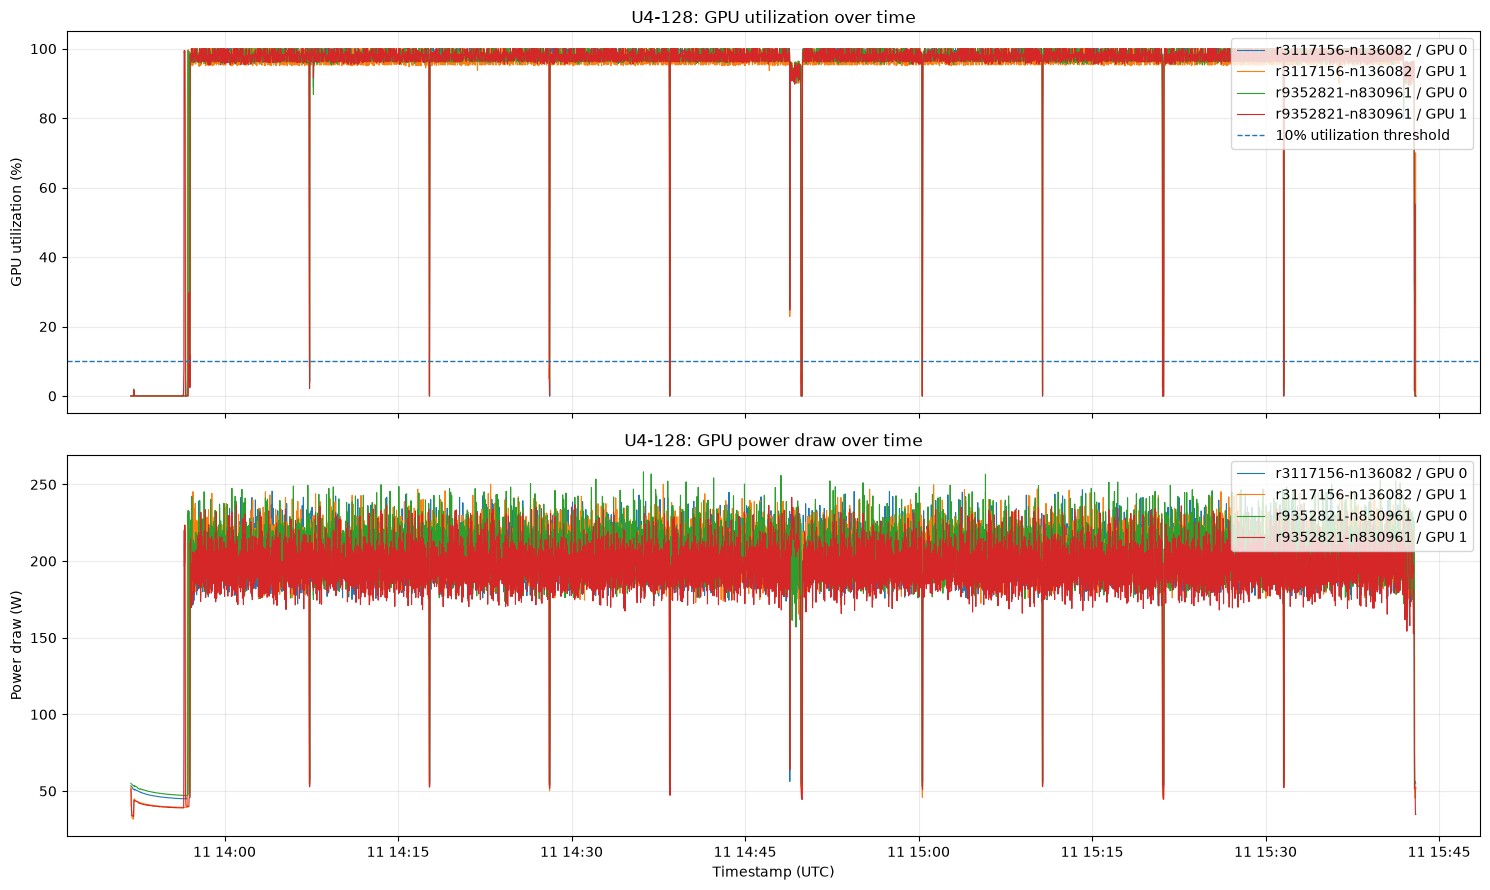

Observed rows: 26664
GPU streams: 4
Observed time range: 2021-05-11 13:51:54+00:00 to 2021-05-11 15:42:59+00:00


In [111]:
import matplotlib.pyplot as plt
import pandas as pd

target_job = "59638293409445"

job_ts = pilot_gpu_1s_v2[
    pilot_gpu_1s_v2["job_id"].astype(str) == target_job
].copy()

if job_ts.empty:
    raise ValueError(f"No telemetry found for job {target_job}")

job_ts["timestamp_1s"] = pd.to_datetime(
    job_ts["timestamp_1s"], utc=True
)

job_ts = job_ts.sort_values(
    ["rack_node_id", "gpu_index", "timestamp_1s"]
)

streams = job_ts[["rack_node_id", "gpu_index"]].drop_duplicates()

fig, axes = plt.subplots(
    2, 1, figsize=(15, 9), sharex=True
)

for _, stream in streams.iterrows():
    mask = (
        (job_ts["rack_node_id"] == stream["rack_node_id"])
        & (job_ts["gpu_index"] == stream["gpu_index"])
    )
    series = job_ts.loc[mask].sort_values("timestamp_1s")

    label = f'{stream["rack_node_id"]} / GPU {stream["gpu_index"]}'

    axes[0].plot(
        series["timestamp_1s"],
        series["utilization_gpu_pct"],
        label=label,
        linewidth=0.8,
    )
    axes[1].plot(
        series["timestamp_1s"],
        series["power_draw_W"],
        label=label,
        linewidth=0.8,
    )

axes[0].axhline(
    10, linestyle="--", linewidth=1,
    label="10% utilization threshold"
)
axes[0].set_ylabel("GPU utilization (%)")
axes[0].set_title("U4-128: GPU utilization over time")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.25)

axes[1].set_ylabel("Power draw (W)")
axes[1].set_xlabel("Timestamp (UTC)")
axes[1].set_title("U4-128: GPU power draw over time")
axes[1].legend(loc="upper right")
axes[1].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

print("Observed rows:", len(job_ts))
print("GPU streams:", len(streams))
print("Observed time range:",
      job_ts["timestamp_1s"].min(), "to",
      job_ts["timestamp_1s"].max())

In [112]:
import pandas as pd

target_job = "59638293409445"

ts = pilot_gpu_1s_v2[
    pilot_gpu_1s_v2["job_id"].astype(str) == target_job
].copy()

ts["timestamp_1s"] = pd.to_datetime(ts["timestamp_1s"], utc=True)
ts = ts.sort_values(
    ["rack_node_id", "gpu_index", "timestamp_1s"]
)

stream_keys = ["rack_node_id", "gpu_index"]
ts["previous_timestamp"] = ts.groupby(stream_keys)["timestamp_1s"].shift()
ts["gap_seconds"] = (
    ts["timestamp_1s"] - ts["previous_timestamp"]
).dt.total_seconds()

ts["low_util"] = ts["utilization_gpu_pct"] < 10

# Start a new episode when utilization changes, or when the
# telemetry stream has a gap greater than one second.
ts["new_episode"] = (
    ts.groupby(stream_keys)["low_util"].transform(
        lambda s: s.ne(s.shift())
    )
    | ts["gap_seconds"].gt(1)
    | ts["previous_timestamp"].isna()
)

ts["episode_id"] = ts.groupby(stream_keys)["new_episode"].cumsum()

episodes = (
    ts.groupby(stream_keys + ["episode_id"], as_index=False)
    .agg(
        start_time=("timestamp_1s", "min"),
        end_time=("timestamp_1s", "max"),
        observations=("timestamp_1s", "size"),
        low_util=("low_util", "first"),
        mean_utilization_pct=("utilization_gpu_pct", "mean"),
        mean_power_W=("power_draw_W", "mean"),
        min_power_W=("power_draw_W", "min"),
        max_temperature_C=("temperature_gpu_avg", "max"),
    )
)

# Retain low-utilization episodes only.
low_episodes = episodes[episodes["low_util"]].copy()

low_episodes["duration_seconds"] = low_episodes["observations"]
low_episodes["estimated_energy_Wh"] = (
    low_episodes["mean_power_W"]
    * low_episodes["duration_seconds"]
    / 3600
)

display(
    low_episodes.sort_values(
        "duration_seconds", ascending=False
    ).head(25).round(3)
)

print("Low-utilization episodes:", len(low_episodes))
print("Longest episode (seconds):",
      low_episodes["duration_seconds"].max())
print("Episodes lasting at least 30 seconds:",
      (low_episodes["duration_seconds"] >= 30).sum())

/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/696427836.py:61: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).head(25).round(3)


,rack_node_id,gpu_index,episode_id,start_time,end_time,observations,low_util,mean_utilization_pct,mean_power_W,min_power_W,max_temperature_C,duration_seconds,estimated_energy_Wh
50,r9352821-n830961,0,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:49+00:00,296,True,0.035,49.274,47.036,60.600,296,4.051
0,r3117156-n136082,0,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,True,0.044,47.046,44.903,61.200,294,3.842
25,r3117156-n136082,1,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,True,0.042,40.358,31.674,57.000,294,3.296
75,r9352821-n830961,1,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:29+00:00,276,True,0.067,40.241,33.322,54.400,276,3.085
77,r9352821-n830961,1,3,2021-05-11 13:56:37+00:00,2021-05-11 13:56:55+00:00,19,True,1.155,40.810,39.794,45.333,19,0.215
91,r9352821-n830961,1,17,2021-05-11 14:49:50+00:00,2021-05-11 14:49:56+00:00,7,True,0.000,47.606,44.489,57.400,7,0.093
43,r3117156-n136082,1,19,2021-05-11 15:21:05+00:00,2021-05-11 15:21:11+00:00,7,True,1.467,47.968,44.903,59.100,7,0.093
37,r3117156-n136082,1,13,2021-05-11 14:49:50+00:00,2021-05-11 14:49:56+00:00,7,True,1.495,47.935,44.851,59.444,7,0.093
97,r9352821-n830961,1,23,2021-05-11 15:21:06+00:00,2021-05-11 15:21:11+00:00,6,True,0.000,47.985,44.602,57.111,6,0.080
70,r9352821-n830961,0,21,2021-05-11 15:21:06+00:00,2021-05-11 15:21:11+00:00,6,True,0.000,54.851,54.227,63.111,6,0.091


Low-utilization episodes: 54
Longest episode (seconds): 296
Episodes lasting at least 30 seconds: 4


In [113]:
import numpy as np
import pandas as pd

# Configuration: explicitly document the investigation thresholds.
LOW_UTIL_THRESHOLD_PCT = 10
SUSTAINED_DURATION_SECONDS = 30

# Reconstruct telemetry for the same job.
target_job = "59638293409445"

job_ts = pilot_gpu_1s_v2[
    pilot_gpu_1s_v2["job_id"].astype(str) == target_job
].copy()

job_ts["timestamp_1s"] = pd.to_datetime(
    job_ts["timestamp_1s"], utc=True
)

# Estimate each GPU stream's baseline from its lowest 10% of power readings.
# This is a proxy, not a verified hardware idle-power measurement.
baseline = (
    job_ts.groupby(["rack_node_id", "gpu_index"])["power_draw_W"]
    .quantile(0.10)
    .rename("baseline_power_W")
    .reset_index()
)

# Select sustained low-utilization episodes.
sustained = low_episodes[
    (low_episodes["duration_seconds"] >= SUSTAINED_DURATION_SECONDS)
].copy()

sustained = sustained.merge(
    baseline,
    on=["rack_node_id", "gpu_index"],
    how="left"
)

# Compute observed energy and energy above the estimated baseline.
sustained["observed_energy_Wh"] = (
    sustained["mean_power_W"]
    * sustained["duration_seconds"] / 3600
)

sustained["baseline_energy_Wh"] = (
    sustained["baseline_power_W"]
    * sustained["duration_seconds"] / 3600
)

sustained["energy_above_baseline_Wh"] = (
    sustained["observed_energy_Wh"]
    - sustained["baseline_energy_Wh"]
).clip(lower=0)

display(
    sustained[
        [
            "rack_node_id",
            "gpu_index",
            "start_time",
            "end_time",
            "duration_seconds",
            "mean_utilization_pct",
            "mean_power_W",
            "baseline_power_W",
            "observed_energy_Wh",
            "baseline_energy_Wh",
            "energy_above_baseline_Wh",
        ]
    ].sort_values("duration_seconds", ascending=False).round(3)
)

print("Sustained episodes:", len(sustained))
print(
    "Observed energy during sustained low utilization (Wh):",
    round(sustained["observed_energy_Wh"].sum(), 3)
)
print(
    "Energy above estimated baseline (Wh):",
    round(sustained["energy_above_baseline_Wh"].sum(), 3)
)

/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/2573312792.py:70: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].sort_values("duration_seconds", ascending=False).round(3)


,rack_node_id,gpu_index,start_time,end_time,duration_seconds,mean_utilization_pct,mean_power_W,baseline_power_W,observed_energy_Wh,baseline_energy_Wh,energy_above_baseline_Wh
2,r9352821-n830961,0,2021-05-11 13:51:54+00:00,2021-05-11 13:56:49+00:00,296,0.035,49.274,183.620,4.051,15.098,0.0
0,r3117156-n136082,0,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,0.044,47.046,183.210,3.842,14.962,0.0
1,r3117156-n136082,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,0.042,40.358,188.146,3.296,15.365,0.0
3,r9352821-n830961,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:29+00:00,276,0.067,40.241,177.068,3.085,13.575,0.0


Sustained episodes: 4
Observed energy during sustained low utilization (Wh): 14.275
Energy above estimated baseline (Wh): 0.0


In [114]:
import pandas as pd
import numpy as np

target_job = "59638293409445"

job_ts = pilot_gpu_1s_v2[
    pilot_gpu_1s_v2["job_id"].astype(str) == target_job
].copy()

job_ts["power_draw_W"] = pd.to_numeric(
    job_ts["power_draw_W"], errors="coerce"
)
job_ts["utilization_gpu_pct"] = pd.to_numeric(
    job_ts["utilization_gpu_pct"], errors="coerce"
)

# Summarize power across utilization bands.
job_ts["utilization_band"] = pd.cut(
    job_ts["utilization_gpu_pct"],
    bins=[-0.01, 1, 10, 25, 50, 75, 100],
    labels=[
        "0–1%",
        ">1–10%",
        ">10–25%",
        ">25–50%",
        ">50–75%",
        ">75–100%",
    ],
    include_lowest=True,
)

power_by_utilization = (
    job_ts.groupby("utilization_band", observed=False)
    .agg(
        observations=("power_draw_W", "count"),
        median_power_W=("power_draw_W", "median"),
        p10_power_W=("power_draw_W", lambda x: x.quantile(0.10)),
        p25_power_W=("power_draw_W", lambda x: x.quantile(0.25)),
        mean_power_W=("power_draw_W", "mean"),
        median_temperature_C=("temperature_gpu", "median"),
    )
    .reset_index()
)

display(power_by_utilization.round(2))

print(
    "Overall GPU power range:",
    round(job_ts["power_draw_W"].min(), 2),
    "to",
    round(job_ts["power_draw_W"].max(), 2),
    "W",
)
print(
    "Overall GPU utilization range:",
    round(job_ts["utilization_gpu_pct"].min(), 2),
    "to",
    round(job_ts["utilization_gpu_pct"].max(), 2),
    "%",
)

KeyError: "Label(s) ['temperature_gpu'] do not exist"

In [115]:
import pandas as pd
import numpy as np

target_job = "59638293409445"

job_ts = pilot_gpu_1s_v2[
    pilot_gpu_1s_v2["job_id"].astype(str) == target_job
].copy()

job_ts["power_draw_W"] = pd.to_numeric(
    job_ts["power_draw_W"], errors="coerce"
)
job_ts["utilization_gpu_pct"] = pd.to_numeric(
    job_ts["utilization_gpu_pct"], errors="coerce"
)

# Find the actual temperature column, if present.
temperature_candidates = [
    c for c in job_ts.columns
    if "temperature" in c.lower() or "temp" in c.lower()
]
temperature_col = temperature_candidates[0] if temperature_candidates else None

job_ts["utilization_band"] = pd.cut(
    job_ts["utilization_gpu_pct"],
    bins=[-0.01, 1, 10, 25, 50, 75, 100],
    labels=["0–1%", ">1–10%", ">10–25%", ">25–50%", ">50–75%", ">75–100%"],
    include_lowest=True,
)

aggregations = {
    "observations": ("power_draw_W", "count"),
    "median_power_W": ("power_draw_W", "median"),
    "p10_power_W": ("power_draw_W", lambda x: x.quantile(0.10)),
    "p25_power_W": ("power_draw_W", lambda x: x.quantile(0.25)),
    "mean_power_W": ("power_draw_W", "mean"),
}

if temperature_col:
    job_ts[temperature_col] = pd.to_numeric(
        job_ts[temperature_col], errors="coerce"
    )
    aggregations["median_temperature_C"] = (temperature_col, "median")

power_by_utilization = (
    job_ts.groupby("utilization_band", observed=False)
    .agg(**aggregations)
    .reset_index()
)

print("Temperature column detected:", temperature_col)
print("Telemetry columns:", job_ts.columns.tolist())
display(power_by_utilization.round(2))

print(
    "Overall GPU power range:",
    round(job_ts["power_draw_W"].min(), 2),
    "to",
    round(job_ts["power_draw_W"].max(), 2),
    "W",
)
print(
    "Overall GPU utilization range:",
    round(job_ts["utilization_gpu_pct"].min(), 2),
    "to",
    round(job_ts["utilization_gpu_pct"].max(), 2),
    "%",
)

Temperature column detected: temperature_gpu_avg
Telemetry columns: ['job_id', 'source_filename', 'rack_node_id', 'rack_id', 'node_number', 'model', 'workload_family', 'gpu_index', 'timestamp_1s', 'utilization_gpu_pct', 'utilization_memory_pct', 'memory_used_MiB', 'memory_free_MiB', 'temperature_gpu_avg', 'temperature_gpu_max', 'temperature_memory_avg', 'power_draw_W', 'pcie_link_width_current', 'raw_observation_count', 'clocks_current_memory_MHz', 'clocks_current_sm_MHz', 'clocks_current_video_MHz', 'power_limit_W', 'utilization_band']


,utilization_band,observations,median_power_W,p10_power_W,p25_power_W,mean_power_W,median_temperature_C
0,0–1%,1250,45.16,39.35,40.04,44.72,45.00
1,>1–10%,59,52.46,39.93,45.75,50.91,56.67
2,>10–25%,17,55.16,46.13,46.87,66.48,46.11
3,>25–50%,24,61.30,47.82,53.44,78.85,61.24
4,>50–75%,35,105.89,52.57,53.82,95.97,60.89
5,>75–100%,25279,200.90,185.80,192.92,202.25,66.78


Overall GPU power range: 31.67 to 258.17 W
Overall GPU utilization range: 0.0 to 100.0 %


In [116]:
import pandas as pd
import numpy as np

target_job = "59638293409445"

job_ts = pilot_gpu_1s_v2[
    pilot_gpu_1s_v2["job_id"].astype(str) == target_job
].copy()

job_ts["power_draw_W"] = pd.to_numeric(
    job_ts["power_draw_W"], errors="coerce"
)
job_ts["utilization_gpu_pct"] = pd.to_numeric(
    job_ts["utilization_gpu_pct"], errors="coerce"
)

gpu_power_profile = (
    job_ts.groupby(["rack_node_id", "gpu_index"])
    .apply(
        lambda g: pd.Series({
            "observations": len(g),
            "near_idle_observations": (
                g["utilization_gpu_pct"] <= 1
            ).sum(),
            "high_util_observations": (
                g["utilization_gpu_pct"] >= 75
            ).sum(),
            "near_idle_median_power_W": (
                g.loc[
                    g["utilization_gpu_pct"] <= 1,
                    "power_draw_W"
                ].median()
            ),
            "near_idle_p10_power_W": (
                g.loc[
                    g["utilization_gpu_pct"] <= 1,
                    "power_draw_W"
                ].quantile(0.10)
            ),
            "high_util_median_power_W": (
                g.loc[
                    g["utilization_gpu_pct"] >= 75,
                    "power_draw_W"
                ].median()
            ),
            "high_util_median_temperature_C": (
                g.loc[
                    g["utilization_gpu_pct"] >= 75,
                    "temperature_gpu_avg"
                ].median()
            ),
        }),
        include_groups=False,
    )
    .reset_index()
)

gpu_power_profile["power_difference_W"] = (
    gpu_power_profile["high_util_median_power_W"]
    - gpu_power_profile["near_idle_median_power_W"]
)

display(gpu_power_profile.round(2))

print(
    "All four GPUs have both near-idle and high-utilization observations:",
    bool(
        (
            (gpu_power_profile["near_idle_observations"] > 0)
            & (gpu_power_profile["high_util_observations"] > 0)
        ).all()
    ),
)

,rack_node_id,gpu_index,observations,near_idle_observations,high_util_observations,near_idle_median_power_W,near_idle_p10_power_W,high_util_median_power_W,high_util_median_temperature_C,power_difference_W
0,r3117156-n136082,0,6666.0,316.0,6322.0,46.54,45.05,200.12,68.56,153.58
1,r3117156-n136082,1,6666.0,306.0,6314.0,40.15,39.34,204.81,64.78,164.66
2,r9352821-n830961,0,6666.0,315.0,6324.0,48.74,47.23,203.57,68.50,154.83
3,r9352821-n830961,1,6666.0,313.0,6319.0,39.98,39.06,196.02,62.00,156.04


All four GPUs have both near-idle and high-utilization observations: True


In [117]:
import numpy as np
import pandas as pd

df = pilot_gpu_1s_v2.copy()

df["power_draw_W"] = pd.to_numeric(df["power_draw_W"], errors="coerce")
df["utilization_gpu_pct"] = pd.to_numeric(
    df["utilization_gpu_pct"], errors="coerce"
)

df = df.dropna(
    subset=["job_id", "power_draw_W", "utilization_gpu_pct"]
).copy()

df["is_near_idle"] = df["utilization_gpu_pct"] <= 1
df["is_low_util"] = df["utilization_gpu_pct"] < 10
df["is_high_util"] = df["utilization_gpu_pct"] >= 75

job_profile = (
    df.groupby(["job_id", "model", "workload_family"], as_index=False)
    .agg(
        observations=("power_draw_W", "size"),
        mean_gpu_utilization_pct=("utilization_gpu_pct", "mean"),
        median_power_W=("power_draw_W", "median"),
        mean_power_W=("power_draw_W", "mean"),
        near_idle_observations=("is_near_idle", "sum"),
        low_util_observations=("is_low_util", "sum"),
        high_util_observations=("is_high_util", "sum"),
        observed_energy_Wh=("power_draw_W", lambda x: x.sum() / 3600),
    )
)

job_profile["near_idle_pct"] = (
    100 * job_profile["near_idle_observations"]
    / job_profile["observations"]
)
job_profile["low_util_pct"] = (
    100 * job_profile["low_util_observations"]
    / job_profile["observations"]
)
job_profile["high_util_pct"] = (
    100 * job_profile["high_util_observations"]
    / job_profile["observations"]
)

job_profile = job_profile.sort_values(
    ["low_util_pct", "low_util_observations"],
    ascending=False,
)

display(job_profile.round(2))

print("Jobs analyzed:", job_profile["job_id"].nunique())
print("Telemetry observations analyzed:", len(df))
print(
    "Overall near-idle observation share:",
    round(100 * df["is_near_idle"].mean(), 2),
    "%",
)
print(
    "Overall low-utilization observation share:",
    round(100 * df["is_low_util"].mean(), 2),
    "%",
)

,job_id,model,workload_family,observations,mean_gpu_utilization_pct,median_power_W,mean_power_W,near_idle_observations,low_util_observations,high_util_observations,observed_energy_Wh,near_idle_pct,low_util_pct,high_util_pct
12,48020198141948,U4-64,Vision,2482,72.25,183.36,162.03,396,405,1980,111.71,15.95,16.32,79.77
4,18242747496687,U5-32,Vision,1648,75.52,161.99,146.10,226,243,1368,66.88,13.71,14.75,83.01
7,29381280178268,U3-32,Vision,5612,80.14,157.65,146.55,532,541,5027,228.46,9.48,9.64,89.58
6,25713459161743,U3-128,Vision,11788,86.53,189.75,176.48,987,1022,10690,577.87,8.37,8.67,90.69
14,55788973536832,resnet101,Vision,52118,83.78,184.10,173.87,2332,2764,45592,2517.18,4.47,5.30,87.48
17,59638293409445,U4-128,Vision,26664,92.54,200.05,194.20,1250,1309,25279,1438.34,4.69,4.91,94.81
19,74636684972411,U3-64,Vision,9678,80.60,167.18,168.08,438,446,8963,451.85,4.53,4.61,92.61
18,68307271431118,U4-32,Vision,12776,71.30,130.69,127.38,481,493,5346,452.07,3.76,3.86,41.84
3,18203079158032,schnet,GNN,15558,63.07,132.20,122.90,515,533,4252,531.13,3.31,3.43,27.33
8,36230628475012,pna,GNN,5848,58.02,85.89,83.23,144,161,1895,135.20,2.46,2.75,32.40


Jobs analyzed: 26
Telemetry observations analyzed: 828531
Overall near-idle observation share: 1.38 %
Overall low-utilization observation share: 1.55 %


In [118]:
import json

from pathlib import Path

# Calculate exact pilot-wide percentages from observations
overall_summary = {
    "observations": int(len(df)),
    "jobs": int(df["job_id"].nunique()),
    "near_idle_pct": round(100 * df["is_near_idle"].mean(), 4),
    "low_util_pct": round(100 * df["is_low_util"].mean(), 4),
    "high_util_pct": round(100 * df["is_high_util"].mean(), 4),
    "mean_gpu_utilization_pct": round(
        df["utilization_gpu_pct"].mean(), 4
    ),
}

# Validate that each utilization category is a subset of the expected range
assert (
    df.loc[df["is_near_idle"], "utilization_gpu_pct"] <= 1
).all()
assert (
    df.loc[df["is_high_util"], "utilization_gpu_pct"] >= 75
).all()

output_dir = project_root / "data" / "processed"
reference_dir = project_root / "data" / "reference"
output_dir.mkdir(parents=True, exist_ok=True)
reference_dir.mkdir(parents=True, exist_ok=True)

profile_path = output_dir / "mit_supercloud_job_utilization_profile_v1.csv"
audit_path = reference_dir / "mit_supercloud_utilization_profile_audit_v1.json"

job_profile.to_csv(profile_path, index=False)

audit = {
    "dataset": "MIT Supercloud GPU telemetry pilot",
    "thresholds": {
        "near_idle_gpu_utilization_pct_lte": 1,
        "low_utilization_gpu_utilization_pct_lt": 10,
        "high_utilization_gpu_utilization_pct_gte": 75,
    },
    "summary": overall_summary,
    "limitations": [
        "Pilot contains 26 jobs and is not a representative estimate of the entire data center.",
        "Telemetry observations do not necessarily cover complete scheduler runtimes.",
        "U3-32 has telemetry for only 2 of 4 scheduler-allocated GPUs.",
        "GPU utilization alone does not establish workload inefficiency.",
    ],
}

with open(audit_path, "w") as f:
    json.dump(audit, f, indent=2)

print("Saved profile:", profile_path)
print("Saved audit:", audit_path)
print(json.dumps(overall_summary, indent=2))

Saved profile: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_job_utilization_profile_v1.csv
Saved audit: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/reference/mit_supercloud_utilization_profile_audit_v1.json
{
  "observations": 828531,
  "jobs": 26,
  "near_idle_pct": 1.385,
  "low_util_pct": 1.5468,
  "high_util_pct": 91.4253,
  "mean_gpu_utilization_pct": 87.9164
}


In [120]:
from pathlib import Path

# Start with the saved job-level utilization profile.
candidates = job_profile.copy()

# Flag the known incomplete job: scheduler allocated 4 GPUs,
# but telemetry was found for only 2 GPUs on one node.
incomplete_job_ids = {"29381280178268"}

candidates["telemetry_status"] = candidates["job_id"].astype(str).apply(
    lambda job_id: (
        "INCOMPLETE - 2 of 4 allocated GPUs observed"
        if job_id in incomplete_job_ids
        else "Allocation count matched"
    )
)

# Make the review criteria explicit.
candidates["investigation_priority"] = "Routine"

candidates.loc[
    (candidates["low_util_pct"] >= 2)
    & (candidates["low_util_observations"] >= 100),
    "investigation_priority",
] = "Review"

candidates.loc[
    (candidates["low_util_pct"] >= 5)
    & (candidates["low_util_observations"] >= 250)
    & (~candidates["job_id"].astype(str).isin(incomplete_job_ids)),
    "investigation_priority",
] = "High review priority"

# Incomplete telemetry is always separately flagged, not ranked
# as if it were a complete job.
candidates.loc[
    candidates["job_id"].astype(str).isin(incomplete_job_ids),
    "investigation_priority",
] = "Data-quality review"

priority_order = {
    "High review priority": 0,
    "Review": 1,
    "Data-quality review": 2,
    "Routine": 3,
}

candidates["_priority_order"] = candidates[
    "investigation_priority"
].map(priority_order)

candidates = candidates.sort_values(
    ["_priority_order", "low_util_pct", "low_util_observations"],
    ascending=[True, False, False],
).drop(columns="_priority_order")

columns_to_show = [
    "job_id",
    "model",
    "workload_family",
    "observations",
    "low_util_observations",
    "low_util_pct",
    "near_idle_pct",
    "high_util_pct",
    "mean_power_W",
    "observed_energy_Wh",
    "telemetry_status",
    "investigation_priority",
]

display(candidates[columns_to_show].head(15).round(3))

output_path = (
    project_root
    / "data"
    / "processed"
    / "mit_supercloud_job_investigation_candidates_v1.csv"
)

output_path.parent.mkdir(parents=True, exist_ok=True)
candidates[columns_to_show].to_csv(output_path, index=False)

print(f"Saved investigation candidates: {output_path}")
print("\nPriority counts:")
print(candidates["investigation_priority"].value_counts())

,job_id,model,workload_family,observations,low_util_observations,low_util_pct,near_idle_pct,high_util_pct,mean_power_W,observed_energy_Wh,telemetry_status,investigation_priority
12,48020198141948,U4-64,Vision,2482,405,16.317,15.955,79.774,162.028,111.709,Allocation count matched,High review priority
6,25713459161743,U3-128,Vision,11788,1022,8.670,8.373,90.685,176.480,577.873,Allocation count matched,High review priority
14,55788973536832,resnet101,Vision,52118,2764,5.303,4.474,87.478,173.872,2517.179,Allocation count matched,High review priority
4,18242747496687,U5-32,Vision,1648,243,14.745,13.714,83.010,146.096,66.879,Allocation count matched,Review
17,59638293409445,U4-128,Vision,26664,1309,4.909,4.688,94.806,194.196,1438.342,Allocation count matched,Review
19,74636684972411,U3-64,Vision,9678,446,4.608,4.526,92.612,168.077,451.848,Allocation count matched,Review
18,68307271431118,U4-32,Vision,12776,493,3.859,3.765,41.844,127.382,452.066,Allocation count matched,Review
3,18203079158032,schnet,GNN,15558,533,3.426,3.310,27.330,122.900,531.131,Allocation count matched,Review
8,36230628475012,pna,GNN,5848,161,2.753,2.462,32.404,83.230,135.202,Allocation count matched,Review
15,59030654331752,U5-128,Vision,20287,545,2.686,1.641,97.156,197.428,1112.559,Allocation count matched,Review


Saved investigation candidates: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_job_investigation_candidates_v1.csv

Priority counts:
investigation_priority
Routine                 13
Review                   9
High review priority     3
Data-quality review      1
Name: count, dtype: int64


In [121]:
import pandas as pd
from pathlib import Path

target_job = "48020198141948"

episode_df = pilot_gpu_1s_v2.copy()
episode_df["job_id"] = episode_df["job_id"].astype(str)

episode_df = episode_df.loc[
    episode_df["job_id"] == target_job
].copy()

episode_df["timestamp_1s"] = pd.to_datetime(
    episode_df["timestamp_1s"], utc=True, errors="coerce"
)
episode_df["utilization_gpu_pct"] = pd.to_numeric(
    episode_df["utilization_gpu_pct"], errors="coerce"
)
episode_df["power_draw_W"] = pd.to_numeric(
    episode_df["power_draw_W"], errors="coerce"
)

episode_df = episode_df.dropna(
    subset=[
        "rack_node_id",
        "gpu_index",
        "timestamp_1s",
        "utilization_gpu_pct",
        "power_draw_W",
    ]
).sort_values(
    ["rack_node_id", "gpu_index", "timestamp_1s"]
).copy()

stream_cols = ["rack_node_id", "gpu_index"]

# Identify low-utilization observations.
episode_df["is_low_util"] = (
    episode_df["utilization_gpu_pct"] < 10
)

# A new episode starts when low utilization begins or when
# the gap between consecutive samples exceeds one second.
episode_df["previous_timestamp"] = (
    episode_df.groupby(stream_cols)["timestamp_1s"].shift(1)
)
episode_df["previous_is_low"] = (
    episode_df.groupby(stream_cols)["is_low_util"].shift(1)
)

episode_df["time_gap_s"] = (
    episode_df["timestamp_1s"] - episode_df["previous_timestamp"]
).dt.total_seconds()

episode_df["episode_start"] = (
    episode_df["is_low_util"]
    & (
        ~episode_df["previous_is_low"].fillna(False).astype(bool)
        | episode_df["time_gap_s"].ne(1)
    )
)

episode_df["episode_id"] = (
    episode_df.groupby(stream_cols)["episode_start"].cumsum()
)

low_rows = episode_df.loc[episode_df["is_low_util"]].copy()

episodes = (
    low_rows.groupby(
        stream_cols + ["episode_id"], as_index=False
    )
    .agg(
        start_time=("timestamp_1s", "min"),
        end_time=("timestamp_1s", "max"),
        observations=("timestamp_1s", "size"),
        mean_utilization_pct=("utilization_gpu_pct", "mean"),
        mean_power_W=("power_draw_W", "mean"),
        median_power_W=("power_draw_W", "median"),
        max_power_W=("power_draw_W", "max"),
    )
)

# Since samples are one second apart, duration includes the
# first sample's second. Episode boundaries are split at gaps.
episodes["duration_s"] = episodes["observations"]
episodes["duration_min"] = episodes["duration_s"] / 60

episodes = episodes.sort_values(
    ["duration_s", "mean_power_W"], ascending=[False, False]
)

print(f"Job: {target_job}")
print(f"GPU streams observed: {episode_df[stream_cols].drop_duplicates().shape[0]}")
print(f"Low-utilization episodes: {len(episodes)}")
print(f"Episodes lasting at least 10 seconds: {(episodes['duration_s'] >= 10).sum()}")
print(f"Episodes lasting at least 30 seconds: {(episodes['duration_s'] >= 30).sum()}")

display(episodes.head(20).round(3))

output_path = (
    project_root / "data" / "processed"
    / "mit_supercloud_u4_64_low_util_episodes_v1.csv"
)
episodes.to_csv(output_path, index=False)
print(f"Saved episode analysis: {output_path}")

Job: 48020198141948
GPU streams observed: 1
Low-utilization episodes: 11
Episodes lasting at least 10 seconds: 1
Episodes lasting at least 30 seconds: 1


/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/2660177058.py:99: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(episodes.head(20).round(3))


,rack_node_id,gpu_index,episode_id,start_time,end_time,observations,mean_utilization_pct,mean_power_W,median_power_W,max_power_W,duration_s,duration_min
0,r9352821-n830961,0,1,2021-05-10 21:32:56+00:00,2021-05-10 21:39:21+00:00,386,0.033,46.216,46.185,46.557,386,6.433
6,r9352821-n830961,0,7,2021-05-10 22:00:12+00:00,2021-05-10 22:00:16+00:00,5,0.000,55.746,55.670,56.583,5,0.083
9,r9352821-n830961,0,10,2021-05-10 22:14:13+00:00,2021-05-10 22:14:14+00:00,2,0.450,56.616,56.616,56.868,2,0.033
3,r9352821-n830961,0,4,2021-05-10 21:49:37+00:00,2021-05-10 21:49:38+00:00,2,1.444,56.094,56.094,56.453,2,0.033
4,r9352821-n830961,0,5,2021-05-10 21:56:23+00:00,2021-05-10 21:56:24+00:00,2,0.000,56.016,56.016,56.321,2,0.033
5,r9352821-n830961,0,6,2021-05-10 21:56:48+00:00,2021-05-10 21:56:49+00:00,2,0.400,55.797,55.797,55.993,2,0.033
1,r9352821-n830961,0,2,2021-05-10 21:39:27+00:00,2021-05-10 21:39:28+00:00,2,1.356,47.092,47.092,47.179,2,0.033
7,r9352821-n830961,0,8,2021-05-10 22:03:40+00:00,2021-05-10 22:03:40+00:00,1,9.100,85.908,85.908,85.908,1,0.017
8,r9352821-n830961,0,9,2021-05-10 22:07:04+00:00,2021-05-10 22:07:04+00:00,1,3.444,57.418,57.418,57.418,1,0.017
2,r9352821-n830961,0,3,2021-05-10 21:42:51+00:00,2021-05-10 21:42:51+00:00,1,0.400,57.146,57.146,57.146,1,0.017


Saved episode analysis: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_u4_64_low_util_episodes_v1.csv


In [122]:
# Summarize low-utilization behavior by physical GPU stream.
stream_summary = (
    episode_df.groupby(["rack_node_id", "gpu_index"], as_index=False)
    .agg(
        observations=("timestamp_1s", "size"),
        mean_utilization_pct=("utilization_gpu_pct", "mean"),
        mean_power_W=("power_draw_W", "mean"),
        low_util_observations=("is_low_util", "sum"),
    )
)

stream_summary["low_util_pct"] = (
    100 * stream_summary["low_util_observations"]
    / stream_summary["observations"]
)

# Summarize episode durations and power by GPU.
episode_summary = (
    episodes.groupby(["rack_node_id", "gpu_index"], as_index=False)
    .agg(
        low_util_episodes=("episode_id", "size"),
        longest_episode_s=("duration_s", "max"),
        episodes_ge_10s=("duration_s", lambda s: (s >= 10).sum()),
        episodes_ge_30s=("duration_s", lambda s: (s >= 30).sum()),
        mean_episode_power_W=("mean_power_W", "mean"),
    )
)

stream_summary = stream_summary.merge(
    episode_summary,
    on=["rack_node_id", "gpu_index"],
    how="left",
)

stream_summary = stream_summary.sort_values(
    ["longest_episode_s", "low_util_pct"],
    ascending=[False, False],
)

display(stream_summary.round(3))

print("\nLongest low-utilization episodes across all GPUs:")
display(
    episodes.loc[episodes["duration_s"] >= 10]
    .sort_values("duration_s", ascending=False)
    .head(20)
    .round(3)
)

,rack_node_id,gpu_index,observations,mean_utilization_pct,mean_power_W,low_util_observations,low_util_pct,low_util_episodes,longest_episode_s,episodes_ge_10s,episodes_ge_30s,mean_episode_power_W
0,r9352821-n830961,0,2482,72.25,162.028,405,16.317,11,386,1,1,57.243



Longest low-utilization episodes across all GPUs:


/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/1102746948.py:47: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


,rack_node_id,gpu_index,episode_id,start_time,end_time,observations,mean_utilization_pct,mean_power_W,median_power_W,max_power_W,duration_s,duration_min
0,r9352821-n830961,0,1,2021-05-10 21:32:56+00:00,2021-05-10 21:39:21+00:00,386,0.033,46.216,46.185,46.557,386,6.433


In [123]:
target_job = "48020198141948"

job_rows = pilot_gpu_1s_v2.loc[
    pilot_gpu_1s_v2["job_id"].astype(str) == target_job
].copy()

print("=== Telemetry coverage ===")
print(f"Telemetry rows: {len(job_rows):,}")
print(f"Source files: {job_rows['source_filename'].nunique()}")
print(f"Rack/node identities: {job_rows['rack_node_id'].nunique()}")

print("\n=== Source files and GPU streams ===")
file_streams = (
    job_rows.groupby(
        ["source_filename", "rack_node_id"], dropna=False
    )
    .agg(
        observations=("timestamp_1s", "size"),
        gpu_indices=("gpu_index", lambda s: sorted(s.dropna().unique().tolist())),
        first_timestamp=("timestamp_1s", "min"),
        last_timestamp=("timestamp_1s", "max"),
    )
    .reset_index()
)
display(file_streams)

print("\n=== Manifest entries ===")
manifest_path = (
    project_root
    / "data"
    / "reference"
    / "mit_supercloud_gpu_pilot_manifest.csv"
)

manifest = pd.read_csv(manifest_path)
manifest_job = manifest.loc[
    manifest["job_id"].astype(str) == target_job
]
display(manifest_job)

print("\n=== GPU indices by rack/node ===")
display(
    job_rows.groupby(["rack_node_id", "gpu_index"], as_index=False)
    .agg(
        observations=("timestamp_1s", "size"),
        first_timestamp=("timestamp_1s", "min"),
        last_timestamp=("timestamp_1s", "max"),
    )
)

=== Telemetry coverage ===
Telemetry rows: 2,482
Source files: 1
Rack/node identities: 1

=== Source files and GPU streams ===


,source_filename,rack_node_id,observations,gpu_indices,first_timestamp,last_timestamp
0,48020198141948-r9352821-n830961.csv,r9352821-n830961,2482,[0],2021-05-10 21:32:56+00:00,2021-05-10 22:14:17+00:00



=== Manifest entries ===


,job_id,model,workload_family,s3_directory,filename,size_bytes,date,time,s3_uri,gpu_type,tres_req
21,48020198141948,U4-64,Vision,66,48020198141948-r9352821-n830961.csv,1185411,2022-01-20,08:53:04,s3://mit-supercloud-dataset/datacenter-challen...,Volta,"1=20,2=170000,4=1,5=20,1002=1"



=== GPU indices by rack/node ===


,rack_node_id,gpu_index,observations,first_timestamp,last_timestamp
0,r9352821-n830961,0,2482,2021-05-10 21:32:56+00:00,2021-05-10 22:14:17+00:00


In [124]:
target_job = "48020198141948"

# Find the scheduler record(s) for this job.
scheduler_matches = scheduler_df.loc[
    scheduler_df["job_id"].astype(str) == target_job
].copy()

print("Scheduler records:", len(scheduler_matches))

if scheduler_matches.empty:
    print("No matching scheduler records found. Check scheduler_df column names and job ID types.")
else:
    display(scheduler_matches.T)

NameError: name 'scheduler_df' is not defined

In [125]:
[name for name in globals() if "sched" in name.lower()]

['scheduler_log_path',
 'scheduler_log_df',
 'pilot_scheduler',
 'scheduler_gpu',
 'scheduler_allocations']

In [126]:
target_job = "48020198141948"

# Find the scheduler record(s) for this job.
scheduler_matches = scheduler_df.loc[
    scheduler_df["job_id"].astype(str) == target_job
].copy()

print("Scheduler records:", len(scheduler_matches))

if scheduler_matches.empty:
    print("No matching scheduler records found. Check scheduler_df column names and job ID types.")
else:
    display(scheduler_matches.T)

NameError: name 'scheduler_df' is not defined

In [127]:
# Find existing DataFrames that may contain scheduler records.
import pandas as pd

dataframes = {
    name: obj
    for name, obj in globals().items()
    if isinstance(obj, pd.DataFrame)
}

print("Available DataFrames:")
for name, obj in dataframes.items():
    print(f"{name}: {obj.shape}")

print("\nDataFrames with scheduler-related columns:")
for name, obj in dataframes.items():
    cols = [str(c) for c in obj.columns]
    relevant = [
        c for c in cols
        if any(term in c.lower() for term in [
            "job_id", "tres", "gpu", "node", "alloc", "submit", "start"
        ])
    ]
    if relevant:
        print(f"{name}: {relevant}")

Available DataFrames:
__: (26, 4)
___: (20, 2)
job_ids: (3430, 2)
job_stats: (26, 2)
_1: (5, 2)
model_counts: (26, 2)
_3: (26, 2)
_6: (26, 2)
_8: (20, 2)
_9: (26, 2)
_11: (20, 2)
scheduler_log_df: (395914, 2)
labeled_gpu_jobs: (3430, 2)
pilot_jobs: (26, 2)
gpu_sample: (5, 10)
gpu_df: (145574, 12)
group: (20, 13)
df: (828531, 26)
aggregated: (35188, 15)
pilot_gpu_df: (63522, 15)
job_summary: (3, 22)
pilot_scheduler: (26, 3)
listing: (35, 6)
job_metadata: (3430, 2)
manifest: (35, 11)
scheduler_gpu: (395914, 2)
gpu_metadata: (26, 3)
_35: (26, 4)
_37: (3, 5)
quality_report: (35, 9)
extra_report: (4, 2)
test_transformed: (15558, 15)
part: (12776, 19)
pilot_gpu_1s: (828531, 23)
example_keys: (12, 3)
examples: (24, 20)
affected_manifest: (16, 11)
affected_data: (221854, 20)
duplicate_source_rows: (221852, 20)
file_contributions: (16, 4)
raw_a: (124130, 11)
raw_b: (124054, 11)
comparison: (1081, 12)
resource_summary: (16, 5)
overlap_records: (221852, 20)
overlap_summary: (102816, 6)
job_overla

In [128]:
target_job = "48020198141948"

result = allocation_check_v2.loc[
    allocation_check_v2["job_id"].astype(str) == target_job
]

display(result.T)

,12
job_id,48020198141948
scheduler_gpu_count,1
scheduler_nodelists,[r9352821-n830961]
source_files,1
observed_nodes,1
observed_gpus,1
allocation_matches,True


Episode start: 2021-05-10 21:32:56+00:00
Episode end:   2021-05-10 21:39:21+00:00
Episode duration: 386 seconds
Context window: 2021-05-10 21:27:56+00:00 to 2021-05-10 21:44:21+00:00
Rows in context: 686


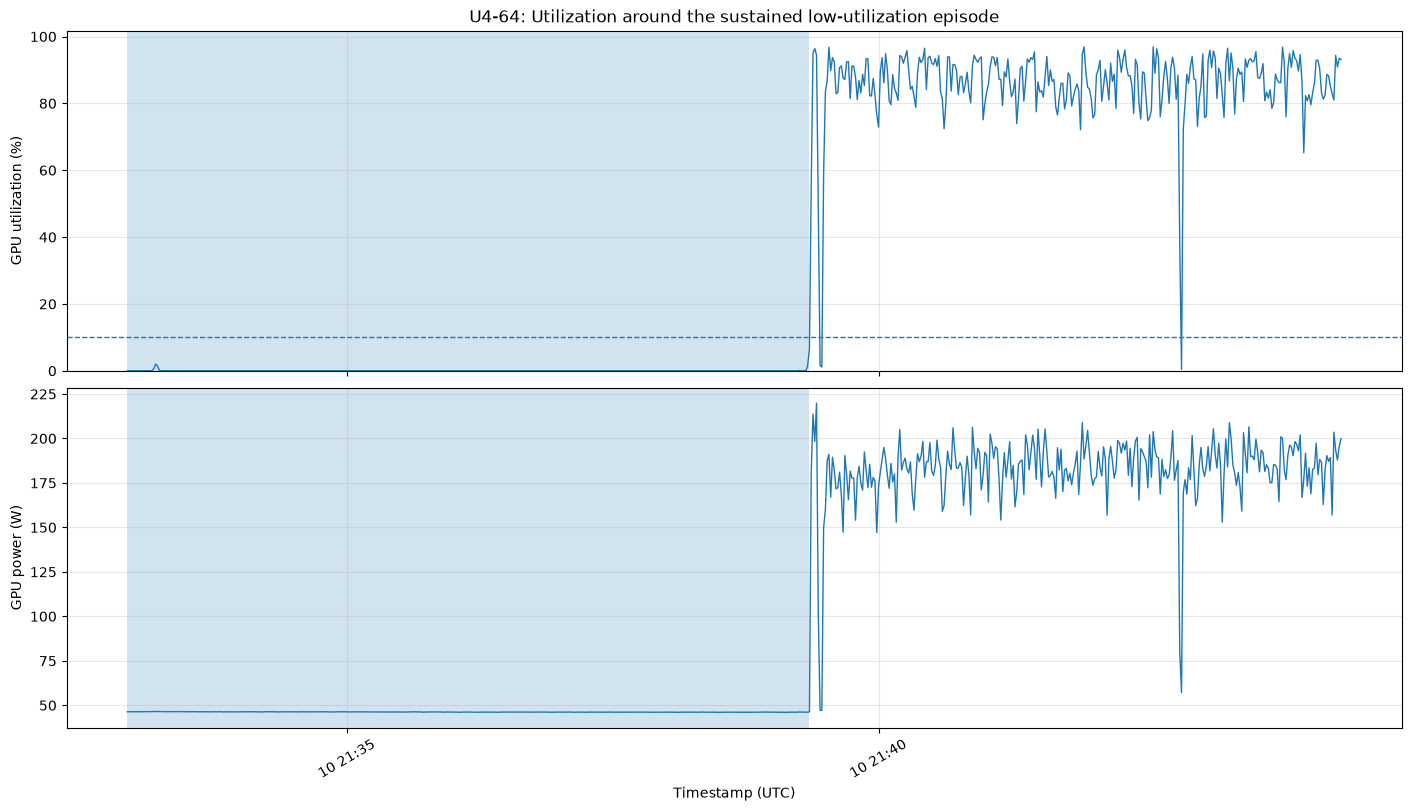


Context summary:


,phase,observations,mean_utilization_pct,median_utilization_pct,mean_power_W,median_power_W
0,After,300,85.852,87.894,182.372,184.348
1,Episode,386,0.033,0.000,46.216,46.185


In [129]:
import matplotlib.pyplot as plt
import pandas as pd

# Select the longest low-utilization episode.
longest_episode = episodes.sort_values(
    "duration_s", ascending=False
).iloc[0]

start = pd.to_datetime(longest_episode["start_time"], utc=True)
end = pd.to_datetime(longest_episode["end_time"], utc=True)

# Inspect 5 minutes before and after the episode.
window_start = start - pd.Timedelta(minutes=5)
window_end = end + pd.Timedelta(minutes=5)

plot_df = episode_df.loc[
    episode_df["timestamp_1s"].between(window_start, window_end)
].sort_values("timestamp_1s").copy()

print(f"Episode start: {start}")
print(f"Episode end:   {end}")
print(f"Episode duration: {longest_episode['duration_s']} seconds")
print(f"Context window: {window_start} to {window_end}")
print(f"Rows in context: {len(plot_df):,}")

fig, axes = plt.subplots(
    2, 1, figsize=(14, 8), sharex=True,
    constrained_layout=True
)

axes[0].plot(
    plot_df["timestamp_1s"],
    plot_df["utilization_gpu_pct"],
    linewidth=1
)
axes[0].axvspan(start, end, alpha=0.2)
axes[0].axhline(10, linestyle="--", linewidth=1)
axes[0].set_ylabel("GPU utilization (%)")
axes[0].set_title("U4-64: Utilization around the sustained low-utilization episode")
axes[0].set_ylim(bottom=0)
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    plot_df["timestamp_1s"],
    plot_df["power_draw_W"],
    linewidth=1,
    label="Power (W)"
)
axes[1].axvspan(start, end, alpha=0.2)
axes[1].set_ylabel("GPU power (W)")
axes[1].set_xlabel("Timestamp (UTC)")
axes[1].grid(True, alpha=0.3)

plt.xticks(rotation=30)
plt.show()

print("\nContext summary:")
display(
    plot_df.assign(
        phase=plot_df["timestamp_1s"].apply(
            lambda t: (
                "Episode"
                if start <= t <= end
                else "Before" if t < start else "After"
            )
        )
    )
    .groupby("phase", as_index=False)
    .agg(
        observations=("timestamp_1s", "size"),
        mean_utilization_pct=("utilization_gpu_pct", "mean"),
        median_utilization_pct=("utilization_gpu_pct", "median"),
        mean_power_W=("power_draw_W", "mean"),
        median_power_W=("power_draw_W", "median"),
    )
    .round(3)
)

In [130]:
# Analyze the transition using the existing plot_df and episode boundaries.
transition_start = start
transition_end = end

before = plot_df.loc[
    plot_df["timestamp_1s"] < transition_start
]
episode = plot_df.loc[
    plot_df["timestamp_1s"].between(
        transition_start, transition_end
    )
]
after = plot_df.loc[
    plot_df["timestamp_1s"] > transition_end
]

def summarize_phase(name, phase_df):
    return {
        "phase": name,
        "observations": len(phase_df),
        "mean_utilization_pct": phase_df["utilization_gpu_pct"].mean(),
        "median_utilization_pct": phase_df["utilization_gpu_pct"].median(),
        "mean_power_W": phase_df["power_draw_W"].mean(),
        "median_power_W": phase_df["power_draw_W"].median(),
    }

phase_summary = pd.DataFrame([
    summarize_phase("Before", before),
    summarize_phase("Low-utilization episode", episode),
    summarize_phase("After", after),
])

display(phase_summary.round(3))

# Inspect the first 15 readings after the episode.
print("\nFirst 15 readings after the episode:")
display(
    after.sort_values("timestamp_1s")[
        [
            "timestamp_1s",
            "utilization_gpu_pct",
            "power_draw_W",
            "temperature_gpu_avg",
        ]
    ].head(15).round(3)
)

# Estimate the observed energy consumed during the low-utilization episode.
episode_energy_Wh = episode["power_draw_W"].sum() / 3600

print(f"\nObserved episode energy: {episode_energy_Wh:.3f} Wh")
print("This is observed GPU energy, not estimated recoverable energy.")

,phase,observations,mean_utilization_pct,median_utilization_pct,mean_power_W,median_power_W
0,Before,0,NaN,NaN,NaN,NaN
1,Low-utilization episode,386,0.033,0.000,46.216,46.185
2,After,300,85.852,87.894,182.372,184.348



First 15 readings after the episode:


/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/3701119073.py:45: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(15).round(3)


,timestamp_1s,utilization_gpu_pct,power_draw_W,temperature_gpu_avg
312938,2021-05-10 21:39:22+00:00,55.111,180.343,43.444
312939,2021-05-10 21:39:23+00:00,94.900,213.722,47.200
312940,2021-05-10 21:39:24+00:00,96.400,198.316,48.100
312941,2021-05-10 21:39:25+00:00,94.444,219.824,49.556
312942,2021-05-10 21:39:26+00:00,46.700,101.391,46.600
312943,2021-05-10 21:39:27+00:00,1.600,47.179,42.800
312944,2021-05-10 21:39:28+00:00,1.111,47.006,42.000
312945,2021-05-10 21:39:29+00:00,59.000,149.736,44.600
312946,2021-05-10 21:39:30+00:00,83.556,159.984,46.889
312947,2021-05-10 21:39:31+00:00,86.600,187.372,48.300



Observed episode energy: 4.955 Wh
This is observed GPU energy, not estimated recoverable energy.


In [131]:
import pandas as pd

target_job = "48020198141948"
target_node = "r9352821-n830961"
target_gpu = 0

start = pd.Timestamp("2021-05-10 21:32:56", tz="UTC")
end = pd.Timestamp("2021-05-10 21:39:21", tz="UTC")

full_job = pilot_gpu_1s_v2.loc[
    (pilot_gpu_1s_v2["job_id"].astype(str) == target_job)
    & (pilot_gpu_1s_v2["rack_node_id"] == target_node)
    & (pilot_gpu_1s_v2["gpu_index"] == target_gpu)
].copy()

full_job["timestamp_1s"] = pd.to_datetime(
    full_job["timestamp_1s"], utc=True, errors="coerce"
)

full_job["utilization_gpu_pct"] = pd.to_numeric(
    full_job["utilization_gpu_pct"], errors="coerce"
)
full_job["power_draw_W"] = pd.to_numeric(
    full_job["power_draw_W"], errors="coerce"
)

window_start = start - pd.Timedelta(minutes=5)
window_end = end + pd.Timedelta(minutes=5)

context = full_job.loc[
    full_job["timestamp_1s"].between(window_start, window_end)
].copy()

context["phase"] = "Before"
context.loc[
    context["timestamp_1s"].between(start, end), "phase"
] = "Episode"
context.loc[
    context["timestamp_1s"] > end, "phase"
] = "After"

print("Rows before episode:", (context["phase"] == "Before").sum())
print("Rows during episode:", (context["phase"] == "Episode").sum())
print("Rows after episode:", (context["phase"] == "After").sum())

display(
    context.groupby("phase", as_index=False)
    .agg(
        observations=("timestamp_1s", "size"),
        mean_utilization_pct=("utilization_gpu_pct", "mean"),
        median_utilization_pct=("utilization_gpu_pct", "median"),
        mean_power_W=("power_draw_W", "mean"),
        median_power_W=("power_draw_W", "median"),
    )
    .round(3)
)

Rows before episode: 0
Rows during episode: 386
Rows after episode: 300


,phase,observations,mean_utilization_pct,median_utilization_pct,mean_power_W,median_power_W
0,After,300,85.852,87.894,182.372,184.348
1,Episode,386,0.033,0.000,46.216,46.185


In [132]:
print("Full job telemetry range:")
print("First timestamp:", full_job["timestamp_1s"].min())
print("Last timestamp: ", full_job["timestamp_1s"].max())
print("Total rows:", len(full_job))

print("\nFirst 10 observations:")
display(
    full_job.sort_values("timestamp_1s")[
        ["timestamp_1s", "utilization_gpu_pct", "power_draw_W"]
    ].head(10)
)

Full job telemetry range:
First timestamp: 2021-05-10 21:32:56+00:00
Last timestamp:  2021-05-10 22:14:17+00:00
Total rows: 2482

First 10 observations:


,timestamp_1s,utilization_gpu_pct,power_draw_W
312552,2021-05-10 21:32:56+00:00,0.0,46.330000
312553,2021-05-10 21:32:57+00:00,0.0,46.373000
312554,2021-05-10 21:32:58+00:00,0.0,46.414444
312555,2021-05-10 21:32:59+00:00,0.0,46.410000
312556,2021-05-10 21:33:00+00:00,0.0,46.352222
312557,2021-05-10 21:33:01+00:00,0.0,46.401000
312558,2021-05-10 21:33:02+00:00,0.0,46.441000
312559,2021-05-10 21:33:03+00:00,0.0,46.346667
312560,2021-05-10 21:33:04+00:00,0.0,46.384000
312561,2021-05-10 21:33:05+00:00,0.0,46.364000


In [133]:
import pandas as pd
from pathlib import Path

# Start from the validated, one-second telemetry dataset.
analysis = pilot_gpu_1s_v2.copy()

analysis["job_id"] = analysis["job_id"].astype(str)
analysis["timestamp_1s"] = pd.to_datetime(
    analysis["timestamp_1s"], utc=True, errors="coerce"
)
analysis["utilization_gpu_pct"] = pd.to_numeric(
    analysis["utilization_gpu_pct"], errors="coerce"
)
analysis["power_draw_W"] = pd.to_numeric(
    analysis["power_draw_W"], errors="coerce"
)

required = [
    "job_id", "rack_node_id", "gpu_index",
    "timestamp_1s", "utilization_gpu_pct", "power_draw_W",
]
analysis = analysis.dropna(subset=required).copy()

stream_cols = ["job_id", "rack_node_id", "gpu_index"]

analysis = analysis.sort_values(
    stream_cols + ["timestamp_1s"]
).reset_index(drop=True)

# Low utilization threshold.
analysis["is_low_util"] = analysis["utilization_gpu_pct"] < 10

# Compare each observation with the previous observation
# from the same physical GPU stream.
grouped = analysis.groupby(stream_cols, sort=False)

analysis["previous_timestamp"] = grouped["timestamp_1s"].shift(1)
analysis["previous_is_low"] = grouped["is_low_util"].shift(1)

analysis["gap_seconds"] = (
    analysis["timestamp_1s"] - analysis["previous_timestamp"]
).dt.total_seconds()

# Start a new episode when:
# 1. Low utilization begins, or
# 2. A gap interrupts an otherwise low-utilization sequence.
analysis["episode_start"] = (
    analysis["is_low_util"]
    & (
        ~analysis["previous_is_low"].fillna(False).astype(bool)
        | analysis["gap_seconds"].ne(1)
    )
)

analysis["episode_id"] = (
    analysis.groupby(stream_cols, sort=False)["episode_start"]
    .cumsum()
)

low_rows = analysis.loc[analysis["is_low_util"]].copy()

# Summarize each consecutive episode.
episode_results = (
    low_rows.groupby(
        stream_cols
        + ["model", "workload_family", "episode_id"],
        as_index=False,
        dropna=False,
    )
    .agg(
        start_time=("timestamp_1s", "min"),
        end_time=("timestamp_1s", "max"),
        observations=("timestamp_1s", "size"),
        mean_utilization_pct=("utilization_gpu_pct", "mean"),
        mean_power_W=("power_draw_W", "mean"),
        median_power_W=("power_draw_W", "median"),
        max_power_W=("power_draw_W", "max"),
    )
)

# One-second sampling: use observation count as the episode duration.
episode_results["duration_s"] = episode_results["observations"]
episode_results["duration_min"] = (
    episode_results["duration_s"] / 60
)

# Focus on episodes lasting at least 30 seconds.
sustained_episodes = (
    episode_results.loc[episode_results["duration_s"] >= 30]
    .sort_values(
        ["duration_s", "mean_power_W"],
        ascending=[False, False],
    )
    .reset_index(drop=True)
)

print("=== Cross-job episode analysis ===")
print(f"Valid telemetry observations: {len(analysis):,}")
print(f"Jobs analyzed: {analysis['job_id'].nunique()}")
print(f"Physical GPU streams: {analysis[stream_cols].drop_duplicates().shape[0]}")
print(f"All low-utilization episodes: {len(episode_results):,}")
print(f"Episodes lasting at least 30 seconds: {len(sustained_episodes):,}")
print(f"Jobs with sustained episodes: {sustained_episodes['job_id'].nunique()}")

print("\n=== Longest sustained episodes ===")
display(sustained_episodes.head(20).round(3))

# Save reproducible outputs.
output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

all_episodes_path = output_dir / "mit_supercloud_low_util_episodes_all_v1.csv"
sustained_path = output_dir / "mit_supercloud_sustained_low_util_episodes_v1.csv"

episode_results.to_csv(all_episodes_path, index=False)
sustained_episodes.to_csv(sustained_path, index=False)

print(f"\nSaved all episodes: {all_episodes_path}")
print(f"Saved sustained episodes: {sustained_path}")

=== Cross-job episode analysis ===
Valid telemetry observations: 828,531
Jobs analyzed: 26
Physical GPU streams: 64
All low-utilization episodes: 2,186
Episodes lasting at least 30 seconds: 62
Jobs with sustained episodes: 24

=== Longest sustained episodes ===


/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/1786137221.py:106: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(sustained_episodes.head(20).round(3))


,job_id,rack_node_id,gpu_index,model,workload_family,episode_id,start_time,end_time,observations,mean_utilization_pct,mean_power_W,median_power_W,max_power_W,duration_s,duration_min
0,48020198141948,r9352821-n830961,0,U4-64,Vision,1,2021-05-10 21:32:56+00:00,2021-05-10 21:39:21+00:00,386,0.033,46.216,46.185,46.557,386,6.433
1,59638293409445,r9352821-n830961,0,U4-128,Vision,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:49+00:00,296,0.035,49.274,48.571,60.322,296,4.933
2,59638293409445,r3117156-n136082,0,U4-128,Vision,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,0.044,47.046,46.301,53.430,294,4.900
3,59638293409445,r3117156-n136082,1,U4-128,Vision,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,0.042,40.358,40.030,52.610,294,4.900
4,59638293409445,r9352821-n830961,1,U4-128,Vision,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:29+00:00,276,0.067,40.241,39.801,76.411,276,4.600
5,29381280178268,r1682297-n976057,0,U3-32,Vision,1,2021-05-09 07:03:54+00:00,2021-05-09 07:08:18+00:00,265,0.054,39.417,39.141,42.604,265,4.417
6,59030654331752,r8579942-n208530,0,U5-128,Vision,1,2021-05-12 22:43:41+00:00,2021-05-12 22:48:03+00:00,263,0.037,41.489,41.187,49.623,263,4.383
7,25713459161743,r9352821-n830961,1,U3-128,Vision,1,2021-05-28 16:01:39+00:00,2021-05-28 16:05:44+00:00,246,0.050,39.352,38.964,47.816,246,4.100
8,29381280178268,r1682297-n976057,1,U3-32,Vision,1,2021-05-09 07:03:54+00:00,2021-05-09 07:07:57+00:00,244,0.056,45.935,45.547,48.836,244,4.067
9,25713459161743,r9352821-n830961,0,U3-128,Vision,1,2021-05-28 16:01:39+00:00,2021-05-28 16:05:41+00:00,243,0.036,40.356,40.516,42.113,243,4.050



Saved all episodes: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_low_util_episodes_all_v1.csv
Saved sustained episodes: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_sustained_low_util_episodes_v1.csv


In [134]:
import numpy as np
import pandas as pd

# Reuse the validated telemetry table prepared above.
sync_df = analysis.copy()

# Count observed GPU streams per job.
streams_per_job = (
    sync_df[["job_id", "rack_node_id", "gpu_index"]]
    .drop_duplicates()
    .groupby("job_id")
    .size()
    .rename("observed_gpu_streams")
    .reset_index()
)

# At each second, count how many GPUs in a job have utilization < 10%.
per_job_second = (
    sync_df.assign(is_low=sync_df["utilization_gpu_pct"] < 10)
    .groupby(["job_id", "timestamp_1s"], as_index=False)
    .agg(
        low_util_gpus=("is_low", "sum"),
        observed_gpus=("gpu_index", "size"),
        mean_utilization_pct=("utilization_gpu_pct", "mean"),
        mean_power_W=("power_draw_W", "mean"),
    )
    .merge(streams_per_job, on="job_id", how="left")
    .sort_values(["job_id", "timestamp_1s"])
)

# Require at least two GPUs and at least half of the observed
# GPU streams to be low-utilization at the same second.
per_job_second["required_low_gpus"] = np.maximum(
    2,
    np.ceil(per_job_second["observed_gpu_streams"] * 0.5),
).astype(int)

per_job_second["synchronized_low"] = (
    (per_job_second["observed_gpus"] == per_job_second["observed_gpu_streams"])
    & (per_job_second["low_util_gpus"] >= per_job_second["required_low_gpus"])
)

# Find consecutive synchronized-low seconds within each job.
g = per_job_second.groupby("job_id", sort=False)
per_job_second["previous_timestamp"] = g["timestamp_1s"].shift()
per_job_second["previous_sync_low"] = g["synchronized_low"].shift()

per_job_second["new_sync_episode"] = (
    per_job_second["synchronized_low"]
    & (
        ~per_job_second["previous_sync_low"].fillna(False).astype(bool)
        | (
            per_job_second["timestamp_1s"] - per_job_second["previous_timestamp"]
        ).dt.total_seconds().ne(1)
    )
)

per_job_second["sync_episode_id"] = (
    per_job_second.groupby("job_id", sort=False)["new_sync_episode"].cumsum()
)

sync_episodes = (
    per_job_second.loc[per_job_second["synchronized_low"]]
    .groupby(["job_id", "sync_episode_id"], as_index=False)
    .agg(
        start_time=("timestamp_1s", "min"),
        end_time=("timestamp_1s", "max"),
        duration_s=("timestamp_1s", "size"),
        mean_low_util_gpus=("low_util_gpus", "mean"),
        max_low_util_gpus=("low_util_gpus", "max"),
        mean_job_gpu_utilization_pct=("mean_utilization_pct", "mean"),
        mean_power_per_observed_gpu_W=("mean_power_W", "mean"),
        observed_gpu_streams=("observed_gpu_streams", "first"),
    )
)

sync_episodes = sync_episodes.loc[
    sync_episodes["duration_s"] >= 30
].sort_values("duration_s", ascending=False)

print("Synchronized low-utilization episodes lasting >=30 seconds:",
      len(sync_episodes))
print("Jobs affected:", sync_episodes["job_id"].nunique())

display(sync_episodes.head(20).round(3))

sync_path = (
    project_root / "data" / "processed"
    / "mit_supercloud_synchronized_low_util_episodes_v1.csv"
)
sync_episodes.to_csv(sync_path, index=False)
print(f"Saved: {sync_path}")

Synchronized low-utilization episodes lasting >=30 seconds: 18
Jobs affected: 17


/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/3749992436.py:85: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(sync_episodes.head(20).round(3))


,job_id,sync_episode_id,start_time,end_time,duration_s,mean_low_util_gpus,max_low_util_gpus,mean_job_gpu_utilization_pct,mean_power_per_observed_gpu_W,observed_gpu_streams
478,59638293409445,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:49+00:00,296,3.963,4,0.928,45.817,4
45,25713459161743,1,2021-05-28 16:01:39+00:00,2021-05-28 16:05:47+00:00,249,3.936,4,1.509,41.095,4
54,29381280178268,1,2021-05-09 07:03:54+00:00,2021-05-09 07:07:57+00:00,244,2.000,2,0.036,42.726,2
491,68307271431118,1,2021-05-14 09:07:41+00:00,2021-05-14 09:11:33+00:00,233,2.000,2,0.053,45.373,2
496,74636684972411,1,2021-05-16 10:01:25+00:00,2021-05-16 10:04:59+00:00,215,2.000,2,0.028,44.048,2
501,79150048009801,1,2021-05-30 15:39:27+00:00,2021-05-30 15:42:57+00:00,211,2.000,2,0.035,40.475,2
18,18203079158032,2,2021-08-17 11:27:47+00:00,2021-08-17 11:31:09+00:00,203,2.000,2,0.013,37.440,2
74,48510612336879,5,2021-06-12 15:12:20+00:00,2021-06-12 15:14:22+00:00,123,2.000,2,0.007,41.603,2
11,15179646833041,1,2021-08-12 08:21:46+00:00,2021-08-12 08:23:11+00:00,86,2.000,2,0.312,44.597,2
59,36230628475012,1,2021-08-17 17:08:58+00:00,2021-08-17 17:10:15+00:00,78,2.000,2,0.153,28.785,2


Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_synchronized_low_util_episodes_v1.csv


In [135]:
# Aggregate synchronized episodes into job-level metrics.
sync_by_job = (
    sync_episodes.groupby("job_id", as_index=False)
    .agg(
        synchronized_episodes=("duration_s", "size"),
        total_synchronized_seconds=("duration_s", "sum"),
        longest_synchronized_episode_s=("duration_s", "max"),
        mean_synchronized_utilization_pct=(
            "mean_job_gpu_utilization_pct", "mean"
        ),
        mean_power_per_observed_gpu_W=(
            "mean_power_per_observed_gpu_W", "mean"
        ),
        observed_gpu_streams=("observed_gpu_streams", "max"),
    )
)

# Add model and workload family from the validated telemetry.
job_metadata = (
    analysis.groupby("job_id", as_index=False)
    .agg(
        model=("model", "first"),
        workload_family=("workload_family", "first"),
    )
)

sync_by_job = sync_by_job.merge(
    job_metadata, on="job_id", how="left"
)

# Flag the known incomplete job.
sync_by_job["telemetry_complete_for_allocation"] = (
    sync_by_job["job_id"] != "29381280178268"
)

sync_by_job = sync_by_job.sort_values(
    ["total_synchronized_seconds", "longest_synchronized_episode_s"],
    ascending=False,
)

display(sync_by_job.round(3))

output_path = (
    project_root / "data" / "processed"
    / "mit_supercloud_synchronized_low_util_by_job_v1.csv"
)
sync_by_job.to_csv(output_path, index=False)

print(f"Saved: {output_path}")

,job_id,synchronized_episodes,total_synchronized_seconds,longest_synchronized_episode_s,mean_synchronized_utilization_pct,mean_power_per_observed_gpu_W,observed_gpu_streams,model,workload_family,telemetry_complete_for_allocation
11,59638293409445,1,296,296,0.928,45.817,4,U4-128,Vision,True
2,18203079158032,2,259,203,0.170,34.101,2,schnet,GNN,True
4,25713459161743,1,249,249,1.509,41.095,4,U3-128,Vision,True
5,29381280178268,1,244,244,0.036,42.726,2,U3-32,Vision,False
12,68307271431118,1,233,233,0.053,45.373,2,U4-32,Vision,True
13,74636684972411,1,215,215,0.028,44.048,2,U3-64,Vision,True
14,79150048009801,1,211,211,0.035,40.475,2,U5-64,Vision,True
9,48510612336879,1,123,123,0.007,41.603,2,vgg19,Vision,True
1,15179646833041,1,86,86,0.312,44.597,2,conv,GNN,True
6,36230628475012,1,78,78,0.153,28.785,2,pna,GNN,True


Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_synchronized_low_util_by_job_v1.csv


In [136]:
import pandas as pd

target_job = "59638293409445"

# Get the longest synchronized episode for this job.
target_episode = (
    sync_episodes.loc[sync_episodes["job_id"].astype(str) == target_job]
    .sort_values("duration_s", ascending=False)
    .iloc[0]
)

episode_start = pd.to_datetime(target_episode["start_time"], utc=True)
episode_end = pd.to_datetime(target_episode["end_time"], utc=True)

print("Model: U4-128")
print(f"Episode start: {episode_start}")
print(f"Episode end:   {episode_end}")
print(f"Duration:      {target_episode['duration_s']} seconds")

# Select all observed GPU streams for the job.
u4 = analysis.loc[
    analysis["job_id"].astype(str) == target_job
].copy()

u4["phase"] = "Before"
u4.loc[
    u4["timestamp_1s"].between(episode_start, episode_end),
    "phase"
] = "Synchronized low utilization"
u4.loc[u4["timestamp_1s"] > episode_end, "phase"] = "After"

# Per-GPU coverage and utilization/power by phase.
gpu_phase = (
    u4.groupby(
        ["rack_node_id", "gpu_index", "phase"],
        as_index=False
    )
    .agg(
        observations=("timestamp_1s", "size"),
        mean_utilization_pct=("utilization_gpu_pct", "mean"),
        median_utilization_pct=("utilization_gpu_pct", "median"),
        mean_power_W=("power_draw_W", "mean"),
        median_power_W=("power_draw_W", "median"),
        first_timestamp=("timestamp_1s", "min"),
        last_timestamp=("timestamp_1s", "max"),
    )
)

print("\n=== Per-GPU phase summary ===")
display(gpu_phase.round(3))

print("\n=== First 15 observations after the episode, by GPU ===")
after_rows = u4.loc[
    u4["timestamp_1s"] > episode_end
].sort_values(["rack_node_id", "gpu_index", "timestamp_1s"])

display(
    after_rows.groupby(["rack_node_id", "gpu_index"], group_keys=False)
    .head(15)[
        [
            "rack_node_id",
            "gpu_index",
            "timestamp_1s",
            "utilization_gpu_pct",
            "power_draw_W",
        ]
    ].round(3)
)

Model: U4-128
Episode start: 2021-05-11 13:51:54+00:00
Episode end:   2021-05-11 13:56:49+00:00
Duration:      296 seconds

=== Per-GPU phase summary ===


/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/3071961400.py:50: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(gpu_phase.round(3))


,rack_node_id,gpu_index,phase,observations,mean_utilization_pct,median_utilization_pct,mean_power_W,median_power_W,first_timestamp,last_timestamp
0,r3117156-n136082,0,After,6370,96.963,98.000,200.212,200.035,2021-05-11 13:56:50+00:00,2021-05-11 15:42:59+00:00
1,r3117156-n136082,0,Synchronized low utilization,296,0.661,0.000,48.252,46.322,2021-05-11 13:51:54+00:00,2021-05-11 13:56:49+00:00
2,r3117156-n136082,1,After,6370,96.303,97.444,205.001,204.594,2021-05-11 13:56:50+00:00,2021-05-11 15:42:59+00:00
3,r3117156-n136082,1,Synchronized low utilization,296,0.670,0.000,41.612,40.058,2021-05-11 13:51:54+00:00,2021-05-11 13:56:49+00:00
4,r9352821-n830961,0,After,6370,97.053,98.000,203.926,203.451,2021-05-11 13:56:50+00:00,2021-05-11 15:42:59+00:00
5,r9352821-n830961,0,Synchronized low utilization,296,0.035,0.000,49.274,48.571,2021-05-11 13:51:54+00:00,2021-05-11 13:56:49+00:00
6,r9352821-n830961,1,After,6370,96.854,98.000,195.223,195.859,2021-05-11 13:56:50+00:00,2021-05-11 15:42:59+00:00
7,r9352821-n830961,1,Synchronized low utilization,296,2.344,0.000,44.131,39.920,2021-05-11 13:51:54+00:00,2021-05-11 13:56:49+00:00



=== First 15 observations after the episode, by GPU ===


/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/3071961400.py:67: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(3)


,rack_node_id,gpu_index,timestamp_1s,utilization_gpu_pct,power_draw_W
407998,r3117156-n136082,0,2021-05-11 13:56:50+00:00,99.111,215.351
407999,r3117156-n136082,0,2021-05-11 13:56:51+00:00,99.556,222.211
408000,r3117156-n136082,0,2021-05-11 13:56:52+00:00,99.300,222.256
408001,r3117156-n136082,0,2021-05-11 13:56:53+00:00,99.111,216.474
408002,r3117156-n136082,0,2021-05-11 13:56:54+00:00,99.000,203.379
408003,r3117156-n136082,0,2021-05-11 13:56:55+00:00,26.500,47.880
408004,r3117156-n136082,0,2021-05-11 13:56:56+00:00,29.333,47.799
408005,r3117156-n136082,0,2021-05-11 13:56:57+00:00,13.444,46.598
408006,r3117156-n136082,0,2021-05-11 13:56:58+00:00,4.100,46.309
408007,r3117156-n136082,0,2021-05-11 13:56:59+00:00,11.444,46.366


In [137]:
# Analyze the post-episode transition for each observed GPU

post = u4.loc[
    u4["timestamp_1s"] > episode_end
].copy()

post = post.sort_values(
    ["rack_node_id", "gpu_index", "timestamp_1s"]
)

post["is_high_util"] = (
    post["utilization_gpu_pct"] >= 75
)

# A new run starts when high utilization begins,
# or when the timestamp sequence has a gap.
group_cols = ["rack_node_id", "gpu_index"]

post["previous_timestamp"] = (
    post.groupby(group_cols)["timestamp_1s"].shift(1)
)

post["new_segment"] = (
    post["previous_timestamp"].isna()
    | (
        post["timestamp_1s"] - post["previous_timestamp"]
        != pd.Timedelta(seconds=1)
    )
)

post["segment_id"] = (
    post.groupby(group_cols)["new_segment"].cumsum()
)

# Summarize consecutive high-utilization runs
high_runs = (
    post.loc[post["is_high_util"]]
    .groupby(group_cols + ["segment_id"], as_index=False)
    .agg(
        start_time=("timestamp_1s", "min"),
        end_time=("timestamp_1s", "max"),
        observations=("timestamp_1s", "size"),
        mean_utilization_pct=("utilization_gpu_pct", "mean"),
        mean_power_W=("power_draw_W", "mean"),
    )
)

# Require 10 consecutive observations (10 one-second samples)
sustained_high = (
    high_runs.loc[high_runs["observations"] >= 10]
    .sort_values("start_time")
    .groupby(group_cols, as_index=False)
    .first()
)

sustained_high["seconds_after_episode"] = (
    sustained_high["start_time"] - episode_end
).dt.total_seconds()

display(
    sustained_high[
        [
            "rack_node_id",
            "gpu_index",
            "start_time",
            "seconds_after_episode",
            "observations",
            "mean_utilization_pct",
            "mean_power_W",
        ]
    ].round(3)
)

/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/4259212206.py:71: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(3)


,rack_node_id,gpu_index,start_time,seconds_after_episode,observations,mean_utilization_pct,mean_power_W
0,r3117156-n136082,0,2021-05-11 13:56:50+00:00,1.0,6320,97.590,201.311
1,r3117156-n136082,1,2021-05-11 13:56:50+00:00,1.0,6312,97.043,206.264
2,r9352821-n830961,0,2021-05-11 13:56:50+00:00,1.0,6324,97.625,204.934
3,r9352821-n830961,1,2021-05-11 13:57:02+00:00,13.0,6312,97.592,196.481


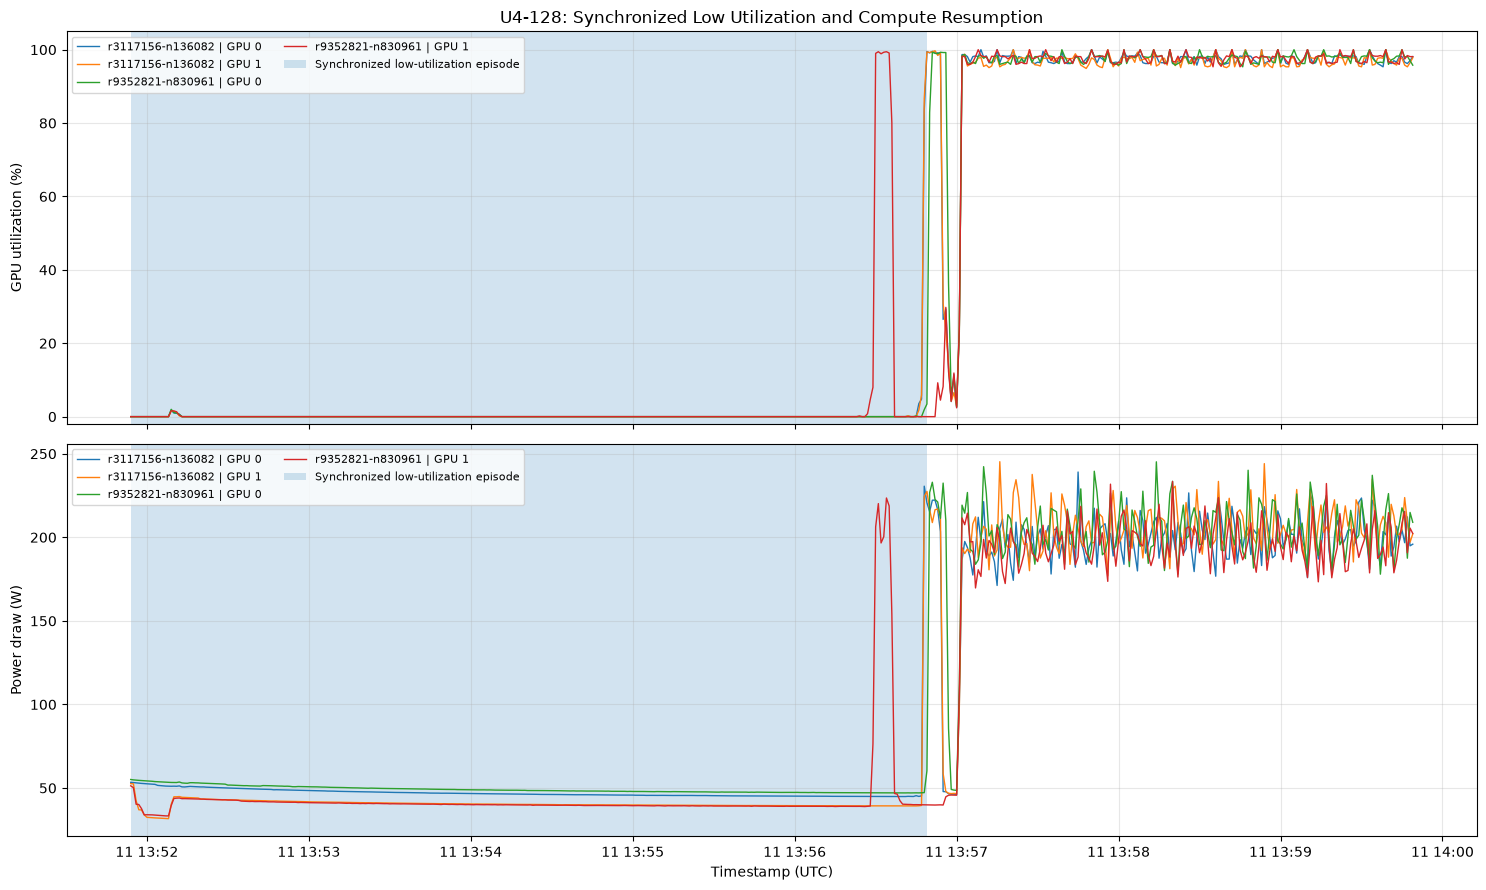

In [138]:
import matplotlib.pyplot as plt

# Inspect 2 minutes before and 3 minutes after the episode
window_start = episode_start - pd.Timedelta(seconds=120)
window_end = episode_end + pd.Timedelta(seconds=180)

plot_df = u4.loc[
    u4["timestamp_1s"].between(window_start, window_end)
].copy()

plot_df["gpu_label"] = (
    plot_df["rack_node_id"]
    + " | GPU "
    + plot_df["gpu_index"].astype(str)
)

fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

for label, gpu_df in plot_df.groupby("gpu_label"):
    gpu_df = gpu_df.sort_values("timestamp_1s")
    axes[0].plot(
        gpu_df["timestamp_1s"],
        gpu_df["utilization_gpu_pct"],
        label=label,
        linewidth=1,
    )
    axes[1].plot(
        gpu_df["timestamp_1s"],
        gpu_df["power_draw_W"],
        label=label,
        linewidth=1,
    )

for ax in axes:
    ax.axvspan(
        episode_start,
        episode_end,
        alpha=0.2,
        label="Synchronized low-utilization episode",
    )
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("GPU utilization (%)")
axes[0].set_title("U4-128: Synchronized Low Utilization and Compute Resumption")
axes[0].set_ylim(-2, 105)
axes[0].legend(loc="upper left", fontsize=8, ncol=2)

axes[1].set_ylabel("Power draw (W)")
axes[1].set_xlabel("Timestamp (UTC)")
axes[1].legend(loc="upper left", fontsize=8, ncol=2)

plt.tight_layout()
plt.show()

In [139]:
# Inspect the transition window at one-second resolution

transition_start = episode_end - pd.Timedelta(seconds=30)
transition_end = episode_end + pd.Timedelta(seconds=30)

transition = u4.loc[
    u4["timestamp_1s"].between(
        transition_start, transition_end
    )
].copy()

transition["seconds_from_episode_end"] = (
    transition["timestamp_1s"] - episode_end
).dt.total_seconds()

display(
    transition[
        [
            "timestamp_1s",
            "rack_node_id",
            "gpu_index",
            "seconds_from_episode_end",
            "utilization_gpu_pct",
            "power_draw_W",
        ]
    ]
    .sort_values(["timestamp_1s", "rack_node_id", "gpu_index"])
    .round(3)
    .reset_index(drop=True)
)

/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/2017549987.py:28: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


,timestamp_1s,rack_node_id,gpu_index,seconds_from_episode_end,utilization_gpu_pct,power_draw_W
0,2021-05-11 13:56:19+00:00,r3117156-n136082,0,-30.0,0.000,45.002
1,2021-05-11 13:56:19+00:00,r3117156-n136082,1,-30.0,0.000,39.344
2,2021-05-11 13:56:19+00:00,r9352821-n830961,0,-30.0,0.000,47.243
3,2021-05-11 13:56:19+00:00,r9352821-n830961,1,-30.0,0.000,39.057
4,2021-05-11 13:56:20+00:00,r3117156-n136082,0,-29.0,0.000,45.008
...,...,...,...,...,...,...
239,2021-05-11 13:57:18+00:00,r9352821-n830961,1,29.0,98.111,172.359
240,2021-05-11 13:57:19+00:00,r3117156-n136082,0,30.0,98.222,201.740
241,2021-05-11 13:57:19+00:00,r3117156-n136082,1,30.0,96.889,194.058
242,2021-05-11 13:57:19+00:00,r9352821-n830961,0,30.0,96.600,213.573


In [141]:
# Summarize the four GPUs at each timestamp

transition_summary = (
    transition.groupby("timestamp_1s", as_index=False)
    .agg(
        observed_gpus=("gpu_index", "size"),
        mean_utilization_pct=("utilization_gpu_pct", "mean"),
        min_utilization_pct=("utilization_gpu_pct", "min"),
        max_utilization_pct=("utilization_gpu_pct", "max"),
        mean_power_W=("power_draw_W", "mean"),
        near_idle_gpus=(
            "utilization_gpu_pct",
            lambda s: (s <= 1).sum(),
        ),
        high_util_gpus=(
            "utilization_gpu_pct",
            lambda s: (s >= 75).sum(),
        ),
    )
)

transition_summary["seconds_from_episode_end"] = (
    transition_summary["timestamp_1s"] - episode_end
).dt.total_seconds()

# Show only timestamps where at least one GPU is highly utilized
# or where the job is transitioning out of near-idle behavior.
interesting = transition_summary.loc[
    (transition_summary["max_utilization_pct"] >= 75)
    | (transition_summary["mean_utilization_pct"] >= 10)
].copy()

display(
    interesting[
        [
            "timestamp_1s",
            "seconds_from_episode_end",
            "observed_gpus",
            "near_idle_gpus",
            "high_util_gpus",
            "mean_utilization_pct",
            "mean_power_W",
        ]
    ]
    .sort_values("timestamp_1s")
    .round(3)
    .to_string(index=False)
)

/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/325150260.py:46: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


'             timestamp_1s  seconds_from_episode_end  observed_gpus  near_idle_gpus  high_util_gpus  mean_utilization_pct  mean_power_W\n2021-05-11 13:56:30+00:00                     -19.0              4               3               1                24.750        84.407\n2021-05-11 13:56:31+00:00                     -18.0              4               3               1                24.861        87.894\n2021-05-11 13:56:32+00:00                     -17.0              4               3               1                24.722        82.019\n2021-05-11 13:56:33+00:00                     -16.0              4               3               1                24.825        82.927\n2021-05-11 13:56:34+00:00                     -15.0              4               3               1                24.861        88.714\n2021-05-11 13:56:35+00:00                     -14.0              4               3               1                24.775        87.523\n2021-05-11 13:56:36+00:00                     -

In [142]:
# Find the first 60-second interval with all four GPUs
# continuously above 75% utilization.

job_seconds = (
    u4.groupby("timestamp_1s", as_index=False)
    .agg(
        observed_gpus=("gpu_index", "size"),
        min_gpu_utilization_pct=("utilization_gpu_pct", "min"),
        mean_gpu_utilization_pct=("utilization_gpu_pct", "mean"),
        mean_gpu_power_W=("power_draw_W", "mean"),
    )
    .sort_values("timestamp_1s")
    .reset_index(drop=True)
)

job_seconds["all_four_high"] = (
    (job_seconds["observed_gpus"] == 4)
    & (job_seconds["min_gpu_utilization_pct"] >= 75)
)

# Require consecutive timestamps with no gaps.
job_seconds["one_second_gap"] = (
    job_seconds["timestamp_1s"].diff()
    == pd.Timedelta(seconds=1)
)

job_seconds["high_run_group"] = (
    (
        ~job_seconds["all_four_high"]
        | ~job_seconds["one_second_gap"]
    )
    .cumsum()
)

high_runs = (
    job_seconds.loc[job_seconds["all_four_high"]]
    .groupby("high_run_group", as_index=False)
    .agg(
        start_time=("timestamp_1s", "min"),
        end_time=("timestamp_1s", "max"),
        seconds=("timestamp_1s", "size"),
        mean_job_utilization_pct=("mean_gpu_utilization_pct", "mean"),
        minimum_gpu_utilization_pct=("min_gpu_utilization_pct", "min"),
        mean_power_per_gpu_W=("mean_gpu_power_W", "mean"),
    )
    .sort_values("start_time")
)

qualifying_runs = high_runs.loc[high_runs["seconds"] >= 60]

display(qualifying_runs.head(5).round(3))

/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/962687771.py:51: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(qualifying_runs.head(5).round(3))


,high_run_group,start_time,end_time,seconds,mean_job_utilization_pct,minimum_gpu_utilization_pct,mean_power_per_gpu_W
0,308,2021-05-11 13:57:02+00:00,2021-05-11 14:07:18+00:00,617,97.499,94.889,201.773
1,311,2021-05-11 14:07:22+00:00,2021-05-11 14:17:40+00:00,619,97.499,86.800,202.061
2,315,2021-05-11 14:17:45+00:00,2021-05-11 14:28:03+00:00,619,97.555,93.333,202.227
3,319,2021-05-11 14:28:08+00:00,2021-05-11 14:38:26+00:00,619,97.576,95.111,202.437
4,324,2021-05-11 14:38:32+00:00,2021-05-11 14:48:51+00:00,620,97.570,93.667,202.193


In [143]:
from pathlib import Path
import pandas as pd

output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Select the first validated sustained high-utilization interval
validated_run = qualifying_runs.iloc[0]

case_study = {
    "job_id": target_job,
    "model": "U4-128",
    "observed_gpu_streams": 4,
    "low_util_episode_start_utc": episode_start.isoformat(),
    "low_util_episode_end_utc": episode_end.isoformat(),
    "low_util_episode_duration_s": int(
        target_episode["duration_s"]
    ),
    "sustained_high_start_utc": (
        validated_run["start_time"].isoformat()
    ),
    "sustained_high_end_utc": (
        validated_run["end_time"].isoformat()
    ),
    "sustained_high_duration_s": int(
        validated_run["seconds"]
    ),
    "mean_gpu_utilization_pct": float(
        validated_run["mean_job_utilization_pct"]
    ),
    "minimum_gpu_utilization_pct": float(
        validated_run["minimum_gpu_utilization_pct"]
    ),
    "mean_power_per_gpu_W": float(
        validated_run["mean_power_per_gpu_W"]
    ),
    "interpretation": (
        "Synchronized low utilization followed by sustained "
        "high utilization; cause of the low-utilization phase "
        "is undetermined from telemetry alone."
    ),
}

case_df = pd.DataFrame([case_study])
case_csv = output_dir / "u4_128_transition_case_study.csv"
case_df.to_csv(case_csv, index=False)

report = f"""# U4-128 GPU Utilization Transition Case Study

## Finding

Job `{target_job}` exhibits a synchronized low-utilization
episode followed by sustained high GPU utilization.

## Validated metrics

- Model/workload label: U4-128
- Observed GPU streams: 4
- Low-utilization episode: {episode_start} to {episode_end}
- Low-utilization duration: {int(target_episode["duration_s"])} seconds
- First sustained high-utilization interval:
  {validated_run["start_time"]} to {validated_run["end_time"]}
- Sustained interval: {int(validated_run["seconds"])} one-second observations
- Mean GPU utilization: {validated_run["mean_job_utilization_pct"]:.3f}%
- Minimum GPU utilization: {validated_run["minimum_gpu_utilization_pct"]:.3f}%
- Mean power per GPU: {validated_run["mean_power_per_gpu_W"]:.3f} W

## Interpretation

The telemetry is consistent with a shared low-activity phase followed
by sustained computation. The transition includes brief fluctuations.

The underlying cause is not established. Initialization, input
preparation, synchronization, or waiting on a dependency are
hypotheses requiring additional evidence.

## Limitations

- Power and energy measurements represent GPU telemetry, not total
  data-center energy consumption.
- Low utilization alone does not establish avoidable energy waste.
- The analysis describes observed telemetry, not a causal experiment.
"""

report_path = output_dir / "u4_128_transition_case_study.md"
report_path.write_text(report, encoding="utf-8")

print(f"Saved CSV: {case_csv}")
print(f"Saved report: {report_path}")
display(case_df.round(3))

Saved CSV: outputs/u4_128_transition_case_study.csv
Saved report: outputs/u4_128_transition_case_study.md


,job_id,model,observed_gpu_streams,low_util_episode_start_utc,low_util_episode_end_utc,low_util_episode_duration_s,sustained_high_start_utc,sustained_high_end_utc,sustained_high_duration_s,mean_gpu_utilization_pct,minimum_gpu_utilization_pct,mean_power_per_gpu_W,interpretation
0,59638293409445,U4-128,4,2021-05-11T13:51:54+00:00,2021-05-11T13:56:49+00:00,296,2021-05-11T13:57:02+00:00,2021-05-11T14:07:18+00:00,617,97.499,94.889,201.773,Synchronized low utilization followed by susta...


In [145]:
from pathlib import Path
import pandas as pd

artifact_paths = [
    "data/processed/mit_supercloud_sustained_low_util_episodes_v1.csv",
    "data/processed/mit_supercloud_synchronized_low_util_by_job_v1.csv",
    "data/processed/mit_supercloud_job_investigation_candidates_v1.csv",
    "data/processed/mit_supercloud_job_energy_pilot_v1.csv",
    "outputs/u4_128_transition_case_study.csv",
]

artifact_check = []

for path in artifact_paths:
    p = Path(path)
    artifact_check.append({
        "artifact": path,
        "exists": p.exists(),
        "size_kb": round(p.stat().st_size / 1024, 2) if p.exists() else None,
    })

display(pd.DataFrame(artifact_check))

,artifact,exists,size_kb
0,data/processed/mit_supercloud_sustained_low_ut...,False,NaN
1,data/processed/mit_supercloud_synchronized_low...,False,NaN
2,data/processed/mit_supercloud_job_investigatio...,False,NaN
3,data/processed/mit_supercloud_job_energy_pilot...,False,NaN
4,outputs/u4_128_transition_case_study.csv,True,0.6


In [146]:
from pathlib import Path

project_root = Path.cwd()

print("Notebook working directory:", project_root)

for folder in ["data", "outputs"]:
    root = project_root / folder
    print(f"\n=== {root} ===")

    if root.exists():
        for p in sorted(root.rglob("*")):
            if p.is_file() and any(
                term in p.name.lower()
                for term in [
                    "sustained_low_util",
                    "synchronized_low_util",
                    "investigation_candidates",
                    "job_energy",
                    "utilization_profile",
                ]
            ):
                print(f"{p} ({p.stat().st_size / 1024:.1f} KB)")
    else:
        print("Folder does not exist.")

Notebook working directory: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/notebooks

=== /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/notebooks/data ===
Folder does not exist.

=== /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/notebooks/outputs ===


In [147]:
from pathlib import Path

project_root = Path.cwd().parent

print("Project root:", project_root)

for folder in ["data/processed", "data/reference", "outputs"]:
    root = project_root / folder
    print(f"\n=== {folder} ===")

    if root.exists():
        matches = [
            p for p in root.rglob("*")
            if p.is_file()
            and any(
                term in p.name.lower()
                for term in [
                    "sustained_low_util",
                    "synchronized_low_util",
                    "investigation_candidates",
                    "job_energy",
                    "utilization_profile",
                    "u4_128_transition",
                ]
            )
        ]

        if matches:
            for p in sorted(matches):
                print(f"{p.relative_to(project_root)} "
                      f"({p.stat().st_size / 1024:.1f} KB)")
        else:
            print("No matching files found.")
    else:
        print("Folder does not exist.")

Project root: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence

=== data/processed ===
data/processed/mit_supercloud_job_energy_pilot_v1.csv (5.3 KB)
data/processed/mit_supercloud_job_investigation_candidates_v1.csv (4.4 KB)
data/processed/mit_supercloud_job_utilization_profile_v1.csv (4.7 KB)
data/processed/mit_supercloud_sustained_low_util_episodes_v1.csv (11.7 KB)
data/processed/mit_supercloud_synchronized_low_util_by_job_v1.csv (1.6 KB)
data/processed/mit_supercloud_synchronized_low_util_episodes_v1.csv (2.3 KB)

=== data/reference ===
data/reference/mit_supercloud_utilization_profile_audit_v1.json (0.7 KB)

=== outputs ===
No matching files found.


In [148]:
import pandas as pd
from pathlib import Path

project_root = Path.cwd().parent
processed_dir = project_root / "data" / "processed"

files = {
    "episodes": "mit_supercloud_sustained_low_util_episodes_v1.csv",
    "synchronized": "mit_supercloud_synchronized_low_util_by_job_v1.csv",
    "candidates": "mit_supercloud_job_investigation_candidates_v1.csv",
    "energy": "mit_supercloud_job_energy_pilot_v1.csv",
    "utilization": "mit_supercloud_job_utilization_profile_v1.csv",
}

loaded = {}

for name, filename in files.items():
    path = processed_dir / filename
    loaded[name] = pd.read_csv(path)

    print(f"\n=== {name.upper()} ===")
    print("Shape:", loaded[name].shape)
    print("Columns:", loaded[name].columns.tolist())
    print(loaded[name].head(2).to_string(index=False))
    


=== EPISODES ===
Shape: (62, 15)
Columns: ['job_id', 'rack_node_id', 'gpu_index', 'model', 'workload_family', 'episode_id', 'start_time', 'end_time', 'observations', 'mean_utilization_pct', 'mean_power_W', 'median_power_W', 'max_power_W', 'duration_s', 'duration_min']
        job_id     rack_node_id  gpu_index  model workload_family  episode_id                start_time                  end_time  observations  mean_utilization_pct  mean_power_W  median_power_W  max_power_W  duration_s  duration_min
48020198141948 r9352821-n830961          0  U4-64          Vision           1 2021-05-10 21:32:56+00:00 2021-05-10 21:39:21+00:00           386              0.032873     46.215866       46.185278    46.557000         386      6.433333
59638293409445 r9352821-n830961          0 U4-128          Vision           1 2021-05-11 13:51:54+00:00 2021-05-11 13:56:49+00:00           296              0.034647     49.274119       48.570944    60.322222         296      4.933333

=== SYNCHRONIZED ===
Sha

In [149]:
# Consolidate existing job-level artifacts without recomputing telemetry

episodes = loaded["episodes"].copy()
sync = loaded["synchronized"].copy()
candidates = loaded["candidates"].copy()
energy = loaded["energy"].copy()
utilization = loaded["utilization"].copy()

# Standardize job IDs before merging
tables = {
    "sync": sync,
    "candidates": candidates,
    "energy": energy,
    "utilization": utilization,
}

for name, df in tables.items():
    df["job_id"] = df["job_id"].astype(str)

# Summarize sustained low-utilization episodes per job
episode_summary = (
    episodes.assign(job_id=episodes["job_id"].astype(str))
    .groupby("job_id", as_index=False)
    .agg(
        sustained_episode_count=("episode_id", "size"),
        total_sustained_low_util_seconds=("duration_s", "sum"),
        longest_low_util_episode_seconds=("duration_s", "max"),
    )
)

# Start with candidate review records and join the other artifacts
review = candidates.copy()

for name in ["energy", "utilization", "sync"]:
    df = tables[name].copy()

    # Avoid duplicating columns already available in the review table
    overlap = [
        c for c in df.columns
        if c != "job_id" and c in review.columns
    ]
    df = df.drop(columns=overlap)

    review = review.merge(
        df,
        on="job_id",
        how="left",
        validate="one_to_one",
    )

review = review.merge(
    episode_summary,
    on="job_id",
    how="left",
    validate="one_to_one",
)

review["sustained_episode_count"] = (
    review["sustained_episode_count"].fillna(0).astype(int)
)
review["total_sustained_low_util_seconds"] = (
    review["total_sustained_low_util_seconds"].fillna(0).astype(int)
)

# Reconcile allocation evidence from the energy table
review["allocation_status"] = "Unknown"

if "allocation_matches" in review.columns:
    review.loc[
        review["allocation_matches"].eq(True),
        "allocation_status"
    ] = "Allocation count matched"

    review.loc[
        review["allocation_matches"].eq(False),
        "allocation_status"
    ] = "Allocation count mismatch"

if "telemetry_coverage_status" in review.columns:
    incomplete = review["telemetry_coverage_status"].astype(str).str.contains(
        "incomplete|mismatch|missing", case=False, na=False
    )
    review.loc[incomplete, "allocation_status"] = (
        "Review telemetry coverage"
    )

# Sort the highest-priority investigations first
priority_order = {
    "High review priority": 0,
    "Review": 1,
    "Data-quality review": 2,
    "Routine": 3,
}

review["_priority_sort"] = (
    review["investigation_priority"]
    .map(priority_order)
    .fillna(4)
)

review = review.sort_values(
    ["_priority_sort", "total_sustained_low_util_seconds"],
    ascending=[True, False],
).drop(columns="_priority_sort")

print("Consolidated jobs:", len(review))
print("Unique job IDs:", review["job_id"].nunique())
print("\nPriority distribution:")
display(review["investigation_priority"].value_counts().to_frame("jobs"))

display(
    review[
        [
            "job_id",
            "model",
            "workload_family",
            "investigation_priority",
            "low_util_pct",
            "observed_energy_Wh",
            "synchronized_episodes",
            "total_synchronized_seconds",
            "sustained_episode_count",
            "total_sustained_low_util_seconds",
            "allocation_status",
        ]
    ].head(15).round(3)
)

Consolidated jobs: 26
Unique job IDs: 26

Priority distribution:


,jobs
investigation_priority,
Routine,13
Review,9
High review priority,3
Data-quality review,1


,job_id,model,workload_family,investigation_priority,low_util_pct,observed_energy_Wh,synchronized_episodes,total_synchronized_seconds,sustained_episode_count,total_sustained_low_util_seconds,allocation_status
1,25713459161743,U3-128,Vision,High review priority,8.670,577.873,1.0,249.0,6,979,Allocation count matched
0,48020198141948,U4-64,Vision,High review priority,16.317,111.709,NaN,NaN,1,386,Allocation count matched
2,55788973536832,resnet101,Vision,High review priority,5.303,2517.179,1.0,39.0,4,141,Allocation count matched
4,59638293409445,U4-128,Vision,Review,4.909,1438.342,1.0,296.0,4,1160,Allocation count matched
7,18203079158032,schnet,GNN,Review,3.426,531.131,2.0,259.0,4,518,Allocation count matched
6,68307271431118,U4-32,Vision,Review,3.859,452.066,1.0,233.0,2,467,Allocation count matched
5,74636684972411,U3-64,Vision,Review,4.608,451.848,1.0,215.0,2,435,Allocation count matched
11,13063192210942,vgg16,Vision,Review,2.152,1122.674,1.0,45.0,8,360,Allocation count matched
9,59030654331752,U5-128,Vision,Review,2.686,1112.559,NaN,NaN,1,263,Allocation count matched
3,18242747496687,U5-32,Vision,Review,14.745,66.879,NaN,NaN,1,223,Allocation count matched


In [150]:
# Workload-family summary from the consolidated job review

family_summary = (
    review.groupby("workload_family", dropna=False)
    .agg(
        jobs=("job_id", "nunique"),
        mean_low_util_pct=("low_util_pct", "mean"),
        median_low_util_pct=("low_util_pct", "median"),
        total_observed_energy_Wh=("observed_energy_Wh", "sum"),
        jobs_with_sustained_episodes=(
            "sustained_episode_count",
            lambda s: (s > 0).sum(),
        ),
        jobs_with_synchronized_episodes=(
            "synchronized_episodes",
            lambda s: s.fillna(0).gt(0).sum(),
        ),
        total_synchronized_seconds=(
            "total_synchronized_seconds", "sum"
        ),
    )
    .reset_index()
    .sort_values("jobs", ascending=False)
)

display(family_summary.round(3))

# Save the consolidated job review and family summary
review_path = processed_dir / "mit_supercloud_consolidated_job_review_v1.csv"
family_path = processed_dir / "mit_supercloud_workload_family_summary_v1.csv"

review.to_csv(review_path, index=False)
family_summary.to_csv(family_path, index=False)

print("\nSaved:")
print(review_path)
print(family_path)

,workload_family,jobs,mean_low_util_pct,median_low_util_pct,total_observed_energy_Wh,jobs_with_sustained_episodes,jobs_with_synchronized_episodes,total_synchronized_seconds
2,Vision,20,3.996,1.881,29760.453,18,11,1723.0
0,GNN,4,1.755,1.717,7221.171,4,4,465.0
1,NLP,2,1.900,1.900,984.310,2,2,115.0



Saved:
/Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_consolidated_job_review_v1.csv
/Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_workload_family_summary_v1.csv


In [151]:
# Model-level comparison within the 26-job pilot

model_summary = (
    review.groupby(
        ["workload_family", "model"],
        dropna=False
    )
    .agg(
        jobs=("job_id", "nunique"),
        mean_low_util_pct=("low_util_pct", "mean"),
        median_low_util_pct=("low_util_pct", "median"),
        mean_gpu_utilization_pct=(
            "mean_gpu_utilization_pct", "mean"
        ),
        total_observed_energy_Wh=("observed_energy_Wh", "sum"),
        jobs_with_sustained_episodes=(
            "sustained_episode_count",
            lambda s: (s > 0).sum(),
        ),
        jobs_with_synchronized_episodes=(
            "synchronized_episodes",
            lambda s: s.fillna(0).gt(0).sum(),
        ),
        total_synchronized_seconds=(
            "total_synchronized_seconds", "sum"
        ),
    )
    .reset_index()
    .sort_values(
        ["mean_low_util_pct", "total_synchronized_seconds"],
        ascending=False,
    )
)

display(model_summary.round(3))

print("\nHighest low-utilization shares:")
display(model_summary.head(10).round(3))

,workload_family,model,jobs,mean_low_util_pct,median_low_util_pct,mean_gpu_utilization_pct,total_observed_energy_Wh,jobs_with_sustained_episodes,jobs_with_synchronized_episodes,total_synchronized_seconds
11,Vision,U4-64,1,16.317,16.317,72.250,111.709,1,0,0.0
13,Vision,U5-32,1,14.745,14.745,75.523,66.879,1,0,0.0
7,Vision,U3-32,1,9.640,9.640,80.143,228.461,1,1,244.0
6,Vision,U3-128,1,8.670,8.670,86.532,577.873,1,1,249.0
17,Vision,resnet101,1,5.303,5.303,83.777,2517.179,1,1,39.0
9,Vision,U4-128,1,4.909,4.909,92.536,1438.342,1,1,296.0
8,Vision,U3-64,1,4.608,4.608,80.596,451.848,1,1,215.0
10,Vision,U4-32,1,3.859,3.859,71.303,452.066,1,1,233.0
3,GNN,schnet,1,3.426,3.426,63.065,531.131,1,1,259.0
2,GNN,pna,1,2.753,2.753,58.025,135.202,1,1,78.0



Highest low-utilization shares:


,workload_family,model,jobs,mean_low_util_pct,median_low_util_pct,mean_gpu_utilization_pct,total_observed_energy_Wh,jobs_with_sustained_episodes,jobs_with_synchronized_episodes,total_synchronized_seconds
11,Vision,U4-64,1,16.317,16.317,72.250,111.709,1,0,0.0
13,Vision,U5-32,1,14.745,14.745,75.523,66.879,1,0,0.0
7,Vision,U3-32,1,9.640,9.640,80.143,228.461,1,1,244.0
6,Vision,U3-128,1,8.670,8.670,86.532,577.873,1,1,249.0
17,Vision,resnet101,1,5.303,5.303,83.777,2517.179,1,1,39.0
9,Vision,U4-128,1,4.909,4.909,92.536,1438.342,1,1,296.0
8,Vision,U3-64,1,4.608,4.608,80.596,451.848,1,1,215.0
10,Vision,U4-32,1,3.859,3.859,71.303,452.066,1,1,233.0
3,GNN,schnet,1,3.426,3.426,63.065,531.131,1,1,259.0
2,GNN,pna,1,2.753,2.753,58.025,135.202,1,1,78.0


In [153]:
# Transparent investigation-prioritization score
# This is a screening score, not a prediction of energy savings.

scored_review = review.copy()

def minmax_score(series):
    series = pd.to_numeric(series, errors="coerce").fillna(0)
    max_value = series.max()
    if max_value <= 0:
        return pd.Series(0.0, index=series.index)
    return series.clip(lower=0) / max_value

scored_review["score_low_util"] = minmax_score(
    scored_review["low_util_pct"]
)

scored_review["score_sustained_duration"] = minmax_score(
    scored_review["total_sustained_low_util_seconds"]
)

scored_review["score_synchronized_duration"] = minmax_score(
    scored_review["total_synchronized_seconds"]
)

# Penalize incomplete telemetry: do not rank it as a confirmed
# optimization candidate until coverage is validated.
scored_review["coverage_factor"] = (
    scored_review["allocation_status"]
    .eq("Allocation count matched")
    .astype(float)
)

scored_review["investigation_score"] = (
    0.35 * scored_review["score_low_util"]
    + 0.30 * scored_review["score_sustained_duration"]
    + 0.35 * scored_review["score_synchronized_duration"]
) * scored_review["coverage_factor"]

scored_review = scored_review.sort_values(
    "investigation_score", ascending=False
)

display(
    scored_review[
        [
            "job_id",
            "model",
            "workload_family",
            "low_util_pct",
            "total_sustained_low_util_seconds",
            "total_synchronized_seconds",
            "allocation_status",
            "investigation_score",
        ]
    ].head(12).round(3)
)

,job_id,model,workload_family,low_util_pct,total_sustained_low_util_seconds,total_synchronized_seconds,allocation_status,investigation_score
4,59638293409445,U4-128,Vision,4.909,1160,296.0,Allocation count matched,0.755
1,25713459161743,U3-128,Vision,8.670,979,249.0,Allocation count matched,0.734
7,18203079158032,schnet,GNN,3.426,518,259.0,Allocation count matched,0.514
6,68307271431118,U4-32,Vision,3.859,467,233.0,Allocation count matched,0.479
5,74636684972411,U3-64,Vision,4.608,435,215.0,Allocation count matched,0.466
0,48020198141948,U4-64,Vision,16.317,386,NaN,Allocation count matched,0.450
16,79150048009801,U5-64,Vision,0.860,429,211.0,Allocation count matched,0.379
3,18242747496687,U5-32,Vision,14.745,223,NaN,Allocation count matched,0.374
20,48510612336879,vgg19,Vision,0.513,246,123.0,Allocation count matched,0.220
2,55788973536832,resnet101,Vision,5.303,141,39.0,Allocation count matched,0.196


In [154]:
# Compare the two strongest synchronized Vision cases

target_jobs = ["59638293409445", "25713459161743"]

comparison = review.loc[
    review["job_id"].astype(str).isin(target_jobs),
    [
        "job_id",
        "model",
        "workload_family",
        "low_util_pct",
        "mean_gpu_utilization_pct",
        "observed_energy_Wh",
        "total_sustained_low_util_seconds",
        "total_synchronized_seconds",
        "allocation_status",
    ],
].copy()

display(comparison.round(3))

# Inspect the individual sustained episodes for these jobs
episode_comparison = (
    episodes.loc[
        episodes["job_id"].astype(str).isin(target_jobs)
    ]
    .sort_values(["job_id", "start_time"])
    [[
        "job_id",
        "model",
        "rack_node_id",
        "gpu_index",
        "start_time",
        "end_time",
        "duration_s",
        "mean_utilization_pct",
        "mean_power_W",
    ]]
)

display(episode_comparison.round(3))

,job_id,model,workload_family,low_util_pct,mean_gpu_utilization_pct,observed_energy_Wh,total_sustained_low_util_seconds,total_synchronized_seconds,allocation_status
1,25713459161743,U3-128,Vision,8.670,86.532,577.873,979,249.0,Allocation count matched
4,59638293409445,U4-128,Vision,4.909,92.536,1438.342,1160,296.0,Allocation count matched


,job_id,model,rack_node_id,gpu_index,start_time,end_time,duration_s,mean_utilization_pct,mean_power_W
7,25713459161743,U3-128,r9352821-n830961,1,2021-05-28 16:01:39+00:00,2021-05-28 16:05:44+00:00,246,0.050,39.352
9,25713459161743,U3-128,r9352821-n830961,0,2021-05-28 16:01:39+00:00,2021-05-28 16:05:41+00:00,243,0.036,40.356
20,25713459161743,U3-128,r4858666-n976057,1,2021-05-28 16:01:39+00:00,2021-05-28 16:04:00+00:00,142,0.096,37.184
21,25713459161743,U3-128,r4858666-n976057,0,2021-05-28 16:01:39+00:00,2021-05-28 16:03:54+00:00,136,0.100,38.941
25,25713459161743,U3-128,r4858666-n976057,0,2021-05-28 16:03:59+00:00,2021-05-28 16:05:47+00:00,109,0.041,39.088
26,25713459161743,U3-128,r4858666-n976057,1,2021-05-28 16:04:05+00:00,2021-05-28 16:05:47+00:00,103,0.051,37.324
1,59638293409445,U4-128,r9352821-n830961,0,2021-05-11 13:51:54+00:00,2021-05-11 13:56:49+00:00,296,0.035,49.274
2,59638293409445,U4-128,r3117156-n136082,0,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,0.044,47.046
3,59638293409445,U4-128,r3117156-n136082,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,0.042,40.358
4,59638293409445,U4-128,r9352821-n830961,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:29+00:00,276,0.067,40.241


In [155]:
import pandas as pd
import numpy as np

target_jobs = ["25713459161743", "59638293409445"]

# Keep the longest episode for each physical GPU stream
target_episodes = (
    episodes.loc[
        episodes["job_id"].astype(str).isin(target_jobs)
    ]
    .sort_values("duration_s", ascending=False)
    .drop_duplicates(["job_id", "rack_node_id", "gpu_index"])
)

transition_frames = []

for _, episode in target_episodes.iterrows():
    job_id = str(episode["job_id"])
    node_id = episode["rack_node_id"]
    gpu_index = episode["gpu_index"]
    start = pd.to_datetime(episode["start_time"], utc=True)
    end = pd.to_datetime(episode["end_time"], utc=True)

    stream = pilot_gpu_1s_v2.loc[
        (pilot_gpu_1s_v2["job_id"].astype(str) == job_id)
        & (pilot_gpu_1s_v2["rack_node_id"] == node_id)
        & (pilot_gpu_1s_v2["gpu_index"] == gpu_index)
    ].copy()

    stream["timestamp_1s"] = pd.to_datetime(
        stream["timestamp_1s"], utc=True
    )

    # Inspect 60 seconds before and after the episode
    window = stream.loc[
        stream["timestamp_1s"].between(
            start - pd.Timedelta(seconds=60),
            end + pd.Timedelta(seconds=60)
        )
    ].copy()

    window["phase"] = np.select(
        [
            window["timestamp_1s"] < start,
            window["timestamp_1s"] <= end,
        ],
        [
            "before",
            "low_util_episode",
        ],
        default="after",
    )

    window["job_id"] = job_id
    window["model"] = episode["model"]
    window["rack_node_id"] = node_id
    window["gpu_index"] = gpu_index
    transition_frames.append(window)

transition = pd.concat(transition_frames, ignore_index=True)

transition_summary = (
    transition.groupby(
        ["job_id", "model", "rack_node_id", "gpu_index", "phase"],
        observed=True
    )
    .agg(
        observations=("timestamp_1s", "size"),
        mean_utilization_pct=("utilization_pct", "mean"),
        mean_power_W=("power_draw_W", "mean"),
        max_utilization_pct=("utilization_pct", "max"),
    )
    .reset_index()
)

display(
    transition_summary.sort_values(
        ["job_id", "rack_node_id", "gpu_index", "phase"]
    ).round(3)
)

KeyError: "Label(s) ['utilization_pct'] do not exist"

In [156]:
# Inspect the telemetry columns and identify utilization/power fields
print("Columns in pilot_gpu_1s_v2:")
print(pilot_gpu_1s_v2.columns.tolist())

print("\nPotential utilization and power columns:")
print([
    col for col in pilot_gpu_1s_v2.columns
    if any(term in col.lower() for term in ["util", "power", "watt"])
])

print("\nSample records:")
display(pilot_gpu_1s_v2.head(3))

Columns in pilot_gpu_1s_v2:
['job_id', 'source_filename', 'rack_node_id', 'rack_id', 'node_number', 'model', 'workload_family', 'gpu_index', 'timestamp_1s', 'utilization_gpu_pct', 'utilization_memory_pct', 'memory_used_MiB', 'memory_free_MiB', 'temperature_gpu_avg', 'temperature_gpu_max', 'temperature_memory_avg', 'power_draw_W', 'pcie_link_width_current', 'raw_observation_count', 'clocks_current_memory_MHz', 'clocks_current_sm_MHz', 'clocks_current_video_MHz', 'power_limit_W']

Potential utilization and power columns:
['utilization_gpu_pct', 'utilization_memory_pct', 'power_draw_W', 'power_limit_W']

Sample records:


,job_id,source_filename,rack_node_id,rack_id,node_number,model,workload_family,gpu_index,timestamp_1s,utilization_gpu_pct,...,temperature_gpu_avg,temperature_gpu_max,temperature_memory_avg,power_draw_W,pcie_link_width_current,raw_observation_count,clocks_current_memory_MHz,clocks_current_sm_MHz,clocks_current_video_MHz,power_limit_W
0,59638293409445,59638293409445-r3117156-n136082.csv,r3117156-n136082,r3117156,136082,U4-128,Vision,0,2021-05-11 13:51:54+00:00,0.0,...,61.2,62,61.0,53.430,16.0,5,NaN,NaN,NaN,NaN
1,59638293409445,59638293409445-r3117156-n136082.csv,r3117156-n136082,r3117156,136082,U4-128,Vision,0,2021-05-11 13:51:55+00:00,0.0,...,61.0,61,60.7,53.251,16.0,10,NaN,NaN,NaN,NaN
2,59638293409445,59638293409445-r3117156-n136082.csv,r3117156-n136082,r3117156,136082,U4-128,Vision,0,2021-05-11 13:51:56+00:00,0.0,...,61.0,61,60.0,53.120,16.0,9,NaN,NaN,NaN,NaN


In [157]:
import pandas as pd
import numpy as np

target_jobs = ["25713459161743", "59638293409445"]

target_episodes = (
    episodes.loc[
        episodes["job_id"].astype(str).isin(target_jobs)
    ]
    .sort_values("duration_s", ascending=False)
    .drop_duplicates(["job_id", "rack_node_id", "gpu_index"])
)

transition_frames = []

for _, episode in target_episodes.iterrows():
    job_id = str(episode["job_id"])
    node_id = episode["rack_node_id"]
    gpu_index = episode["gpu_index"]

    start = pd.to_datetime(episode["start_time"], utc=True)
    end = pd.to_datetime(episode["end_time"], utc=True)

    stream = pilot_gpu_1s_v2.loc[
        (pilot_gpu_1s_v2["job_id"].astype(str) == job_id)
        & (pilot_gpu_1s_v2["rack_node_id"] == node_id)
        & (pilot_gpu_1s_v2["gpu_index"] == gpu_index)
    ].copy()

    stream["timestamp_1s"] = pd.to_datetime(
        stream["timestamp_1s"], utc=True
    )

    window_start = start - pd.Timedelta(seconds=60)
    window_end = end + pd.Timedelta(seconds=60)

    window = stream.loc[
        stream["timestamp_1s"].between(window_start, window_end)
    ].copy()

    window["phase"] = np.select(
        [
            window["timestamp_1s"] < start,
            window["timestamp_1s"] <= end,
        ],
        ["before", "low_util_episode"],
        default="after",
    )

    window["job_id"] = job_id
    window["model"] = episode["model"]
    window["rack_node_id"] = node_id
    window["gpu_index"] = gpu_index
    transition_frames.append(window)

transition = pd.concat(transition_frames, ignore_index=True)

transition_summary = (
    transition.groupby(
        ["job_id", "model", "rack_node_id", "gpu_index", "phase"],
        observed=True,
    )
    .agg(
        observations=("timestamp_1s", "size"),
        mean_utilization_pct=("utilization_gpu_pct", "mean"),
        mean_power_W=("power_draw_W", "mean"),
        max_utilization_pct=("utilization_gpu_pct", "max"),
        first_observation=("timestamp_1s", "min"),
        last_observation=("timestamp_1s", "max"),
    )
    .reset_index()
)

display(
    transition_summary.sort_values(
        ["job_id", "rack_node_id", "gpu_index", "phase"]
    ).round(3)
)

/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/1668854304.py:77: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(3)


,job_id,model,rack_node_id,gpu_index,phase,observations,mean_utilization_pct,mean_power_W,max_utilization_pct,first_observation,last_observation
0,25713459161743,U3-128,r4858666-n976057,0,after,60,6.378,48.041,99.222,2021-05-28 16:03:55+00:00,2021-05-28 16:04:54+00:00
1,25713459161743,U3-128,r4858666-n976057,0,low_util_episode,136,0.100,38.941,3.778,2021-05-28 16:01:39+00:00,2021-05-28 16:03:54+00:00
2,25713459161743,U3-128,r4858666-n976057,1,after,60,6.454,46.848,99.300,2021-05-28 16:04:01+00:00,2021-05-28 16:05:00+00:00
3,25713459161743,U3-128,r4858666-n976057,1,low_util_episode,142,0.096,37.184,5.700,2021-05-28 16:01:39+00:00,2021-05-28 16:04:00+00:00
4,25713459161743,U3-128,r9352821-n830961,0,after,60,88.612,178.692,98.700,2021-05-28 16:05:42+00:00,2021-05-28 16:06:41+00:00
5,25713459161743,U3-128,r9352821-n830961,0,low_util_episode,243,0.036,40.356,4.333,2021-05-28 16:01:39+00:00,2021-05-28 16:05:41+00:00
6,25713459161743,U3-128,r9352821-n830961,1,after,60,91.677,176.306,99.444,2021-05-28 16:05:45+00:00,2021-05-28 16:06:44+00:00
7,25713459161743,U3-128,r9352821-n830961,1,low_util_episode,246,0.050,39.352,4.889,2021-05-28 16:01:39+00:00,2021-05-28 16:05:44+00:00
8,59638293409445,U4-128,r3117156-n136082,0,after,60,87.989,182.366,100.000,2021-05-11 13:56:48+00:00,2021-05-11 13:57:47+00:00
9,59638293409445,U4-128,r3117156-n136082,0,low_util_episode,294,0.044,47.046,4.800,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00


In [158]:
# Align all observed GPU streams on a shared one-second timeline
target_jobs = ["25713459161743", "59638293409445"]

aligned = pilot_gpu_1s_v2.loc[
    pilot_gpu_1s_v2["job_id"].astype(str).isin(target_jobs)
].copy()

aligned["timestamp_1s"] = pd.to_datetime(
    aligned["timestamp_1s"], utc=True
)

job_second = (
    aligned.groupby(["job_id", "timestamp_1s"])
    .agg(
        observed_gpu_streams=("gpu_index", "size"),
        mean_gpu_utilization_pct=("utilization_gpu_pct", "mean"),
        min_gpu_utilization_pct=("utilization_gpu_pct", "min"),
        max_gpu_utilization_pct=("utilization_gpu_pct", "max"),
        mean_power_per_observed_gpu_W=("power_draw_W", "mean"),
    )
    .reset_index()
)

# Find the first 30 consecutive seconds with all observed GPUs
# at >=75% utilization, requiring four streams for U4-128
# and four streams for U3-128 based on the observed allocation.
aligned_results = []

for job_id, group in job_second.groupby("job_id"):
    expected_streams = (
        aligned.loc[aligned["job_id"].astype(str) == str(job_id),
                    ["rack_node_id", "gpu_index"]]
        .drop_duplicates()
        .shape[0]
    )

    group = group.sort_values("timestamp_1s").copy()
    qualifies = (
        (group["observed_gpu_streams"] == expected_streams)
        & (group["min_gpu_utilization_pct"] >= 75)
    )

    group["qualifies"] = qualifies
    group["run_id"] = (
        (~group["qualifies"])
        | group["timestamp_1s"].diff().ne(pd.Timedelta(seconds=1))
    ).cumsum()

    runs = (
        group.loc[group["qualifies"]]
        .groupby("run_id")
        .agg(
            start_time=("timestamp_1s", "min"),
            end_time=("timestamp_1s", "max"),
            seconds=("timestamp_1s", "size"),
            mean_job_utilization_pct=("mean_gpu_utilization_pct", "mean"),
            mean_power_per_observed_gpu_W=(
                "mean_power_per_observed_gpu_W", "mean"
            ),
        )
        .reset_index(drop=True)
    )

    runs["job_id"] = str(job_id)
    runs["model"] = group["job_id"].map(
        aligned.drop_duplicates("job_id")
        .set_index("job_id")["model"]
    ).iloc[0] if not group.empty else None

    aligned_results.append(runs)

aligned_runs = pd.concat(aligned_results, ignore_index=True)

display(
    aligned_runs.loc[aligned_runs["seconds"] >= 30]
    .sort_values(["job_id", "start_time"])
    .round(3)
)

/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/2656815869.py:77: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


,start_time,end_time,seconds,mean_job_utilization_pct,mean_power_per_observed_gpu_W,job_id,model
0,2021-05-28 16:05:51+00:00,2021-05-28 16:10:12+00:00,262,95.231,189.702,25713459161743,U3-128
1,2021-05-28 16:10:15+00:00,2021-05-28 16:14:36+00:00,262,95.248,190.594,25713459161743,U3-128
2,2021-05-28 16:14:40+00:00,2021-05-28 16:19:01+00:00,262,95.331,190.483,25713459161743,U3-128
3,2021-05-28 16:19:04+00:00,2021-05-28 16:23:25+00:00,262,95.347,190.567,25713459161743,U3-128
4,2021-05-28 16:23:28+00:00,2021-05-28 16:27:49+00:00,262,95.364,190.767,25713459161743,U3-128
6,2021-05-28 16:28:18+00:00,2021-05-28 16:32:39+00:00,262,95.405,191.012,25713459161743,U3-128
7,2021-05-28 16:32:42+00:00,2021-05-28 16:37:03+00:00,262,95.344,190.736,25713459161743,U3-128
8,2021-05-28 16:37:06+00:00,2021-05-28 16:41:27+00:00,262,95.406,190.812,25713459161743,U3-128
9,2021-05-28 16:41:32+00:00,2021-05-28 16:45:53+00:00,262,95.356,191.003,25713459161743,U3-128
10,2021-05-28 16:45:56+00:00,2021-05-28 16:50:17+00:00,262,95.395,190.826,25713459161743,U3-128


In [159]:
from pathlib import Path
import json
import pandas as pd

project_root = Path.cwd().parent
processed_dir = project_root / "data" / "processed"
outputs_dir = project_root / "outputs"

processed_dir.mkdir(parents=True, exist_ok=True)
outputs_dir.mkdir(parents=True, exist_ok=True)

# Save the synchronized high-utilization intervals
high_util_path = (
    processed_dir / "mit_supercloud_synchronized_high_util_intervals_v1.csv"
)
aligned_runs.to_csv(high_util_path, index=False)

# Summarize qualifying intervals by job
high_util_summary = (
    aligned_runs.loc[aligned_runs["seconds"] >= 30]
    .groupby(["job_id", "model"], as_index=False)
    .agg(
        qualifying_intervals=("seconds", "size"),
        total_qualifying_seconds=("seconds", "sum"),
        longest_interval_seconds=("seconds", "max"),
        mean_interval_utilization_pct=(
            "mean_job_utilization_pct", "mean"
        ),
        mean_interval_power_per_gpu_W=(
            "mean_power_per_observed_gpu_W", "mean"
        ),
    )
)

summary_path = (
    processed_dir / "mit_supercloud_synchronized_high_util_summary_v1.csv"
)
high_util_summary.to_csv(summary_path, index=False)

# Record the definitions and limitations alongside the results
audit = {
    "analysis": "Synchronized high-GPU-utilization intervals",
    "utilization_threshold_pct": 75,
    "minimum_duration_seconds": 30,
    "continuity_requirement": "Consecutive one-second timestamps",
    "stream_requirement": (
        "All distinct observed GPU streams must have a record "
        "for the second"
    ),
    "interpretation": (
        "Descriptive telemetry analysis; high utilization does not "
        "by itself prove optimal performance or energy efficiency."
    ),
    "limitations": [
        "Observed streams do not independently establish full runtime coverage.",
        "Power represents observed GPU power, not facility energy.",
        "Short gaps separate qualifying intervals.",
        "Low utilization alone does not establish wasted compute."
    ]
}

audit_path = outputs_dir / "synchronized_high_util_analysis_audit_v1.json"
audit_path.write_text(json.dumps(audit, indent=2))

print("Saved:")
print(high_util_path)
print(summary_path)
print(audit_path)

display(high_util_summary.round(3))

Saved:
/Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_synchronized_high_util_intervals_v1.csv
/Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_synchronized_high_util_summary_v1.csv
/Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/outputs/synchronized_high_util_analysis_audit_v1.json


,job_id,model,qualifying_intervals,total_qualifying_seconds,longest_interval_seconds,mean_interval_utilization_pct,mean_interval_power_per_gpu_W
0,25713459161743,U3-128,10,2620,262,95.343,190.650
1,59638293409445,U4-128,11,6304,675,97.107,202.793


In [160]:
# Compare the initial low-utilization phase with the first
# sustained high-utilization interval for each job.

initial_episodes = (
    episodes.loc[
        episodes["job_id"].astype(str).isin(
            ["25713459161743", "59638293409445"]
        )
    ]
    .sort_values(["job_id", "start_time"])
    .groupby("job_id", as_index=False)
    .first()
)

first_high_util = (
    aligned_runs.loc[
        aligned_runs["seconds"] >= 30
    ]
    .sort_values(["job_id", "start_time"])
    .groupby("job_id", as_index=False)
    .first()
)

transition_comparison = initial_episodes[
    ["job_id", "model", "start_time", "end_time", "duration_s"]
].merge(
    first_high_util[
        ["job_id", "start_time", "end_time", "seconds",
         "mean_job_utilization_pct"]
    ],
    on="job_id",
    how="inner",
    suffixes=("_low_util", "_high_util")
)

transition_comparison["gap_seconds"] = (
    transition_comparison["start_time_high_util"]
    - transition_comparison["end_time_low_util"]
).dt.total_seconds()

display(transition_comparison.round(3))

ValueError: You are trying to merge on int64 and str columns for key 'job_id'. If you wish to proceed you should use pd.concat

In [161]:
# Normalize job IDs before merging
initial_episodes["job_id"] = initial_episodes["job_id"].astype(str)
first_high_util["job_id"] = first_high_util["job_id"].astype(str)

# Normalize timestamps to UTC
for col in ["start_time", "end_time"]:
    initial_episodes[col] = pd.to_datetime(
        initial_episodes[col], utc=True
    )
    first_high_util[col] = pd.to_datetime(
        first_high_util[col], utc=True
    )

transition_comparison = initial_episodes[
    ["job_id", "model", "start_time", "end_time", "duration_s"]
].merge(
    first_high_util[
        ["job_id", "start_time", "end_time", "seconds",
         "mean_job_utilization_pct"]
    ],
    on="job_id",
    how="inner",
    suffixes=("_low_util", "_high_util"),
    validate="one_to_one",
)

transition_comparison["gap_seconds"] = (
    transition_comparison["start_time_high_util"]
    - transition_comparison["end_time_low_util"]
).dt.total_seconds()

display(transition_comparison.round(3))

/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/3764354773.py:32: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(transition_comparison.round(3))


,job_id,model,start_time_low_util,end_time_low_util,duration_s,start_time_high_util,end_time_high_util,seconds,mean_job_utilization_pct,gap_seconds
0,25713459161743,U3-128,2021-05-28 16:01:39+00:00,2021-05-28 16:05:44+00:00,246,2021-05-28 16:05:51+00:00,2021-05-28 16:10:12+00:00,262,95.231,7.0
1,59638293409445,U4-128,2021-05-11 13:51:54+00:00,2021-05-11 13:56:49+00:00,296,2021-05-11 13:57:02+00:00,2021-05-11 14:07:18+00:00,617,97.499,13.0


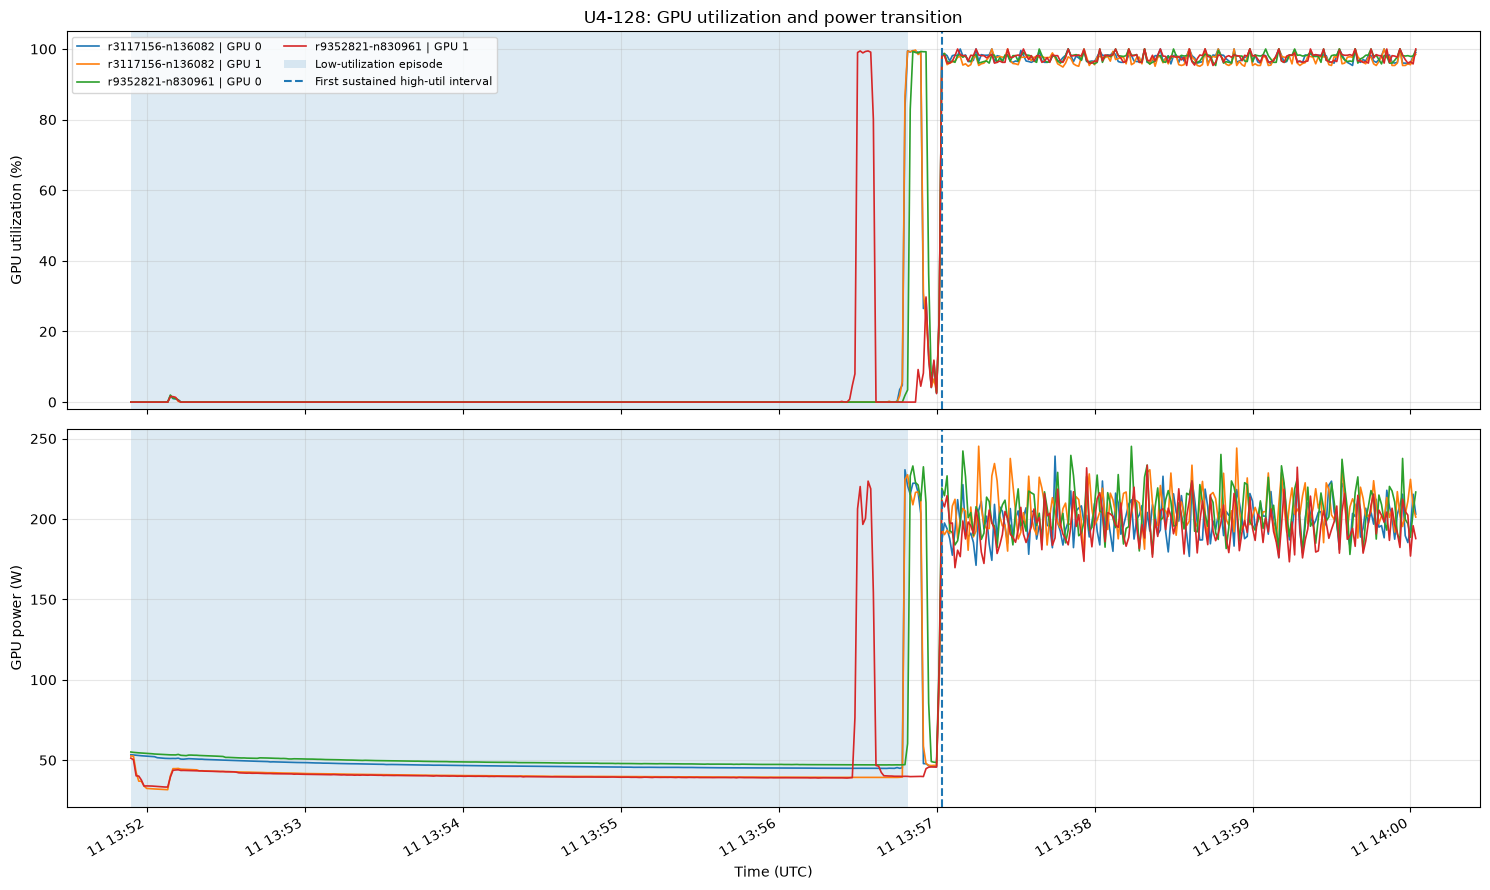

Saved figure: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/outputs/u4_128_transition_timeline_v1.png


In [162]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Primary case study
job_id = "59638293409445"
model = "U4-128"

low_start = pd.Timestamp("2021-05-11 13:51:54", tz="UTC")
low_end = pd.Timestamp("2021-05-11 13:56:49", tz="UTC")
high_start = pd.Timestamp("2021-05-11 13:57:02", tz="UTC")

# Show the transition plus 60 seconds before and after
plot_start = low_start - pd.Timedelta(seconds=60)
plot_end = high_start + pd.Timedelta(minutes=3)

plot_df = pilot_gpu_1s_v2.loc[
    (pilot_gpu_1s_v2["job_id"].astype(str) == job_id)
    & (pilot_gpu_1s_v2["timestamp_1s"] >= plot_start)
    & (pilot_gpu_1s_v2["timestamp_1s"] <= plot_end)
].copy()

plot_df["timestamp_1s"] = pd.to_datetime(
    plot_df["timestamp_1s"], utc=True
)

if plot_df.empty:
    raise ValueError(f"No telemetry found for job {job_id} in the selected window.")

plot_df["gpu_label"] = (
    plot_df["rack_node_id"].astype(str)
    + " | GPU "
    + plot_df["gpu_index"].astype(str)
)

fig, axes = plt.subplots(
    2, 1, figsize=(15, 9), sharex=True
)

# GPU utilization
for label, group in plot_df.groupby("gpu_label"):
    group = group.sort_values("timestamp_1s")
    axes[0].plot(
        group["timestamp_1s"],
        group["utilization_gpu_pct"],
        label=label,
        linewidth=1.2,
    )

axes[0].axvspan(low_start, low_end, alpha=0.15, label="Low-utilization episode")
axes[0].axvline(high_start, linestyle="--", linewidth=1.5, label="First sustained high-util interval")
axes[0].set_ylabel("GPU utilization (%)")
axes[0].set_ylim(-2, 105)
axes[0].set_title(f"{model}: GPU utilization and power transition")
axes[0].legend(loc="upper left", fontsize=8, ncol=2)
axes[0].grid(True, alpha=0.3)

# GPU power
for label, group in plot_df.groupby("gpu_label"):
    group = group.sort_values("timestamp_1s")
    axes[1].plot(
        group["timestamp_1s"],
        group["power_draw_W"],
        label=label,
        linewidth=1.2,
    )

axes[1].axvspan(low_start, low_end, alpha=0.15)
axes[1].axvline(high_start, linestyle="--", linewidth=1.5)
axes[1].set_ylabel("GPU power (W)")
axes[1].set_xlabel("Time (UTC)")
axes[1].grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# Save the figure for the project report
output_path = (
    Path.cwd().parent
    / "outputs"
    / "u4_128_transition_timeline_v1.png"
)
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(output_path, dpi=180, bbox_inches="tight")
print(f"Saved figure: {output_path}")

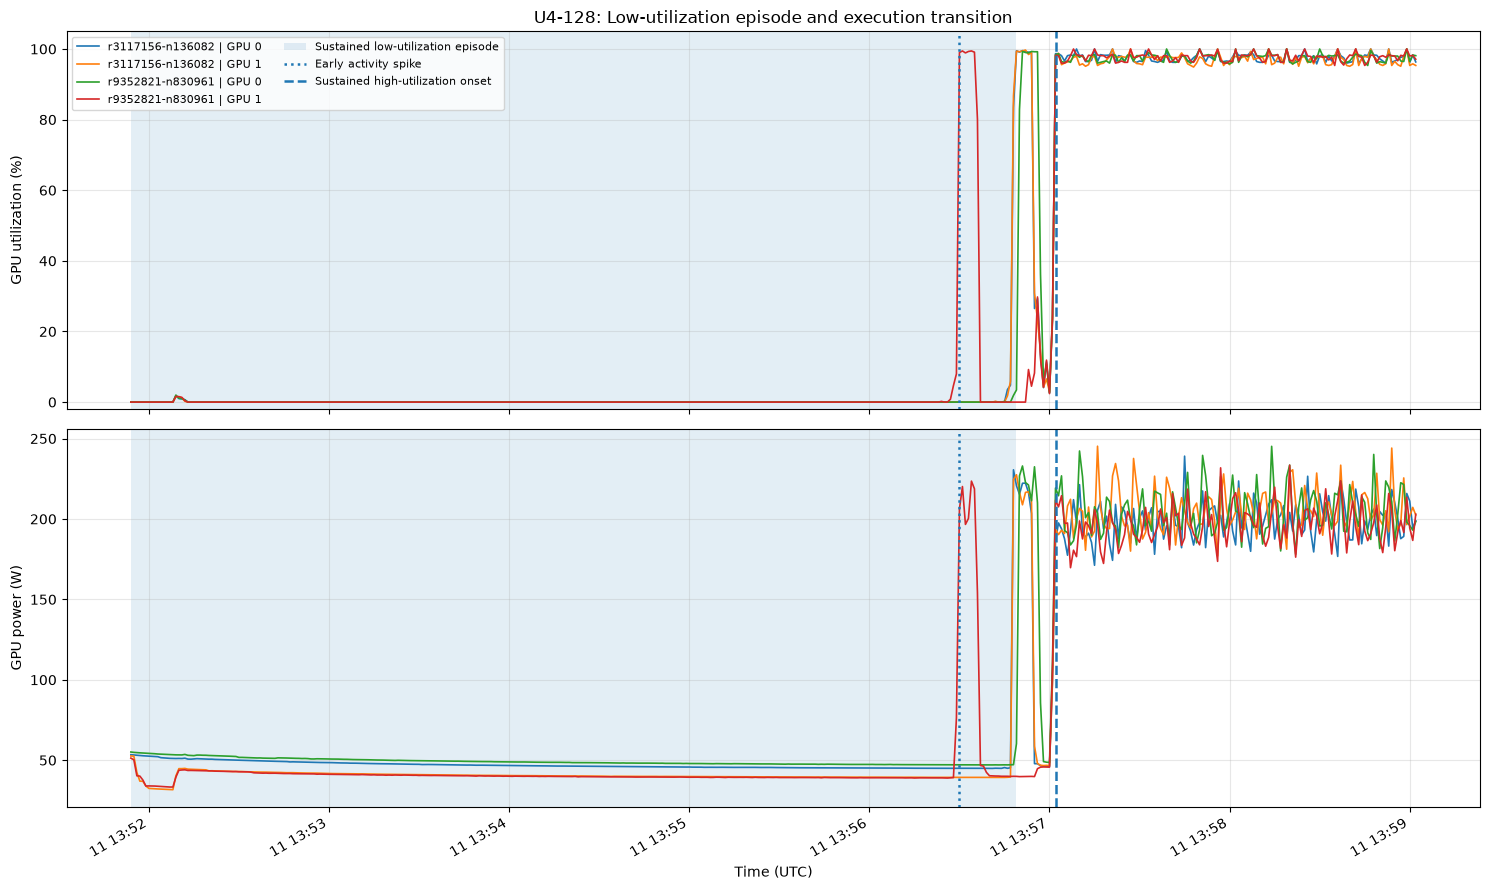

Saved figure: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/outputs/u4_128_transition_timeline_v2.png


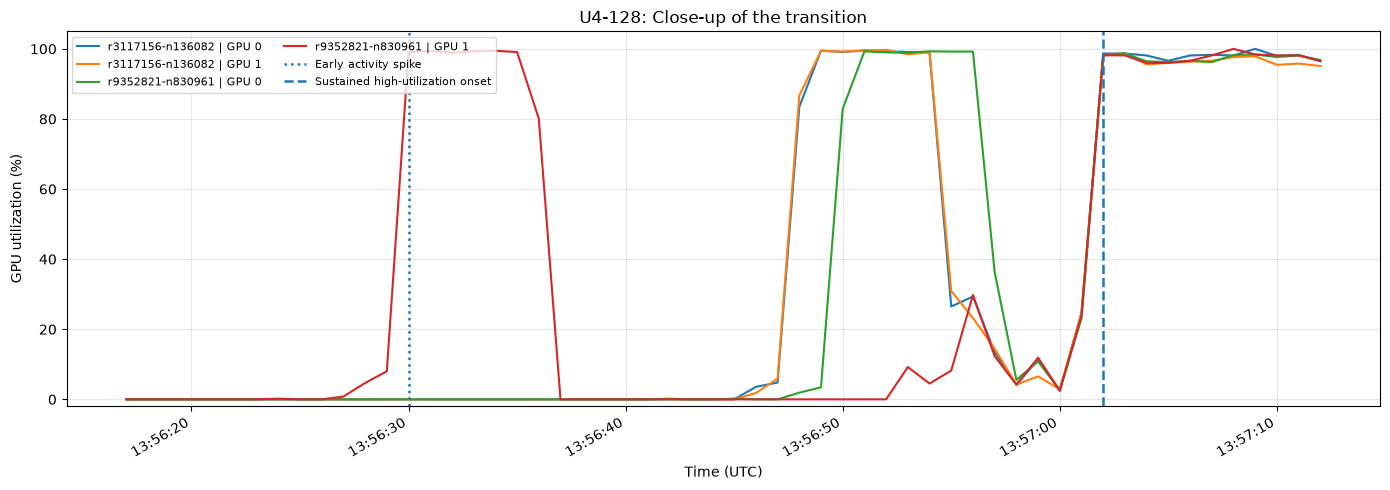

Saved zoom: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/outputs/u4_128_transition_zoom_v1.png


In [164]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

job_id = "59638293409445"

low_start = pd.Timestamp("2021-05-11 13:51:54", tz="UTC")
low_end = pd.Timestamp("2021-05-11 13:56:49", tz="UTC")
high_start = pd.Timestamp("2021-05-11 13:57:02", tz="UTC")

# First clearly visible early spike in the supplied plot
early_spike = pd.Timestamp("2021-05-11 13:56:30", tz="UTC")

plot_start = low_start - pd.Timedelta(seconds=30)
plot_end = high_start + pd.Timedelta(minutes=2)

plot_df = pilot_gpu_1s_v2.loc[
    (pilot_gpu_1s_v2["job_id"].astype(str) == job_id)
    & (pilot_gpu_1s_v2["timestamp_1s"] >= plot_start)
    & (pilot_gpu_1s_v2["timestamp_1s"] <= plot_end)
].copy()

plot_df["timestamp_1s"] = pd.to_datetime(
    plot_df["timestamp_1s"], utc=True
)

plot_df["gpu_label"] = (
    plot_df["rack_node_id"].astype(str)
    + " | GPU "
    + plot_df["gpu_index"].astype(str)
)

fig, axes = plt.subplots(
    2, 1, figsize=(15, 9), sharex=True
)

# Utilization panel
for label, group in plot_df.groupby("gpu_label"):
    group = group.sort_values("timestamp_1s")
    axes[0].plot(
        group["timestamp_1s"],
        group["utilization_gpu_pct"],
        label=label,
        linewidth=1.2,
    )

axes[0].axvspan(
    low_start, low_end, alpha=0.12, label="Sustained low-utilization episode"
)
axes[0].axvline(
    early_spike, linestyle=":", linewidth=1.8,
    label="Early activity spike"
)
axes[0].axvline(
    high_start, linestyle="--", linewidth=1.8,
    label="Sustained high-utilization onset"
)
axes[0].set_ylabel("GPU utilization (%)")
axes[0].set_ylim(-2, 105)
axes[0].set_title("U4-128: Low-utilization episode and execution transition")
axes[0].legend(loc="upper left", fontsize=8, ncol=2)
axes[0].grid(True, alpha=0.3)

# Power panel
for label, group in plot_df.groupby("gpu_label"):
    group = group.sort_values("timestamp_1s")
    axes[1].plot(
        group["timestamp_1s"],
        group["power_draw_W"],
        label=label,
        linewidth=1.2,
    )

axes[1].axvspan(low_start, low_end, alpha=0.12)
axes[1].axvline(early_spike, linestyle=":", linewidth=1.8)
axes[1].axvline(high_start, linestyle="--", linewidth=1.8)
axes[1].set_ylabel("GPU power (W)")
axes[1].set_xlabel("Time (UTC)")
axes[1].grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()

output_path = (
    Path.cwd().parent / "outputs" / "u4_128_transition_timeline_v2.png"
)
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=180, bbox_inches="tight")
plt.show()

print(f"Saved figure: {output_path}")

# Zoom into the final 45 seconds before sustained high utilization
zoom_start = high_start - pd.Timedelta(seconds=45)
zoom_df = plot_df.loc[
    plot_df["timestamp_1s"].between(zoom_start, high_start + pd.Timedelta(seconds=10))
]

fig_zoom, ax = plt.subplots(figsize=(14, 5))

for label, group in zoom_df.groupby("gpu_label"):
    group = group.sort_values("timestamp_1s")
    ax.plot(
        group["timestamp_1s"],
        group["utilization_gpu_pct"],
        label=label,
        linewidth=1.5,
    )

ax.axvline(early_spike, linestyle=":", linewidth=1.8, label="Early activity spike")
ax.axvline(high_start, linestyle="--", linewidth=1.8, label="Sustained high-utilization onset")
ax.set_title("U4-128: Close-up of the transition")
ax.set_ylabel("GPU utilization (%)")
ax.set_xlabel("Time (UTC)")
ax.set_ylim(-2, 105)
ax.legend(loc="upper left", fontsize=8, ncol=2)
ax.grid(True, alpha=0.3)

fig_zoom.autofmt_xdate()
plt.tight_layout()

zoom_path = (
    Path.cwd().parent / "outputs" / "u4_128_transition_zoom_v1.png"
)
fig_zoom.savefig(zoom_path, dpi=180, bbox_inches="tight")
plt.show()

print(f"Saved zoom: {zoom_path}")

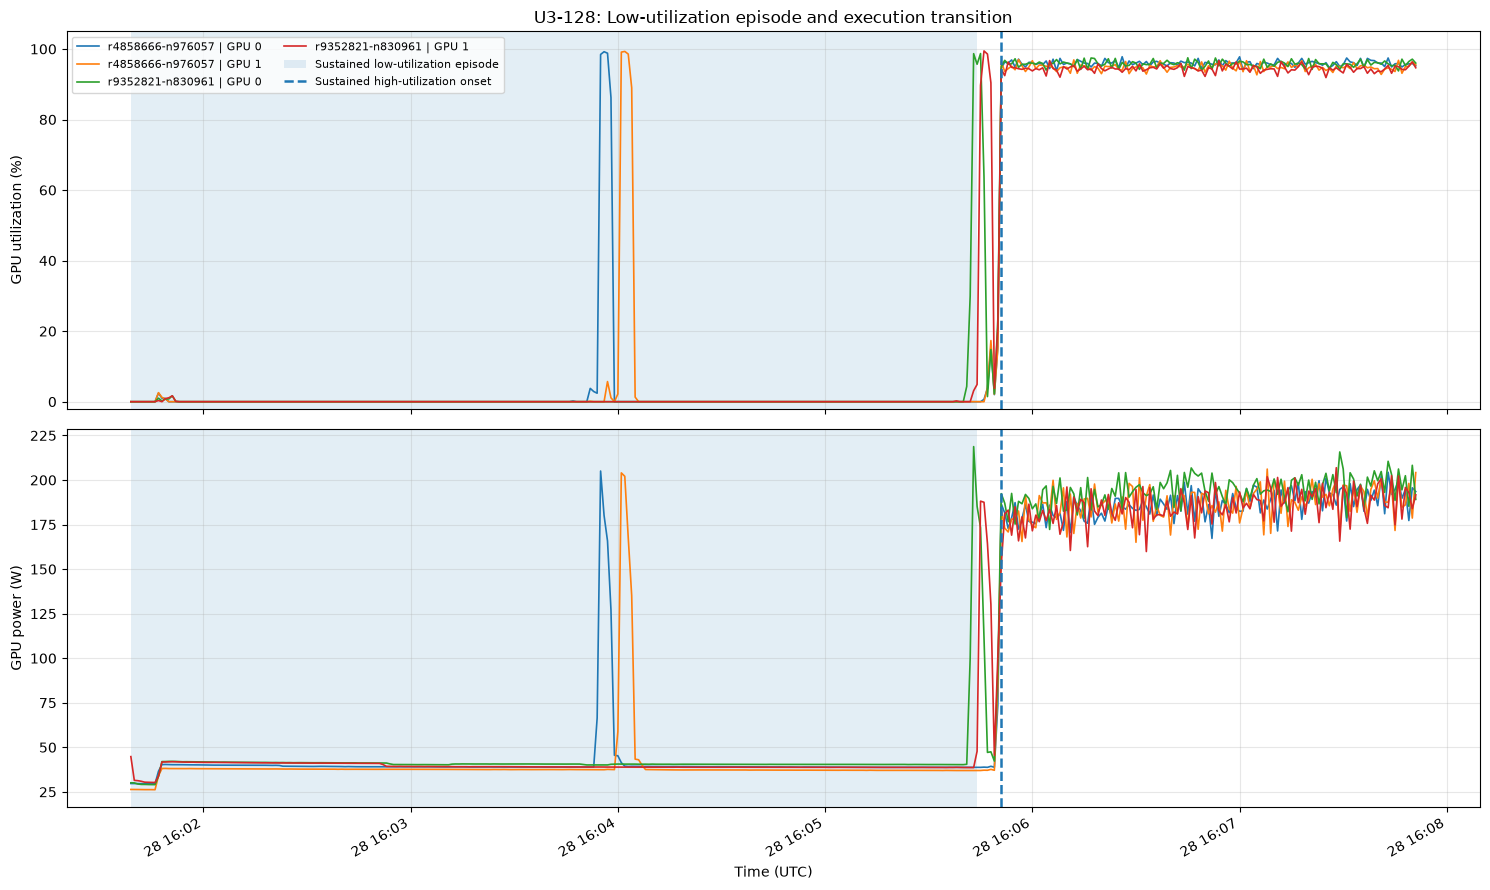

Saved timeline: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/outputs/u3_128_transition_timeline_v1.png


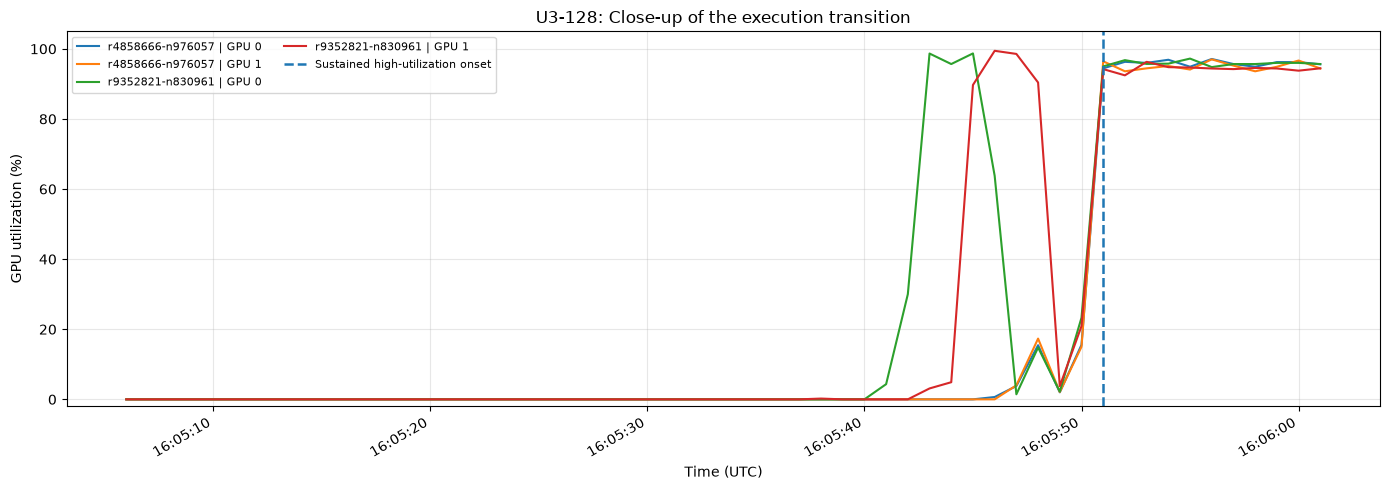

Saved close-up: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/outputs/u3_128_transition_zoom_v1.png


In [166]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# U3-128 comparison case
job_id = "25713459161743"
model = "U3-128"

low_start = pd.Timestamp("2021-05-28 16:01:39", tz="UTC")
low_end = pd.Timestamp("2021-05-28 16:05:44", tz="UTC")
high_start = pd.Timestamp("2021-05-28 16:05:51", tz="UTC")

plot_start = low_start - pd.Timedelta(seconds=30)
plot_end = high_start + pd.Timedelta(minutes=2)

plot_df = pilot_gpu_1s_v2.loc[
    (pilot_gpu_1s_v2["job_id"].astype(str) == job_id)
    & (pilot_gpu_1s_v2["timestamp_1s"] >= plot_start)
    & (pilot_gpu_1s_v2["timestamp_1s"] <= plot_end)
].copy()

plot_df["timestamp_1s"] = pd.to_datetime(
    plot_df["timestamp_1s"], utc=True
)

plot_df["gpu_label"] = (
    plot_df["rack_node_id"].astype(str)
    + " | GPU "
    + plot_df["gpu_index"].astype(str)
)

if plot_df.empty:
    raise ValueError(f"No telemetry found for job {job_id} in the selected window.")

# Full transition timeline
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

for label, group in plot_df.groupby("gpu_label"):
    group = group.sort_values("timestamp_1s")
    axes[0].plot(
        group["timestamp_1s"],
        group["utilization_gpu_pct"],
        label=label,
        linewidth=1.2,
    )

axes[0].axvspan(
    low_start, low_end, alpha=0.12,
    label="Sustained low-utilization episode"
)
axes[0].axvline(
    high_start, linestyle="--", linewidth=1.8,
    label="Sustained high-utilization onset"
)
axes[0].set_ylabel("GPU utilization (%)")
axes[0].set_ylim(-2, 105)
axes[0].set_title("U3-128: Low-utilization episode and execution transition")
axes[0].legend(loc="upper left", fontsize=8, ncol=2)
axes[0].grid(True, alpha=0.3)

for label, group in plot_df.groupby("gpu_label"):
    group = group.sort_values("timestamp_1s")
    axes[1].plot(
        group["timestamp_1s"],
        group["power_draw_W"],
        label=label,
        linewidth=1.2,
    )

axes[1].axvspan(low_start, low_end, alpha=0.12)
axes[1].axvline(high_start, linestyle="--", linewidth=1.8)
axes[1].set_ylabel("GPU power (W)")
axes[1].set_xlabel("Time (UTC)")
axes[1].grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()

output_dir = Path.cwd().parent / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

timeline_path = output_dir / "u3_128_transition_timeline_v1.png"
fig.savefig(timeline_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved timeline: {timeline_path}")

# Close-up of the final 45 seconds before sustained high utilization
zoom_start = high_start - pd.Timedelta(seconds=45)
zoom_end = high_start + pd.Timedelta(seconds=10)

zoom_df = plot_df.loc[
    plot_df["timestamp_1s"].between(zoom_start, zoom_end)
]

fig_zoom, ax = plt.subplots(figsize=(14, 5))

for label, group in zoom_df.groupby("gpu_label"):
    group = group.sort_values("timestamp_1s")
    ax.plot(
        group["timestamp_1s"],
        group["utilization_gpu_pct"],
        label=label,
        linewidth=1.5,
    )

ax.axvline(
    high_start, linestyle="--", linewidth=1.8,
    label="Sustained high-utilization onset"
)
ax.set_title("U3-128: Close-up of the execution transition")
ax.set_ylabel("GPU utilization (%)")
ax.set_xlabel("Time (UTC)")
ax.set_ylim(-2, 105)
ax.legend(loc="upper left", fontsize=8, ncol=2)
ax.grid(True, alpha=0.3)

fig_zoom.autofmt_xdate()
plt.tight_layout()

zoom_path = output_dir / "u3_128_transition_zoom_v1.png"
fig_zoom.savefig(zoom_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved close-up: {zoom_path}")

In [168]:
from pathlib import Path
import pandas as pd

project_root = Path.cwd().parent
processed_dir = project_root / "data" / "processed"
outputs_dir = project_root / "outputs"
outputs_dir.mkdir(parents=True, exist_ok=True)

# Retrieve the two case-study jobs from the existing consolidated review
target_jobs = ["25713459161743", "59638293409445"]

case_study = review.loc[
    review["job_id"].astype(str).isin(target_jobs)
].copy()

# Add the synchronized high-utilization results
high_util_summary = high_util_summary.copy()
high_util_summary["job_id"] = high_util_summary["job_id"].astype(str)

case_study["job_id"] = case_study["job_id"].astype(str)

case_study = case_study.merge(
    high_util_summary,
    on=["job_id", "model"],
    how="left",
    validate="one_to_one",
    suffixes=("", "_high_util"),
)

# Add transition timestamps and initial episode metrics
transition_metrics = transition_comparison[
    [
        "job_id",
        "start_time_low_util",
        "end_time_low_util",
        "duration_s",
        "start_time_high_util",
        "gap_seconds",
        "mean_job_utilization_pct",
    ]
].copy()

transition_metrics["job_id"] = transition_metrics["job_id"].astype(str)

case_study = case_study.merge(
    transition_metrics,
    on="job_id",
    how="left",
    validate="one_to_one",
    suffixes=("", "_first_interval"),
)

# Save the comparison table
comparison_path = (
    processed_dir / "mit_supercloud_transition_case_study_comparison_v1.csv"
)
case_study.to_csv(comparison_path, index=False)

# Build a concise, evidence-based Markdown report
report = """# AI Data Center Intelligence: GPU Transition Case Study

## Objective

Characterize sustained low-utilization periods and transitions into sustained
high GPU utilization using observed MIT Supercloud telemetry.

## Case-study jobs

| Metric | U3-128 | U4-128 |
|---|---:|---:|
| Job ID | 25713459161743 | 59638293409445 |
| Initial sustained low-utilization episode | 246 sec | 296 sec |
| Gap to first qualifying high-utilization interval | 7 sec | 13 sec |
| First qualifying high-utilization interval | 262 sec | 617 sec |
| Mean utilization in first qualifying interval | 95.231% | 97.499% |
| Total qualifying high-utilization time | 2,620 sec | 6,304 sec |
| Number of qualifying intervals | 10 | 11 |
| Mean interval power per observed GPU | 190.650 W | 202.793 W |

## Findings

Both jobs show a sequence of sustained near-idle GPU telemetry, intermittent
activity, and subsequent sustained high utilization across the observed GPU
streams.

U3-128 has an initial low-utilization episode of 246 seconds. Its first
qualifying high-utilization interval begins 7 seconds after the recorded
episode end and lasts 262 seconds.

U4-128 has an initial low-utilization episode of 296 seconds. Its first
qualifying high-utilization interval begins 13 seconds after the recorded
episode end and lasts 617 seconds.

U4-128 has more total qualifying high-utilization time in the observed sample.
These results describe two individual jobs and do not establish model-wide
performance or efficiency differences.

## Methodology

- GPU utilization and power are analyzed at one-second resolution.
- A qualifying high-utilization interval requires all observed GPU streams
  to have records for that second and each observed GPU to have utilization
  of at least 75%.
- Qualifying intervals must contain at least 30 consecutive one-second
  timestamps.
- Separate qualifying intervals are split when timestamps are not consecutive
  or the criterion is not met.
- Power values refer to observed GPU power, not total facility energy.

## Limitations

- Low GPU utilization does not, by itself, prove wasted compute or energy.
- Telemetry does not identify the cause of the low-utilization or transition
  periods. Initialization, data preparation, synchronization, and dependency
  waits remain hypotheses rather than established causes.
- Scheduler allocation matching supports the completeness assessment, but
  observed telemetry does not automatically establish full job-runtime coverage.
- Total qualifying seconds sum separate intervals and are not necessarily
  contiguous wall-clock duration.
- Results from two jobs should not be generalized to all workloads or model
  configurations.

## Figures

- `u3_128_transition_timeline_v1.png`
- `u3_128_transition_zoom_v1.png`
- `u4_128_transition_timeline_v1.png`
- `u4_128_transition_zoom_v1.png`

## Data source

MIT Supercloud Dataset:
https://github.com/MIT-AI-Accelerator/MIT-Supercloud-Dataset

Samsi et al., “The MIT Supercloud Dataset,” 2021 IEEE High Performance
Extreme Computing Conference (HPEC), DOI: 10.1109/HPEC49654.2021.9622850.
"""

report_path = outputs_dir / "gpu_transition_case_study_v1.md"
report_path.write_text(report, encoding="utf-8")

print("Saved comparison table:", comparison_path)
print("Saved report:", report_path)
display(
    case_study[
        [
            "job_id",
            "model",
            "start_time_low_util",
            "end_time_low_util",
            "duration_s",
            "gap_seconds",
            "qualifying_intervals",
            "total_qualifying_seconds",
            "longest_interval_seconds",
            "mean_interval_utilization_pct",
        ]
    ].round(3)
)

Saved comparison table: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_transition_case_study_comparison_v1.csv
Saved report: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/outputs/gpu_transition_case_study_v1.md


/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/3505523878.py:158: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(3)


,job_id,model,start_time_low_util,end_time_low_util,duration_s,gap_seconds,qualifying_intervals,total_qualifying_seconds,longest_interval_seconds,mean_interval_utilization_pct
0,25713459161743,U3-128,2021-05-28 16:01:39+00:00,2021-05-28 16:05:44+00:00,246,7.0,10,2620,262,95.343
1,59638293409445,U4-128,2021-05-11 13:51:54+00:00,2021-05-11 13:56:49+00:00,296,13.0,11,6304,675,97.107


In [169]:
from pathlib import Path

project_root = Path.cwd().parent
outputs_dir = project_root / "outputs"
processed_dir = project_root / "data" / "processed"

expected_files = [
    outputs_dir / "gpu_transition_case_study_v1.md",
    outputs_dir / "u3_128_transition_timeline_v1.png",
    outputs_dir / "u3_128_transition_zoom_v1.png",
    outputs_dir / "u4_128_transition_timeline_v1.png",
    outputs_dir / "u4_128_transition_zoom_v1.png",
    processed_dir / "mit_supercloud_transition_case_study_comparison_v1.csv",
]

artifact_status = []

for path in expected_files:
    artifact_status.append({
        "file": str(path.relative_to(project_root)),
        "exists": path.exists(),
        "size_bytes": path.stat().st_size if path.exists() else None,
    })

display(pd.DataFrame(artifact_status))

,file,exists,size_bytes
0,outputs/gpu_transition_case_study_v1.md,True,3096
1,outputs/u3_128_transition_timeline_v1.png,True,328744
2,outputs/u3_128_transition_zoom_v1.png,True,127014
3,outputs/u4_128_transition_timeline_v1.png,True,360496
4,outputs/u4_128_transition_zoom_v1.png,True,154127
5,data/processed/mit_supercloud_transition_case_...,True,2242


In [170]:
from pathlib import Path
import pandas as pd

project_root = Path.cwd().parent
processed_dir = project_root / "data" / "processed"

files_to_check = {
    "consolidated_review": (
        "mit_supercloud_consolidated_job_review_v1.csv"
    ),
    "investigation_candidates": (
        "mit_supercloud_job_investigation_candidates_v1.csv"
    ),
    "job_energy": (
        "mit_supercloud_job_energy_pilot_v1.csv"
    ),
    "job_utilization": (
        "mit_supercloud_job_utilization_profile_v1.csv"
    ),
    "synchronized_low_util": (
        "mit_supercloud_synchronized_low_util_by_job_v1.csv"
    ),
}

loaded = {}
file_checks = []

for name, filename in files_to_check.items():
    path = processed_dir / filename

    if not path.exists():
        file_checks.append({
            "dataset": name,
            "exists": False,
            "rows": None,
            "columns": None,
            "duplicate_job_ids": None,
        })
        continue

    df = pd.read_csv(path)
    loaded[name] = df

    duplicate_ids = (
        df["job_id"].astype(str).duplicated().sum()
        if "job_id" in df.columns
        else None
    )

    file_checks.append({
        "dataset": name,
        "exists": True,
        "rows": len(df),
        "columns": len(df.columns),
        "duplicate_job_ids": duplicate_ids,
    })

display(pd.DataFrame(file_checks))

# Detailed checks on the consolidated review
if "consolidated_review" in loaded:
    review_check = loaded["consolidated_review"]

    print("\nConsolidated review columns:")
    print(review_check.columns.tolist())

    print("\nShape:", review_check.shape)
    print("Unique job IDs:", review_check["job_id"].astype(str).nunique())
    print("Duplicate job IDs:", review_check["job_id"].astype(str).duplicated().sum())

    print("\nMissing values in key fields:")
    key_fields = [
        col for col in [
            "job_id",
            "model",
            "workload_family",
            "allocation_status",
            "investigation_priority",
        ]
        if col in review_check.columns
    ]
    display(review_check[key_fields].isna().sum().rename("missing_count").to_frame())

    for col in ["allocation_status", "investigation_priority", "review_priority"]:
        if col in review_check.columns:
            print(f"\nDistribution: {col}")
            display(review_check[col].value_counts(dropna=False).to_frame("jobs"))

,dataset,exists,rows,columns,duplicate_job_ids
0,consolidated_review,True,26,37,0
1,investigation_candidates,True,26,12,0
2,job_energy,True,26,14,0
3,job_utilization,True,26,14,0
4,synchronized_low_util,True,17,10,0



Consolidated review columns:
['job_id', 'model', 'workload_family', 'observations', 'low_util_observations', 'low_util_pct', 'near_idle_pct', 'high_util_pct', 'mean_power_W', 'observed_energy_Wh', 'telemetry_status', 'investigation_priority', 'observed_gpu_count', 'total_observed_gpu_seconds', 'mean_gpu_power_W', 'peak_gpu_power_W', 'telemetry_start', 'telemetry_end', 'scheduler_gpu_count', 'allocation_matches', 'observed_energy_kWh', 'telemetry_coverage_status', 'mean_gpu_utilization_pct', 'median_power_W', 'near_idle_observations', 'high_util_observations', 'synchronized_episodes', 'total_synchronized_seconds', 'longest_synchronized_episode_s', 'mean_synchronized_utilization_pct', 'mean_power_per_observed_gpu_W', 'observed_gpu_streams', 'telemetry_complete_for_allocation', 'sustained_episode_count', 'total_sustained_low_util_seconds', 'longest_low_util_episode_seconds', 'allocation_status']

Shape: (26, 37)
Unique job IDs: 26
Duplicate job IDs: 0

Missing values in key fields:


,missing_count
job_id,0
model,0
workload_family,0
allocation_status,0
investigation_priority,0



Distribution: allocation_status


,jobs
allocation_status,
Allocation count matched,25
Review telemetry coverage,1



Distribution: investigation_priority


,jobs
investigation_priority,
Routine,13
Review,9
High review priority,3
Data-quality review,1


In [171]:
import pandas as pd
from pathlib import Path

project_root = Path.cwd().parent
processed_dir = project_root / "data" / "processed"

# Load source datasets
energy = pd.read_csv(
    processed_dir / "mit_supercloud_job_energy_pilot_v1.csv"
)
utilization = pd.read_csv(
    processed_dir / "mit_supercloud_job_utilization_profile_v1.csv"
)
episodes = pd.read_csv(
    processed_dir / "mit_supercloud_sustained_low_util_episodes_v1.csv"
)
synchronized = pd.read_csv(
    processed_dir / "mit_supercloud_synchronized_low_util_by_job_v1.csv"
)
review = pd.read_csv(
    processed_dir / "mit_supercloud_consolidated_job_review_v1.csv"
)

# Normalize IDs before merging
for df in [energy, utilization, synchronized, review]:
    df["job_id"] = df["job_id"].astype(str)

episodes["job_id"] = episodes["job_id"].astype(str)

# Summarize sustained low-utilization episodes per job
episode_summary = (
    episodes.groupby("job_id", as_index=False)
    .agg(
        sustained_episode_count=("duration_s", "size"),
        total_sustained_low_util_seconds=("duration_s", "sum"),
        longest_sustained_low_util_seconds=("duration_s", "max"),
        mean_sustained_episode_utilization_pct=(
            "mean_utilization_pct", "mean"
        ),
    )
)

# Keep only the relevant columns from each source
energy_cols = [
    "job_id", "observed_energy_Wh", "observed_energy_kWh",
    "mean_gpu_power_W", "observed_gpu_count",
    "allocation_matches", "telemetry_coverage_status",
]
energy_cols = [c for c in energy_cols if c in energy.columns]

util_cols = [
    "job_id", "low_util_pct", "mean_gpu_utilization_pct",
    "near_idle_pct", "high_util_pct",
]
util_cols = [c for c in util_cols if c in utilization.columns]

sync_cols = [
    "job_id", "synchronized_episodes",
    "total_synchronized_seconds",
    "longest_synchronized_episode_s",
    "mean_synchronized_utilization_pct",
]
sync_cols = [c for c in sync_cols if c in synchronized.columns]

screening = review[[
    "job_id", "model", "workload_family",
    "investigation_priority", "allocation_status",
]].copy()

screening = screening.merge(
    energy[energy_cols], on="job_id", how="left", validate="one_to_one"
)
screening = screening.merge(
    utilization[util_cols], on="job_id", how="left", validate="one_to_one"
)
screening = screening.merge(
    episode_summary, on="job_id", how="left", validate="one_to_one"
)
screening = screening.merge(
    synchronized[sync_cols], on="job_id", how="left", validate="one_to_one"
)

# No detected episodes is different from missing job-level telemetry
for col in [
    "sustained_episode_count",
    "total_sustained_low_util_seconds",
    "longest_sustained_low_util_seconds",
    "synchronized_episodes",
    "total_synchronized_seconds",
    "longest_synchronized_episode_s",
]:
    if col in screening.columns:
        screening[col] = screening[col].fillna(0)

# Separate data-quality status from analytical screening
screening["data_quality_flag"] = screening.apply(
    lambda row: (
        "Review telemetry coverage"
        if row.get("allocation_status") != "Allocation count matched"
        else "Allocation matched; inspect other quality checks"
    ),
    axis=1,
)

screening["screening_signal"] = screening.apply(
    lambda row: (
        "Synchronized low-utilization interval"
        if row.get("total_synchronized_seconds", 0) > 0
        else (
            "Sustained low-utilization episode"
            if row.get("total_sustained_low_util_seconds", 0) > 0
            else "No sustained episode detected"
        )
    ),
    axis=1,
)

# Save output
output_path = (
    processed_dir / "mit_supercloud_optimization_screening_v1.csv"
)
screening.to_csv(output_path, index=False)

print("Rows:", len(screening))
print("Unique jobs:", screening["job_id"].nunique())
print("Duplicate jobs:", screening["job_id"].duplicated().sum())
print("Saved:", output_path)

display(
    screening.sort_values(
        ["total_synchronized_seconds",
         "total_sustained_low_util_seconds"],
        ascending=False,
    )[
        [
            "job_id", "model", "workload_family",
            "observed_energy_Wh", "low_util_pct",
            "total_sustained_low_util_seconds",
            "total_synchronized_seconds",
            "data_quality_flag", "screening_signal",
        ]
    ].head(15).round(3)
)

Rows: 26
Unique jobs: 26
Duplicate jobs: 0
Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_optimization_screening_v1.csv


,job_id,model,workload_family,observed_energy_Wh,low_util_pct,total_sustained_low_util_seconds,total_synchronized_seconds,data_quality_flag,screening_signal
3,59638293409445,U4-128,Vision,1438.342,4.909,1160.0,296.0,Allocation matched; inspect other quality checks,Synchronized low-utilization interval
4,18203079158032,schnet,GNN,531.131,3.426,518.0,259.0,Allocation matched; inspect other quality checks,Synchronized low-utilization interval
0,25713459161743,U3-128,Vision,577.873,8.670,979.0,249.0,Allocation matched; inspect other quality checks,Synchronized low-utilization interval
12,29381280178268,U3-32,Vision,228.461,9.640,509.0,244.0,Review telemetry coverage,Synchronized low-utilization interval
5,68307271431118,U4-32,Vision,452.066,3.859,467.0,233.0,Allocation matched; inspect other quality checks,Synchronized low-utilization interval
6,74636684972411,U3-64,Vision,451.848,4.608,435.0,215.0,Allocation matched; inspect other quality checks,Synchronized low-utilization interval
13,79150048009801,U5-64,Vision,3038.773,0.860,429.0,211.0,Allocation matched; inspect other quality checks,Synchronized low-utilization interval
15,48510612336879,vgg19,Vision,4298.183,0.513,246.0,123.0,Allocation matched; inspect other quality checks,Synchronized low-utilization interval
17,15179646833041,conv,GNN,1590.255,0.682,174.0,86.0,Allocation matched; inspect other quality checks,Synchronized low-utilization interval
10,36230628475012,pna,GNN,135.202,2.753,157.0,78.0,Allocation matched; inspect other quality checks,Synchronized low-utilization interval


In [172]:
# Audit screening labels, allocation coverage, and missing metrics
screening = pd.read_csv(
    processed_dir / "mit_supercloud_optimization_screening_v1.csv"
)

review = pd.read_csv(
    processed_dir / "mit_supercloud_consolidated_job_review_v1.csv"
)

for df in [screening, review]:
    df["job_id"] = df["job_id"].astype(str)

print("Screening shape:", screening.shape)
print("Unique screening jobs:", screening["job_id"].nunique())
print("Duplicate screening job IDs:", screening["job_id"].duplicated().sum())

print("\nScreening signal counts:")
display(screening["screening_signal"].value_counts(dropna=False).to_frame("jobs"))

print("\nData-quality flag counts:")
display(screening["data_quality_flag"].value_counts(dropna=False).to_frame("jobs"))

# Compare priority labels with the original consolidated review
priority_check = screening[
    ["job_id", "model", "investigation_priority", "allocation_status"]
].merge(
    review[["job_id", "investigation_priority", "allocation_status"]],
    on="job_id",
    how="outer",
    suffixes=("_screening", "_review"),
    indicator=True,
    validate="one_to_one",
)

priority_check["priority_matches"] = (
    priority_check["investigation_priority_screening"]
    == priority_check["investigation_priority_review"]
)

priority_check["allocation_status_matches"] = (
    priority_check["allocation_status_screening"]
    == priority_check["allocation_status_review"]
)

display(priority_check.head(10))

print("\nPriority mismatches:",
      (~priority_check["priority_matches"]).sum())
print("Allocation status mismatches:",
      (~priority_check["allocation_status_matches"]).sum())
print("Unmatched records:",
      (priority_check["_merge"] != "both").sum())

# Inspect the incomplete-coverage job explicitly
display(
    screening.loc[
        screening["allocation_status"] != "Allocation count matched"
    ].T
)

Screening shape: (26, 25)
Unique screening jobs: 26
Duplicate screening job IDs: 0

Screening signal counts:


,jobs
screening_signal,
Synchronized low-utilization interval,17
Sustained low-utilization episode,7
No sustained episode detected,2



Data-quality flag counts:


,jobs
data_quality_flag,
Allocation matched; inspect other quality checks,25
Review telemetry coverage,1


,job_id,model,investigation_priority_screening,allocation_status_screening,investigation_priority_review,allocation_status_review,_merge,priority_matches,allocation_status_matches
0,13063192210942,vgg16,Review,Allocation count matched,Review,Allocation count matched,both,True,True
1,15179646833041,conv,Routine,Allocation count matched,Routine,Allocation count matched,both,True,True
2,15305255756787,resnet152,Routine,Allocation count matched,Routine,Allocation count matched,both,True,True
3,18203079158032,schnet,Review,Allocation count matched,Review,Allocation count matched,both,True,True
4,18242747496687,U5-32,Review,Allocation count matched,Review,Allocation count matched,both,True,True
5,2304959634945,distilbert-base-uncased,Review,Allocation count matched,Review,Allocation count matched,both,True,True
6,25713459161743,U3-128,High review priority,Allocation count matched,High review priority,Allocation count matched,both,True,True
7,29381280178268,U3-32,Data-quality review,Review telemetry coverage,Data-quality review,Review telemetry coverage,both,True,True
8,36230628475012,pna,Review,Allocation count matched,Review,Allocation count matched,both,True,True
9,38596192451856,resnet50_v1.5,Routine,Allocation count matched,Routine,Allocation count matched,both,True,True



Priority mismatches: 0
Allocation status mismatches: 0
Unmatched records: 0


,12
job_id,29381280178268
model,U3-32
workload_family,Vision
investigation_priority,Data-quality review
allocation_status,Review telemetry coverage
observed_energy_Wh,228.461362
observed_energy_kWh,0.228461
mean_gpu_power_W,146.553974
observed_gpu_count,2
allocation_matches,False


In [173]:
# Refine review categories while preserving original priority labels

screening["review_category"] = "Routine monitoring"

# Data quality takes precedence over performance screening
screening.loc[
    screening["allocation_status"] != "Allocation count matched",
    "review_category"
] = "Data-quality review"

# Among jobs with matched allocation, identify performance signals
matched = screening["allocation_status"] == "Allocation count matched"

screening.loc[
    matched
    & (screening["total_synchronized_seconds"] > 0),
    "review_category"
] = "Performance investigation"

screening.loc[
    matched
    & (screening["total_synchronized_seconds"] == 0)
    & (screening["total_sustained_low_util_seconds"] > 0),
    "review_category"
] = "Performance investigation"

# Report category counts and inspect the results
print("Review category counts:")
display(
    screening["review_category"]
    .value_counts(dropna=False)
    .rename_axis("review_category")
    .to_frame("jobs")
)

print("\nJobs requiring data-quality review:")
display(
    screening.loc[
        screening["review_category"] == "Data-quality review",
        [
            "job_id", "model", "allocation_status",
            "telemetry_coverage_status", "screening_signal"
        ]
    ]
)

# Save a new version; leave the original file unchanged
output_path = (
    processed_dir / "mit_supercloud_optimization_screening_v2.csv"
)
screening.to_csv(output_path, index=False)

print("\nSaved:", output_path)

Review category counts:


,jobs
review_category,
Performance investigation,23
Routine monitoring,2
Data-quality review,1



Jobs requiring data-quality review:


,job_id,model,allocation_status,telemetry_coverage_status,screening_signal
12,29381280178268,U3-32,Review telemetry coverage,INCOMPLETE: GPU allocation mismatch,Synchronized low-utilization interval



Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_optimization_screening_v2.csv


In [174]:
# Inspect performance-investigation jobs by existing priority
performance_review = screening.loc[
    screening["review_category"] == "Performance investigation"
].copy()

priority_order = {
    "High review priority": 0,
    "Review": 1,
    "Routine": 2,
}

performance_review["priority_order"] = (
    performance_review["investigation_priority"].map(priority_order)
)

performance_review = performance_review.sort_values(
    [
        "priority_order",
        "total_synchronized_seconds",
        "total_sustained_low_util_seconds",
    ],
    ascending=[True, False, False],
)

display(
    performance_review[
        [
            "job_id",
            "model",
            "workload_family",
            "investigation_priority",
            "low_util_pct",
            "total_sustained_low_util_seconds",
            "longest_sustained_low_util_seconds",
            "total_synchronized_seconds",
            "allocation_status",
        ]
    ].round(3)
)

print("\nPerformance-investigation jobs:", len(performance_review))
print("\nExisting priority distribution:")
display(
    performance_review["investigation_priority"]
    .value_counts(dropna=False)
    .to_frame("jobs")
)

,job_id,model,workload_family,investigation_priority,low_util_pct,total_sustained_low_util_seconds,longest_sustained_low_util_seconds,total_synchronized_seconds,allocation_status
0,25713459161743,U3-128,Vision,High review priority,8.670,979.0,246.0,249.0,Allocation count matched
2,55788973536832,resnet101,Vision,High review priority,5.303,141.0,38.0,39.0,Allocation count matched
1,48020198141948,U4-64,Vision,High review priority,16.317,386.0,386.0,0.0,Allocation count matched
3,59638293409445,U4-128,Vision,Review,4.909,1160.0,296.0,296.0,Allocation count matched
4,18203079158032,schnet,GNN,Review,3.426,518.0,203.0,259.0,Allocation count matched
5,68307271431118,U4-32,Vision,Review,3.859,467.0,234.0,233.0,Allocation count matched
6,74636684972411,U3-64,Vision,Review,4.608,435.0,220.0,215.0,Allocation count matched
10,36230628475012,pna,GNN,Review,2.753,157.0,79.0,78.0,Allocation count matched
11,2304959634945,distilbert-base-uncased,NLP,Review,2.359,116.0,58.0,58.0,Allocation count matched
7,13063192210942,vgg16,Vision,Review,2.152,360.0,47.0,45.0,Allocation count matched



Performance-investigation jobs: 23

Existing priority distribution:


,jobs
investigation_priority,
Routine,11
Review,9
High review priority,3


In [175]:
# Step 4: Apply transparent, rule-based investigation tiers

screening["investigation_tier"] = "Tier 3 - Monitor"

# Tier 2: meaningful sustained or synchronized signal
tier_2 = (
    (screening["total_synchronized_seconds"] > 0)
    | (screening["total_sustained_low_util_seconds"] >= 120)
)

screening.loc[tier_2, "investigation_tier"] = "Tier 2 - Investigate"

# Tier 1: longer synchronized episodes or sustained low utilization
# combined with a relatively high low-utilization share
tier_1 = (
    (screening["total_synchronized_seconds"] >= 180)
    | (
        (screening["total_sustained_low_util_seconds"] >= 300)
        & (screening["low_util_pct"] >= 5)
    )
)

screening.loc[tier_1, "investigation_tier"] = "Tier 1 - High investigation"

# Data-quality status takes precedence over performance tier
incomplete = screening["allocation_status"] != "Allocation count matched"
screening.loc[incomplete, "investigation_tier"] = "Data-quality review"

# Display the new tiers
tier_order = [
    "Data-quality review",
    "Tier 1 - High investigation",
    "Tier 2 - Investigate",
    "Tier 3 - Monitor",
]

print("Investigation tier counts:")
display(
    screening["investigation_tier"]
    .value_counts()
    .reindex(tier_order, fill_value=0)
    .rename_axis("investigation_tier")
    .to_frame("jobs")
)

# Inspect every Tier 1 job
print("\nTier 1 candidates:")
display(
    screening.loc[
        screening["investigation_tier"] == "Tier 1 - High investigation",
        [
            "job_id", "model", "workload_family",
            "investigation_priority", "low_util_pct",
            "total_sustained_low_util_seconds",
            "longest_sustained_low_util_seconds",
            "total_synchronized_seconds",
            "observed_energy_Wh",
        ],
    ].sort_values(
        ["total_synchronized_seconds",
         "total_sustained_low_util_seconds"],
        ascending=False,
    ).round(3)
)

# Save a new version without overwriting previous screening artifacts
output_path = (
    processed_dir / "mit_supercloud_optimization_screening_v3.csv"
)
screening.to_csv(output_path, index=False)

print("\nSaved:", output_path)

Investigation tier counts:


,jobs
investigation_tier,
Data-quality review,1
Tier 1 - High investigation,7
Tier 2 - Investigate,14
Tier 3 - Monitor,4



Tier 1 candidates:


,job_id,model,workload_family,investigation_priority,low_util_pct,total_sustained_low_util_seconds,longest_sustained_low_util_seconds,total_synchronized_seconds,observed_energy_Wh
3,59638293409445,U4-128,Vision,Review,4.909,1160.0,296.0,296.0,1438.342
4,18203079158032,schnet,GNN,Review,3.426,518.0,203.0,259.0,531.131
0,25713459161743,U3-128,Vision,High review priority,8.670,979.0,246.0,249.0,577.873
5,68307271431118,U4-32,Vision,Review,3.859,467.0,234.0,233.0,452.066
6,74636684972411,U3-64,Vision,Review,4.608,435.0,220.0,215.0,451.848
13,79150048009801,U5-64,Vision,Routine,0.860,429.0,217.0,211.0,3038.773
1,48020198141948,U4-64,Vision,High review priority,16.317,386.0,386.0,0.0,111.709



Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_optimization_screening_v3.csv


In [176]:
import pandas as pd
from pathlib import Path

project_root = Path.cwd().parent
processed_dir = project_root / "data" / "processed"

telemetry_path = (
    processed_dir / "mit_supercloud_gpu_pilot_1s_all_files_v2.csv"
)

telemetry = pd.read_csv(telemetry_path)

# Verify required telemetry fields
required = [
    "job_id",
    "timestamp_1s",
    "utilization_gpu_pct",
    "power_draw_W",
]

missing = [col for col in required if col not in telemetry.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

telemetry["job_id"] = telemetry["job_id"].astype(str)

# Each row represents one observed GPU stream at one-second resolution.
# Convert one-second mean power in watts to watt-hours.
telemetry["observed_energy_Wh"] = telemetry["power_draw_W"] / 3600

telemetry["low_util_under_10"] = (
    telemetry["utilization_gpu_pct"] < 10
)

energy_by_job = (
    telemetry.groupby("job_id", as_index=False)
    .agg(
        telemetry_rows=("timestamp_1s", "size"),
        total_observed_energy_Wh=("observed_energy_Wh", "sum"),
        low_util_rows=("low_util_under_10", "sum"),
        low_util_observed_energy_Wh=(
            "observed_energy_Wh",
            lambda s: s[
                telemetry.loc[s.index, "low_util_under_10"]
            ].sum(),
        ),
    )
)

energy_by_job["low_util_observation_pct"] = (
    100 * energy_by_job["low_util_rows"]
    / energy_by_job["telemetry_rows"]
)

energy_by_job["low_util_energy_pct"] = (
    100 * energy_by_job["low_util_observed_energy_Wh"]
    / energy_by_job["total_observed_energy_Wh"]
)

# Preserve the established allocation-quality status
coverage = screening[["job_id", "allocation_status"]].copy()
coverage["job_id"] = coverage["job_id"].astype(str)

energy_by_job = energy_by_job.merge(
    coverage,
    on="job_id",
    how="left",
    validate="one_to_one",
)

energy_by_job = energy_by_job.merge(
    screening[
        ["job_id", "model", "workload_family", "investigation_tier"]
    ],
    on="job_id",
    how="left",
    validate="one_to_one",
)

output_path = (
    processed_dir / "mit_supercloud_low_util_energy_screening_v1.csv"
)
energy_by_job.to_csv(output_path, index=False)

print("Jobs:", energy_by_job["job_id"].nunique())
print("Saved:", output_path)

display(
    energy_by_job.sort_values(
        "low_util_observed_energy_Wh",
        ascending=False,
    )[
        [
            "job_id", "model", "investigation_tier",
            "low_util_rows", "low_util_observation_pct",
            "low_util_observed_energy_Wh", "low_util_energy_pct",
            "allocation_status",
        ]
    ].head(15).round(3)
)

Jobs: 26
Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_low_util_energy_screening_v1.csv


,job_id,model,investigation_tier,low_util_rows,low_util_observation_pct,low_util_observed_energy_Wh,low_util_energy_pct,allocation_status
14,55788973536832,resnet101,Tier 2 - Investigate,2764,5.303,41.666,1.655,Allocation count matched
17,59638293409445,U4-128,Tier 1 - High investigation,1309,4.909,16.364,1.138,Allocation count matched
6,25713459161743,U3-128,Tier 1 - High investigation,1022,8.670,11.244,1.946,Allocation count matched
15,59030654331752,U5-128,Tier 2 - Investigate,545,2.686,7.318,0.658,Allocation count matched
21,79150048009801,U5-64,Tier 1 - High investigation,544,0.860,6.468,0.213,Allocation count matched
0,13063192210942,vgg16,Tier 2 - Investigate,698,2.152,6.457,0.575,Allocation count matched
7,29381280178268,U3-32,Data-quality review,541,9.640,6.437,2.818,Review telemetry coverage
18,68307271431118,U4-32,Tier 1 - High investigation,493,3.859,6.283,1.390,Allocation count matched
24,8427789164283,bert-base-uncased,Tier 2 - Investigate,507,1.441,6.221,1.011,Allocation count matched
5,2304959634945,distilbert-base-uncased,Tier 2 - Investigate,484,2.359,5.720,1.549,Allocation count matched


In [177]:
# Compare the new telemetry-derived energy totals with the existing artifact

energy_reference = pd.read_csv(
    processed_dir / "mit_supercloud_job_energy_pilot_v1.csv"
)

energy_reference["job_id"] = energy_reference["job_id"].astype(str)
energy_by_job["job_id"] = energy_by_job["job_id"].astype(str)

energy_check = energy_by_job.merge(
    energy_reference[
        ["job_id", "observed_energy_Wh", "observed_energy_kWh"]
    ],
    on="job_id",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

energy_check["energy_difference_Wh"] = (
    energy_check["total_observed_energy_Wh"]
    - energy_check["observed_energy_Wh"]
)

print("Reference jobs:", energy_reference["job_id"].nunique())
print("Recalculated jobs:", energy_by_job["job_id"].nunique())
print("Unmatched jobs:", (energy_check["_merge"] != "both").sum())

print("\nAggregate comparison:")
display(pd.DataFrame({
    "metric": [
        "Reference total observed GPU energy (Wh)",
        "Recalculated total observed GPU energy (Wh)",
        "Absolute difference (Wh)",
        "Total energy during utilization <10% (Wh)",
    ],
    "value": [
        energy_check["observed_energy_Wh"].sum(),
        energy_check["total_observed_energy_Wh"].sum(),
        energy_check["energy_difference_Wh"].abs().sum(),
        energy_by_job["low_util_observed_energy_Wh"].sum(),
    ],
}).round(6))

print("\nLargest per-job energy differences:")
display(
    energy_check[
        ["job_id", "observed_energy_Wh",
         "total_observed_energy_Wh", "energy_difference_Wh"]
    ]
    .assign(
        absolute_difference_Wh=lambda df: df["energy_difference_Wh"].abs()
    )
    .sort_values("absolute_difference_Wh", ascending=False)
    .head(10)
    .round(6)
)

Reference jobs: 26
Recalculated jobs: 26
Unmatched jobs: 0

Aggregate comparison:


,metric,value
0,Reference total observed GPU energy (Wh),37965.933621
1,Recalculated total observed GPU energy (Wh),37965.933621
2,Absolute difference (Wh),0.000000
3,Total energy during utilization <10% (Wh),161.210015



Largest per-job energy differences:


,job_id,observed_energy_Wh,total_observed_energy_Wh,energy_difference_Wh,absolute_difference_Wh
20,78604982814993,2087.759081,2087.759081,0.0,0.0
14,55788973536832,2517.179100,2517.179100,-0.0,0.0
11,44317307973280,1344.224848,1344.224848,0.0,0.0
17,59638293409445,1438.341751,1438.341751,0.0,0.0
5,2304959634945,369.248007,369.248007,-0.0,0.0
19,74636684972411,451.848237,451.848237,0.0,0.0
9,38596192451856,394.207107,394.207107,0.0,0.0
12,48020198141948,111.709414,111.709414,0.0,0.0
0,13063192210942,1122.674093,1122.674093,0.0,0.0
16,59464190077432,566.563351,566.563351,0.0,0.0


In [178]:
# Final energy reconciliation summary

print("Reference jobs:", energy_reference["job_id"].nunique())
print("Recalculated jobs:", energy_by_job["job_id"].nunique())
print("Unmatched jobs:", (energy_check["_merge"] != "both").sum())

print(
    "Reference total energy (Wh):",
    round(energy_check["observed_energy_Wh"].sum(), 6)
)
print(
    "Recalculated total energy (Wh):",
    round(energy_check["total_observed_energy_Wh"].sum(), 6)
)
print(
    "Maximum absolute per-job difference (Wh):",
    round(energy_check["energy_difference_Wh"].abs().max(), 9)
)

total_energy = energy_by_job["total_observed_energy_Wh"].sum()
low_util_energy = energy_by_job["low_util_observed_energy_Wh"].sum()

print("Energy during utilization <10% (Wh):", round(low_util_energy, 3))
print(
    "Share of observed GPU energy during utilization <10%:",
    round(100 * low_util_energy / total_energy, 3),
    "%"
)

Reference jobs: 26
Recalculated jobs: 26
Unmatched jobs: 0
Reference total energy (Wh): 37965.933621
Recalculated total energy (Wh): 37965.933621
Maximum absolute per-job difference (Wh): 0.0
Energy during utilization <10% (Wh): 161.21
Share of observed GPU energy during utilization <10%: 0.425 %


In [179]:

import pandas as pd
from pathlib import Path

# --------------------------------------------------
# 1. Load and normalize source datasets
# --------------------------------------------------
project_root = Path.cwd().parent
processed_dir = project_root / "data" / "processed"

screening = pd.read_csv(
    processed_dir / "mit_supercloud_optimization_screening_v3.csv"
)
low_energy = pd.read_csv(
    processed_dir / "mit_supercloud_low_util_energy_screening_v1.csv"
)
job_energy = pd.read_csv(
    processed_dir / "mit_supercloud_job_energy_pilot_v1.csv"
)

for df in [screening, low_energy, job_energy]:
    df["job_id"] = df["job_id"].astype(str)

# --------------------------------------------------
# 2. Select dashboard fields
# --------------------------------------------------
screening_cols = [
    "job_id",
    "model",
    "workload_family",
    "investigation_priority",
    "investigation_tier",
    "allocation_status",
    "telemetry_coverage_status",
    "low_util_pct",
    "mean_gpu_utilization_pct",
    "near_idle_pct",
    "high_util_pct",
    "total_sustained_low_util_seconds",
    "longest_sustained_low_util_seconds",
    "total_synchronized_seconds",
    "synchronized_episodes",
]

screening_cols = [
    c for c in screening_cols if c in screening.columns
]

energy_cols = [
    "job_id",
    "observed_energy_Wh",
    "observed_energy_kWh",
    "mean_gpu_power_W",
    "peak_gpu_power_W",
    "observed_gpu_count",
    "total_observed_energy_Wh",
    "low_util_rows",
    "low_util_observation_pct",
    "low_util_observed_energy_Wh",
    "low_util_energy_pct",
]

energy_cols = [
    c for c in energy_cols if c in low_energy.columns
]

# Avoid duplicate total-energy columns from the low-utilization artifact.
low_energy_cols = [
    c for c in energy_cols
    if c not in {
        "observed_energy_Wh",
        "observed_energy_kWh",
        "mean_gpu_power_W",
        "peak_gpu_power_W",
        "observed_gpu_count",
    }
]

dashboard = screening[screening_cols].merge(
    job_energy[
        [
            c for c in [
                "job_id",
                "observed_energy_Wh",
                "observed_energy_kWh",
                "mean_gpu_power_W",
                "peak_gpu_power_W",
                "observed_gpu_count",
                "telemetry_start",
                "telemetry_end",
            ]
            if c in job_energy.columns
        ]
    ],
    on="job_id",
    how="left",
    validate="one_to_one",
)

dashboard = dashboard.merge(
    low_energy[low_energy_cols],
    on="job_id",
    how="left",
    validate="one_to_one",
)

# --------------------------------------------------
# 3. Add explicit interpretation and quality fields
# --------------------------------------------------
dashboard["energy_scope"] = (
    "Observed GPU energy only; not facility-wide energy"
)

dashboard["low_util_energy_interpretation"] = (
    "Energy observed while GPU utilization was below 10%; "
    "not an estimate of avoidable energy or savings"
)

dashboard["coverage_warning"] = (
    dashboard["allocation_status"] != "Allocation count matched"
).map({
    True: "Incomplete or unconfirmed allocation coverage",
    False: "Scheduler allocation count matched",
})

# Consistent ordering for BI tools
dashboard = dashboard.sort_values(
    ["investigation_tier", "low_util_energy_pct"],
    ascending=[True, False],
    na_position="last",
).reset_index(drop=True)

# --------------------------------------------------
# 4. Validate and save
# --------------------------------------------------
output_path = (
    processed_dir / "mit_supercloud_dashboard_dataset_v1.csv"
)

assert dashboard["job_id"].nunique() == len(dashboard), (
    "Duplicate job IDs found in dashboard dataset"
)
assert len(dashboard) == 26, (
    f"Expected 26 pilot jobs, found {len(dashboard)}"
)

print("Dashboard dataset validation")
print("-----------------------------")
print("Rows:", len(dashboard))
print("Unique jobs:", dashboard["job_id"].nunique())
print("Duplicate job IDs:", dashboard["job_id"].duplicated().sum())
print("Columns:", len(dashboard.columns))
print("Missing values in key metrics:")
display(
    dashboard[
        [
            "observed_energy_Wh",
            "low_util_observed_energy_Wh",
            "low_util_energy_pct",
            "allocation_status",
        ]
    ].isna().sum().rename("missing_values").to_frame()
)

dashboard.to_csv(output_path, index=False)

print("\nSaved:", output_path)
display(dashboard.head(10).round(3))


Dashboard dataset validation
-----------------------------
Rows: 26
Unique jobs: 26
Duplicate job IDs: 0
Columns: 30
Missing values in key metrics:


,missing_values
observed_energy_Wh,0
low_util_observed_energy_Wh,0
low_util_energy_pct,0
allocation_status,0



Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_dashboard_dataset_v1.csv


,job_id,model,workload_family,investigation_priority,investigation_tier,allocation_status,telemetry_coverage_status,low_util_pct,mean_gpu_utilization_pct,near_idle_pct,...,telemetry_start,telemetry_end,total_observed_energy_Wh,low_util_rows,low_util_observation_pct,low_util_observed_energy_Wh,low_util_energy_pct,energy_scope,low_util_energy_interpretation,coverage_warning
0,29381280178268,U3-32,Vision,Data-quality review,Data-quality review,Review telemetry coverage,INCOMPLETE: GPU allocation mismatch,9.640,80.143,9.480,...,2021-05-09 07:03:54+00:00,2021-05-09 07:50:39+00:00,228.461,541,9.640,6.437,2.818,Observed GPU energy only; not facility-wide en...,Energy observed while GPU utilization was belo...,Incomplete or unconfirmed allocation coverage
1,48020198141948,U4-64,Vision,High review priority,Tier 1 - High investigation,Allocation count matched,GPU allocation count matched,16.317,72.250,15.955,...,2021-05-10 21:32:56+00:00,2021-05-10 22:14:17+00:00,111.709,405,16.317,5.255,4.704,Observed GPU energy only; not facility-wide en...,Energy observed while GPU utilization was belo...,Scheduler allocation count matched
2,25713459161743,U3-128,Vision,High review priority,Tier 1 - High investigation,Allocation count matched,GPU allocation count matched,8.670,86.532,8.373,...,2021-05-28 16:01:39+00:00,2021-05-28 16:50:45+00:00,577.873,1022,8.670,11.244,1.946,Observed GPU energy only; not facility-wide en...,Energy observed while GPU utilization was belo...,Scheduler allocation count matched
3,68307271431118,U4-32,Vision,Review,Tier 1 - High investigation,Allocation count matched,GPU allocation count matched,3.859,71.303,3.765,...,2021-05-14 09:07:41+00:00,2021-05-14 10:54:08+00:00,452.066,493,3.859,6.283,1.390,Observed GPU energy only; not facility-wide en...,Energy observed while GPU utilization was belo...,Scheduler allocation count matched
4,74636684972411,U3-64,Vision,Review,Tier 1 - High investigation,Allocation count matched,GPU allocation count matched,4.608,80.596,4.526,...,2021-05-16 10:01:23+00:00,2021-05-16 11:22:01+00:00,451.848,446,4.608,5.476,1.212,Observed GPU energy only; not facility-wide en...,Energy observed while GPU utilization was belo...,Scheduler allocation count matched
5,59638293409445,U4-128,Vision,Review,Tier 1 - High investigation,Allocation count matched,GPU allocation count matched,4.909,92.536,4.688,...,2021-05-11 13:51:54+00:00,2021-05-11 15:42:59+00:00,1438.342,1309,4.909,16.364,1.138,Observed GPU energy only; not facility-wide en...,Energy observed while GPU utilization was belo...,Scheduler allocation count matched
6,18203079158032,schnet,GNN,Review,Tier 1 - High investigation,Allocation count matched,GPU allocation count matched,3.426,63.065,3.310,...,2021-08-17 10:05:06+00:00,2021-08-17 12:14:44+00:00,531.131,533,3.426,5.377,1.012,Observed GPU energy only; not facility-wide en...,Energy observed while GPU utilization was belo...,Scheduler allocation count matched
7,79150048009801,U5-64,Vision,Routine,Tier 1 - High investigation,Allocation count matched,GPU allocation count matched,0.860,95.933,0.740,...,2021-05-30 15:39:26+00:00,2021-05-31 00:26:40+00:00,3038.773,544,0.860,6.468,0.213,Observed GPU energy only; not facility-wide en...,Energy observed while GPU utilization was belo...,Scheduler allocation count matched
8,18242747496687,U5-32,Vision,Review,Tier 2 - Investigate,Allocation count matched,GPU allocation count matched,14.745,75.523,13.714,...,2021-06-06 04:57:47+00:00,2021-06-06 05:25:14+00:00,66.879,243,14.745,3.305,4.942,Observed GPU energy only; not facility-wide en...,Energy observed while GPU utilization was belo...,Scheduler allocation count matched
9,55788973536832,resnet101,Vision,High review priority,Tier 2 - Investigate,Allocation count matched,GPU allocation count matched,5.303,83.777,4.474,...,2021-06-11 22:12:26+00:00,2021-06-12 01:49:35+00:00,2517.179,2764,5.303,41.666,1.655,Observed GPU energy only; not facility-wide en...,Energy observed while GPU utilization was belo...

In [180]:

from pathlib import Path
import pandas as pd

project_root = Path.cwd().parent
processed_dir = project_root / "data" / "processed"
dashboard_path = processed_dir / "mit_supercloud_dashboard_dataset_v1.csv"

dashboard = pd.read_csv(dashboard_path, dtype={"job_id": str})

# 1. Executive KPI summary
kpi_summary = pd.DataFrame([{
    "total_jobs": dashboard["job_id"].nunique(),
    "total_observed_gpu_energy_Wh": dashboard["observed_energy_Wh"].sum(),
    "low_util_observed_energy_Wh": dashboard["low_util_observed_energy_Wh"].sum(),
    "low_util_energy_share_pct": (
        dashboard["low_util_observed_energy_Wh"].sum()
        / dashboard["observed_energy_Wh"].sum() * 100
    ),
    "jobs_tier_1": dashboard["investigation_tier"]
        .eq("Tier 1 - High investigation").sum(),
    "jobs_tier_2": dashboard["investigation_tier"]
        .eq("Tier 2 - Investigate").sum(),
    "jobs_tier_3": dashboard["investigation_tier"]
        .eq("Tier 3 - Monitor").sum(),
    "jobs_data_quality_review": dashboard["investigation_tier"]
        .eq("Data-quality review").sum(),
    "jobs_with_allocation_mismatch": dashboard["allocation_status"]
        .ne("Allocation count matched").sum()
}])

# 2. Workload-family summary
family_summary = (
    dashboard.groupby("workload_family", dropna=False)
    .agg(
        jobs=("job_id", "nunique"),
        observed_gpu_energy_Wh=("observed_energy_Wh", "sum"),
        low_util_energy_Wh=("low_util_observed_energy_Wh", "sum"),
        mean_low_util_pct=("low_util_pct", "mean"),
        median_low_util_pct=("low_util_pct", "median"),
        mean_gpu_utilization_pct=("mean_gpu_utilization_pct", "mean")
    )
    .reset_index()
)

family_summary["low_util_energy_share_pct"] = (
    family_summary["low_util_energy_Wh"]
    / family_summary["observed_gpu_energy_Wh"] * 100
)

# 3. Investigation queue
investigation_queue = dashboard[
    [
        "job_id", "model", "workload_family",
        "investigation_priority", "investigation_tier",
        "allocation_status", "telemetry_coverage_status",
        "low_util_pct", "low_util_energy_pct",
        "observed_energy_Wh", "low_util_observed_energy_Wh"
    ]
].sort_values(
    ["investigation_tier", "low_util_pct"],
    ascending=[True, False]
)

# Save separate, dashboard-ready tables
kpi_summary.to_csv(
    processed_dir / "mit_supercloud_dashboard_kpis_v1.csv", index=False
)
family_summary.to_csv(
    processed_dir / "mit_supercloud_dashboard_family_summary_v1.csv",
    index=False
)
investigation_queue.to_csv(
    processed_dir / "mit_supercloud_dashboard_investigation_queue_v1.csv",
    index=False
)

print("Dashboard aggregate files saved.")
print("\nExecutive KPIs:")
display(kpi_summary.round(3))

print("\nWorkload-family summary:")
display(family_summary.round(3))

print("\nInvestigation queue preview:")
display(investigation_queue.head(10))


Dashboard aggregate files saved.

Executive KPIs:


,total_jobs,total_observed_gpu_energy_Wh,low_util_observed_energy_Wh,low_util_energy_share_pct,jobs_tier_1,jobs_tier_2,jobs_tier_3,jobs_data_quality_review,jobs_with_allocation_mismatch
0,26,37965.934,161.21,0.425,7,14,4,1,1



Workload-family summary:


,workload_family,jobs,observed_gpu_energy_Wh,low_util_energy_Wh,mean_low_util_pct,median_low_util_pct,mean_gpu_utilization_pct,low_util_energy_share_pct
0,GNN,4,7221.171,11.365,1.755,1.717,70.147,0.157
1,NLP,2,984.310,11.940,1.900,1.900,78.370,1.213
2,Vision,20,29760.453,137.905,3.996,1.881,88.350,0.463



Investigation queue preview:


,job_id,model,workload_family,investigation_priority,investigation_tier,allocation_status,telemetry_coverage_status,low_util_pct,low_util_energy_pct,observed_energy_Wh,low_util_observed_energy_Wh
0,29381280178268,U3-32,Vision,Data-quality review,Data-quality review,Review telemetry coverage,INCOMPLETE: GPU allocation mismatch,9.640057,2.817761,228.461362,6.437495
1,48020198141948,U4-64,Vision,High review priority,Tier 1 - High investigation,Allocation count matched,GPU allocation count matched,16.317486,4.704016,111.709414,5.254828
2,25713459161743,U3-128,Vision,High review priority,Tier 1 - High investigation,Allocation count matched,GPU allocation count matched,8.669834,1.945769,577.872903,11.244073
5,59638293409445,U4-128,Vision,Review,Tier 1 - High investigation,Allocation count matched,GPU allocation count matched,4.909241,1.137666,1438.341751,16.363523
4,74636684972411,U3-64,Vision,Review,Tier 1 - High investigation,Allocation count matched,GPU allocation count matched,4.608390,1.211981,451.848237,5.476317
3,68307271431118,U4-32,Vision,Review,Tier 1 - High investigation,Allocation count matched,GPU allocation count matched,3.858798,1.389752,452.066064,6.282597
6,18203079158032,schnet,GNN,Review,Tier 1 - High investigation,Allocation count matched,GPU allocation count matched,3.425890,1.012306,531.131048,5.376669
7,79150048009801,U5-64,Vision,Routine,Tier 1 - High investigation,Allocation count matched,GPU allocation count matched,0.859807,0.212838,3038.772540,6.467650
8,18242747496687,U5-32,Vision,Review,Tier 2 - Investigate,Allocation count matched,GPU allocation count matched,14.745146,4.942001,66.879478,3.305184
9,55788973536832,resnet101,Vision,High review priority,Tier 2 - Investigate,Allocation count matched,GPU allocation count matched,5.303350,1.655261,2517.179100,41.665889


In [181]:
# Inspect the investigation queue and validate prioritization

queue_path = processed_dir / "mit_supercloud_dashboard_investigation_queue_v1.csv"
queue = pd.read_csv(queue_path, dtype={"job_id": str})

print("Queue shape:", queue.shape)
print("\nInvestigation tiers:")
display(
    queue["investigation_tier"]
    .value_counts(dropna=False)
    .rename_axis("investigation_tier")
    .reset_index(name="jobs")
)

print("\nAllocation and telemetry coverage:")
display(
    queue.groupby(
        ["allocation_status", "telemetry_coverage_status"],
        dropna=False
    )
    .size()
    .reset_index(name="jobs")
)

print("\nHighest low-utilization shares:")
display(
    queue.sort_values("low_util_pct", ascending=False)[
        [
            "job_id",
            "model",
            "workload_family",
            "investigation_tier",
            "low_util_pct",
            "low_util_energy_pct",
            "observed_energy_Wh",
            "low_util_observed_energy_Wh",
            "allocation_status",
            "telemetry_coverage_status",
        ]
    ].head(10).round(3)
)

Queue shape: (26, 11)

Investigation tiers:


,investigation_tier,jobs
0,Tier 2 - Investigate,14
1,Tier 1 - High investigation,7
2,Tier 3 - Monitor,4
3,Data-quality review,1



Allocation and telemetry coverage:


,allocation_status,telemetry_coverage_status,jobs
0,Allocation count matched,GPU allocation count matched,25
1,Review telemetry coverage,INCOMPLETE: GPU allocation mismatch,1



Highest low-utilization shares:


,job_id,model,workload_family,investigation_tier,low_util_pct,low_util_energy_pct,observed_energy_Wh,low_util_observed_energy_Wh,allocation_status,telemetry_coverage_status
1,48020198141948,U4-64,Vision,Tier 1 - High investigation,16.317,4.704,111.709,5.255,Allocation count matched,GPU allocation count matched
8,18242747496687,U5-32,Vision,Tier 2 - Investigate,14.745,4.942,66.879,3.305,Allocation count matched,GPU allocation count matched
0,29381280178268,U3-32,Vision,Data-quality review,9.640,2.818,228.461,6.437,Review telemetry coverage,INCOMPLETE: GPU allocation mismatch
2,25713459161743,U3-128,Vision,Tier 1 - High investigation,8.670,1.946,577.873,11.244,Allocation count matched,GPU allocation count matched
9,55788973536832,resnet101,Vision,Tier 2 - Investigate,5.303,1.655,2517.179,41.666,Allocation count matched,GPU allocation count matched
3,59638293409445,U4-128,Vision,Tier 1 - High investigation,4.909,1.138,1438.342,16.364,Allocation count matched,GPU allocation count matched
4,74636684972411,U3-64,Vision,Tier 1 - High investigation,4.608,1.212,451.848,5.476,Allocation count matched,GPU allocation count matched
5,68307271431118,U4-32,Vision,Tier 1 - High investigation,3.859,1.390,452.066,6.283,Allocation count matched,GPU allocation count matched
6,18203079158032,schnet,GNN,Tier 1 - High investigation,3.426,1.012,531.131,5.377,Allocation count matched,GPU allocation count matched
10,36230628475012,pna,GNN,Tier 2 - Investigate,2.753,0.970,135.202,1.312,Allocation count matched,GPU allocation count matched


In [182]:
# Job-level efficiency investigation table

efficiency_analysis = dashboard[
    [
        "job_id",
        "model",
        "workload_family",
        "investigation_tier",
        "mean_gpu_utilization_pct",
        "low_util_pct",
        "low_util_energy_pct",
        "observed_energy_Wh",
        "low_util_observed_energy_Wh",
        "telemetry_coverage_status",
    ]
].copy()

# Rank jobs by absolute observed GPU energy during low utilization
efficiency_analysis = efficiency_analysis.sort_values(
    "low_util_observed_energy_Wh",
    ascending=False
).reset_index(drop=True)

efficiency_analysis["low_util_energy_rank"] = (
    efficiency_analysis["low_util_observed_energy_Wh"]
    .rank(method="min", ascending=False)
    .astype(int)
)

print("Top jobs by observed low-utilization GPU energy:")
display(
    efficiency_analysis.head(10).round(3)
)

Top jobs by observed low-utilization GPU energy:


,job_id,model,workload_family,investigation_tier,mean_gpu_utilization_pct,low_util_pct,low_util_energy_pct,observed_energy_Wh,low_util_observed_energy_Wh,telemetry_coverage_status,low_util_energy_rank
0,55788973536832,resnet101,Vision,Tier 2 - Investigate,83.777,5.303,1.655,2517.179,41.666,GPU allocation count matched,1
1,59638293409445,U4-128,Vision,Tier 1 - High investigation,92.536,4.909,1.138,1438.342,16.364,GPU allocation count matched,2
2,25713459161743,U3-128,Vision,Tier 1 - High investigation,86.532,8.670,1.946,577.873,11.244,GPU allocation count matched,3
3,59030654331752,U5-128,Vision,Tier 2 - Investigate,92.450,2.686,0.658,1112.559,7.318,GPU allocation count matched,4
4,79150048009801,U5-64,Vision,Tier 1 - High investigation,95.933,0.860,0.213,3038.773,6.468,GPU allocation count matched,5
5,13063192210942,vgg16,Vision,Tier 2 - Investigate,95.128,2.152,0.575,1122.674,6.457,GPU allocation count matched,6
6,29381280178268,U3-32,Vision,Data-quality review,80.143,9.640,2.818,228.461,6.437,INCOMPLETE: GPU allocation mismatch,7
7,68307271431118,U4-32,Vision,Tier 1 - High investigation,71.303,3.859,1.390,452.066,6.283,GPU allocation count matched,8
8,8427789164283,bert-base-uncased,NLP,Tier 2 - Investigate,77.726,1.441,1.011,615.062,6.221,GPU allocation count matched,9
9,2304959634945,distilbert-base-uncased,NLP,Tier 2 - Investigate,79.014,2.359,1.549,369.248,5.720,GPU allocation count matched,10


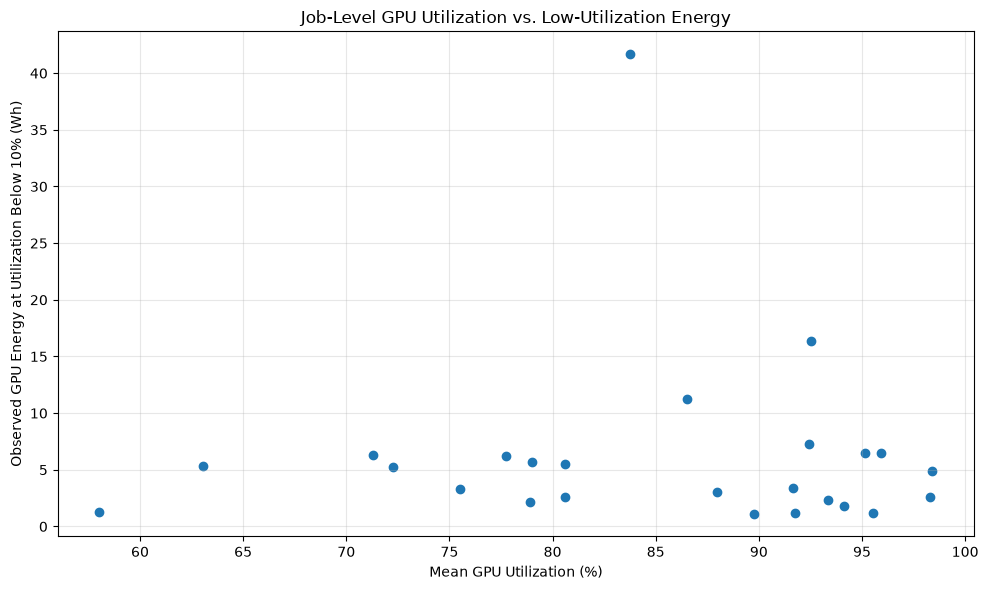

In [183]:
import matplotlib.pyplot as plt

plot_data = efficiency_analysis.dropna(
    subset=[
        "mean_gpu_utilization_pct",
        "low_util_observed_energy_Wh",
        "telemetry_coverage_status",
    ]
).copy()

# Exclude incomplete telemetry from the main comparison
complete_data = plot_data[
    plot_data["telemetry_coverage_status"]
    == "GPU allocation count matched"
]

plt.figure(figsize=(10, 6))
plt.scatter(
    complete_data["mean_gpu_utilization_pct"],
    complete_data["low_util_observed_energy_Wh"],
)

plt.xlabel("Mean GPU Utilization (%)")
plt.ylabel("Observed GPU Energy at Utilization Below 10% (Wh)")
plt.title("Job-Level GPU Utilization vs. Low-Utilization Energy")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [184]:
# Quantify relationships between job-level efficiency metrics

correlation_columns = [
    "mean_gpu_utilization_pct",
    "low_util_pct",
    "low_util_energy_pct",
    "observed_energy_Wh",
    "low_util_observed_energy_Wh",
]

correlation_data = complete_data[correlation_columns].copy()

spearman_corr = correlation_data.corr(method="spearman")

print("Spearman rank correlations (25 complete-telemetry jobs):")
display(spearman_corr.round(3))

print("\nRelationship with low-utilization energy:")
display(
    spearman_corr["low_util_observed_energy_Wh"]
    .drop("low_util_observed_energy_Wh")
    .sort_values(key=lambda s: s.abs(), ascending=False)
    .rename("spearman_correlation")
    .to_frame()
)

Spearman rank correlations (25 complete-telemetry jobs):


,mean_gpu_utilization_pct,low_util_pct,low_util_energy_pct,observed_energy_Wh,low_util_observed_energy_Wh
mean_gpu_utilization_pct,1.000,-0.474,-0.526,0.562,-0.042
low_util_pct,-0.474,1.000,0.967,-0.707,0.612
low_util_energy_pct,-0.526,0.967,1.000,-0.732,0.626
observed_energy_Wh,0.562,-0.707,-0.732,1.000,-0.035
low_util_observed_energy_Wh,-0.042,0.612,0.626,-0.035,1.000



Relationship with low-utilization energy:


,spearman_correlation
low_util_energy_pct,0.626154
low_util_pct,0.612308
mean_gpu_utilization_pct,-0.042308
observed_energy_Wh,-0.034615


In [185]:
# Inspect candidate investigation-score inputs

score_columns = [
    "mean_gpu_utilization_pct",
    "low_util_pct",
    "low_util_energy_pct",
    "observed_energy_Wh",
    "low_util_observed_energy_Wh",
]

score_profile = (
    complete_data[score_columns]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90])
    .T
    .round(3)
)

display(score_profile)

,count,mean,std,min,25%,50%,75%,90%,max
mean_gpu_utilization_pct,25.0,84.968,10.980,58.025,78.919,87.958,93.327,95.781,98.407
low_util_pct,25.0,3.244,4.235,0.159,0.560,1.611,3.859,7.323,16.317
low_util_energy_pct,25.0,0.985,1.293,0.043,0.125,0.575,1.212,1.830,4.942
observed_energy_Wh,25.0,1509.499,1346.372,66.879,452.066,1122.674,2121.948,3285.240,4964.583
low_util_observed_energy_Wh,25.0,6.191,8.151,1.140,2.330,4.900,6.283,9.673,41.666


In [186]:
# Provisional, distribution-based investigation flags
# Thresholds are derived from the 25 complete-telemetry jobs.

energy_threshold = complete_data["low_util_observed_energy_Wh"].quantile(0.90)
time_threshold = complete_data["low_util_pct"].quantile(0.90)
share_threshold = complete_data["low_util_energy_pct"].quantile(0.90)

scored_jobs = dashboard.copy()

scored_jobs["data_quality_review"] = (
    scored_jobs["telemetry_coverage_status"]
    != "GPU allocation count matched"
)

scored_jobs["high_low_util_energy"] = (
    scored_jobs["low_util_observed_energy_Wh"] >= energy_threshold
)

scored_jobs["high_low_util_time"] = (
    scored_jobs["low_util_pct"] >= time_threshold
)

scored_jobs["high_low_util_energy_share"] = (
    scored_jobs["low_util_energy_pct"] >= share_threshold
)

scored_jobs["investigation_signal_count"] = (
    scored_jobs[
        [
            "high_low_util_energy",
            "high_low_util_time",
            "high_low_util_energy_share",
        ]
    ]
    .sum(axis=1)
)

# Keep data-quality review separate from efficiency ranking
scored_jobs["provisional_review_status"] = "Routine review"
scored_jobs.loc[
    scored_jobs["investigation_signal_count"] >= 2,
    "provisional_review_status"
] = "Elevated investigation"
scored_jobs.loc[
    scored_jobs["investigation_signal_count"] == 3,
    "provisional_review_status"
] = "High investigation"
scored_jobs.loc[
    scored_jobs["data_quality_review"],
    "provisional_review_status"
] = "Data-quality review"

print("Pilot thresholds:")
print(f"Low-utilization energy: {energy_threshold:.3f} Wh")
print(f"Low-utilization observation share: {time_threshold:.3f}%")
print(f"Low-utilization energy share: {share_threshold:.3f}%")

print("\nProvisional review-status counts:")
display(
    scored_jobs["provisional_review_status"]
    .value_counts()
    .rename_axis("review_status")
    .reset_index(name="jobs")
)

print("\nJobs flagged for investigation:")
display(
    scored_jobs.loc[
        scored_jobs["investigation_signal_count"] > 0,
        [
            "job_id",
            "model",
            "workload_family",
            "low_util_pct",
            "low_util_energy_pct",
            "low_util_observed_energy_Wh",
            "investigation_signal_count",
            "provisional_review_status",
        ],
    ]
    .sort_values(
        ["investigation_signal_count", "low_util_observed_energy_Wh"],
        ascending=False,
    )
    .round(3)
)

Pilot thresholds:
Low-utilization energy: 9.673 Wh
Low-utilization observation share: 7.323%
Low-utilization energy share: 1.830%

Provisional review-status counts:


,review_status,jobs
0,Routine review,22
1,Elevated investigation,2
2,Data-quality review,1
3,High investigation,1



Jobs flagged for investigation:


,job_id,model,workload_family,low_util_pct,low_util_energy_pct,low_util_observed_energy_Wh,investigation_signal_count,provisional_review_status
2,25713459161743,U3-128,Vision,8.670,1.946,11.244,3,High investigation
0,29381280178268,U3-32,Vision,9.640,2.818,6.437,2,Data-quality review
1,48020198141948,U4-64,Vision,16.317,4.704,5.255,2,Elevated investigation
8,18242747496687,U5-32,Vision,14.745,4.942,3.305,2,Elevated investigation
9,55788973536832,resnet101,Vision,5.303,1.655,41.666,1,Routine review
5,59638293409445,U4-128,Vision,4.909,1.138,16.364,1,Routine review


In [187]:
# Revised pilot investigation logic
# Reuse thresholds and flags already calculated above.

scored_jobs["provisional_review_status_v2"] = "Routine review"

# High energy impact is sufficient for investigation
scored_jobs.loc[
    scored_jobs["high_low_util_energy"],
    "provisional_review_status_v2"
] = "Elevated investigation"

# Multiple independent threshold flags indicate higher priority
scored_jobs.loc[
    scored_jobs["investigation_signal_count"] >= 2,
    "provisional_review_status_v2"
] = "Elevated investigation"

scored_jobs.loc[
    scored_jobs["investigation_signal_count"] == 3,
    "provisional_review_status_v2"
] = "High investigation"

# Data quality takes precedence over efficiency ranking
scored_jobs.loc[
    scored_jobs["data_quality_review"],
    "provisional_review_status_v2"
] = "Data-quality review"

print("Revised pilot review-status counts:")
display(
    scored_jobs["provisional_review_status_v2"]
    .value_counts()
    .rename_axis("review_status")
    .reset_index(name="jobs")
)

print("\nRevised investigation queue:")
display(
    scored_jobs.loc[
        scored_jobs["provisional_review_status_v2"] != "Routine review",
        [
            "job_id",
            "model",
            "workload_family",
            "low_util_pct",
            "low_util_energy_pct",
            "low_util_observed_energy_Wh",
            "investigation_signal_count",
            "provisional_review_status_v2",
        ],
    ]
    .sort_values(
        ["provisional_review_status_v2", "low_util_observed_energy_Wh"],
        ascending=[True, False],
    )
    .round(3)
)

Revised pilot review-status counts:


,review_status,jobs
0,Routine review,20
1,Elevated investigation,4
2,Data-quality review,1
3,High investigation,1



Revised investigation queue:


,job_id,model,workload_family,low_util_pct,low_util_energy_pct,low_util_observed_energy_Wh,investigation_signal_count,provisional_review_status_v2
0,29381280178268,U3-32,Vision,9.640,2.818,6.437,2,Data-quality review
9,55788973536832,resnet101,Vision,5.303,1.655,41.666,1,Elevated investigation
5,59638293409445,U4-128,Vision,4.909,1.138,16.364,1,Elevated investigation
1,48020198141948,U4-64,Vision,16.317,4.704,5.255,2,Elevated investigation
8,18242747496687,U5-32,Vision,14.745,4.942,3.305,2,Elevated investigation
2,25713459161743,U3-128,Vision,8.670,1.946,11.244,3,High investigation


In [188]:
# Compare original investigation tiers with revised pilot statuses

tier_comparison = pd.crosstab(
    scored_jobs["investigation_tier"],
    scored_jobs["provisional_review_status_v2"],
    margins=True,
)

display(tier_comparison)

provisional_review_status_v2,Data-quality review,Elevated investigation,High investigation,Routine review,All
investigation_tier,,,,,
Data-quality review,1,0,0,0,1
Tier 1 - High investigation,0,2,1,4,7
Tier 2 - Investigate,0,2,0,12,14
Tier 3 - Monitor,0,0,0,4,4
All,1,4,1,20,26


In [189]:
# Measure energy concentration in the revised efficiency queue

efficiency_flagged = scored_jobs[
    (~scored_jobs["data_quality_review"])
    & (
        scored_jobs["provisional_review_status_v2"].isin(
            ["Elevated investigation", "High investigation"]
        )
    )
]

complete_jobs = scored_jobs[~scored_jobs["data_quality_review"]]

flagged_low_util_energy = (
    efficiency_flagged["low_util_observed_energy_Wh"].sum()
)

total_complete_low_util_energy = (
    complete_jobs["low_util_observed_energy_Wh"].sum()
)

energy_capture_pct = (
    flagged_low_util_energy / total_complete_low_util_energy * 100
    if total_complete_low_util_energy > 0 else float("nan")
)

print(f"Jobs flagged for efficiency investigation: {len(efficiency_flagged)}")
print(f"Observed low-utilization energy in flagged jobs: {flagged_low_util_energy:.3f} Wh")
print(f"Observed low-utilization energy across complete jobs: {total_complete_low_util_energy:.3f} Wh")
print(f"Share of complete-job low-utilization energy captured: {energy_capture_pct:.2f}%")

Jobs flagged for efficiency investigation: 5
Observed low-utilization energy in flagged jobs: 77.833 Wh
Observed low-utilization energy across complete jobs: 154.773 Wh
Share of complete-job low-utilization energy captured: 50.29%


In [190]:
# Export the revised investigation queue

output_columns = [
    "job_id",
    "model",
    "workload_family",
    "investigation_tier",
    "low_util_pct",
    "low_util_energy_pct",
    "observed_energy_Wh",
    "low_util_observed_energy_Wh",
    "data_quality_review",
    "high_low_util_energy",
    "high_low_util_time",
    "high_low_util_energy_share",
    "investigation_signal_count",
    "provisional_review_status_v2",
]

investigation_results = scored_jobs[output_columns].copy()

investigation_results = investigation_results.sort_values(
    ["provisional_review_status_v2", "low_util_observed_energy_Wh"],
    ascending=[True, False],
)

output_path = (
    processed_dir
    / "mit_supercloud_efficiency_investigation_v1.csv"
)

investigation_results.to_csv(output_path, index=False)

print(f"Saved: {output_path}")
print(f"Rows: {len(investigation_results)}")
print("Original dashboard dataset remains unchanged.")

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_efficiency_investigation_v1.csv
Rows: 26
Original dashboard dataset remains unchanged.


In [191]:
# Create an operator-friendly investigation summary

investigation_view = investigation_results.copy()

investigation_view["investigation_reason"] = investigation_view.apply(
    lambda row: (
        "Incomplete telemetry; validate before efficiency assessment"
        if row["data_quality_review"]
        else "; ".join(
            reason for condition, reason in [
                (
                    row["high_low_util_energy"],
                    "High absolute low-utilization energy"
                ),
                (
                    row["high_low_util_time"],
                    "Elevated low-utilization observation share"
                ),
                (
                    row["high_low_util_energy_share"],
                    "Elevated low-utilization energy share"
                ),
            ]
            if condition
        ) or "No pilot thresholds exceeded"
    ),
    axis=1
)

investigation_view = investigation_view[
    [
        "job_id",
        "model",
        "workload_family",
        "provisional_review_status_v2",
        "investigation_reason",
        "low_util_pct",
        "low_util_energy_pct",
        "observed_energy_Wh",
        "low_util_observed_energy_Wh",
        "investigation_signal_count",
    ]
].sort_values(
    ["provisional_review_status_v2", "low_util_observed_energy_Wh"],
    ascending=[True, False]
)

print("Investigation view:")
display(investigation_view.round(3).head(12))

Investigation view:


,job_id,model,workload_family,provisional_review_status_v2,investigation_reason,low_util_pct,low_util_energy_pct,observed_energy_Wh,low_util_observed_energy_Wh,investigation_signal_count
0,29381280178268,U3-32,Vision,Data-quality review,Incomplete telemetry; validate before efficien...,9.640,2.818,228.461,6.437,2
9,55788973536832,resnet101,Vision,Elevated investigation,High absolute low-utilization energy,5.303,1.655,2517.179,41.666,1
5,59638293409445,U4-128,Vision,Elevated investigation,High absolute low-utilization energy,4.909,1.138,1438.342,16.364,1
1,48020198141948,U4-64,Vision,Elevated investigation,Elevated low-utilization observation share; El...,16.317,4.704,111.709,5.255,2
8,18242747496687,U5-32,Vision,Elevated investigation,Elevated low-utilization observation share; El...,14.745,4.942,66.879,3.305,2
2,25713459161743,U3-128,Vision,High investigation,High absolute low-utilization energy; Elevated...,8.670,1.946,577.873,11.244,3
13,59030654331752,U5-128,Vision,Routine review,No pilot thresholds exceeded,2.686,0.658,1112.559,7.318,0
7,79150048009801,U5-64,Vision,Routine review,No pilot thresholds exceeded,0.860,0.213,3038.773,6.468,0
14,13063192210942,vgg16,Vision,Routine review,No pilot thresholds exceeded,2.152,0.575,1122.674,6.457,0
3,68307271431118,U4-32,Vision,Routine review,No pilot thresholds exceeded,3.859,1.390,452.066,6.283,0


In [192]:
# Save operator-friendly investigation view

investigation_view_path = (
    processed_dir / "mit_supercloud_operator_investigation_view_v1.csv"
)

investigation_view.to_csv(
    investigation_view_path,
    index=False
)

print(f"Saved: {investigation_view_path}")
print(f"Rows: {len(investigation_view)}")
print(
    "Flagged jobs:",
    investigation_view["provisional_review_status_v2"]
    .isin(["Elevated investigation", "High investigation"])
    .sum()
)
print(
    "Data-quality reviews:",
    investigation_view["provisional_review_status_v2"]
    .eq("Data-quality review")
    .sum()
)

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_operator_investigation_view_v1.csv
Rows: 26
Flagged jobs: 5
Data-quality reviews: 1


In [193]:
import pandas as pd

# Load the dataset currently used for the investigation table
source_path = processed_dir / "mit_supercloud_efficiency_investigation_v1.csv"
priority_data = pd.read_csv(source_path, dtype={"job_id": str})

# Assign a numeric sort order to each review status
priority_order = {
    "High investigation": 1,
    "Elevated investigation": 2,
    "Data-quality review": 3,
    "Routine review": 4,
}

priority_data["review_priority_sort"] = (
    priority_data["provisional_review_status_v2"]
    .map(priority_order)
)

# Validate before saving
print(priority_data[
    ["job_id", "provisional_review_status_v2", "review_priority_sort"]
].sort_values("review_priority_sort").head(10))

print("\nMissing priority values:", priority_data["review_priority_sort"].isna().sum())

# Save as a new version; preserve the original CSV
priority_path = processed_dir / "mit_supercloud_efficiency_investigation_v2.csv"
priority_data.to_csv(priority_path, index=False)

print(f"\nSaved: {priority_path}")

            job_id provisional_review_status_v2  review_priority_sort
5   25713459161743           High investigation                     1
1   55788973536832       Elevated investigation                     2
2   59638293409445       Elevated investigation                     2
3   48020198141948       Elevated investigation                     2
4   18242747496687       Elevated investigation                     2
0   29381280178268          Data-quality review                     3
23  38596192451856               Routine review                     4
22  36230628475012               Routine review                     4
21  80249445248004               Routine review                     4
20   9761351256032               Routine review                     4

Missing priority values: 0

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_efficiency_investigation_v2.csv


In [194]:
from pathlib import Path
import pandas as pd

project_root = Path.cwd().parent
processed_dir = project_root / "data" / "processed"

print("Project root:", project_root)
print("Processed directory exists:", processed_dir.exists())

print("\nRelevant analysis files:")
for path in sorted(processed_dir.glob("mit_supercloud*.csv")):
    print(f"{path.name} | {path.stat().st_size:,} bytes")

Project root: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence
Processed directory exists: True

Relevant analysis files:
mit_supercloud_consolidated_job_review_v1.csv | 12,137 bytes
mit_supercloud_dashboard_dataset_v1.csv | 16,169 bytes
mit_supercloud_dashboard_family_summary_v1.csv | 509 bytes
mit_supercloud_dashboard_investigation_queue_v1.csv | 5,144 bytes
mit_supercloud_dashboard_kpis_v1.csv | 256 bytes
mit_supercloud_efficiency_investigation_v1.csv | 4,653 bytes
mit_supercloud_efficiency_investigation_v2.csv | 4,726 bytes
mit_supercloud_gpu_energy_pilot_v1.csv | 11,669 bytes
mit_supercloud_gpu_kpis_pilot_v1.csv | 19,293 bytes
mit_supercloud_gpu_pilot_1s_all_files.csv | 153,874,763 bytes
mit_supercloud_gpu_pilot_1s_all_files_v2.csv | 181,008,563 bytes
mit_supercloud_job_analytics_pilot_v1.csv | 4,458 bytes
mit_supercloud_job_energy_pilot_v1.csv | 5,423 bytes
mit_supercloud_job_investigation_candidates_v1.csv | 4,531 bytes
mit_supercloud_job_opportunities_v1.csv 

In [195]:
files_to_inspect = [
    "mit_supercloud_workload_family_complete_jobs_v1.csv",
    "mit_supercloud_workload_family_gpu_kpis_v1.csv",
    "mit_supercloud_workload_family_job_kpis_v1.csv",
    "mit_supercloud_workload_family_summary_v1.csv",
    "mit_supercloud_optimization_screening_v3.csv",
]

for filename in files_to_inspect:
    path = processed_dir / filename

    df = pd.read_csv(path, dtype={"job_id": str})

    print(f"\n{'=' * 70}")
    print(f"FILE: {filename}")
    print(f"Shape: {df.shape}")
    print("Columns:", df.columns.tolist())
    print(df.head(3).to_string(index=False))


FILE: mit_supercloud_workload_family_complete_jobs_v1.csv
Shape: (3, 8)
Columns: ['workload_family', 'complete_jobs', 'mean_job_gpu_utilization_pct', 'mean_job_memory_utilization_pct', 'mean_job_gpu_temperature_C', 'mean_job_power_W', 'mean_observed_job_energy_kWh', 'median_observed_job_energy_kWh']
workload_family  complete_jobs  mean_job_gpu_utilization_pct  mean_job_memory_utilization_pct  mean_job_gpu_temperature_C  mean_job_power_W  mean_observed_job_energy_kWh  median_observed_job_energy_kWh
            GNN              4                     70.147411                        44.006634                   51.042495        136.342707                      1.805293                        1.060693
            NLP              2                     78.370157                         8.261422                   45.295638         63.862399                      0.492155                        0.492155
         Vision             19                     88.782404                        46.99480

In [196]:
import pandas as pd

screening_path = (
    processed_dir / "mit_supercloud_optimization_screening_v3.csv"
)

screening = pd.read_csv(
    screening_path,
    dtype={"job_id": str}
)

metrics = [
    "observed_energy_Wh",
    "mean_gpu_utilization_pct",
    "low_util_pct",
    "near_idle_pct",
    "high_util_pct",
    "total_sustained_low_util_seconds",
    "longest_sustained_low_util_seconds",
    "total_synchronized_seconds",
]

print("Dataset shape:", screening.shape)
print("Unique jobs:", screening["job_id"].nunique())

print("\nMissing values in selected metrics:")
print(screening[metrics].isna().sum())

print("\nJob-level distribution:")
print(
    screening[metrics]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90])
    .round(3)
    .to_string()
)

print("\nTelemetry coverage:")
print(screening["telemetry_coverage_status"].value_counts(dropna=False))

print("\nInvestigation tiers:")
print(screening["investigation_tier"].value_counts(dropna=False))

Dataset shape: (26, 27)
Unique jobs: 26

Missing values in selected metrics:
observed_energy_Wh                    0
mean_gpu_utilization_pct              0
low_util_pct                          0
near_idle_pct                         0
high_util_pct                         0
total_sustained_low_util_seconds      0
longest_sustained_low_util_seconds    0
total_synchronized_seconds            0
dtype: int64

Job-level distribution:
       observed_energy_Wh  mean_gpu_utilization_pct  low_util_pct  near_idle_pct  high_util_pct  total_sustained_low_util_seconds  longest_sustained_low_util_seconds  total_synchronized_seconds
count              26.000                    26.000        26.000         26.000         26.000                            26.000                              26.000                      26.000
mean             1460.228                    84.782         3.490          3.248         85.995                           292.538                             140.923            

In [197]:
import numpy as np
import pandas as pd

analysis = screening.copy()

# Separate data-quality review from performance screening
analysis["data_quality_review"] = (
    analysis["telemetry_coverage_status"]
    .str.contains("INCOMPLETE", case=False, na=False)
)

# Initial screening signals
metrics_to_screen = {
    "low_util_pct": "High low-utilization time",
    "total_sustained_low_util_seconds": "High sustained low-utilization duration",
    "total_synchronized_seconds": "High synchronized low-utilization duration",
    "observed_energy_Wh": "High observed GPU energy",
}

# Calculate IQR thresholds using allocation-matched jobs only
complete = analysis.loc[~analysis["data_quality_review"]].copy()
thresholds = {}

for column, description in metrics_to_screen.items():
    q1 = complete[column].quantile(0.25)
    q3 = complete[column].quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr

    thresholds[column] = upper_bound
    analysis[f"flag_{column}"] = analysis[column] > upper_bound

    print(
        f"{description}: upper IQR threshold = {upper_bound:.3f}"
    )

flag_columns = [f"flag_{column}" for column in metrics_to_screen]

analysis["outlier_signal_count"] = (
    analysis[flag_columns].sum(axis=1)
)

analysis["screening_result"] = np.select(
    [
        analysis["data_quality_review"],
        analysis["outlier_signal_count"] >= 2,
        analysis["outlier_signal_count"] == 1,
    ],
    [
        "Data-quality review",
        "Multiple statistical signals",
        "Single statistical signal",
    ],
    default="No IQR signal",
)

# Display only jobs with a data-quality issue or at least one signal
review_columns = [
    "job_id",
    "model",
    "workload_family",
    "screening_result",
    "outlier_signal_count",
    "low_util_pct",
    "total_sustained_low_util_seconds",
    "total_synchronized_seconds",
    "observed_energy_Wh",
]

candidates = analysis.loc[
    analysis["data_quality_review"]
    | (analysis["outlier_signal_count"] > 0),
    review_columns,
].sort_values(
    ["data_quality_review", "outlier_signal_count", "low_util_pct"],
    ascending=[False, False, False],
)

print("\nStatistical screening results:")
print(analysis["screening_result"].value_counts().to_string())

print("\nJobs requiring review:")
print(candidates.to_string(index=False))

High low-utilization time: upper IQR threshold = 8.807
High sustained low-utilization duration: upper IQR threshold = 791.000
High synchronized low-utilization duration: upper IQR threshold = 307.500
High observed GPU energy: upper IQR threshold = 4626.771


KeyError: 'data_quality_review'

In [198]:
# Include the data-quality flag in the displayed columns
review_columns = [
    "job_id",
    "model",
    "workload_family",
    "data_quality_review",
    "screening_result",
    "outlier_signal_count",
    "low_util_pct",
    "total_sustained_low_util_seconds",
    "total_synchronized_seconds",
    "observed_energy_Wh",
]

candidates = analysis.loc[
    analysis["data_quality_review"]
    | (analysis["outlier_signal_count"] > 0),
    review_columns,
].sort_values(
    ["data_quality_review", "outlier_signal_count", "low_util_pct"],
    ascending=[False, False, False],
)

print("Statistical screening results:")
print(analysis["screening_result"].value_counts().to_string())

print("\nJobs requiring review:")
print(candidates.to_string(index=False))

Statistical screening results:
screening_result
No IQR signal                20
Single statistical signal     5
Data-quality review           1

Jobs requiring review:
        job_id   model workload_family  data_quality_review          screening_result  outlier_signal_count  low_util_pct  total_sustained_low_util_seconds  total_synchronized_seconds  observed_energy_Wh
29381280178268   U3-32          Vision                 True       Data-quality review                     1      9.640057                             509.0                       244.0          228.461362
48020198141948   U4-64          Vision                False Single statistical signal                     1     16.317486                             386.0                         0.0          111.709414
18242747496687   U5-32          Vision                False Single statistical signal                     1     14.745146                             223.0                         0.0           66.879478
25713459161743  

In [199]:
# Show the thresholds used by the IQR screening
print("IQR upper thresholds:")
for metric, threshold in thresholds.items():
    print(f"{metric}: {threshold:.3f}")

# Show the individual flags for every candidate
flag_columns = [
    "flag_low_util_pct",
    "flag_total_sustained_low_util_seconds",
    "flag_total_synchronized_seconds",
    "flag_observed_energy_Wh",
]

candidate_ids = candidates["job_id"].tolist()

print("\nIndividual signal flags:")
print(
    analysis.loc[
        analysis["job_id"].isin(candidate_ids),
        ["job_id", "model", "workload_family"]
        + flag_columns
        + ["outlier_signal_count", "data_quality_review"],
    ]
    .sort_values("outlier_signal_count", ascending=False)
    .to_string(index=False)
)

IQR upper thresholds:
low_util_pct: 8.807
total_sustained_low_util_seconds: 791.000
total_synchronized_seconds: 307.500
observed_energy_Wh: 4626.771

Individual signal flags:
        job_id   model workload_family  flag_low_util_pct  flag_total_sustained_low_util_seconds  flag_total_synchronized_seconds  flag_observed_energy_Wh  outlier_signal_count  data_quality_review
25713459161743  U3-128          Vision              False                                   True                            False                    False                     1                False
48020198141948   U4-64          Vision               True                                  False                            False                    False                     1                False
59638293409445  U4-128          Vision              False                                   True                            False                    False                     1                False
18242747496687   U5-32          V

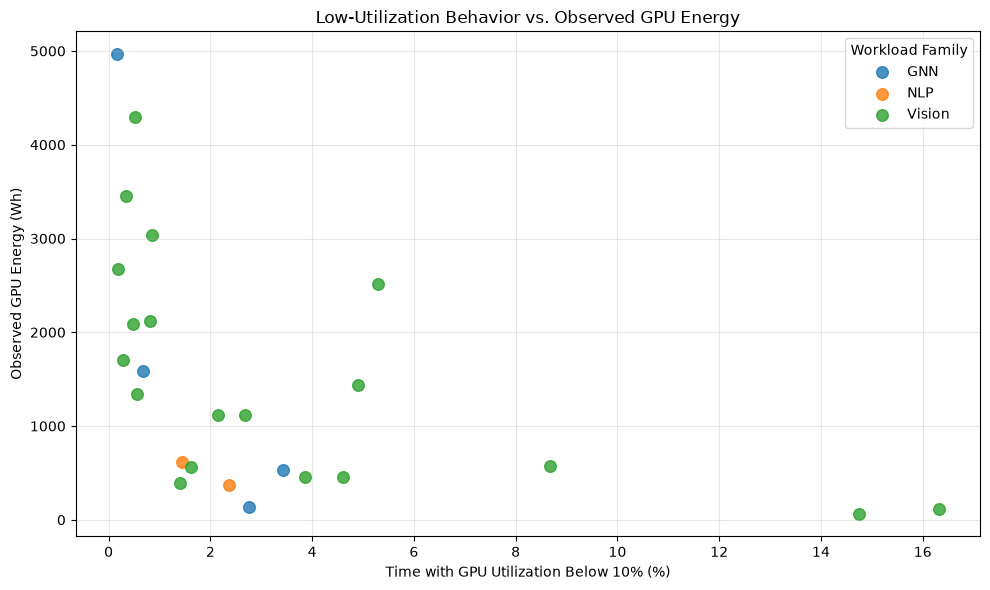

In [200]:
import matplotlib.pyplot as plt

plot_data = analysis.loc[
    ~analysis["data_quality_review"]
].copy()

plt.figure(figsize=(10, 6))

for family, group in plot_data.groupby("workload_family"):
    plt.scatter(
        group["low_util_pct"],
        group["observed_energy_Wh"],
        label=family,
        alpha=0.8,
        s=70,
    )

plt.xlabel("Time with GPU Utilization Below 10% (%)")
plt.ylabel("Observed GPU Energy (Wh)")
plt.title("Low-Utilization Behavior vs. Observed GPU Energy")
plt.legend(title="Workload Family")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [201]:
from scipy.stats import spearmanr

plot_data = analysis.loc[
    ~analysis["data_quality_review"]
].copy()

# Overall relationship
rho, p_value = spearmanr(
    plot_data["low_util_pct"],
    plot_data["observed_energy_Wh"],
)

print("Overall Spearman correlation")
print(f"rho: {rho:.3f}")
print(f"p-value: {p_value:.4f}")
print(f"Jobs: {len(plot_data)}")

# Workload-family relationships; interpret small groups cautiously
print("\nBy workload family:")
for family, group in plot_data.groupby("workload_family"):
    if len(group) < 5:
        print(f"{family}: only {len(group)} jobs; insufficient for a useful family-level correlation")
        continue

    rho_family, p_family = spearmanr(
        group["low_util_pct"],
        group["observed_energy_Wh"],
    )

    print(
        f"{family}: rho={rho_family:.3f}, "
        f"p-value={p_family:.4f}, n={len(group)}"
    )

Overall Spearman correlation
rho: -0.707
p-value: 0.0001
Jobs: 25

By workload family:
GNN: only 4 jobs; insufficient for a useful family-level correlation
NLP: only 2 jobs; insufficient for a useful family-level correlation
Vision: rho=-0.670, p-value=0.0017, n=19


In [202]:
job_analytics = pd.read_csv(
    processed_dir / "mit_supercloud_job_analytics_pilot_v1.csv",
    dtype={"job_id": str},
)

print("Shape:", job_analytics.shape)
print("\nColumns:")
print(job_analytics.columns.tolist())

print("\nSample rows:")
print(job_analytics.head(5).to_string(index=False))

Shape: (26, 12)

Columns:
['job_id', 'model', 'workload_family', 'job_mean_gpu_utilization_pct', 'job_mean_memory_utilization_pct', 'job_mean_gpu_temperature_C', 'job_peak_gpu_temperature_C', 'job_mean_power_W', 'observed_gpu_count', 'total_observed_gpu_seconds', 'observed_energy_kWh', 'telemetry_coverage_status']

Sample rows:
        job_id                   model workload_family  job_mean_gpu_utilization_pct  job_mean_memory_utilization_pct  job_mean_gpu_temperature_C  job_peak_gpu_temperature_C  job_mean_power_W  observed_gpu_count  total_observed_gpu_seconds  observed_energy_kWh    telemetry_coverage_status
 2304959634945 distilbert-base-uncased             NLP                     79.013975                         8.241680                   48.638075                          50         64.799299                   2                       20514             0.369248 GPU allocation count matched
 8427789164283       bert-base-uncased             NLP                     77.726340      

In [203]:
import numpy as np
import pandas as pd

job_analytics = job_analytics.copy()

# Convert observed GPU-seconds to GPU-hours
job_analytics["observed_gpu_hours"] = (
    job_analytics["total_observed_gpu_seconds"] / 3600
)

# Energy per observed GPU-hour
job_analytics["energy_per_gpu_hour_kWh"] = (
    job_analytics["observed_energy_kWh"]
    / job_analytics["observed_gpu_hours"]
)

# Cross-check average power against energy and observed GPU time.
# kWh / hours = average kW; multiply by 1000 for watts.
job_analytics["implied_mean_power_W"] = (
    job_analytics["observed_energy_kWh"]
    / (job_analytics["total_observed_gpu_seconds"] / 3600)
    * 1000
)

# Compare reported mean power with the energy-derived value
job_analytics["power_difference_pct"] = (
    (
        job_analytics["job_mean_power_W"]
        - job_analytics["implied_mean_power_W"]
    )
    / job_analytics["implied_mean_power_W"].replace(0, np.nan)
    * 100
)

print("Normalized metrics preview:")
print(
    job_analytics[
        [
            "job_id",
            "model",
            "observed_gpu_count",
            "total_observed_gpu_seconds",
            "observed_energy_kWh",
            "job_mean_power_W",
            "energy_per_gpu_hour_kWh",
            "implied_mean_power_W",
            "power_difference_pct",
        ]
    ]
    .head(10)
    .round(3)
    .to_string(index=False)
)

print("\nSummary:")
print(
    job_analytics[
        [
            "energy_per_gpu_hour_kWh",
            "job_mean_power_W",
            "implied_mean_power_W",
            "power_difference_pct",
        ]
    ]
    .describe()
    .round(3)
    .to_string()
)

Normalized metrics preview:
        job_id                   model  observed_gpu_count  total_observed_gpu_seconds  observed_energy_kWh  job_mean_power_W  energy_per_gpu_hour_kWh  implied_mean_power_W  power_difference_pct
 2304959634945 distilbert-base-uncased                   2                       20514                0.369            64.799                    0.065                64.799                   0.0
 8427789164283       bert-base-uncased                   2                       35188                0.615            62.925                    0.063                62.925                   0.0
 9761351256032                 dimenet                   2                      126672                4.965           141.093                    0.141               141.093                   0.0
13063192210942                   vgg16                   8                       32440                1.123           124.588                    0.125               124.588                  -0

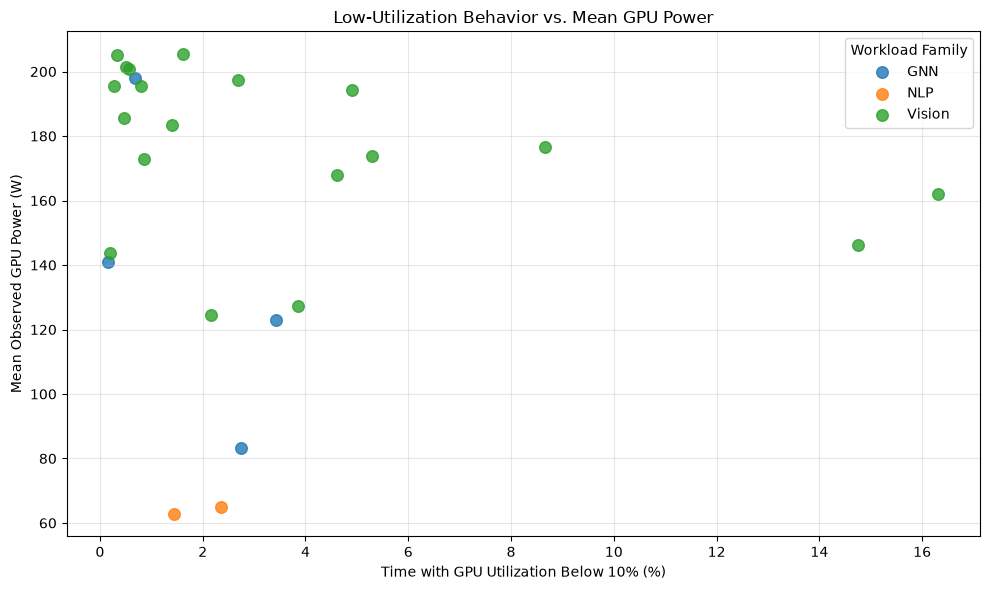

Spearman correlation: -0.321
p-value: 0.1180
Complete jobs: 25


In [204]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# Join job-level analytics with low-utilization metrics
utilization_metrics = analysis[
    [
        "job_id",
        "low_util_pct",
        "data_quality_review",
    ]
].copy()

normalized_analysis = job_analytics.merge(
    utilization_metrics,
    on="job_id",
    how="left",
    validate="one_to_one",
)

# Exclude incomplete telemetry from the primary comparison
complete = normalized_analysis.loc[
    ~normalized_analysis["data_quality_review"]
].copy()

# Plot low-utilization time against average observed GPU power
plt.figure(figsize=(10, 6))

for family, group in complete.groupby("workload_family"):
    plt.scatter(
        group["low_util_pct"],
        group["job_mean_power_W"],
        label=family,
        alpha=0.8,
        s=70,
    )

plt.xlabel("Time with GPU Utilization Below 10% (%)")
plt.ylabel("Mean Observed GPU Power (W)")
plt.title("Low-Utilization Behavior vs. Mean GPU Power")
plt.legend(title="Workload Family")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

rho, p_value = spearmanr(
    complete["low_util_pct"],
    complete["job_mean_power_W"],
)

print(f"Spearman correlation: {rho:.3f}")
print(f"p-value: {p_value:.4f}")
print(f"Complete jobs: {len(complete)}")

In [205]:
episodes_path = (
    processed_dir / "mit_supercloud_sustained_low_util_episodes_v1.csv"
)

episodes = pd.read_csv(
    episodes_path,
    dtype={"job_id": str},
)

print("Shape:", episodes.shape)
print("\nColumns:")
print(episodes.columns.tolist())

print("\nFirst five episodes:")
print(episodes.head().to_string(index=False))

Shape: (62, 15)

Columns:
['job_id', 'rack_node_id', 'gpu_index', 'model', 'workload_family', 'episode_id', 'start_time', 'end_time', 'observations', 'mean_utilization_pct', 'mean_power_W', 'median_power_W', 'max_power_W', 'duration_s', 'duration_min']

First five episodes:
        job_id     rack_node_id  gpu_index  model workload_family  episode_id                start_time                  end_time  observations  mean_utilization_pct  mean_power_W  median_power_W  max_power_W  duration_s  duration_min
48020198141948 r9352821-n830961          0  U4-64          Vision           1 2021-05-10 21:32:56+00:00 2021-05-10 21:39:21+00:00           386              0.032873     46.215866       46.185278    46.557000         386      6.433333
59638293409445 r9352821-n830961          0 U4-128          Vision           1 2021-05-11 13:51:54+00:00 2021-05-11 13:56:49+00:00           296              0.034647     49.274119       48.570944    60.322222         296      4.933333
59638293409445 r3117

In [206]:
# Summarize sustained low-utilization episodes by job
episode_summary = (
    episodes.groupby(
        ["job_id", "model", "workload_family"],
        as_index=False,
    )
    .agg(
        episode_count=("episode_id", "count"),
        total_episode_gpu_seconds=("duration_s", "sum"),
        longest_episode_s=("duration_s", "max"),
        mean_episode_duration_s=("duration_s", "mean"),
        mean_episode_utilization_pct=("mean_utilization_pct", "mean"),
        mean_episode_power_W=("mean_power_W", "mean"),
        median_episode_power_W=("median_power_W", "mean"),
    )
)

# Add existing job-level investigation results
episode_summary = episode_summary.merge(
    analysis[
        [
            "job_id",
            "low_util_pct",
            "observed_energy_Wh",
            "investigation_tier",
        ]
    ],
    on="job_id",
    how="left",
    validate="one_to_one",
)

episode_summary = episode_summary.sort_values(
    ["longest_episode_s", "total_episode_gpu_seconds"],
    ascending=False,
)

print("Episode summary shape:", episode_summary.shape)
print("\nLongest sustained episodes by job:")
print(episode_summary.head(15).round(3).to_string(index=False))

Episode summary shape: (24, 13)

Longest sustained episodes by job:
        job_id      model workload_family  episode_count  total_episode_gpu_seconds  longest_episode_s  mean_episode_duration_s  mean_episode_utilization_pct  mean_episode_power_W  median_episode_power_W  low_util_pct  observed_energy_Wh          investigation_tier
48020198141948      U4-64          Vision              1                        386                386                  386.000                         0.033                46.216                  46.185        16.317             111.709 Tier 1 - High investigation
59638293409445     U4-128          Vision              4                       1160                296                  290.000                         0.047                44.230                  43.676         4.909            1438.342 Tier 1 - High investigation
29381280178268      U3-32          Vision              2                        509                265                  254.500       

In [207]:
from pathlib import Path
import pandas as pd

project_root = Path.cwd().parent
processed_dir = project_root / "data" / "processed"

telemetry_path = processed_dir / "mit_supercloud_gpu_pilot_1s_all_files_v2.csv"

print("File exists:", telemetry_path.exists())

telemetry = pd.read_csv(
    telemetry_path,
    dtype={"job_id": str},
    nrows=5
)

print("\nColumns:")
print(telemetry.columns.tolist())

print("\nSample rows:")
display(telemetry)

File exists: True

Columns:
['job_id', 'source_filename', 'rack_node_id', 'rack_id', 'node_number', 'model', 'workload_family', 'gpu_index', 'timestamp_1s', 'utilization_gpu_pct', 'utilization_memory_pct', 'memory_used_MiB', 'memory_free_MiB', 'temperature_gpu_avg', 'temperature_gpu_max', 'temperature_memory_avg', 'power_draw_W', 'pcie_link_width_current', 'raw_observation_count', 'clocks_current_memory_MHz', 'clocks_current_sm_MHz', 'clocks_current_video_MHz', 'power_limit_W']

Sample rows:


,job_id,source_filename,rack_node_id,rack_id,node_number,model,workload_family,gpu_index,timestamp_1s,utilization_gpu_pct,...,temperature_gpu_avg,temperature_gpu_max,temperature_memory_avg,power_draw_W,pcie_link_width_current,raw_observation_count,clocks_current_memory_MHz,clocks_current_sm_MHz,clocks_current_video_MHz,power_limit_W
0,59638293409445,59638293409445-r3117156-n136082.csv,r3117156-n136082,r3117156,136082,U4-128,Vision,0,2021-05-11 13:51:54+00:00,0.0,...,61.200000,62,61.0,53.430000,16.0,5,NaN,NaN,NaN,NaN
1,59638293409445,59638293409445-r3117156-n136082.csv,r3117156-n136082,r3117156,136082,U4-128,Vision,0,2021-05-11 13:51:55+00:00,0.0,...,61.000000,61,60.7,53.251000,16.0,10,NaN,NaN,NaN,NaN
2,59638293409445,59638293409445-r3117156-n136082.csv,r3117156-n136082,r3117156,136082,U4-128,Vision,0,2021-05-11 13:51:56+00:00,0.0,...,61.000000,61,60.0,53.120000,16.0,9,NaN,NaN,NaN,NaN
3,59638293409445,59638293409445-r3117156-n136082.csv,r3117156-n136082,r3117156,136082,U4-128,Vision,0,2021-05-11 13:51:57+00:00,0.0,...,60.888889,61,60.0,52.904444,16.0,9,NaN,NaN,NaN,NaN
4,59638293409445,59638293409445-r3117156-n136082.csv,r3117156-n136082,r3117156,136082,U4-128,Vision,0,2021-05-11 13:51:58+00:00,0.0,...,60.100000,61,59.9,52.765000,16.0,10,NaN,NaN,NaN,NaN


In [208]:
# Inspect the sustained low-utilization episode for U4-64
target_job_id = "48020198141948"

episode_u4_64 = episodes.loc[
    episodes["job_id"].astype(str) == target_job_id
].copy()

print("Episode records:")
print(
    episode_u4_64[
        [
            "job_id",
            "rack_node_id",
            "gpu_index",
            "start_time",
            "end_time",
            "duration_s",
            "mean_utilization_pct",
            "mean_power_W",
        ]
    ].to_string(index=False)
)

Episode records:
        job_id     rack_node_id  gpu_index                start_time                  end_time  duration_s  mean_utilization_pct  mean_power_W
48020198141948 r9352821-n830961          0 2021-05-10 21:32:56+00:00 2021-05-10 21:39:21+00:00         386              0.032873     46.215866


In [209]:
# Parse the episode timestamps
episode_start = pd.to_datetime(
    episode_u4_64.iloc[0]["start_time"], utc=True
)
episode_end = pd.to_datetime(
    episode_u4_64.iloc[0]["end_time"], utc=True
)

# Read only the target job's telemetry
u4_64 = pd.read_csv(
    telemetry_path,
    dtype={"job_id": str},
)

u4_64["timestamp_1s"] = pd.to_datetime(
    u4_64["timestamp_1s"], utc=True
)

# Isolate the affected GPU and episode window
u4_64_window = u4_64.loc[
    (u4_64["job_id"] == target_job_id)
    & (u4_64["rack_node_id"] == episode_u4_64.iloc[0]["rack_node_id"])
    & (u4_64["gpu_index"] == episode_u4_64.iloc[0]["gpu_index"])
    & (u4_64["timestamp_1s"] >= episode_start)
    & (u4_64["timestamp_1s"] <= episode_end)
].copy()

print("Rows in episode window:", len(u4_64_window))
print("\nUtilization and power summary:")
print(
    u4_64_window[
        ["utilization_gpu_pct", "power_draw_W", "temperature_gpu_avg"]
    ].describe().round(3).to_string()
)

print("\nFirst 5 rows:")
print(
    u4_64_window[
        ["timestamp_1s", "utilization_gpu_pct", "power_draw_W"]
    ].head().to_string(index=False)
)

print("\nLast 5 rows:")
print(
    u4_64_window[
        ["timestamp_1s", "utilization_gpu_pct", "power_draw_W"]
    ].tail().to_string(index=False)
)

Rows in episode window: 386

Utilization and power summary:
       utilization_gpu_pct  power_draw_W  temperature_gpu_avg
count              386.000       386.000              386.000
mean                 0.033        46.216               39.641
std                  0.369         0.113                0.431
min                  0.000        45.999               39.000
25%                  0.000        46.126               39.100
50%                  0.000        46.185               40.000
75%                  0.000        46.309               40.000
max                  6.600        46.557               40.000

First 5 rows:
             timestamp_1s  utilization_gpu_pct  power_draw_W
2021-05-10 21:32:56+00:00                  0.0     46.330000
2021-05-10 21:32:57+00:00                  0.0     46.373000
2021-05-10 21:32:58+00:00                  0.0     46.414444
2021-05-10 21:32:59+00:00                  0.0     46.410000
2021-05-10 21:33:00+00:00                  0.0     46.352222



In [210]:
# Examine every GPU belonging to this job during GPU 0's episode
u4_64_all_gpus = u4_64.loc[
    (u4_64["job_id"] == target_job_id)
    & (u4_64["timestamp_1s"] >= episode_start)
    & (u4_64["timestamp_1s"] <= episode_end)
].copy()

# Summarize each GPU/node over the same time window
gpu_window_summary = (
    u4_64_all_gpus
    .groupby(["rack_node_id", "gpu_index"])
    .agg(
        observations=("timestamp_1s", "count"),
        mean_utilization_pct=("utilization_gpu_pct", "mean"),
        pct_seconds_below_10=(
            "utilization_gpu_pct",
            lambda s: (s < 10).mean() * 100
        ),
        mean_power_W=("power_draw_W", "mean"),
        median_power_W=("power_draw_W", "median"),
    )
    .reset_index()
    .sort_values(["rack_node_id", "gpu_index"])
)

print("Unique nodes:", u4_64_all_gpus["rack_node_id"].nunique())
print("Unique GPUs:", u4_64_all_gpus[["rack_node_id", "gpu_index"]].drop_duplicates().shape[0])
print("\nGPU-level summary for the shared episode window:")
print(gpu_window_summary.round(3).to_string(index=False))

Unique nodes: 1
Unique GPUs: 1

GPU-level summary for the shared episode window:
    rack_node_id  gpu_index  observations  mean_utilization_pct  pct_seconds_below_10  mean_power_W  median_power_W
r9352821-n830961          0           386                 0.033                 100.0        46.216          46.185


In [211]:
u4_64_coverage = (
    u4_64.loc[u4_64["job_id"] == target_job_id]
    .groupby(["rack_node_id", "gpu_index"])
    .agg(
        observations=("timestamp_1s", "count"),
        first_timestamp=("timestamp_1s", "min"),
        last_timestamp=("timestamp_1s", "max"),
        mean_utilization_pct=("utilization_gpu_pct", "mean"),
        mean_power_W=("power_draw_W", "mean"),
    )
    .reset_index()
    .sort_values(["rack_node_id", "gpu_index"])
)

print("Total telemetry rows for U4-64:", len(u4_64.loc[u4_64["job_id"] == target_job_id]))
print("Unique nodes:", u4_64_coverage["rack_node_id"].nunique())
print("Unique node/GPU pairs:", len(u4_64_coverage))
print("\nFull-job telemetry coverage:")
print(u4_64_coverage.round(3).to_string(index=False))

Total telemetry rows for U4-64: 2482
Unique nodes: 1
Unique node/GPU pairs: 1

Full-job telemetry coverage:
    rack_node_id  gpu_index  observations           first_timestamp            last_timestamp  mean_utilization_pct  mean_power_W
r9352821-n830961          0          2482 2021-05-10 21:32:56+00:00 2021-05-10 22:14:17+00:00                 72.25       162.028


/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/3998973531.py:19: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(u4_64_coverage.round(3).to_string(index=False))


In [212]:
# Count distinct nodes and GPUs for each job in the telemetry already loaded
job_gpu_coverage = (
    u4_64.drop_duplicates(["job_id", "rack_node_id", "gpu_index"])
    .groupby("job_id")
    .agg(
        unique_nodes=("rack_node_id", "nunique"),
        unique_gpus=("gpu_index", "nunique"),
        node_gpu_pairs=("gpu_index", "size"),
    )
    .reset_index()
)

# Note: unique_gpus counts GPU indices, while node_gpu_pairs counts
# distinct node/GPU combinations. Use node_gpu_pairs to identify
# jobs with telemetry from multiple GPUs.
print("Jobs in currently loaded telemetry:", len(job_gpu_coverage))
print("\nJobs with telemetry from multiple node/GPU pairs:")
print(
    job_gpu_coverage.loc[job_gpu_coverage["node_gpu_pairs"] > 1]
    .sort_values("node_gpu_pairs", ascending=False)
    .head(10)
    .to_string(index=False)
)

Jobs in currently loaded telemetry: 26

Jobs with telemetry from multiple node/GPU pairs:
        job_id  unique_nodes  unique_gpus  node_gpu_pairs
13063192210942             4            2               8
80249445248004             2            2               4
25713459161743             2            2               4
38596192451856             2            2               4
44317307973280             2            2               4
59638293409445             2            2               4
55788973536832             2            2               4
59464190077432             1            2               2
 8427789164283             1            2               2
79150048009801             1            2               2


In [213]:
target_job_id = "25713459161743"

episode_u3_128 = episodes.loc[
    episodes["job_id"].astype(str) == target_job_id
].copy()

print("Episode count:", len(episode_u3_128))
print("\nEpisode records:")
print(
    episode_u3_128[
        [
            "job_id",
            "rack_node_id",
            "gpu_index",
            "start_time",
            "end_time",
            "duration_s",
            "mean_utilization_pct",
            "mean_power_W",
        ]
    ]
    .sort_values(["start_time", "rack_node_id", "gpu_index"])
    .to_string(index=False)
)

Episode count: 6

Episode records:
        job_id     rack_node_id  gpu_index                start_time                  end_time  duration_s  mean_utilization_pct  mean_power_W
25713459161743 r4858666-n976057          0 2021-05-28 16:01:39+00:00 2021-05-28 16:03:54+00:00         136              0.100000     38.940893
25713459161743 r4858666-n976057          1 2021-05-28 16:01:39+00:00 2021-05-28 16:04:00+00:00         142              0.096322     37.183556
25713459161743 r9352821-n830961          0 2021-05-28 16:01:39+00:00 2021-05-28 16:05:41+00:00         243              0.036443     40.356386
25713459161743 r9352821-n830961          1 2021-05-28 16:01:39+00:00 2021-05-28 16:05:44+00:00         246              0.050090     39.352131
25713459161743 r4858666-n976057          0 2021-05-28 16:03:59+00:00 2021-05-28 16:05:47+00:00         109              0.040979     39.088102
25713459161743 r4858666-n976057          1 2021-05-28 16:04:05+00:00 2021-05-28 16:05:47+00:00         103 

In [214]:
target_job_id = "25713459161743"

# Define the shared window spanning all six episodes
episode_start = pd.to_datetime(
    episode_u3_128["start_time"], utc=True
).min()

episode_end = pd.to_datetime(
    episode_u3_128["end_time"], utc=True
).max()

u3_128_window = u4_64.loc[
    (u4_64["job_id"] == target_job_id)
    & (u4_64["timestamp_1s"] >= episode_start)
    & (u4_64["timestamp_1s"] <= episode_end)
].copy()

# Summarize utilization by node/GPU at each second
gpu_util = (
    u3_128_window
    .pivot_table(
        index="timestamp_1s",
        columns=["rack_node_id", "gpu_index"],
        values="utilization_gpu_pct",
        aggfunc="mean",
    )
    .sort_index()
)

# Measure the fraction of timestamps where each GPU is below 10%
low_util = gpu_util < 10

print("Window:", episode_start, "to", episode_end)
print("Telemetry rows:", len(u3_128_window))
print("GPU/node combinations:", gpu_util.shape[1])
print("\nPer-GPU low-utilization coverage (% of shared timestamps):")
print((low_util.mean() * 100).round(2).to_string())

print("\nNumber of GPUs below 10% utilization at each timestamp:")
print(low_util.sum(axis=1).value_counts().sort_index().to_string())

print("\nShare of timestamps where all observed GPUs are below 10%:")
print(round((low_util.all(axis=1).mean() * 100), 2), "%")

Window: 2021-05-28 16:01:39+00:00 to 2021-05-28 16:05:47+00:00
Telemetry rows: 996
GPU/node combinations: 4

Per-GPU low-utilization coverage (% of shared timestamps):
rack_node_id      gpu_index
r4858666-n976057  0            98.39
                  1            98.39
r9352821-n830961  0            97.99
                  1            98.80

Number of GPUs below 10% utilization at each timestamp:
2      2
3     12
4    235

Share of timestamps where all observed GPUs are below 10%:
94.38 %


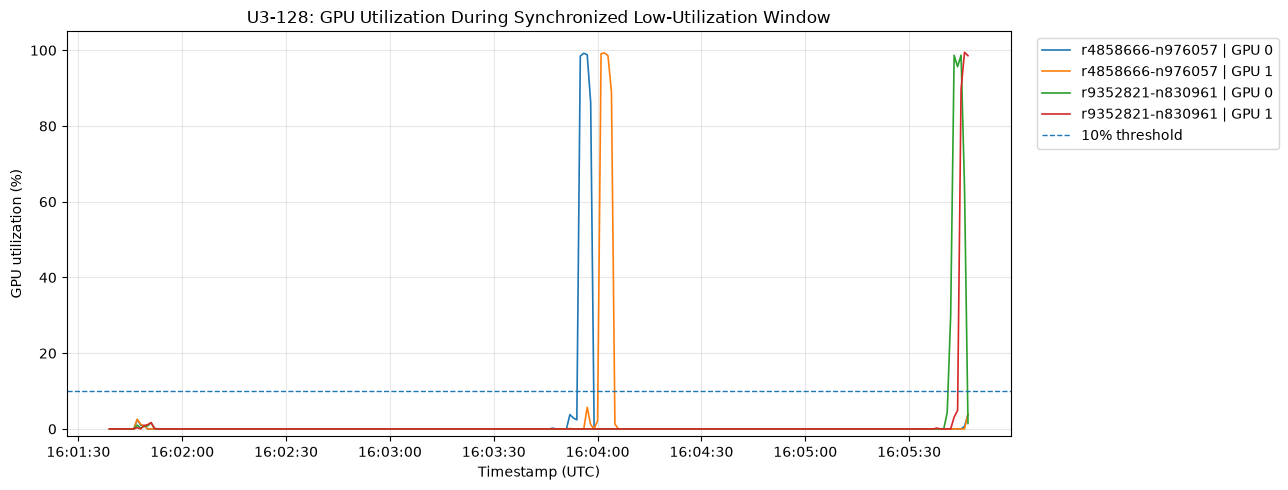

In [215]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(13, 5))

for (node, gpu), series in gpu_util.items():
    label = f"{node} | GPU {gpu}"
    ax.plot(
        series.index,
        series.values,
        label=label,
        linewidth=1.2,
    )

ax.axhline(10, linestyle="--", linewidth=1, label="10% threshold")
ax.set_title("U3-128: GPU Utilization During Synchronized Low-Utilization Window")
ax.set_xlabel("Timestamp (UTC)")
ax.set_ylabel("GPU utilization (%)")
ax.set_ylim(-2, 105)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [216]:
# Quantify activity states for each GPU/node in the shared window
activity_summary = (
    gpu_util
    .apply(
        lambda s: pd.Series({
            "observations": s.notna().sum(),
            "low_util_seconds_lt10": (s < 10).sum(),
            "active_seconds_ge10": (s >= 10).sum(),
            "high_util_seconds_ge80": (s >= 80).sum(),
            "peak_utilization_pct": s.max(),
        })
    )
    .T
    .reset_index()
)

activity_summary.columns = [
    "rack_node_id",
    "gpu_index",
    "observations",
    "low_util_seconds_lt10",
    "active_seconds_ge10",
    "high_util_seconds_ge80",
    "peak_utilization_pct",
]

print(activity_summary.round(2).to_string(index=False))

    rack_node_id  gpu_index  observations  low_util_seconds_lt10  active_seconds_ge10  high_util_seconds_ge80  peak_utilization_pct
r4858666-n976057          0         249.0                  245.0                  4.0                     4.0                 99.22
r4858666-n976057          1         249.0                  245.0                  4.0                     4.0                 99.30
r9352821-n830961          0         249.0                  244.0                  5.0                     3.0                 98.70
r9352821-n830961          1         249.0                  246.0                  3.0                     3.0                 99.44


In [217]:
# Only evaluate timestamps where all four GPU/node series have observations
complete_gpu_util = gpu_util.dropna(how="any")

# Boolean state: True when GPU utilization is below 10%
low_util_state = complete_gpu_util < 10

# Per-timestamp number of GPUs below the threshold
low_gpu_count = low_util_state.sum(axis=1)

total_seconds = len(low_util_state)
all_four_low_seconds = int((low_gpu_count == 4).sum())
at_least_three_low_seconds = int((low_gpu_count >= 3).sum())

sync_summary = pd.Series({
    "complete_timestamps": total_seconds,
    "all_four_below_10_seconds": all_four_low_seconds,
    "all_four_below_10_pct": 100 * all_four_low_seconds / total_seconds,
    "at_least_three_below_10_seconds": at_least_three_low_seconds,
    "at_least_three_below_10_pct": 100 * at_least_three_low_seconds / total_seconds,
    "mean_gpus_below_10": low_gpu_count.mean(),
})

print(sync_summary.round(2).to_string())

complete_timestamps                249.00
all_four_below_10_seconds          235.00
all_four_below_10_pct               94.38
at_least_three_below_10_seconds    247.00
at_least_three_below_10_pct         99.20
mean_gpus_below_10                   3.94


In [218]:
def calculate_synchronized_low_utilization(
    gpu_utilization: pd.DataFrame,
    threshold_pct: float = 10.0,
) -> dict:
    """
    Calculate synchronized low-utilization metrics for a shared
    time window across observed GPU/node combinations.

    Input:
        DataFrame indexed by timestamp, with one column per GPU/node pair.
        Values are GPU utilization percentages (0-100).

    Returns:
        Descriptive synchronization metrics; not an energy-savings estimate.
    """
    complete = gpu_utilization.dropna(how="any")

    if complete.empty or complete.shape[1] == 0:
        return {
            "gpu_node_pairs": gpu_utilization.shape[1],
            "complete_timestamps": 0,
            "sync_low_util_pct": float("nan"),
            "at_least_three_low_pct": float("nan"),
            "mean_gpus_below_threshold": float("nan"),
        }

    low_state = complete < threshold_pct
    low_count = low_state.sum(axis=1)
    n_gpus = complete.shape[1]

    return {
        "gpu_node_pairs": n_gpus,
        "complete_timestamps": len(complete),
        "sync_low_util_pct": 100 * (low_count == n_gpus).mean(),
        "at_least_three_low_pct": (
            100 * (low_count >= min(3, n_gpus)).mean()
        ),
        "mean_gpus_below_threshold": low_count.mean(),
        "threshold_pct": threshold_pct,
    }


# Validate against the U3-128 result already calculated
u3_128_sync = calculate_synchronized_low_utilization(gpu_util)

print("U3-128 synchronization metrics:")
for metric, value in u3_128_sync.items():
    print(f"{metric}: {value:.2f}" if isinstance(value, (int, float)) else f"{metric}: {value}")

U3-128 synchronization metrics:
gpu_node_pairs: 4.00
complete_timestamps: 249.00
sync_low_util_pct: 94.38
at_least_three_low_pct: 99.20
mean_gpus_below_threshold: 3.94
threshold_pct: 10.00


In [219]:
# Count telemetry observations and distinct node/GPU pairs for each job
job_coverage = (
    u4_64.groupby("job_id")
    .agg(
        telemetry_rows=("timestamp_1s", "count"),
        first_timestamp=("timestamp_1s", "min"),
        last_timestamp=("timestamp_1s", "max"),
        unique_nodes=("rack_node_id", "nunique"),
    )
    .reset_index()
)

gpu_pairs = (
    u4_64[["job_id", "rack_node_id", "gpu_index"]]
    .drop_duplicates()
    .groupby("job_id")
    .size()
    .rename("node_gpu_pairs")
    .reset_index()
)

job_coverage = job_coverage.merge(gpu_pairs, on="job_id", how="left")

print("Jobs in pilot:", len(job_coverage))
print("\nCoverage summary:")
print(
    job_coverage[
        ["telemetry_rows", "unique_nodes", "node_gpu_pairs"]
    ].describe().round(2).to_string()
)

print("\nJobs with multiple observed node/GPU pairs:")
print(
    job_coverage.loc[job_coverage["node_gpu_pairs"] > 1]
    .sort_values("node_gpu_pairs", ascending=False)
    .to_string(index=False)
)

Jobs in pilot: 26

Coverage summary:
       telemetry_rows  unique_nodes  node_gpu_pairs
count           26.00         26.00           26.00
mean         31866.58          1.35            2.46
std          28771.12          0.69            1.56
min           1648.00          1.00            1.00
25%          10396.00          1.00            2.00
50%          25382.00          1.00            2.00
75%          40155.75          1.75            3.50
max         126672.00          4.00            8.00

Jobs with multiple observed node/GPU pairs:
        job_id  telemetry_rows           first_timestamp            last_timestamp  unique_nodes  node_gpu_pairs
13063192210942           32440 2021-09-25 16:16:08+00:00 2021-09-25 17:23:42+00:00             4               8
80249445248004           67004 2021-06-07 09:38:38+00:00 2021-06-07 14:17:48+00:00             2               4
25713459161743           11788 2021-05-28 16:01:39+00:00 2021-05-28 16:50:45+00:00             2               

In [220]:
target_job_id = "25713459161743"

# Select all telemetry for U3-128
u3_128_full = u4_64.loc[
    u4_64["job_id"] == target_job_id
].copy()

# One utilization value per timestamp and observed node/GPU pair
gpu_util_full_job = (
    u3_128_full
    .pivot_table(
        index="timestamp_1s",
        columns=["rack_node_id", "gpu_index"],
        values="utilization_gpu_pct",
        aggfunc="mean",
    )
    .sort_index()
)

# Calculate synchronization over the full-job common-coverage timeline
u3_128_full_sync = calculate_synchronized_low_utilization(
    gpu_util_full_job,
    threshold_pct=10.0,
)

print("U3-128 full-job synchronization metrics:")
for metric, value in u3_128_full_sync.items():
    print(
        f"{metric}: {value:.2f}"
        if isinstance(value, (int, float))
        else f"{metric}: {value}"
    )

print("\nFull-job telemetry window:")
print("Start:", u3_128_full["timestamp_1s"].min())
print("End:  ", u3_128_full["timestamp_1s"].max())
print("Raw telemetry rows:", len(u3_128_full))

U3-128 full-job synchronization metrics:
gpu_node_pairs: 4.00
complete_timestamps: 2947.00
sync_low_util_pct: 8.21
at_least_three_low_pct: 8.65
mean_gpus_below_threshold: 0.35
threshold_pct: 10.00

Full-job telemetry window:
Start: 2021-05-28 16:01:39+00:00
End:   2021-05-28 16:50:45+00:00
Raw telemetry rows: 11788


In [221]:
# Identify jobs with multiple observed node/GPU pairs
multi_gpu_jobs = (
    u4_64[["job_id", "rack_node_id", "gpu_index"]]
    .drop_duplicates()
    .groupby("job_id")
    .size()
)

multi_gpu_job_ids = multi_gpu_jobs[multi_gpu_jobs > 1].index

# Workload family mapping
job_family = (
    u4_64[["job_id", "workload_family"]]
    .drop_duplicates("job_id")
    .set_index("job_id")["workload_family"]
)

sync_results = []

for job_id in multi_gpu_job_ids:
    job_data = u4_64.loc[u4_64["job_id"] == job_id]

    job_gpu_util = (
        job_data.pivot_table(
            index="timestamp_1s",
            columns=["rack_node_id", "gpu_index"],
            values="utilization_gpu_pct",
            aggfunc="mean",
        )
        .sort_index()
    )

    metrics = calculate_synchronized_low_utilization(
        job_gpu_util,
        threshold_pct=10.0,
    )

    sync_results.append({
        "job_id": str(job_id),
        "workload_family": job_family.get(job_id, "Unknown"),
        "observed_gpu_node_pairs": metrics["gpu_node_pairs"],
        "complete_timestamps": metrics["complete_timestamps"],
        "first_timestamp": job_data["timestamp_1s"].min(),
        "last_timestamp": job_data["timestamp_1s"].max(),
        "sync_low_util_pct": metrics["sync_low_util_pct"],
        "at_least_three_low_pct": metrics["at_least_three_low_pct"],
        "mean_gpus_below_10": metrics["mean_gpus_below_threshold"],
    })

sync_comparison = (
    pd.DataFrame(sync_results)
    .sort_values("sync_low_util_pct", ascending=False)
    .reset_index(drop=True)
)

print("Jobs analyzed:", len(sync_comparison))
print("\nFull-job synchronization comparison:")
print(sync_comparison.round(2).to_string(index=False))

Jobs analyzed: 20

Full-job synchronization comparison:
        job_id workload_family  observed_gpu_node_pairs  complete_timestamps           first_timestamp            last_timestamp  sync_low_util_pct  at_least_three_low_pct  mean_gpus_below_10
29381280178268          Vision                        2                 2806 2021-05-09 07:03:54+00:00 2021-05-09 07:50:39+00:00               9.52                    9.52                0.19
25713459161743          Vision                        4                 2947 2021-05-28 16:01:39+00:00 2021-05-28 16:50:45+00:00               8.21                    8.65                0.35
55788973536832          Vision                        4                13029 2021-06-11 22:12:26+00:00 2021-06-12 01:49:35+00:00               4.77                    5.10                0.21
59638293409445          Vision                        4                 6666 2021-05-11 13:51:54+00:00 2021-05-11 15:42:59+00:00               4.68                    4.86     

/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/1073434422.py:58: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(sync_comparison.round(2).to_string(index=False))


In [222]:
# Mark the known incomplete-telemetry job explicitly
sync_comparison["coverage_warning"] = "Review required"

sync_comparison.loc[
    sync_comparison["job_id"] == "29381280178268",
    "coverage_warning",
] = "Known incomplete telemetry"

# Flag the remaining jobs as observed-pair coverage only,
# not as proof that every allocated GPU was captured.
sync_comparison.loc[
    sync_comparison["job_id"] != "29381280178268",
    "coverage_warning",
] = "Allocated GPU completeness unverified"

# Calculate observed timeline duration in minutes
sync_comparison["observed_window_minutes"] = (
    pd.to_datetime(sync_comparison["last_timestamp"], utc=True)
    - pd.to_datetime(sync_comparison["first_timestamp"], utc=True)
).dt.total_seconds() / 60

# Put the most useful review fields first
sync_comparison = sync_comparison[
    [
        "job_id",
        "workload_family",
        "observed_gpu_node_pairs",
        "complete_timestamps",
        "observed_window_minutes",
        "sync_low_util_pct",
        "at_least_three_low_pct",
        "mean_gpus_below_10",
        "coverage_warning",
    ]
].sort_values(
    "sync_low_util_pct",
    ascending=False,
).reset_index(drop=True)

print(sync_comparison.round(2).to_string(index=False))

        job_id workload_family  observed_gpu_node_pairs  complete_timestamps  observed_window_minutes  sync_low_util_pct  at_least_three_low_pct  mean_gpus_below_10                      coverage_warning
29381280178268          Vision                        2                 2806                    46.75               9.52                    9.52                0.19            Known incomplete telemetry
25713459161743          Vision                        4                 2947                    49.10               8.21                    8.65                0.35 Allocated GPU completeness unverified
55788973536832          Vision                        4                13029                   217.15               4.77                    5.10                0.21 Allocated GPU completeness unverified
59638293409445          Vision                        4                 6666                   111.08               4.68                    4.86                0.20 Allocated GPU completen

In [223]:
output_path = (
    processed_dir
    / "mit_supercloud_synchronized_low_utilization_comparison_v1.csv"
)

sync_comparison.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Rows:", len(sync_comparison))
print("Columns:", len(sync_comparison.columns))
print("File size (KB):", round(output_path.stat().st_size / 1024, 2))

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_synchronized_low_utilization_comparison_v1.csv
Rows: 20
Columns: 9
File size (KB): 2.83


In [224]:
# Reload the exported artifact
sync_validation = pd.read_csv(
    output_path,
    dtype={"job_id": str},
)

print("File exists:", output_path.exists())
print("Shape:", sync_validation.shape)
print(
    "Duplicate job IDs:",
    sync_validation["job_id"].duplicated().sum(),
)
print("\nCoverage warning counts:")
print(sync_validation["coverage_warning"].value_counts().to_string())

print("\nHighest synchronized low-utilization scores:")
print(
    sync_validation[
        [
            "job_id",
            "workload_family",
            "sync_low_util_pct",
            "observed_window_minutes",
            "coverage_warning",
        ]
    ]
    .head(5)
    .to_string(index=False)
)

File exists: True
Shape: (20, 9)
Duplicate job IDs: 0

Coverage warning counts:
coverage_warning
Allocated GPU completeness unverified    19
Known incomplete telemetry                1

Highest synchronized low-utilization scores:
        job_id workload_family  sync_low_util_pct  observed_window_minutes                      coverage_warning
29381280178268          Vision           9.515324                46.750000            Known incomplete telemetry
25713459161743          Vision           8.211741                49.100000 Allocated GPU completeness unverified
55788973536832          Vision           4.766291               217.150000 Allocated GPU completeness unverified
59638293409445          Vision           4.680468               111.083333 Allocated GPU completeness unverified
74636684972411          Vision           4.525728                80.633333 Allocated GPU completeness unverified


In [225]:
screening_path = (
    processed_dir
    / "mit_supercloud_optimization_screening_v3.csv"
)

screening_check = pd.read_csv(
    screening_path,
    dtype={"job_id": str},
)

print("Screening shape:", screening_check.shape)
print("\nColumns:")
print(screening_check.columns.tolist())

print("\nFirst 5 rows:")
print(screening_check.head().to_string(index=False))

Screening shape: (26, 27)

Columns:
['job_id', 'model', 'workload_family', 'investigation_priority', 'allocation_status', 'observed_energy_Wh', 'observed_energy_kWh', 'mean_gpu_power_W', 'observed_gpu_count', 'allocation_matches', 'telemetry_coverage_status', 'low_util_pct', 'mean_gpu_utilization_pct', 'near_idle_pct', 'high_util_pct', 'sustained_episode_count', 'total_sustained_low_util_seconds', 'longest_sustained_low_util_seconds', 'mean_sustained_episode_utilization_pct', 'synchronized_episodes', 'total_synchronized_seconds', 'longest_synchronized_episode_s', 'mean_synchronized_utilization_pct', 'data_quality_flag', 'screening_signal', 'review_category', 'investigation_tier']

First 5 rows:
        job_id     model workload_family investigation_priority        allocation_status  observed_energy_Wh  observed_energy_kWh  mean_gpu_power_W  observed_gpu_count  allocation_matches    telemetry_coverage_status  low_util_pct  mean_gpu_utilization_pct  near_idle_pct  high_util_pct  sustaine

In [226]:
# Keep only the synchronization fields needed for the join
sync_fields = sync_comparison[
    [
        "job_id",
        "observed_gpu_node_pairs",
        "complete_timestamps",
        "observed_window_minutes",
        "sync_low_util_pct",
        "at_least_three_low_pct",
        "mean_gpus_below_10",
        "coverage_warning",
    ]
].copy()

# Join onto the complete screening dataset
investigation_view = screening_check.merge(
    sync_fields,
    on="job_id",
    how="left",
    validate="one_to_one",
)

# Distinguish jobs without a multi-GPU synchronization score
investigation_view["synchronization_review_status"] = "Not assessed: insufficient observed GPU pairs"

investigation_view.loc[
    investigation_view["observed_gpu_node_pairs"].notna(),
    "synchronization_review_status",
] = "Assessed: multiple observed GPU/node pairs"

# Preserve the known telemetry warning
investigation_view.loc[
    investigation_view["job_id"] == "29381280178268",
    "synchronization_review_status",
] = "Review: known incomplete telemetry"

# Validate the join
print("Screening rows:", len(screening_check))
print("Combined rows:", len(investigation_view))
print("Duplicate job IDs:", investigation_view["job_id"].duplicated().sum())
print("\nSynchronization review status:")
print(investigation_view["synchronization_review_status"].value_counts().to_string())

print("\nHighest full-job synchronization scores:")
print(
    investigation_view.loc[
        investigation_view["sync_low_util_pct"].notna(),
        [
            "job_id",
            "model",
            "investigation_tier",
            "sync_low_util_pct",
            "low_util_pct",
            "screening_signal",
            "synchronization_review_status",
        ],
    ]
    .sort_values("sync_low_util_pct", ascending=False)
    .head(8)
    .to_string(index=False)
)

Screening rows: 26
Combined rows: 26
Duplicate job IDs: 0

Synchronization review status:
synchronization_review_status
Assessed: multiple observed GPU/node pairs       19
Not assessed: insufficient observed GPU pairs     6
Review: known incomplete telemetry                1

Highest full-job synchronization scores:
        job_id     model          investigation_tier  sync_low_util_pct  low_util_pct                      screening_signal              synchronization_review_status
29381280178268     U3-32         Data-quality review           9.515324      9.640057 Synchronized low-utilization interval         Review: known incomplete telemetry
25713459161743    U3-128 Tier 1 - High investigation           8.211741      8.669834 Synchronized low-utilization interval Assessed: multiple observed GPU/node pairs
55788973536832 resnet101        Tier 2 - Investigate           4.766291      5.303350 Synchronized low-utilization interval Assessed: multiple observed GPU/node pairs
59638293409445

In [227]:
investigation_output_path = (
    processed_dir
    / "mit_supercloud_investigation_view_v2.csv"
)

investigation_view.to_csv(
    investigation_output_path,
    index=False,
)

print("Saved:", investigation_output_path)
print("Rows:", len(investigation_view))
print("Columns:", len(investigation_view.columns))
print(
    "File size (KB):",
    round(investigation_output_path.stat().st_size / 1024, 2),
)

# Verify the saved file
investigation_validation = pd.read_csv(
    investigation_output_path,
    dtype={"job_id": str},
)

print("\nValidation:")
print("Shape:", investigation_validation.shape)
print(
    "Duplicate job IDs:",
    investigation_validation["job_id"].duplicated().sum(),
)
print(
    "Missing synchronization scores:",
    investigation_validation["sync_low_util_pct"].isna().sum(),
)

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_investigation_view_v2.csv
Rows: 26
Columns: 35
File size (KB): 14.86

Validation:
Shape: (26, 35)
Duplicate job IDs: 0
Missing synchronization scores: 6


In [228]:
# Audit the existing investigation-prioritization logic
audit_columns = [
    "job_id",
    "model",
    "workload_family",
    "investigation_tier",
    "investigation_priority",
    "allocation_matches",
    "data_quality_flag",
    "screening_signal",
    "low_util_pct",
    "total_sustained_low_util_seconds",
    "longest_sustained_low_util_seconds",
    "synchronized_episodes",
    "total_synchronized_seconds",
    "sync_low_util_pct",
    "coverage_warning",
]

audit_view = investigation_view[audit_columns].copy()

print("Investigation tier counts:")
print(
    audit_view["investigation_tier"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nExisting screening signal counts:")
print(
    audit_view["screening_signal"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nData-quality flag counts:")
print(
    audit_view["data_quality_flag"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nHigh-priority and data-quality cases:")
print(
    audit_view.loc[
        audit_view["investigation_tier"].str.contains(
            "Tier 1|Data-quality",
            case=False,
            na=False,
        ),
        audit_columns,
    ]
    .sort_values(
        ["investigation_tier", "low_util_pct"],
        ascending=[True, False],
    )
    .to_string(index=False)
)

Investigation tier counts:
investigation_tier
Tier 2 - Investigate           14
Tier 1 - High investigation     7
Tier 3 - Monitor                4
Data-quality review             1

Existing screening signal counts:
screening_signal
Synchronized low-utilization interval    17
Sustained low-utilization episode         7
No sustained episode detected             2

Data-quality flag counts:
data_quality_flag
Allocation matched; inspect other quality checks    25
Review telemetry coverage                            1

High-priority and data-quality cases:
        job_id  model workload_family          investigation_tier investigation_priority  allocation_matches                                data_quality_flag                      screening_signal  low_util_pct  total_sustained_low_util_seconds  longest_sustained_low_util_seconds  synchronized_episodes  total_synchronized_seconds  sync_low_util_pct                      coverage_warning
29381280178268  U3-32          Vision         Data-q

In [229]:
# Inspect how investigation tiers and priorities are distributed
# against the existing screening signals.

priority_audit = (
    investigation_view
    .groupby(
        [
            "investigation_tier",
            "investigation_priority",
            "screening_signal",
        ],
        dropna=False
    )
    .size()
    .reset_index(name="job_count")
    .sort_values(
        ["investigation_tier", "investigation_priority"]
    )
)

display(priority_audit)

print("\nTier 1 cases with their supporting evidence:")

display(
    investigation_view.loc[
        investigation_view["investigation_tier"].eq(
            "Tier 1 - High investigation"
        ),
        [
            "job_id",
            "model",
            "investigation_tier",
            "investigation_priority",
            "screening_signal",
            "low_util_pct",
            "longest_sustained_low_util_seconds",
            "synchronized_episodes",
            "total_synchronized_seconds",
            "sync_low_util_pct",
            "allocation_matches",
            "coverage_warning",
        ],
    ].sort_values(
        "investigation_priority"
    )
)

,investigation_tier,investigation_priority,screening_signal,job_count
0,Data-quality review,Data-quality review,Synchronized low-utilization interval,1
1,Tier 1 - High investigation,High review priority,Sustained low-utilization episode,1
2,Tier 1 - High investigation,High review priority,Synchronized low-utilization interval,1
3,Tier 1 - High investigation,Review,Synchronized low-utilization interval,4
4,Tier 1 - High investigation,Routine,Synchronized low-utilization interval,1
5,Tier 2 - Investigate,High review priority,Synchronized low-utilization interval,1
6,Tier 2 - Investigate,Review,Sustained low-utilization episode,2
7,Tier 2 - Investigate,Review,Synchronized low-utilization interval,3
8,Tier 2 - Investigate,Routine,Sustained low-utilization episode,2
9,Tier 2 - Investigate,Routine,Synchronized low-utilization interval,6



Tier 1 cases with their supporting evidence:


,job_id,model,investigation_tier,investigation_priority,screening_signal,low_util_pct,longest_sustained_low_util_seconds,synchronized_episodes,total_synchronized_seconds,sync_low_util_pct,allocation_matches,coverage_warning
0,25713459161743,U3-128,Tier 1 - High investigation,High review priority,Synchronized low-utilization interval,8.669834,246.0,1.0,249.0,8.211741,True,Allocated GPU completeness unverified
1,48020198141948,U4-64,Tier 1 - High investigation,High review priority,Sustained low-utilization episode,16.317486,386.0,0.0,0.0,NaN,True,NaN
3,59638293409445,U4-128,Tier 1 - High investigation,Review,Synchronized low-utilization interval,4.909241,296.0,1.0,296.0,4.680468,True,Allocated GPU completeness unverified
4,18203079158032,schnet,Tier 1 - High investigation,Review,Synchronized low-utilization interval,3.425890,203.0,2.0,259.0,3.406608,True,Allocated GPU completeness unverified
5,68307271431118,U4-32,Tier 1 - High investigation,Review,Synchronized low-utilization interval,3.858798,234.0,1.0,233.0,3.819662,True,Allocated GPU completeness unverified
6,74636684972411,U3-64,Tier 1 - High investigation,Review,Synchronized low-utilization interval,4.608390,220.0,1.0,215.0,4.525728,True,Allocated GPU completeness unverified
13,79150048009801,U5-64,Tier 1 - High investigation,Routine,Synchronized low-utilization interval,0.859807,217.0,1.0,211.0,0.717560,True,Allocated GPU completeness unverified


In [230]:
# Check the existing priority inputs and their distributions.
# This is diagnostic only; it does not change any labels.

priority_fields = [
    "investigation_tier",
    "investigation_priority",
    "review_category",
    "screening_signal",
    "investigation_priority_sort",
    "low_util_pct",
    "total_sustained_low_util_seconds",
    "longest_sustained_low_util_seconds",
    "total_synchronized_seconds",
    "sync_low_util_pct",
]

available_fields = [
    col for col in priority_fields
    if col in investigation_view.columns
]

print("Available priority-related fields:")
print(available_fields)

print("\nTier 1 and Tier 2 records:")
display(
    investigation_view.loc[
        investigation_view["investigation_tier"].isin([
            "Tier 1 - High investigation",
            "Tier 2 - Investigate",
        ]),
        available_fields + [
            col for col in [
                "job_id",
                "model",
                "allocation_matches",
                "data_quality_flag",
            ]
            if col in investigation_view.columns
            and col not in available_fields
        ],
    ].sort_values(
        ["investigation_tier", "low_util_pct"],
        ascending=[True, False],
    )
)

Available priority-related fields:
['investigation_tier', 'investigation_priority', 'review_category', 'screening_signal', 'low_util_pct', 'total_sustained_low_util_seconds', 'longest_sustained_low_util_seconds', 'total_synchronized_seconds', 'sync_low_util_pct']

Tier 1 and Tier 2 records:


,investigation_tier,investigation_priority,review_category,screening_signal,low_util_pct,total_sustained_low_util_seconds,longest_sustained_low_util_seconds,total_synchronized_seconds,sync_low_util_pct,job_id,model,allocation_matches,data_quality_flag
1,Tier 1 - High investigation,High review priority,Performance investigation,Sustained low-utilization episode,16.317486,386.0,386.0,0.0,NaN,48020198141948,U4-64,True,Allocation matched; inspect other quality checks
0,Tier 1 - High investigation,High review priority,Performance investigation,Synchronized low-utilization interval,8.669834,979.0,246.0,249.0,8.211741,25713459161743,U3-128,True,Allocation matched; inspect other quality checks
3,Tier 1 - High investigation,Review,Performance investigation,Synchronized low-utilization interval,4.909241,1160.0,296.0,296.0,4.680468,59638293409445,U4-128,True,Allocation matched; inspect other quality checks
6,Tier 1 - High investigation,Review,Performance investigation,Synchronized low-utilization interval,4.608390,435.0,220.0,215.0,4.525728,74636684972411,U3-64,True,Allocation matched; inspect other quality checks
5,Tier 1 - High investigation,Review,Performance investigation,Synchronized low-utilization interval,3.858798,467.0,234.0,233.0,3.819662,68307271431118,U4-32,True,Allocation matched; inspect other quality checks
4,Tier 1 - High investigation,Review,Performance investigation,Synchronized low-utilization interval,3.425890,518.0,203.0,259.0,3.406608,18203079158032,schnet,True,Allocation matched; inspect other quality checks
13,Tier 1 - High investigation,Routine,Performance investigation,Synchronized low-utilization interval,0.859807,429.0,217.0,211.0,0.717560,79150048009801,U5-64,True,Allocation matched; inspect other quality checks
9,Tier 2 - Investigate,Review,Performance investigation,Sustained low-utilization episode,14.745146,223.0,223.0,0.0,NaN,18242747496687,U5-32,True,Allocation matched; inspect other quality checks
2,Tier 2 - Investigate,High review priority,Performance investigation,Synchronized low-utilization interval,5.303350,141.0,38.0,39.0,4.766291,55788973536832,resnet101,True,Allocation matched; inspect other quality checks
10,Tier 2 - Investigate,Review,Performance investigation,Synchronized low-utilization interval,2.753078,157.0,79.0,78.0,2.701778,36230628475012,pna,True,Allocation matched; inspect other quality checks


In [231]:
# Compare existing labels against the previously established IQR thresholds.

iqr_thresholds = {
    "low_util_pct": 8.807,
    "total_sustained_low_util_seconds": 791.0,
    "total_synchronized_seconds": 307.5,
}

threshold_audit = investigation_view[
    [
        "job_id",
        "model",
        "investigation_tier",
        "investigation_priority",
        "allocation_matches",
        "low_util_pct",
        "total_sustained_low_util_seconds",
        "longest_sustained_low_util_seconds",
        "total_synchronized_seconds",
        "sync_low_util_pct",
    ]
].copy()

threshold_audit["flag_high_low_util_pct"] = (
    threshold_audit["low_util_pct"]
    > iqr_thresholds["low_util_pct"]
)

threshold_audit["flag_high_sustained_duration"] = (
    threshold_audit["total_sustained_low_util_seconds"]
    > iqr_thresholds["total_sustained_low_util_seconds"]
)

threshold_audit["flag_high_synchronized_duration"] = (
    threshold_audit["total_synchronized_seconds"]
    > iqr_thresholds["total_synchronized_seconds"]
)

threshold_audit["iqr_signal_count"] = threshold_audit[
    [
        "flag_high_low_util_pct",
        "flag_high_sustained_duration",
        "flag_high_synchronized_duration",
    ]
].sum(axis=1)

print("IQR screening threshold audit:")
display(
    threshold_audit.sort_values(
        ["iqr_signal_count", "low_util_pct"],
        ascending=[False, False],
    )
)

print("\nNumber of jobs flagged by each threshold:")
print(
    threshold_audit[
        [
            "flag_high_low_util_pct",
            "flag_high_sustained_duration",
            "flag_high_synchronized_duration",
        ]
    ].sum().to_string()
)

IQR screening threshold audit:


,job_id,model,investigation_tier,investigation_priority,allocation_matches,low_util_pct,total_sustained_low_util_seconds,longest_sustained_low_util_seconds,total_synchronized_seconds,sync_low_util_pct,flag_high_low_util_pct,flag_high_sustained_duration,flag_high_synchronized_duration,iqr_signal_count
1,48020198141948,U4-64,Tier 1 - High investigation,High review priority,True,16.317486,386.0,386.0,0.0,NaN,True,False,False,1
9,18242747496687,U5-32,Tier 2 - Investigate,Review,True,14.745146,223.0,223.0,0.0,NaN,True,False,False,1
12,29381280178268,U3-32,Data-quality review,Data-quality review,False,9.640057,509.0,265.0,244.0,9.515324,True,False,False,1
0,25713459161743,U3-128,Tier 1 - High investigation,High review priority,True,8.669834,979.0,246.0,249.0,8.211741,False,True,False,1
3,59638293409445,U4-128,Tier 1 - High investigation,Review,True,4.909241,1160.0,296.0,296.0,4.680468,False,True,False,1
2,55788973536832,resnet101,Tier 2 - Investigate,High review priority,True,5.303350,141.0,38.0,39.0,4.766291,False,False,False,0
6,74636684972411,U3-64,Tier 1 - High investigation,Review,True,4.608390,435.0,220.0,215.0,4.525728,False,False,False,0
5,68307271431118,U4-32,Tier 1 - High investigation,Review,True,3.858798,467.0,234.0,233.0,3.819662,False,False,False,0
4,18203079158032,schnet,Tier 1 - High investigation,Review,True,3.425890,518.0,203.0,259.0,3.406608,False,False,False,0
10,36230628475012,pna,Tier 2 - Investigate,Review,True,2.753078,157.0,79.0,78.0,2.701778,False,False,False,0



Number of jobs flagged by each threshold:
flag_high_low_util_pct             3
flag_high_sustained_duration       2
flag_high_synchronized_duration    0


In [232]:
# Create a separate, provisional classification.
# Existing investigation_tier and investigation_priority remain unchanged.

provisional = threshold_audit.copy()

# Data quality takes precedence over performance signals.
provisional["provisional_tier"] = "Tier 3 - Monitor"

provisional.loc[
    ~provisional["allocation_matches"].fillna(False),
    "provisional_tier"
] = "Data-quality review"

# Strongest initial performance screen:
# both a high low-utilization percentage and a high sustained duration.
high_signal = (
    provisional["flag_high_low_util_pct"]
    & provisional["flag_high_sustained_duration"]
)

provisional.loc[
    provisional["allocation_matches"].fillna(False)
    & high_signal,
    "provisional_tier"
] = "Tier 1 - High investigation"

# One statistical outlier signal warrants investigation, not automatic high priority.
one_signal = provisional["iqr_signal_count"].ge(1)

provisional.loc[
    provisional["allocation_matches"].fillna(False)
    & one_signal
    & ~high_signal,
    "provisional_tier"
] = "Tier 2 - Investigate"

print("Provisional tier counts:")
print(provisional["provisional_tier"].value_counts().to_string())

print("\nComparison against existing tiers:")
display(
    provisional[
        [
            "job_id",
            "model",
            "investigation_tier",
            "provisional_tier",
            "iqr_signal_count",
            "flag_high_low_util_pct",
            "flag_high_sustained_duration",
            "allocation_matches",
        ]
    ].sort_values(
        ["provisional_tier", "iqr_signal_count"],
        ascending=[True, False],
    )
)

Provisional tier counts:
provisional_tier
Tier 3 - Monitor        21
Tier 2 - Investigate     4
Data-quality review      1

Comparison against existing tiers:


,job_id,model,investigation_tier,provisional_tier,iqr_signal_count,flag_high_low_util_pct,flag_high_sustained_duration,allocation_matches
12,29381280178268,U3-32,Data-quality review,Data-quality review,1,True,False,False
0,25713459161743,U3-128,Tier 1 - High investigation,Tier 2 - Investigate,1,False,True,True
1,48020198141948,U4-64,Tier 1 - High investigation,Tier 2 - Investigate,1,True,False,True
3,59638293409445,U4-128,Tier 1 - High investigation,Tier 2 - Investigate,1,False,True,True
9,18242747496687,U5-32,Tier 2 - Investigate,Tier 2 - Investigate,1,True,False,True
2,55788973536832,resnet101,Tier 2 - Investigate,Tier 3 - Monitor,0,False,False,True
4,18203079158032,schnet,Tier 1 - High investigation,Tier 3 - Monitor,0,False,False,True
5,68307271431118,U4-32,Tier 1 - High investigation,Tier 3 - Monitor,0,False,False,True
6,74636684972411,U3-64,Tier 1 - High investigation,Tier 3 - Monitor,0,False,False,True
7,13063192210942,vgg16,Tier 2 - Investigate,Tier 3 - Monitor,0,False,False,True


In [233]:
# Inspect sustained-episode duration across allocation-matched jobs.
# This does not change existing classifications.

duration_audit = investigation_view.loc[
    investigation_view["allocation_matches"].fillna(False),
    [
        "job_id",
        "model",
        "total_sustained_low_util_seconds",
        "longest_sustained_low_util_seconds",
        "low_util_pct",
        "synchronized_episodes",
        "total_synchronized_seconds",
    ],
].copy()

duration_columns = [
    "total_sustained_low_util_seconds",
    "longest_sustained_low_util_seconds",
    "low_util_pct",
]

print("Distribution summary:")
display(
    duration_audit[duration_columns].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95]
    ).round(2)
)

print("\nLongest sustained episodes:")
display(
    duration_audit.sort_values(
        "longest_sustained_low_util_seconds",
        ascending=False,
    ).head(10)
)

Distribution summary:


,total_sustained_low_util_seconds,longest_sustained_low_util_seconds,low_util_pct
count,25.00,25.00,25.00
mean,283.88,135.96,3.24
std,278.98,105.82,4.23
min,0.00,0.00,0.16
50%,189.00,93.00,1.61
75%,386.00,223.00,3.86
90%,497.60,256.20,7.32
95%,886.80,289.40,13.53
max,1160.00,386.00,16.32



Longest sustained episodes:


,job_id,model,total_sustained_low_util_seconds,longest_sustained_low_util_seconds,low_util_pct,synchronized_episodes,total_synchronized_seconds
1,48020198141948,U4-64,386.0,386.0,16.317486,0.0,0.0
3,59638293409445,U4-128,1160.0,296.0,4.909241,1.0,296.0
8,59030654331752,U5-128,263.0,263.0,2.686449,0.0,0.0
0,25713459161743,U3-128,979.0,246.0,8.669834,1.0,249.0
5,68307271431118,U4-32,467.0,234.0,3.858798,1.0,233.0
14,80384695883841,inception4,269.0,227.0,0.806576,0.0,0.0
9,18242747496687,U5-32,223.0,223.0,14.745146,0.0,0.0
6,74636684972411,U3-64,435.0,220.0,4.608390,1.0,215.0
13,79150048009801,U5-64,429.0,217.0,0.859807,1.0,211.0
4,18203079158032,schnet,518.0,203.0,3.425890,2.0,259.0


In [234]:
# Test a duration-based provisional prioritization rule.
# These are screening labels, not confirmed inefficiency diagnoses.

tier_test = duration_audit.copy()

# Carry forward the data-quality gate.
tier_test["provisional_tier_v2"] = "Tier 3 - Monitor"

# High investigation: unusually high cumulative duration
# OR a single episode longer than 300 seconds.
high_investigation = (
    tier_test["total_sustained_low_util_seconds"].gt(791)
    | tier_test["longest_sustained_low_util_seconds"].gt(300)
)

# Investigation: at least one long episode OR unusually high
# overall low-utilization exposure.
investigate = (
    tier_test["longest_sustained_low_util_seconds"].ge(180)
    | tier_test["low_util_pct"].gt(8.807)
)

tier_test.loc[
    investigate,
    "provisional_tier_v2"
] = "Tier 2 - Investigate"

tier_test.loc[
    high_investigation,
    "provisional_tier_v2"
] = "Tier 1 - High investigation"

# Exclude jobs that fail the allocation-match gate from performance ranking.
tier_test.loc[
    ~tier_test["allocation_matches"].fillna(False),
    "provisional_tier_v2"
] = "Data-quality review"

print("Provisional tier counts:")
print(tier_test["provisional_tier_v2"].value_counts().to_string())

print("\nJobs selected for investigation:")
display(
    tier_test.loc[
        tier_test["provisional_tier_v2"].isin([
            "Tier 1 - High investigation",
            "Tier 2 - Investigate",
            "Data-quality review",
        ]),
        [
            "job_id",
            "model",
            "provisional_tier_v2",
            "total_sustained_low_util_seconds",
            "longest_sustained_low_util_seconds",
            "low_util_pct",
            "synchronized_episodes",
            "total_synchronized_seconds",
            "allocation_matches",
        ],
    ].sort_values(
        [
            "provisional_tier_v2",
            "total_sustained_low_util_seconds",
        ],
        ascending=[True, False],
    )
)

KeyError: 'allocation_matches'

In [235]:
# Fix: restore allocation_matches from the original investigation view.
tier_test = duration_audit.copy()

allocation_lookup = investigation_view.set_index("job_id")[
    "allocation_matches"
]

tier_test["allocation_matches"] = tier_test["job_id"].map(
    allocation_lookup
)

# Apply the provisional duration-based rules.
tier_test["provisional_tier_v2"] = "Tier 3 - Monitor"

high_investigation = (
    tier_test["total_sustained_low_util_seconds"].gt(791)
    | tier_test["longest_sustained_low_util_seconds"].gt(300)
)

investigate = (
    tier_test["longest_sustained_low_util_seconds"].ge(180)
    | tier_test["low_util_pct"].gt(8.807)
)

tier_test.loc[
    investigate, "provisional_tier_v2"
] = "Tier 2 - Investigate"

tier_test.loc[
    high_investigation, "provisional_tier_v2"
] = "Tier 1 - High investigation"

tier_test.loc[
    ~tier_test["allocation_matches"].fillna(False),
    "provisional_tier_v2"
] = "Data-quality review"

print("Provisional tier counts:")
print(tier_test["provisional_tier_v2"].value_counts().to_string())

print("\nJobs selected for investigation:")
display(
    tier_test.loc[
        tier_test["provisional_tier_v2"].isin([
            "Tier 1 - High investigation",
            "Tier 2 - Investigate",
            "Data-quality review",
        ]),
        [
            "job_id",
            "model",
            "provisional_tier_v2",
            "total_sustained_low_util_seconds",
            "longest_sustained_low_util_seconds",
            "low_util_pct",
            "synchronized_episodes",
            "total_synchronized_seconds",
            "allocation_matches",
        ],
    ].sort_values(
        ["provisional_tier_v2", "total_sustained_low_util_seconds"],
        ascending=[True, False],
    )
)

Provisional tier counts:
provisional_tier_v2
Tier 3 - Monitor               15
Tier 2 - Investigate            7
Tier 1 - High investigation     3

Jobs selected for investigation:


,job_id,model,provisional_tier_v2,total_sustained_low_util_seconds,longest_sustained_low_util_seconds,low_util_pct,synchronized_episodes,total_synchronized_seconds,allocation_matches
3,59638293409445,U4-128,Tier 1 - High investigation,1160.0,296.0,4.909241,1.0,296.0,True
0,25713459161743,U3-128,Tier 1 - High investigation,979.0,246.0,8.669834,1.0,249.0,True
1,48020198141948,U4-64,Tier 1 - High investigation,386.0,386.0,16.317486,0.0,0.0,True
4,18203079158032,schnet,Tier 2 - Investigate,518.0,203.0,3.425890,2.0,259.0,True
5,68307271431118,U4-32,Tier 2 - Investigate,467.0,234.0,3.858798,1.0,233.0,True
6,74636684972411,U3-64,Tier 2 - Investigate,435.0,220.0,4.608390,1.0,215.0,True
13,79150048009801,U5-64,Tier 2 - Investigate,429.0,217.0,0.859807,1.0,211.0,True
14,80384695883841,inception4,Tier 2 - Investigate,269.0,227.0,0.806576,0.0,0.0,True
8,59030654331752,U5-128,Tier 2 - Investigate,263.0,263.0,2.686449,0.0,0.0,True
9,18242747496687,U5-32,Tier 2 - Investigate,223.0,223.0,14.745146,0.0,0.0,True


In [236]:
# Validate the provisional classification without changing existing labels.

assert tier_test["job_id"].is_unique, "Duplicate job IDs found."
assert tier_test["provisional_tier_v2"].notna().all(), "Missing tiers found."

# Confirm that all allocation-mismatched jobs are kept out of
# performance-investigation tiers.
mismatched = tier_test.loc[
    ~tier_test["allocation_matches"].fillna(False)
]

print("Allocation-mismatched jobs:")
display(
    mismatched[
        ["job_id", "model", "allocation_matches", "provisional_tier_v2"]
    ]
)

print("\nClassification validation:")
print("Unique job IDs:", tier_test["job_id"].nunique())
print("Total rows:", len(tier_test))
print(
    "Mismatched jobs assigned to performance tiers:",
    mismatched["provisional_tier_v2"].isin([
        "Tier 1 - High investigation",
        "Tier 2 - Investigate",
    ]).sum()
)

print("\nTier distribution:")
print(tier_test["provisional_tier_v2"].value_counts().to_string())

Allocation-mismatched jobs:


,job_id,model,allocation_matches,provisional_tier_v2



Classification validation:
Unique job IDs: 25
Total rows: 25
Mismatched jobs assigned to performance tiers: 0

Tier distribution:
provisional_tier_v2
Tier 3 - Monitor               15
Tier 2 - Investigate            7
Tier 1 - High investigation     3


In [237]:
# Integrate provisional tiers into the full investigation dataset.
# Keep the original tier and priority columns for comparison.

tier_columns = tier_test[
    [
        "job_id",
        "provisional_tier_v2",
        "total_sustained_low_util_seconds",
        "longest_sustained_low_util_seconds",
    ]
].copy()

tier_columns = tier_columns.rename(
    columns={
        "total_sustained_low_util_seconds":
            "review_total_sustained_low_util_gpu_seconds",
        "longest_sustained_low_util_seconds":
            "review_longest_sustained_low_util_episode_seconds",
    }
)

final_investigation_view = investigation_view.merge(
    tier_columns,
    on="job_id",
    how="left",
    validate="one_to_one",
)

# Ensure the known incomplete telemetry case is explicitly retained.
dq_mask = (
    ~final_investigation_view["allocation_matches"].fillna(False)
    | final_investigation_view["data_quality_flag"]
        .eq("Review telemetry coverage")
)

final_investigation_view.loc[
    dq_mask, "provisional_tier_v2"
] = "Data-quality review"

print("Rows:", len(final_investigation_view))
print("Unique jobs:", final_investigation_view["job_id"].nunique())
print("\nFull dataset tier counts:")
print(
    final_investigation_view["provisional_tier_v2"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nData-quality cases:")
display(
    final_investigation_view.loc[
        dq_mask,
        [
            "job_id",
            "model",
            "allocation_matches",
            "data_quality_flag",
            "provisional_tier_v2",
        ],
    ]
)

assert len(final_investigation_view) == 26
assert final_investigation_view["job_id"].is_unique
assert final_investigation_view["provisional_tier_v2"].notna().all()

Rows: 26
Unique jobs: 26

Full dataset tier counts:
provisional_tier_v2
Tier 3 - Monitor               15
Tier 2 - Investigate            7
Tier 1 - High investigation     3
Data-quality review             1

Data-quality cases:


,job_id,model,allocation_matches,data_quality_flag,provisional_tier_v2
12,29381280178268,U3-32,False,Review telemetry coverage,Data-quality review


In [238]:
output_path = (
    processed_dir
    / "mit_supercloud_investigation_view_v3.csv"
)

final_investigation_view.to_csv(output_path, index=False)

# Verify the saved artifact.
saved_view = pd.read_csv(output_path, dtype={"job_id": str})

assert len(saved_view) == 26
assert saved_view["job_id"].nunique() == 26
assert saved_view["provisional_tier_v2"].notna().all()

print("Saved:", output_path)
print("Rows:", len(saved_view))
print("Columns:", len(saved_view.columns))
print("File size (KB):", round(output_path.stat().st_size / 1024, 2))
print("\nSaved tier counts:")
print(saved_view["provisional_tier_v2"].value_counts().to_string())

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_investigation_view_v3.csv
Rows: 26
Columns: 38
File size (KB): 15.75

Saved tier counts:
provisional_tier_v2
Tier 3 - Monitor               15
Tier 2 - Investigate            7
Tier 1 - High investigation     3
Data-quality review             1


In [240]:
def explain_tier(row):
    if row["provisional_tier_v2"] == "Data-quality review":
        return "Telemetry or allocation data requires review"

    if row["provisional_tier_v2"] == "Tier 1 - High investigation":
        reasons = []

        total_gpu_seconds = row.get(
            "review_total_sustained_low_util_gpu_seconds", float("nan")
        )
        longest_episode = row.get(
            "review_longest_sustained_low_util_episode_seconds", float("nan")
        )

        if pd.notna(total_gpu_seconds) and total_gpu_seconds > 791:
            reasons.append("Cumulative sustained low-utilization GPU-seconds > 791")

        if pd.notna(longest_episode) and longest_episode > 300:
            reasons.append("Longest sustained low-utilization episode > 300 seconds")

        return "; ".join(reasons) or "Tier 1 rule requires review"

    if row["provisional_tier_v2"] == "Tier 2 - Investigate":
        reasons = []

        longest_episode = row.get(
            "review_longest_sustained_low_util_episode_seconds", float("nan")
        )
        low_util_pct = row.get("low_util_pct", float("nan"))

        if pd.notna(longest_episode) and longest_episode >= 180:
            reasons.append("Sustained low-utilization episode >= 180 seconds")

        if pd.notna(low_util_pct) and low_util_pct > 8.807:
            reasons.append("Low-utilization percentage > 8.807%")

        return "; ".join(reasons) or "Tier 2 rule requires review"

    return "No current Tier 1 or Tier 2 screening threshold met"


final_investigation_view["tier_rationale"] = (
    final_investigation_view.apply(explain_tier, axis=1)
)

display(
    final_investigation_view[
        ["job_id", "model", "provisional_tier_v2", "tier_rationale"]
    ].sort_values(
        ["provisional_tier_v2", "model"]
    )
)

,job_id,model,provisional_tier_v2,tier_rationale
12,29381280178268,U3-32,Data-quality review,Telemetry or allocation data requires review
0,25713459161743,U3-128,Tier 1 - High investigation,Cumulative sustained low-utilization GPU-secon...
3,59638293409445,U4-128,Tier 1 - High investigation,Cumulative sustained low-utilization GPU-secon...
1,48020198141948,U4-64,Tier 1 - High investigation,Longest sustained low-utilization episode > 30...
6,74636684972411,U3-64,Tier 2 - Investigate,Sustained low-utilization episode >= 180 seconds
5,68307271431118,U4-32,Tier 2 - Investigate,Sustained low-utilization episode >= 180 seconds
8,59030654331752,U5-128,Tier 2 - Investigate,Sustained low-utilization episode >= 180 seconds
9,18242747496687,U5-32,Tier 2 - Investigate,Sustained low-utilization episode >= 180 secon...
13,79150048009801,U5-64,Tier 2 - Investigate,Sustained low-utilization episode >= 180 seconds
14,80384695883841,inception4,Tier 2 - Investigate,Sustained low-utilization episode >= 180 seconds


In [242]:
def explain_tier(row):
    tier = row["provisional_tier_v2"]

    if tier == "Data-quality review":
        return "Review required: telemetry or allocation data-quality issue"

    total_gpu_seconds = row.get(
        "review_total_sustained_low_util_gpu_seconds", float("nan")
    )
    longest_episode = row.get(
        "review_longest_sustained_low_util_episode_seconds", float("nan")
    )
    low_util_pct = row.get("low_util_pct", float("nan"))

    reasons = []

    if pd.notna(total_gpu_seconds) and total_gpu_seconds > 791:
        reasons.append(
            f"Cumulative low-utilization GPU time: {total_gpu_seconds:.0f} GPU-seconds"
        )

    if pd.notna(longest_episode):
        if tier == "Tier 1 - High investigation" and longest_episode > 300:
            reasons.append(
                f"Longest episode: {longest_episode:.0f} seconds (>300-second Tier 1 threshold)"
            )
        elif tier == "Tier 2 - Investigate" and longest_episode >= 180:
            reasons.append(
                f"Longest episode: {longest_episode:.0f} seconds (>=180-second Tier 2 threshold)"
            )

    if pd.notna(low_util_pct) and low_util_pct > 8.807:
        reasons.append(f"Low-utilization observations: {low_util_pct:.2f}%")

    if reasons:
        return "; ".join(reasons)

    return "No current Tier 1 or Tier 2 threshold met; continue monitoring"


final_investigation_view["tier_rationale"] = (
    final_investigation_view.apply(explain_tier, axis=1)
)

display(
    final_investigation_view[
        ["model", "provisional_tier_v2", "tier_rationale"]
    ].sort_values(["provisional_tier_v2", "model"])
)

,model,provisional_tier_v2,tier_rationale
12,U3-32,Data-quality review,Review required: telemetry or allocation data-...
0,U3-128,Tier 1 - High investigation,Cumulative low-utilization GPU time: 979 GPU-s...
3,U4-128,Tier 1 - High investigation,Cumulative low-utilization GPU time: 1160 GPU-...
1,U4-64,Tier 1 - High investigation,Longest episode: 386 seconds (>300-second Tier...
6,U3-64,Tier 2 - Investigate,Longest episode: 220 seconds (>=180-second Tie...
5,U4-32,Tier 2 - Investigate,Longest episode: 234 seconds (>=180-second Tie...
8,U5-128,Tier 2 - Investigate,Longest episode: 263 seconds (>=180-second Tie...
9,U5-32,Tier 2 - Investigate,Longest episode: 223 seconds (>=180-second Tie...
13,U5-64,Tier 2 - Investigate,Longest episode: 217 seconds (>=180-second Tie...
14,inception4,Tier 2 - Investigate,Longest episode: 227 seconds (>=180-second Tie...


In [243]:
output_path = (
    processed_dir
    / "mit_supercloud_investigation_view_v4.csv"
)

final_investigation_view.to_csv(output_path, index=False)

saved_view = pd.read_csv(output_path, dtype={"job_id": str})

assert len(saved_view) == 26
assert saved_view["job_id"].nunique() == 26
assert saved_view["provisional_tier_v2"].notna().all()
assert saved_view["tier_rationale"].notna().all()
assert saved_view["tier_rationale"].str.strip().ne("").all()

print("Saved:", output_path)
print("Rows:", len(saved_view))
print("Columns:", len(saved_view.columns))
print("\nTier counts:")
print(saved_view["provisional_tier_v2"].value_counts().to_string())
print("\nRationale validation: passed")

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_investigation_view_v4.csv
Rows: 26
Columns: 39

Tier counts:
provisional_tier_v2
Tier 3 - Monitor               15
Tier 2 - Investigate            7
Tier 1 - High investigation     3
Data-quality review             1

Rationale validation: passed


In [244]:
sync_review = sync_comparison.copy()

candidate_ids = (
    final_investigation_view.loc[
        final_investigation_view["provisional_tier_v2"].isin([
            "Tier 1 - High investigation",
            "Tier 2 - Investigate",
        ]),
        "job_id",
    ]
    .astype(str)
)

sync_review["job_id"] = sync_review["job_id"].astype(str)

candidate_sync_review = sync_review[
    sync_review["job_id"].isin(candidate_ids)
].copy()

candidate_sync_review = candidate_sync_review.sort_values(
    "sync_low_util_pct",
    ascending=False,
    na_position="last",
)

print("Elevated-priority jobs:", len(candidate_ids))
print("Candidates with synchronization measurements:", len(candidate_sync_review))
print("\nSynchronization evidence:")
display(
    candidate_sync_review[
        [
            "job_id",
            "workload_family",
            "observed_gpu_node_pairs",
            "complete_timestamps",
            "sync_low_util_pct",
            "at_least_three_low_pct",
            "mean_gpus_below_10",
            "coverage_warning",
        ]
    ]
)

Elevated-priority jobs: 10
Candidates with synchronization measurements: 6

Synchronization evidence:


,job_id,workload_family,observed_gpu_node_pairs,complete_timestamps,sync_low_util_pct,at_least_three_low_pct,mean_gpus_below_10,coverage_warning
1,25713459161743,Vision,4,2947,8.211741,8.652867,0.346793,Allocated GPU completeness unverified
3,59638293409445,Vision,4,6666,4.680468,4.860486,0.196370,Allocated GPU completeness unverified
4,74636684972411,Vision,2,4839,4.525728,4.525728,0.092168,Allocated GPU completeness unverified
5,68307271431118,Vision,2,6388,3.819662,3.819662,0.077176,Allocated GPU completeness unverified
6,18203079158032,GNN,2,7779,3.406608,3.406608,0.068518,Allocated GPU completeness unverified
13,79150048009801,Vision,2,31635,0.717560,0.717560,0.017196,Allocated GPU completeness unverified


In [245]:
all_candidate_review = final_investigation_view[
    final_investigation_view["provisional_tier_v2"].isin([
        "Tier 1 - High investigation",
        "Tier 2 - Investigate",
    ])
].copy()

all_candidate_review["job_id"] = (
    all_candidate_review["job_id"].astype(str)
)

measured_ids = set(sync_review["job_id"].astype(str))

all_candidate_review["sync_measurement_available"] = (
    all_candidate_review["job_id"].isin(measured_ids)
)

display(
    all_candidate_review[
        [
            "job_id",
            "model",
            "provisional_tier_v2",
            "review_total_sustained_low_util_gpu_seconds",
            "review_longest_sustained_low_util_episode_seconds",
            "sync_measurement_available",
        ]
    ].sort_values(
        ["sync_measurement_available", "provisional_tier_v2", "model"]
    )
)

print("\nMeasurement availability:")
print(
    all_candidate_review["sync_measurement_available"]
    .value_counts()
    .rename(index={True: "Available", False: "Unavailable"})
    .to_string()
)

,job_id,model,provisional_tier_v2,review_total_sustained_low_util_gpu_seconds,review_longest_sustained_low_util_episode_seconds,sync_measurement_available
1,48020198141948,U4-64,Tier 1 - High investigation,386.0,386.0,False
8,59030654331752,U5-128,Tier 2 - Investigate,263.0,263.0,False
9,18242747496687,U5-32,Tier 2 - Investigate,223.0,223.0,False
14,80384695883841,inception4,Tier 2 - Investigate,269.0,227.0,False
0,25713459161743,U3-128,Tier 1 - High investigation,979.0,246.0,True
3,59638293409445,U4-128,Tier 1 - High investigation,1160.0,296.0,True
6,74636684972411,U3-64,Tier 2 - Investigate,435.0,220.0,True
5,68307271431118,U4-32,Tier 2 - Investigate,467.0,234.0,True
13,79150048009801,U5-64,Tier 2 - Investigate,429.0,217.0,True
4,18203079158032,schnet,Tier 2 - Investigate,518.0,203.0,True



Measurement availability:
sync_measurement_available
Available      6
Unavailable    4


In [246]:
missing_sync_ids = set(
    all_candidate_review.loc[
        ~all_candidate_review["sync_measurement_available"],
        "job_id",
    ].astype(str)
)

missing_sync_telemetry = u4_64[
    u4_64["job_id"].astype(str).isin(missing_sync_ids)
].copy()

coverage_audit = (
    missing_sync_telemetry
    .groupby("job_id")
    .agg(
        raw_rows=("timestamp_1s", "size"),
        observed_gpu_node_pairs=(
            "rack_node_id",
            lambda s: missing_sync_telemetry.loc[
                s.index, ["rack_node_id", "gpu_index"]
            ].drop_duplicates().shape[0],
        ),
        unique_timestamps=("timestamp_1s", "nunique"),
        first_timestamp=("timestamp_1s", "min"),
        last_timestamp=("timestamp_1s", "max"),
        missing_utilization_pct=(
            "utilization_gpu_pct",
            lambda s: s.isna().mean() * 100,
        ),
    )
    .reset_index()
)

coverage_audit["model"] = coverage_audit["job_id"].map(
    final_investigation_view.set_index("job_id")["model"]
)

display(
    coverage_audit[
        [
            "job_id",
            "model",
            "raw_rows",
            "observed_gpu_node_pairs",
            "unique_timestamps",
            "first_timestamp",
            "last_timestamp",
            "missing_utilization_pct",
        ]
    ].sort_values("model")
)


,job_id,model,raw_rows,observed_gpu_node_pairs,unique_timestamps,first_timestamp,last_timestamp,missing_utilization_pct
1,48020198141948,U4-64,2482,1,2482,2021-05-10 21:32:56+00:00,2021-05-10 22:14:17+00:00,0.0
2,59030654331752,U5-128,20287,1,20287,2021-05-12 22:43:41+00:00,2021-05-13 04:21:47+00:00,0.0
0,18242747496687,U5-32,1648,1,1648,2021-06-06 04:57:47+00:00,2021-06-06 05:25:14+00:00,0.0
3,80384695883841,inception4,39054,1,39054,2021-07-17 11:12:03+00:00,2021-07-17 22:02:56+00:00,0.0


In [247]:
gpu_identity_audit = (
    missing_sync_telemetry
    .groupby("job_id")
    .agg(
        observed_nodes=("rack_node_id", "nunique"),
        observed_gpu_indices=("gpu_index", "nunique"),
        node_gpu_pairs=(
            "rack_node_id",
            lambda s: ", ".join(
                f"{row.rack_node_id} / GPU {row.gpu_index}"
                for row in missing_sync_telemetry.loc[
                    s.index, ["rack_node_id", "gpu_index"]
                ].drop_duplicates().itertuples(index=False)
            ),
        ),
    )
    .reset_index()
)

gpu_identity_audit["model"] = gpu_identity_audit["job_id"].map(
    final_investigation_view.set_index("job_id")["model"]
)

display(
    gpu_identity_audit[
        [
            "job_id",
            "model",
            "observed_nodes",
            "observed_gpu_indices",
            "node_gpu_pairs",
        ]
    ].sort_values("model")
)

,job_id,model,observed_nodes,observed_gpu_indices,node_gpu_pairs
1,48020198141948,U4-64,1,1,r9352821-n830961 / GPU 0
2,59030654331752,U5-128,1,1,r8579942-n208530 / GPU 0
0,18242747496687,U5-32,1,1,r6760045-n685852 / GPU 0
3,80384695883841,inception4,1,1,r6760045-n830961 / GPU 0


In [248]:
print("Potential allocation and GPU-count fields:")
allocation_fields = [
    col for col in final_investigation_view.columns
    if any(term in col.lower() for term in [
        "alloc", "gpu_count", "num_gpu", "gpu_num",
        "observed_gpu", "node_count", "coverage"
    ])
]
print(allocation_fields)

display(
    final_investigation_view[
        ["job_id", "model", *allocation_fields]
    ].loc[
        final_investigation_view["job_id"].astype(str).isin(missing_sync_ids)
    ]
)

Potential allocation and GPU-count fields:
['allocation_status', 'observed_gpu_count', 'allocation_matches', 'telemetry_coverage_status', 'observed_gpu_node_pairs', 'coverage_warning']


,job_id,model,allocation_status,observed_gpu_count,allocation_matches,telemetry_coverage_status,observed_gpu_node_pairs,coverage_warning
1,48020198141948,U4-64,Allocation count matched,1,True,GPU allocation count matched,NaN,NaN
8,59030654331752,U5-128,Allocation count matched,1,True,GPU allocation count matched,NaN,NaN
9,18242747496687,U5-32,Allocation count matched,1,True,GPU allocation count matched,NaN,NaN
14,80384695883841,inception4,Allocation count matched,1,True,GPU allocation count matched,NaN,NaN


In [249]:
final_investigation_view["sync_assessment_status"] = (
    "Not assessed: no synchronization measurement"
)

# Jobs with available synchronization measurements
measured_ids = set(sync_review["job_id"].astype(str))

final_investigation_view.loc[
    final_investigation_view["job_id"].astype(str).isin(measured_ids),
    "sync_assessment_status",
] = "Assessed: multiple observed GPU/node pairs"

# Jobs whose observed GPU count is one
single_gpu_mask = (
    final_investigation_view["observed_gpu_count"].eq(1)
    & final_investigation_view["allocation_matches"].fillna(False)
)

final_investigation_view.loc[
    single_gpu_mask,
    "sync_assessment_status",
] = "Not applicable: one observed GPU; allocation count matched"

# Keep the known incomplete-telemetry case separate
final_investigation_view.loc[
    final_investigation_view["data_quality_flag"].eq(
        "Review telemetry coverage"
    ),
    "sync_assessment_status",
] = "Not assessed: known incomplete telemetry"

print(final_investigation_view["sync_assessment_status"].value_counts())

display(
    final_investigation_view[
        [
            "model",
            "observed_gpu_count",
            "allocation_matches",
            "sync_assessment_status",
        ]
    ].sort_values("model")
)

sync_assessment_status
Assessed: multiple observed GPU/node pairs                    19
Not applicable: one observed GPU; allocation count matched     6
Not assessed: known incomplete telemetry                       1
Name: count, dtype: int64


,model,observed_gpu_count,allocation_matches,sync_assessment_status
0,U3-128,4,True,Assessed: multiple observed GPU/node pairs
12,U3-32,2,False,Not assessed: known incomplete telemetry
6,U3-64,2,True,Assessed: multiple observed GPU/node pairs
3,U4-128,4,True,Assessed: multiple observed GPU/node pairs
5,U4-32,2,True,Assessed: multiple observed GPU/node pairs
1,U4-64,1,True,Not applicable: one observed GPU; allocation c...
8,U5-128,1,True,Not applicable: one observed GPU; allocation c...
9,U5-32,1,True,Not applicable: one observed GPU; allocation c...
13,U5-64,2,True,Assessed: multiple observed GPU/node pairs
20,bert-base-uncased,2,True,Assessed: multiple observed GPU/node pairs


In [250]:
output_path = (
    processed_dir
    / "mit_supercloud_investigation_view_v5.csv"
)

final_investigation_view.to_csv(output_path, index=False)

saved_view = pd.read_csv(output_path, dtype={"job_id": str})

assert len(saved_view) == 26
assert saved_view["job_id"].nunique() == 26
assert saved_view["provisional_tier_v2"].notna().all()
assert saved_view["tier_rationale"].notna().all()
assert saved_view["sync_assessment_status"].notna().all()

print("Saved:", output_path)
print("Rows:", len(saved_view))
print("Columns:", len(saved_view.columns))

print("\nSynchronization status:")
print(saved_view["sync_assessment_status"].value_counts().to_string())

print("\nTier counts:")
print(saved_view["provisional_tier_v2"].value_counts().to_string())

print("\nValidation: passed")

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_investigation_view_v5.csv
Rows: 26
Columns: 40

Synchronization status:
sync_assessment_status
Assessed: multiple observed GPU/node pairs                    19
Not applicable: one observed GPU; allocation count matched     6
Not assessed: known incomplete telemetry                       1

Tier counts:
provisional_tier_v2
Tier 3 - Monitor               15
Tier 2 - Investigate            7
Tier 1 - High investigation     3
Data-quality review             1

Validation: passed


In [251]:
optimization_path = (
    processed_dir
    / "mit_supercloud_optimization_screening_v3.csv"
)

optimization_screening = pd.read_csv(
    optimization_path,
    dtype={"job_id": str},
)

print("Rows:", len(optimization_screening))
print("Columns:", len(optimization_screening.columns))
print("\nAvailable fields:")
print(optimization_screening.columns.tolist())

print("\nScreening signal distribution:")
print(optimization_screening["screening_signal"].value_counts(
    dropna=False
).to_string())

print("\nData-quality distribution:")
print(optimization_screening["data_quality_flag"].value_counts(
    dropna=False
).to_string())

display(optimization_screening.head(10))

Rows: 26
Columns: 27

Available fields:
['job_id', 'model', 'workload_family', 'investigation_priority', 'allocation_status', 'observed_energy_Wh', 'observed_energy_kWh', 'mean_gpu_power_W', 'observed_gpu_count', 'allocation_matches', 'telemetry_coverage_status', 'low_util_pct', 'mean_gpu_utilization_pct', 'near_idle_pct', 'high_util_pct', 'sustained_episode_count', 'total_sustained_low_util_seconds', 'longest_sustained_low_util_seconds', 'mean_sustained_episode_utilization_pct', 'synchronized_episodes', 'total_synchronized_seconds', 'longest_synchronized_episode_s', 'mean_synchronized_utilization_pct', 'data_quality_flag', 'screening_signal', 'review_category', 'investigation_tier']

Screening signal distribution:
screening_signal
Synchronized low-utilization interval    17
Sustained low-utilization episode         7
No sustained episode detected             2

Data-quality distribution:
data_quality_flag
Allocation matched; inspect other quality checks    25
Review telemetry coverage

,job_id,model,workload_family,investigation_priority,allocation_status,observed_energy_Wh,observed_energy_kWh,mean_gpu_power_W,observed_gpu_count,allocation_matches,...,longest_sustained_low_util_seconds,mean_sustained_episode_utilization_pct,synchronized_episodes,total_synchronized_seconds,longest_synchronized_episode_s,mean_synchronized_utilization_pct,data_quality_flag,screening_signal,review_category,investigation_tier
0,25713459161743,U3-128,Vision,High review priority,Allocation count matched,577.872903,0.577873,176.479678,4,True,...,246.0,0.062548,1.0,249.0,249.0,1.508869,Allocation matched; inspect other quality checks,Synchronized low-utilization interval,Performance investigation,Tier 1 - High investigation
1,48020198141948,U4-64,Vision,High review priority,Allocation count matched,111.709414,0.111709,162.028159,1,True,...,386.0,0.032873,0.0,0.0,0.0,NaN,Allocation matched; inspect other quality checks,Sustained low-utilization episode,Performance investigation,Tier 1 - High investigation
2,55788973536832,resnet101,Vision,High review priority,Allocation count matched,2517.179100,2.517179,173.871784,4,True,...,38.0,0.336420,1.0,39.0,39.0,1.694373,Allocation matched; inspect other quality checks,Synchronized low-utilization interval,Performance investigation,Tier 2 - Investigate
3,59638293409445,U4-128,Vision,Review,Allocation count matched,1438.341751,1.438342,194.195556,4,True,...,296.0,0.046841,1.0,296.0,296.0,0.927571,Allocation matched; inspect other quality checks,Synchronized low-utilization interval,Performance investigation,Tier 1 - High investigation
4,18203079158032,schnet,GNN,Review,Allocation count matched,531.131048,0.531131,122.899587,2,True,...,203.0,0.169923,2.0,259.0,203.0,0.169923,Allocation matched; inspect other quality checks,Synchronized low-utilization interval,Performance investigation,Tier 1 - High investigation
5,68307271431118,U4-32,Vision,Review,Allocation count matched,452.066064,0.452066,127.382422,2,True,...,234.0,0.070056,1.0,233.0,233.0,0.052814,Allocation matched; inspect other quality checks,Synchronized low-utilization interval,Performance investigation,Tier 1 - High investigation
6,74636684972411,U3-64,Vision,Review,Allocation count matched,451.848237,0.451848,168.077460,2,True,...,220.0,0.041568,1.0,215.0,215.0,0.028088,Allocation matched; inspect other quality checks,Synchronized low-utilization interval,Performance investigation,Tier 1 - High investigation
7,13063192210942,vgg16,Vision,Review,Allocation count matched,1122.674093,1.122674,124.587754,8,True,...,47.0,0.368003,1.0,45.0,45.0,0.669259,Allocation matched; inspect other quality checks,Synchronized low-utilization interval,Performance investigation,Tier 2 - Investigate
8,59030654331752,U5-128,Vision,Review,Allocation count matched,1112.559325,1.112559,197.427592,1,True,...,263.0,0.037262,0.0,0.0,0.0,NaN,Allocation matched; inspect other quality checks,Sustained low-utilization episode,Performance investigation,Tier 2 - Investigate
9,18242747496687,U5-32,Vision,Review,Allocation count matched,66.879478,0.066879,146.095946,1,True,...,223.0,0.062232,0.0,0.0,0.0,NaN,Allocation matched; inspect other quality checks,Sustained low-utilization episode,Performance investigation,Tier 2 - Investigate


In [252]:
optimization_review = final_investigation_view[
    [
        "job_id",
        "model",
        "workload_family",
        "provisional_tier_v2",
        "low_util_pct",
        "observed_energy_Wh",
        "review_total_sustained_low_util_gpu_seconds",
        "review_longest_sustained_low_util_episode_seconds",
        "sync_assessment_status",
    ]
].copy()

optimization_review = optimization_review.sort_values(
    [
        "provisional_tier_v2",
        "review_total_sustained_low_util_gpu_seconds",
    ],
    ascending=[True, False],
)

display(optimization_review)

,job_id,model,workload_family,provisional_tier_v2,low_util_pct,observed_energy_Wh,review_total_sustained_low_util_gpu_seconds,review_longest_sustained_low_util_episode_seconds,sync_assessment_status
12,29381280178268,U3-32,Vision,Data-quality review,9.640057,228.461362,NaN,NaN,Not assessed: known incomplete telemetry
3,59638293409445,U4-128,Vision,Tier 1 - High investigation,4.909241,1438.341751,1160.0,296.0,Assessed: multiple observed GPU/node pairs
0,25713459161743,U3-128,Vision,Tier 1 - High investigation,8.669834,577.872903,979.0,246.0,Assessed: multiple observed GPU/node pairs
1,48020198141948,U4-64,Vision,Tier 1 - High investigation,16.317486,111.709414,386.0,386.0,Not applicable: one observed GPU; allocation c...
4,18203079158032,schnet,GNN,Tier 2 - Investigate,3.425890,531.131048,518.0,203.0,Assessed: multiple observed GPU/node pairs
5,68307271431118,U4-32,Vision,Tier 2 - Investigate,3.858798,452.066064,467.0,234.0,Assessed: multiple observed GPU/node pairs
6,74636684972411,U3-64,Vision,Tier 2 - Investigate,4.608390,451.848237,435.0,220.0,Assessed: multiple observed GPU/node pairs
13,79150048009801,U5-64,Vision,Tier 2 - Investigate,0.859807,3038.772540,429.0,217.0,Assessed: multiple observed GPU/node pairs
14,80384695883841,inception4,Vision,Tier 2 - Investigate,0.806576,2121.947950,269.0,227.0,Not applicable: one observed GPU; allocation c...
8,59030654331752,U5-128,Vision,Tier 2 - Investigate,2.686449,1112.559325,263.0,263.0,Not applicable: one observed GPU; allocation c...


In [253]:
energy_check = optimization_screening[
    [
        "job_id",
        "model",
        "observed_energy_Wh",
        "observed_energy_kWh",
        "low_util_pct",
        "mean_gpu_power_W",
    ]
].copy()

energy_check["job_id"] = energy_check["job_id"].astype(str)

energy_check = energy_check.merge(
    final_investigation_view[
        [
            "job_id",
            "provisional_tier_v2",
            "review_total_sustained_low_util_gpu_seconds",
            "review_longest_sustained_low_util_episode_seconds",
        ]
    ].assign(
        job_id=lambda df: df["job_id"].astype(str)
    ),
    on="job_id",
    how="left",
    validate="one_to_one",
)

energy_check["energy_unit_check"] = (
    energy_check["observed_energy_Wh"]
    - energy_check["observed_energy_kWh"] * 1000
).abs()

print("Rows:", len(energy_check))
print("Unique jobs:", energy_check["job_id"].nunique())
print(
    "Maximum Wh/kWh conversion difference:",
    energy_check["energy_unit_check"].max(),
)

display(
    energy_check[
        [
            "model",
            "provisional_tier_v2",
            "observed_energy_Wh",
            "observed_energy_kWh",
            "low_util_pct",
            "review_total_sustained_low_util_gpu_seconds",
            "energy_unit_check",
        ]
    ].sort_values("observed_energy_Wh", ascending=False)
)

Rows: 26
Unique jobs: 26
Maximum Wh/kWh conversion difference: 2.2737367544323206e-13


,model,provisional_tier_v2,observed_energy_Wh,observed_energy_kWh,low_util_pct,review_total_sustained_low_util_gpu_seconds,energy_unit_check
16,dimenet,Tier 3 - Monitor,4964.582976,4.964583,0.159467,189.0,0.000000e+00
15,vgg19,Tier 3 - Monitor,4298.182734,4.298183,0.512727,246.0,0.000000e+00
19,resnet152,Tier 3 - Monitor,3449.550938,3.449551,0.340187,125.0,0.000000e+00
13,U5-64,Tier 2 - Investigate,3038.772540,3.038773,0.859807,429.0,0.000000e+00
25,resnet101_v2,Tier 3 - Monitor,2676.113615,2.676114,0.189541,0.0,0.000000e+00
2,resnet101,Tier 3 - Monitor,2517.179100,2.517179,5.303350,141.0,0.000000e+00
14,inception4,Tier 2 - Investigate,2121.947950,2.121948,0.806576,269.0,0.000000e+00
21,vgg11,Tier 3 - Monitor,2087.759081,2.087759,0.471337,113.0,0.000000e+00
22,resnet152_v2,Tier 3 - Monitor,1703.539249,1.703539,0.274375,70.0,0.000000e+00
17,conv,Tier 3 - Monitor,1590.254733,1.590255,0.681850,174.0,0.000000e+00


In [254]:
opportunity_score = energy_check.copy()

# Exclude the known data-quality case from performance ranking.
opportunity_score["eligible_for_performance_ranking"] = (
    opportunity_score["provisional_tier_v2"]
    != "Data-quality review"
)

score_fields = {
    "cumulative_gpu_time": (
        "review_total_sustained_low_util_gpu_seconds"
    ),
    "longest_episode": (
        "review_longest_sustained_low_util_episode_seconds"
    ),
    "low_util_pct": "low_util_pct",
}

for score_name, source_col in score_fields.items():
    opportunity_score[f"{score_name}_score"] = (
        opportunity_score[source_col].rank(pct=True)
    )

opportunity_score["opportunity_screening_score"] = (
    100
    * opportunity_score[
        [
            "cumulative_gpu_time_score",
            "longest_episode_score",
            "low_util_pct_score",
        ]
    ].mean(axis=1)
)

opportunity_score.loc[
    ~opportunity_score["eligible_for_performance_ranking"],
    "opportunity_screening_score",
] = float("nan")

opportunity_score = opportunity_score.sort_values(
    "opportunity_screening_score",
    ascending=False,
    na_position="last",
)

display(
    opportunity_score[
        [
            "job_id",
            "model",
            "provisional_tier_v2",
            "review_total_sustained_low_util_gpu_seconds",
            "review_longest_sustained_low_util_episode_seconds",
            "low_util_pct",
            "opportunity_screening_score",
            "eligible_for_performance_ranking",
        ]
    ].head(15)
)

,job_id,model,provisional_tier_v2,review_total_sustained_low_util_gpu_seconds,review_longest_sustained_low_util_episode_seconds,low_util_pct,opportunity_screening_score,eligible_for_performance_ranking
3,59638293409445,U4-128,Tier 1 - High investigation,1160.0,296.0,4.909241,92.256410,True
1,48020198141948,U4-64,Tier 1 - High investigation,386.0,386.0,16.317486,92.000000,True
0,25713459161743,U3-128,Tier 1 - High investigation,979.0,246.0,8.669834,90.820513,True
5,68307271431118,U4-32,Tier 2 - Investigate,467.0,234.0,3.858798,81.692308,True
6,74636684972411,U3-64,Tier 2 - Investigate,435.0,220.0,4.608390,77.641026,True
9,18242747496687,U5-32,Tier 2 - Investigate,223.0,223.0,14.745146,76.051282,True
4,18203079158032,schnet,Tier 2 - Investigate,518.0,203.0,3.425890,75.076923,True
8,59030654331752,U5-128,Tier 2 - Investigate,263.0,263.0,2.686449,72.512821,True
13,79150048009801,U5-64,Tier 2 - Investigate,429.0,217.0,0.859807,62.153846,True
14,80384695883841,inception4,Tier 2 - Investigate,269.0,227.0,0.806576,60.871795,True


In [255]:
# Keep only the score fields needed for the investigation view.
score_columns = opportunity_score[
    [
        "job_id",
        "cumulative_gpu_time_score",
        "longest_episode_score",
        "low_util_pct_score",
        "opportunity_screening_score",
    ]
].copy()

score_columns["job_id"] = score_columns["job_id"].astype(str)

# Merge into the existing 26-job investigation view.
scored_investigation_view = final_investigation_view.merge(
    score_columns,
    on="job_id",
    how="left",
    validate="one_to_one",
)

# Validate that all jobs remain present and the data-quality case is unscored.
assert len(scored_investigation_view) == 26
assert scored_investigation_view["job_id"].nunique() == 26
assert scored_investigation_view.loc[
    scored_investigation_view["provisional_tier_v2"] == "Data-quality review",
    "opportunity_screening_score",
].isna().all()

output_path = (
    processed_dir
    / "mit_supercloud_investigation_view_v6.csv"
)

scored_investigation_view.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Rows:", len(scored_investigation_view))
print("Columns:", len(scored_investigation_view.columns))
print(
    "Jobs with scores:",
    scored_investigation_view["opportunity_screening_score"].notna().sum(),
)
print(
    "Jobs excluded from ranking:",
    scored_investigation_view["opportunity_screening_score"].isna().sum(),
)
print("\nValidation: passed")

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_investigation_view_v6.csv
Rows: 26
Columns: 44
Jobs with scores: 25
Jobs excluded from ranking: 1

Validation: passed


In [256]:
print("Raw telemetry shape:", u4_64.shape)

required_fields = [
    "job_id",
    "rack_node_id",
    "gpu_index",
    "timestamp_1s",
    "utilization_gpu_pct",
    "power_draw_W",
]

missing_fields = [
    col for col in required_fields
    if col not in u4_64.columns
]

print("Missing required fields:", missing_fields)

display(
    u4_64[required_fields]
    .head(10)
)

print("\nTelemetry data types:")
print(u4_64[required_fields].dtypes)

Raw telemetry shape: (828531, 23)
Missing required fields: []


,job_id,rack_node_id,gpu_index,timestamp_1s,utilization_gpu_pct,power_draw_W
0,59638293409445,r3117156-n136082,0,2021-05-11 13:51:54+00:00,0.0,53.430000
1,59638293409445,r3117156-n136082,0,2021-05-11 13:51:55+00:00,0.0,53.251000
2,59638293409445,r3117156-n136082,0,2021-05-11 13:51:56+00:00,0.0,53.120000
3,59638293409445,r3117156-n136082,0,2021-05-11 13:51:57+00:00,0.0,52.904444
4,59638293409445,r3117156-n136082,0,2021-05-11 13:51:58+00:00,0.0,52.765000
5,59638293409445,r3117156-n136082,0,2021-05-11 13:51:59+00:00,0.0,52.655556
6,59638293409445,r3117156-n136082,0,2021-05-11 13:52:00+00:00,0.0,52.505556
7,59638293409445,r3117156-n136082,0,2021-05-11 13:52:01+00:00,0.0,52.389000
8,59638293409445,r3117156-n136082,0,2021-05-11 13:52:02+00:00,0.0,52.312222
9,59638293409445,r3117156-n136082,0,2021-05-11 13:52:03+00:00,0.0,52.182222



Telemetry data types:
job_id                                 str
rack_node_id                           str
gpu_index                            int64
timestamp_1s           datetime64[us, UTC]
utilization_gpu_pct                float64
power_draw_W                       float64
dtype: object


In [257]:
# Validate timestamp cadence for the three highest-priority jobs
priority_job_ids = [
    "59638293409445",  # U4-128
    "48020198141948",  # U4-64
    "25713459161743",  # U3-128
]

priority_telemetry = u4_64[
    u4_64["job_id"].isin(priority_job_ids)
].copy()

priority_telemetry = priority_telemetry.sort_values(
    ["job_id", "rack_node_id", "gpu_index", "timestamp_1s"]
)

priority_telemetry["interval_seconds"] = (
    priority_telemetry
    .groupby(["job_id", "rack_node_id", "gpu_index"])["timestamp_1s"]
    .diff()
    .dt.total_seconds()
)

print("Rows for priority jobs:", len(priority_telemetry))
print("\nSampling interval distribution (seconds):")
display(
    priority_telemetry["interval_seconds"]
    .value_counts(dropna=False)
    .sort_index()
    .head(15)
)

print("\nSampling interval summary:")
display(
    priority_telemetry.groupby("job_id")["interval_seconds"]
    .agg(["count", "min", "median", "max"])
)

print("\nMissing utilization readings:",
      priority_telemetry["utilization_gpu_pct"].isna().sum())
print("Missing power readings:",
      priority_telemetry["power_draw_W"].isna().sum())

Rows for priority jobs: 40934

Sampling interval distribution (seconds):


interval_seconds
1.0    40925
NaN        9
Name: count, dtype: int64


Sampling interval summary:


,count,min,median,max
job_id,,,,
25713459161743,11784,1.0,1.0,1.0
48020198141948,2481,1.0,1.0,1.0
59638293409445,26660,1.0,1.0,1.0



Missing utilization readings: 0
Missing power readings: 0


In [258]:
priority_job_ids = [
    "59638293409445",  # U4-128
    "48020198141948",  # U4-64
    "25713459161743",  # U3-128
]

priority_episodes = episodes[
    episodes["job_id"].astype(str).isin(priority_job_ids)
].copy()

priority_episodes = priority_episodes.sort_values(
    ["job_id", "start_time", "gpu_index"]
)

episode_fields = [
    "job_id",
    "model",
    "rack_node_id",
    "gpu_index",
    "start_time",
    "end_time",
    "duration_s",
    "mean_utilization_pct",
    "mean_power_W",
]

display(priority_episodes[episode_fields])

print("\nEpisode counts by job:")
display(
    priority_episodes.groupby("job_id")
    .agg(
        episode_count=("episode_id", "count"),
        total_gpu_seconds=("duration_s", "sum"),
        longest_episode_seconds=("duration_s", "max"),
    )
)

,job_id,model,rack_node_id,gpu_index,start_time,end_time,duration_s,mean_utilization_pct,mean_power_W
9,25713459161743,U3-128,r9352821-n830961,0,2021-05-28 16:01:39+00:00,2021-05-28 16:05:41+00:00,243,0.036443,40.356386
21,25713459161743,U3-128,r4858666-n976057,0,2021-05-28 16:01:39+00:00,2021-05-28 16:03:54+00:00,136,0.100000,38.940893
7,25713459161743,U3-128,r9352821-n830961,1,2021-05-28 16:01:39+00:00,2021-05-28 16:05:44+00:00,246,0.050090,39.352131
20,25713459161743,U3-128,r4858666-n976057,1,2021-05-28 16:01:39+00:00,2021-05-28 16:04:00+00:00,142,0.096322,37.183556
25,25713459161743,U3-128,r4858666-n976057,0,2021-05-28 16:03:59+00:00,2021-05-28 16:05:47+00:00,109,0.040979,39.088102
26,25713459161743,U3-128,r4858666-n976057,1,2021-05-28 16:04:05+00:00,2021-05-28 16:05:47+00:00,103,0.051456,37.323928
0,48020198141948,U4-64,r9352821-n830961,0,2021-05-10 21:32:56+00:00,2021-05-10 21:39:21+00:00,386,0.032873,46.215866
1,59638293409445,U4-128,r9352821-n830961,0,2021-05-11 13:51:54+00:00,2021-05-11 13:56:49+00:00,296,0.034647,49.274119
2,59638293409445,U4-128,r3117156-n136082,0,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,0.043575,47.045540
3,59638293409445,U4-128,r3117156-n136082,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,0.041912,40.358010



Episode counts by job:


,episode_count,total_gpu_seconds,longest_episode_seconds
job_id,,,
25713459161743,6,979,246
48020198141948,1,386,386
59638293409445,4,1160,296


In [259]:
import numpy as np
import pandas as pd

episode_energy_rows = []

for _, ep in priority_episodes.iterrows():
    mask = (
        (u4_64["job_id"] == str(ep["job_id"]))
        & (u4_64["rack_node_id"] == ep["rack_node_id"])
        & (u4_64["gpu_index"] == ep["gpu_index"])
        & (u4_64["timestamp_1s"] >= ep["start_time"])
        & (u4_64["timestamp_1s"] <= ep["end_time"])
    )

    samples = (
        u4_64.loc[mask, ["timestamp_1s", "power_draw_W"]]
        .sort_values("timestamp_1s")
    )

    expected_samples = int(ep["duration_s"]) + 1
    observed_samples = len(samples)

    # For one-second samples, integrate using the time between
    # consecutive readings. Do not count the final endpoint as
    # another full second.
    if observed_samples >= 2:
        intervals = (
            samples["timestamp_1s"].diff().dt.total_seconds().iloc[1:]
        )

        valid_cadence = bool((intervals == 1.0).all())

        energy_Wh = (
            samples["power_draw_W"].iloc[1:].to_numpy()
            * intervals.to_numpy()
        ).sum() / 3600
    else:
        valid_cadence = False
        energy_Wh = np.nan

    episode_energy_rows.append({
        "job_id": str(ep["job_id"]),
        "model": ep["model"],
        "rack_node_id": ep["rack_node_id"],
        "gpu_index": ep["gpu_index"],
        "start_time": ep["start_time"],
        "end_time": ep["end_time"],
        "duration_s": int(ep["duration_s"]),
        "expected_samples": expected_samples,
        "observed_samples": observed_samples,
        "sample_count_matches": observed_samples == expected_samples,
        "one_second_cadence": valid_cadence,
        "mean_power_W_from_samples": samples["power_draw_W"].mean(),
        "episode_energy_Wh": energy_Wh,
    })

episode_energy = pd.DataFrame(episode_energy_rows)

display(episode_energy)

print("\nValidation:")
print(
    "All sample counts match:",
    episode_energy["sample_count_matches"].all()
)
print(
    "All episode intervals have one-second cadence:",
    episode_energy["one_second_cadence"].all()
)
print(
    "Total measured episode energy (Wh):",
    round(episode_energy["episode_energy_Wh"].sum(), 4)
)

print("\nEnergy by job:")
display(
    episode_energy.groupby(["job_id", "model"], as_index=False)
    .agg(
        episode_count=("episode_energy_Wh", "count"),
        total_gpu_seconds=("duration_s", "sum"),
        measured_episode_energy_Wh=("episode_energy_Wh", "sum"),
    )
)

,job_id,model,rack_node_id,gpu_index,start_time,end_time,duration_s,expected_samples,observed_samples,sample_count_matches,one_second_cadence,mean_power_W_from_samples,episode_energy_Wh
0,25713459161743,U3-128,r9352821-n830961,0,2021-05-28 16:01:39+00:00,2021-05-28 16:05:41+00:00,243,244,243,False,True,40.356386,2.715694
1,25713459161743,U3-128,r4858666-n976057,0,2021-05-28 16:01:39+00:00,2021-05-28 16:03:54+00:00,136,137,136,False,True,38.940893,1.462853
2,25713459161743,U3-128,r9352821-n830961,1,2021-05-28 16:01:39+00:00,2021-05-28 16:05:44+00:00,246,247,246,False,True,39.352131,2.676621
3,25713459161743,U3-128,r4858666-n976057,1,2021-05-28 16:01:39+00:00,2021-05-28 16:04:00+00:00,142,143,142,False,True,37.183556,1.459363
4,25713459161743,U3-128,r4858666-n976057,0,2021-05-28 16:03:59+00:00,2021-05-28 16:05:47+00:00,109,110,109,False,True,39.088102,1.170855
5,25713459161743,U3-128,r4858666-n976057,1,2021-05-28 16:04:05+00:00,2021-05-28 16:05:47+00:00,103,104,103,False,True,37.323928,1.055832
6,48020198141948,U4-64,r9352821-n830961,0,2021-05-10 21:32:56+00:00,2021-05-10 21:39:21+00:00,386,387,386,False,True,46.215866,4.942498
7,59638293409445,U4-128,r9352821-n830961,0,2021-05-11 13:51:54+00:00,2021-05-11 13:56:49+00:00,296,297,296,False,True,49.274119,4.036121
8,59638293409445,U4-128,r3117156-n136082,0,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,295,294,False,True,47.045540,3.827211
9,59638293409445,U4-128,r3117156-n136082,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,295,294,False,True,40.358010,3.281290



Validation:
All sample counts match: False
All episode intervals have one-second cadence: True
Total measured episode energy (Wh): 29.6993

Energy by job:


,job_id,model,episode_count,total_gpu_seconds,measured_episode_energy_Wh
0,25713459161743,U3-128,6,979,10.541219
1,48020198141948,U4-64,1,386,4.942498
2,59638293409445,U4-128,4,1160,14.215551


In [260]:
# Compare episode duration against timestamp span and observation count
episode_duration_check = priority_episodes[
    [
        "job_id",
        "model",
        "rack_node_id",
        "gpu_index",
        "start_time",
        "end_time",
        "observations",
        "duration_s",
    ]
].copy()

episode_duration_check["timestamp_span_seconds"] = (
    episode_duration_check["end_time"]
    - episode_duration_check["start_time"]
).dt.total_seconds()

episode_duration_check["duration_minus_timestamp_span"] = (
    episode_duration_check["duration_s"]
    - episode_duration_check["timestamp_span_seconds"]
)

display(episode_duration_check)

TypeError: unsupported operand type(s) for -: 'str' and 'str'

In [261]:
episode_duration_check = priority_episodes[
    [
        "job_id",
        "model",
        "rack_node_id",
        "gpu_index",
        "start_time",
        "end_time",
        "observations",
        "duration_s",
    ]
].copy()

# Convert episode boundaries to UTC-aware timestamps
episode_duration_check["start_time"] = pd.to_datetime(
    episode_duration_check["start_time"], utc=True
)
episode_duration_check["end_time"] = pd.to_datetime(
    episode_duration_check["end_time"], utc=True
)

episode_duration_check["timestamp_span_seconds"] = (
    episode_duration_check["end_time"]
    - episode_duration_check["start_time"]
).dt.total_seconds()

episode_duration_check["duration_minus_timestamp_span"] = (
    episode_duration_check["duration_s"]
    - episode_duration_check["timestamp_span_seconds"]
)

display(episode_duration_check)

,job_id,model,rack_node_id,gpu_index,start_time,end_time,observations,duration_s,timestamp_span_seconds,duration_minus_timestamp_span
9,25713459161743,U3-128,r9352821-n830961,0,2021-05-28 16:01:39+00:00,2021-05-28 16:05:41+00:00,243,243,242.0,1.0
21,25713459161743,U3-128,r4858666-n976057,0,2021-05-28 16:01:39+00:00,2021-05-28 16:03:54+00:00,136,136,135.0,1.0
7,25713459161743,U3-128,r9352821-n830961,1,2021-05-28 16:01:39+00:00,2021-05-28 16:05:44+00:00,246,246,245.0,1.0
20,25713459161743,U3-128,r4858666-n976057,1,2021-05-28 16:01:39+00:00,2021-05-28 16:04:00+00:00,142,142,141.0,1.0
25,25713459161743,U3-128,r4858666-n976057,0,2021-05-28 16:03:59+00:00,2021-05-28 16:05:47+00:00,109,109,108.0,1.0
26,25713459161743,U3-128,r4858666-n976057,1,2021-05-28 16:04:05+00:00,2021-05-28 16:05:47+00:00,103,103,102.0,1.0
0,48020198141948,U4-64,r9352821-n830961,0,2021-05-10 21:32:56+00:00,2021-05-10 21:39:21+00:00,386,386,385.0,1.0
1,59638293409445,U4-128,r9352821-n830961,0,2021-05-11 13:51:54+00:00,2021-05-11 13:56:49+00:00,296,296,295.0,1.0
2,59638293409445,U4-128,r3117156-n136082,0,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,294,293.0,1.0
3,59638293409445,U4-128,r3117156-n136082,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,294,293.0,1.0


In [262]:
episode_energy_rows = []

for _, ep in priority_episodes.iterrows():
    mask = (
        (u4_64["job_id"] == str(ep["job_id"]))
        & (u4_64["rack_node_id"] == ep["rack_node_id"])
        & (u4_64["gpu_index"] == ep["gpu_index"])
        & (u4_64["timestamp_1s"] >= pd.to_datetime(ep["start_time"], utc=True))
        & (u4_64["timestamp_1s"] <= pd.to_datetime(ep["end_time"], utc=True))
    )

    samples = (
        u4_64.loc[mask, ["timestamp_1s", "power_draw_W"]]
        .sort_values("timestamp_1s")
    )

    expected_samples = int(ep["observations"])
    observed_samples = len(samples)

    # Each recorded power sample represents one 1-second interval.
    # This follows the episode's observation-count duration convention.
    energy_Wh = (
        samples["power_draw_W"].sum() / 3600
        if observed_samples == expected_samples
        else np.nan
    )

    episode_energy_rows.append({
        "job_id": str(ep["job_id"]),
        "model": ep["model"],
        "rack_node_id": ep["rack_node_id"],
        "gpu_index": ep["gpu_index"],
        "duration_s": int(ep["duration_s"]),
        "observations": expected_samples,
        "observed_samples": observed_samples,
        "sample_count_matches": observed_samples == expected_samples,
        "episode_energy_Wh": energy_Wh,
    })

episode_energy = pd.DataFrame(episode_energy_rows)

display(episode_energy)

print("All sample counts match observations:",
      episode_energy["sample_count_matches"].all())

print("\nMeasured energy by job (Wh):")
display(
    episode_energy.groupby(["job_id", "model"], as_index=False)
    .agg(
        episode_count=("episode_energy_Wh", "count"),
        total_gpu_seconds=("duration_s", "sum"),
        measured_episode_energy_Wh=("episode_energy_Wh", "sum"),
    )
)

,job_id,model,rack_node_id,gpu_index,duration_s,observations,observed_samples,sample_count_matches,episode_energy_Wh
0,25713459161743,U3-128,r9352821-n830961,0,243,243,243,True,2.724056
1,25713459161743,U3-128,r4858666-n976057,0,136,136,136,True,1.471100
2,25713459161743,U3-128,r9352821-n830961,1,246,246,246,True,2.689062
3,25713459161743,U3-128,r4858666-n976057,1,142,142,142,True,1.466685
4,25713459161743,U3-128,r4858666-n976057,0,109,109,109,True,1.183501
5,25713459161743,U3-128,r4858666-n976057,1,103,103,103,True,1.067879
6,48020198141948,U4-64,r9352821-n830961,0,386,386,386,True,4.955368
7,59638293409445,U4-128,r9352821-n830961,0,296,296,296,True,4.051428
8,59638293409445,U4-128,r3117156-n136082,0,294,294,294,True,3.842052
9,59638293409445,U4-128,r3117156-n136082,1,294,294,294,True,3.295904


All sample counts match observations: True

Measured energy by job (Wh):


,job_id,model,episode_count,total_gpu_seconds,measured_episode_energy_Wh
0,25713459161743,U3-128,6,979,10.602283
1,48020198141948,U4-64,1,386,4.955368
2,59638293409445,U4-128,4,1160,14.274564


In [263]:
# Check for overlapping episodes on the same physical GPU
episode_overlap_check = priority_episodes.copy()

episode_overlap_check["start_time"] = pd.to_datetime(
    episode_overlap_check["start_time"], utc=True
)
episode_overlap_check["end_time"] = pd.to_datetime(
    episode_overlap_check["end_time"], utc=True
)

overlap_findings = []

for (job_id, node, gpu), group in episode_overlap_check.groupby(
    ["job_id", "rack_node_id", "gpu_index"]
):
    group = group.sort_values("start_time")
    previous_end = None

    for _, ep in group.iterrows():
        overlaps_previous = (
            previous_end is not None
            and ep["start_time"] <= previous_end
        )

        if overlaps_previous:
            overlap_findings.append({
                "job_id": job_id,
                "rack_node_id": node,
                "gpu_index": gpu,
                "start_time": ep["start_time"],
                "end_time": ep["end_time"],
                "overlaps_previous_episode": True,
            })

        if previous_end is None or ep["end_time"] > previous_end:
            previous_end = ep["end_time"]

print("Same-GPU episode overlaps:", len(overlap_findings))
display(pd.DataFrame(overlap_findings))

Same-GPU episode overlaps: 0


""


In [264]:
# Aggregate validated episode-energy estimates by job
episode_energy_summary = (
    episode_energy
    .groupby(["job_id", "model"], as_index=False)
    .agg(
        sustained_low_util_episode_count=("episode_energy_Wh", "count"),
        cumulative_episode_gpu_seconds=("duration_s", "sum"),
        measured_episode_energy_Wh=("episode_energy_Wh", "sum"),
        mean_episode_energy_Wh=("episode_energy_Wh", "mean"),
    )
)

episode_energy_summary["energy_estimate_method"] = (
    "Sum of GPU power samples assuming 1 second per sample"
)
episode_energy_summary["interpretation"] = (
    "Observed energy during sustained low-utilization episodes; "
    "not estimated recoverable energy or savings"
)

episode_energy_summary = episode_energy_summary.sort_values(
    "measured_episode_energy_Wh", ascending=False
).reset_index(drop=True)

display(episode_energy_summary)

output_path = processed_dir / (
    "mit_supercloud_sustained_low_util_episode_energy_v1.csv"
)

episode_energy_summary.to_csv(output_path, index=False)

print("\nSaved:", output_path)
print("Rows:", len(episode_energy_summary))
print(
    "Total measured episode energy (Wh):",
    round(episode_energy_summary["measured_episode_energy_Wh"].sum(), 4)
)

,job_id,model,sustained_low_util_episode_count,cumulative_episode_gpu_seconds,measured_episode_energy_Wh,mean_episode_energy_Wh,energy_estimate_method,interpretation
0,59638293409445,U4-128,4,1160,14.274564,3.568641,Sum of GPU power samples assuming 1 second per...,Observed energy during sustained low-utilizati...
1,25713459161743,U3-128,6,979,10.602283,1.767047,Sum of GPU power samples assuming 1 second per...,Observed energy during sustained low-utilizati...
2,48020198141948,U4-64,1,386,4.955368,4.955368,Sum of GPU power samples assuming 1 second per...,Observed energy during sustained low-utilizati...



Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_sustained_low_util_episode_energy_v1.csv
Rows: 3
Total measured episode energy (Wh): 29.8322


In [265]:
# Reload the saved artifact and validate its integrity
saved_energy_summary = pd.read_csv(output_path)

print("File exists:", output_path.exists())
print("Saved shape:", saved_energy_summary.shape)
print("Unique job IDs:", saved_energy_summary["job_id"].nunique())
print(
    "Missing energy estimates:",
    saved_energy_summary["measured_episode_energy_Wh"].isna().sum()
)

print(
    "Energy total matches:",
    np.isclose(
        saved_energy_summary["measured_episode_energy_Wh"].sum(),
        episode_energy_summary["measured_episode_energy_Wh"].sum()
    )
)

display(saved_energy_summary)

File exists: True
Saved shape: (3, 8)
Unique job IDs: 3
Missing energy estimates: 0
Energy total matches: True


,job_id,model,sustained_low_util_episode_count,cumulative_episode_gpu_seconds,measured_episode_energy_Wh,mean_episode_energy_Wh,energy_estimate_method,interpretation
0,59638293409445,U4-128,4,1160,14.274564,3.568641,Sum of GPU power samples assuming 1 second per...,Observed energy during sustained low-utilizati...
1,25713459161743,U3-128,6,979,10.602283,1.767047,Sum of GPU power samples assuming 1 second per...,Observed energy during sustained low-utilizati...
2,48020198141948,U4-64,1,386,4.955368,4.955368,Sum of GPU power samples assuming 1 second per...,Observed energy during sustained low-utilizati...


In [266]:
# Merge validated episode-energy metrics into the latest investigation view
energy_fields = [
    "job_id",
    "sustained_low_util_episode_count",
    "cumulative_episode_gpu_seconds",
    "measured_episode_energy_Wh",
    "mean_episode_energy_Wh",
]

episode_energy_for_merge = saved_energy_summary[energy_fields].copy()
episode_energy_for_merge["job_id"] = (
    episode_energy_for_merge["job_id"].astype(str)
)

investigation_with_episode_energy = scored_investigation_view.copy()
investigation_with_episode_energy["job_id"] = (
    investigation_with_episode_energy["job_id"].astype(str)
)

investigation_with_episode_energy = investigation_with_episode_energy.merge(
    episode_energy_for_merge,
    on="job_id",
    how="left",
    validate="one_to_one",
)

print("Rows:", len(investigation_with_episode_energy))
print("Unique job IDs:", investigation_with_episode_energy["job_id"].nunique())
print(
    "Jobs with episode-energy estimates:",
    investigation_with_episode_energy["measured_episode_energy_Wh"].notna().sum()
)
print(
    "Jobs without episode-energy estimates:",
    investigation_with_episode_energy["measured_episode_energy_Wh"].isna().sum()
)

display(
    investigation_with_episode_energy.loc[
        investigation_with_episode_energy["measured_episode_energy_Wh"].notna(),
        [
            "job_id",
            "model",
            "provisional_tier_v2",
            "sustained_low_util_episode_count",
            "cumulative_episode_gpu_seconds",
            "measured_episode_energy_Wh",
        ],
    ].sort_values("measured_episode_energy_Wh", ascending=False)
)

Rows: 26
Unique job IDs: 26
Jobs with episode-energy estimates: 3
Jobs without episode-energy estimates: 23


,job_id,model,provisional_tier_v2,sustained_low_util_episode_count,cumulative_episode_gpu_seconds,measured_episode_energy_Wh
3,59638293409445,U4-128,Tier 1 - High investigation,4.0,1160.0,14.274564
0,25713459161743,U3-128,Tier 1 - High investigation,6.0,979.0,10.602283
1,48020198141948,U4-64,Tier 1 - High investigation,1.0,386.0,4.955368


In [267]:
# Save the merged investigation view as v7
output_path_v7 = processed_dir / "mit_supercloud_investigation_view_v7.csv"

investigation_with_episode_energy.to_csv(
    output_path_v7,
    index=False
)

# Reload and validate the saved artifact
saved_v7 = pd.read_csv(output_path_v7, dtype={"job_id": str})

print("Saved:", output_path_v7)
print("Shape:", saved_v7.shape)
print("Unique job IDs:", saved_v7["job_id"].nunique())
print(
    "Jobs with episode-energy estimates:",
    saved_v7["measured_episode_energy_Wh"].notna().sum()
)
print(
    "Jobs without episode-energy estimates:",
    saved_v7["measured_episode_energy_Wh"].isna().sum()
)
print(
    "Energy total (Wh):",
    round(saved_v7["measured_episode_energy_Wh"].sum(), 4)
)

assert len(saved_v7) == 26
assert saved_v7["job_id"].nunique() == 26
assert saved_v7["measured_episode_energy_Wh"].notna().sum() == 3
assert saved_v7["measured_episode_energy_Wh"].isna().sum() == 23

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_investigation_view_v7.csv
Shape: (26, 48)
Unique job IDs: 26
Jobs with episode-energy estimates: 3
Jobs without episode-energy estimates: 23
Energy total (Wh): 29.8322


In [268]:
# Phase 4 — inspect the current investigation dataset

print("Investigation view shape:", scored_investigation_view.shape)

print("\nAvailable columns:")
for column in scored_investigation_view.columns:
    print(f"- {column}")

required_fields = [
    "job_id",
    "model",
    "workload_family",
    "low_util_pct",
    "observed_energy_Wh",
    "mean_gpu_power_W",
    "mean_gpu_utilization_pct",
    "total_sustained_low_util_seconds",
    "longest_sustained_low_util_seconds",
    "outlier_signal_count",
    "screening_result",
    "provisional_tier_v2",
    "opportunity_screening_score",
]

print("\nRequired-field availability:")
for column in required_fields:
    print(f"{column}: {column in scored_investigation_view.columns}")

print("\nExisting tier distribution:")
display(
    scored_investigation_view["provisional_tier_v2"]
    .value_counts(dropna=False)
    .rename_axis("investigation_tier")
    .reset_index(name="job_count")
)

Investigation view shape: (26, 44)

Available columns:
- job_id
- model
- workload_family
- investigation_priority
- allocation_status
- observed_energy_Wh
- observed_energy_kWh
- mean_gpu_power_W
- observed_gpu_count
- allocation_matches
- telemetry_coverage_status
- low_util_pct
- mean_gpu_utilization_pct
- near_idle_pct
- high_util_pct
- sustained_episode_count
- total_sustained_low_util_seconds
- longest_sustained_low_util_seconds
- mean_sustained_episode_utilization_pct
- synchronized_episodes
- total_synchronized_seconds
- longest_synchronized_episode_s
- mean_synchronized_utilization_pct
- data_quality_flag
- screening_signal
- review_category
- investigation_tier
- observed_gpu_node_pairs
- complete_timestamps
- observed_window_minutes
- sync_low_util_pct
- at_least_three_low_pct
- mean_gpus_below_10
- coverage_warning
- synchronization_review_status
- provisional_tier_v2
- review_total_sustained_low_util_gpu_seconds
- review_longest_sustained_low_util_episode_seconds
- tier_ra

,investigation_tier,job_count
0,Tier 3 - Monitor,15
1,Tier 2 - Investigate,7
2,Tier 1 - High investigation,3
3,Data-quality review,1


In [269]:
# Phase 4 — baseline feature-quality audit

baseline_features = [
    "low_util_pct",
    "mean_gpu_utilization_pct",
    "near_idle_pct",
    "high_util_pct",
    "observed_energy_Wh",
    "mean_gpu_power_W",
    "total_sustained_low_util_seconds",
    "longest_sustained_low_util_seconds",
    "total_synchronized_seconds",
    "longest_synchronized_episode_s",
    "sync_low_util_pct",
    "at_least_three_low_pct",
    "mean_gpus_below_10",
    "opportunity_screening_score",
]

audit = scored_investigation_view[baseline_features].apply(
    pd.to_numeric, errors="coerce"
)

feature_audit = pd.DataFrame({
    "dtype": audit.dtypes.astype(str),
    "missing_count": audit.isna().sum(),
    "unique_values": audit.nunique(dropna=True),
    "minimum": audit.min(),
    "median": audit.median(),
    "maximum": audit.max(),
})

display(feature_audit)

print("\nData-quality review jobs:")
display(
    scored_investigation_view.loc[
        scored_investigation_view["provisional_tier_v2"]
        == "Data-quality review",
        [
            "job_id",
            "model",
            "telemetry_coverage_status",
            "data_quality_flag",
            "provisional_tier_v2",
        ],
    ]
)

print("\nNumeric feature correlation matrix:")
display(audit.corr(method="spearman").round(2))

,dtype,missing_count,unique_values,minimum,median,maximum
low_util_pct,float64,0,26,0.159467,1.881310,16.317486
mean_gpu_utilization_pct,float64,0,26,58.024643,87.245082,98.406636
near_idle_pct,float64,0,26,0.148415,1.525515,15.954875
high_util_pct,float64,0,26,27.329991,93.708920,99.662707
observed_energy_Wh,float64,0,26,66.879478,1117.616709,4964.582976
mean_gpu_power_W,float64,0,26,62.925498,173.387458,205.359249
total_sustained_low_util_seconds,float64,0,25,0.000000,206.000000,1160.000000
longest_sustained_low_util_seconds,float64,0,24,0.000000,103.000000,386.000000
total_synchronized_seconds,float64,0,18,0.000000,43.500000,296.000000
longest_synchronized_episode_s,float64,0,18,0.000000,43.500000,296.000000



Data-quality review jobs:


,job_id,model,telemetry_coverage_status,data_quality_flag,provisional_tier_v2
12,29381280178268,U3-32,INCOMPLETE: GPU allocation mismatch,Review telemetry coverage,Data-quality review



Numeric feature correlation matrix:


,low_util_pct,mean_gpu_utilization_pct,near_idle_pct,high_util_pct,observed_energy_Wh,mean_gpu_power_W,total_sustained_low_util_seconds,longest_sustained_low_util_seconds,total_synchronized_seconds,longest_synchronized_episode_s,sync_low_util_pct,at_least_three_low_pct,mean_gpus_below_10,opportunity_screening_score
low_util_pct,1.00,-0.49,0.99,-0.62,-0.73,-0.32,0.60,0.57,0.35,0.35,1.00,1.00,0.94,0.80
mean_gpu_utilization_pct,-0.49,1.00,-0.48,0.87,0.58,0.61,-0.23,-0.25,-0.25,-0.21,-0.35,-0.35,-0.18,-0.36
near_idle_pct,0.99,-0.48,1.00,-0.61,-0.76,-0.33,0.61,0.57,0.36,0.36,0.99,0.99,0.94,0.80
high_util_pct,-0.62,0.87,-0.61,1.00,0.59,0.66,-0.35,-0.29,-0.38,-0.34,-0.47,-0.47,-0.32,-0.51
observed_energy_Wh,-0.73,0.58,-0.76,0.59,1.00,0.42,-0.19,-0.23,-0.10,-0.10,-0.60,-0.60,-0.52,-0.37
mean_gpu_power_W,-0.32,0.61,-0.33,0.66,0.42,1.00,-0.17,-0.02,-0.31,-0.29,-0.22,-0.22,-0.15,-0.25
total_sustained_low_util_seconds,0.60,-0.23,0.61,-0.35,-0.19,-0.17,1.00,0.83,0.69,0.68,0.60,0.60,0.55,0.92
longest_sustained_low_util_seconds,0.57,-0.25,0.57,-0.29,-0.23,-0.02,0.83,1.00,0.36,0.38,0.57,0.57,0.43,0.87
total_synchronized_seconds,0.35,-0.25,0.36,-0.38,-0.10,-0.31,0.69,0.36,1.00,0.99,0.61,0.61,0.49,0.51
longest_synchronized_episode_s,0.35,-0.21,0.36,-0.34,-0.10,-0.29,0.68,0.38,0.99,1.00,0.62,0.62,0.50,0.51


In [270]:
# Phase 4 — create a reduced, interpretable anomaly-screening baseline

baseline_columns = [
    "job_id",
    "model",
    "workload_family",
    "provisional_tier_v2",
    "low_util_pct",
    "longest_sustained_low_util_seconds",
    "total_sustained_low_util_seconds",
]

anomaly_baseline = scored_investigation_view[baseline_columns].copy()

# Keep data-quality cases separate from performance screening
anomaly_baseline["eligible_for_performance_screening"] = (
    anomaly_baseline["provisional_tier_v2"] != "Data-quality review"
)

numeric_features = [
    "low_util_pct",
    "longest_sustained_low_util_seconds",
    "total_sustained_low_util_seconds",
]

anomaly_baseline[numeric_features] = anomaly_baseline[
    numeric_features
].apply(pd.to_numeric, errors="coerce")

eligible_baseline = anomaly_baseline.loc[
    anomaly_baseline["eligible_for_performance_screening"]
].copy()

print("All jobs:", len(anomaly_baseline))
print("Eligible for performance screening:", len(eligible_baseline))
print(
    "Excluded for data quality:",
    (~anomaly_baseline["eligible_for_performance_screening"]).sum()
)
print("Missing feature values:")
display(eligible_baseline[numeric_features].isna().sum())

print("\nBaseline feature summary:")
display(eligible_baseline[numeric_features].describe().T)

print("\nData-quality review rows:")
display(
    anomaly_baseline.loc[
        ~anomaly_baseline["eligible_for_performance_screening"]
    ]
)

All jobs: 26
Eligible for performance screening: 25
Excluded for data quality: 1
Missing feature values:


low_util_pct                          0
longest_sustained_low_util_seconds    0
total_sustained_low_util_seconds      0
dtype: int64


Baseline feature summary:


,count,mean,std,min,25%,50%,75%,max
low_util_pct,25.0,3.243674,4.234862,0.159467,0.560166,1.610954,3.858798,16.317486
longest_sustained_low_util_seconds,25.0,135.960000,105.822367,0.000000,47.000000,93.000000,223.000000,386.000000
total_sustained_low_util_seconds,25.0,283.880000,278.975256,0.000000,116.000000,189.000000,386.000000,1160.000000



Data-quality review rows:


,job_id,model,workload_family,provisional_tier_v2,low_util_pct,longest_sustained_low_util_seconds,total_sustained_low_util_seconds,eligible_for_performance_screening
12,29381280178268,U3-32,Vision,Data-quality review,9.640057,265.0,509.0,False


In [271]:
# Phase 4 — IQR-based anomaly screening
# This is a statistical baseline, not a trained predictive model.

iqr_features = [
    "low_util_pct",
    "longest_sustained_low_util_seconds",
    "total_sustained_low_util_seconds",
]

iqr_results = []
screened_baseline = anomaly_baseline.copy()

for feature in iqr_features:
    q1 = eligible_baseline[feature].quantile(0.25)
    q3 = eligible_baseline[feature].quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr

    flag_column = f"flag_{feature}"

    screened_baseline[flag_column] = (
        screened_baseline["eligible_for_performance_screening"]
        & (screened_baseline[feature] > upper_bound)
    )

    iqr_results.append({
        "feature": feature,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "upper_bound": upper_bound,
        "flagged_jobs": int(
            screened_baseline[flag_column].sum()
        ),
    })

iqr_thresholds = pd.DataFrame(iqr_results)

flag_columns = [f"flag_{feature}" for feature in iqr_features]

screened_baseline["iqr_signal_count"] = (
    screened_baseline[flag_columns].sum(axis=1)
)

screened_baseline["iqr_screening_result"] = np.select(
    [
        ~screened_baseline["eligible_for_performance_screening"],
        screened_baseline["iqr_signal_count"] >= 2,
        screened_baseline["iqr_signal_count"] == 1,
    ],
    [
        "Data-quality review",
        "Multiple statistical signals",
        "Single statistical signal",
    ],
    default="No IQR signal",
)

print("IQR thresholds:")
display(iqr_thresholds.round(3))

print("\nScreening result counts:")
display(
    screened_baseline["iqr_screening_result"]
    .value_counts()
    .rename_axis("result")
    .reset_index(name="job_count")
)

print("\nFlagged jobs:")
display(
    screened_baseline.loc[
        screened_baseline["iqr_signal_count"] > 0,
        [
            "job_id",
            "model",
            "provisional_tier_v2",
            *flag_columns,
            "iqr_signal_count",
            "iqr_screening_result",
        ],
    ].sort_values(
        ["iqr_signal_count", "low_util_pct"],
        ascending=[False, False],
    )
)

IQR thresholds:


,feature,q1,q3,iqr,upper_bound,flagged_jobs
0,low_util_pct,0.56,3.859,3.299,8.807,2
1,longest_sustained_low_util_seconds,47.00,223.000,176.000,487.000,0
2,total_sustained_low_util_seconds,116.00,386.000,270.000,791.000,2



Screening result counts:


,result,job_count
0,No IQR signal,21
1,Single statistical signal,4
2,Data-quality review,1



Flagged jobs:


KeyError: 'low_util_pct'

In [272]:
# Display the IQR screening results without rerunning the calculations

print("IQR thresholds:")
display(iqr_thresholds.round(3))

print("\nScreening result counts:")
display(
    screened_baseline["iqr_screening_result"]
    .value_counts()
    .rename_axis("result")
    .reset_index(name="job_count")
)

print("\nFlagged jobs:")
flagged_jobs = screened_baseline.loc[
    screened_baseline["iqr_signal_count"] > 0,
    [
        "job_id",
        "model",
        "provisional_tier_v2",
        "low_util_pct",
        *flag_columns,
        "iqr_signal_count",
        "iqr_screening_result",
    ],
].sort_values(
    ["iqr_signal_count", "low_util_pct"],
    ascending=[False, False],
)

display(flagged_jobs)

IQR thresholds:


,feature,q1,q3,iqr,upper_bound,flagged_jobs
0,low_util_pct,0.56,3.859,3.299,8.807,2
1,longest_sustained_low_util_seconds,47.00,223.000,176.000,487.000,0
2,total_sustained_low_util_seconds,116.00,386.000,270.000,791.000,2



Screening result counts:


,result,job_count
0,No IQR signal,21
1,Single statistical signal,4
2,Data-quality review,1



Flagged jobs:


,job_id,model,provisional_tier_v2,low_util_pct,flag_low_util_pct,flag_longest_sustained_low_util_seconds,flag_total_sustained_low_util_seconds,iqr_signal_count,iqr_screening_result
1,48020198141948,U4-64,Tier 1 - High investigation,16.317486,True,False,False,1,Single statistical signal
9,18242747496687,U5-32,Tier 2 - Investigate,14.745146,True,False,False,1,Single statistical signal
0,25713459161743,U3-128,Tier 1 - High investigation,8.669834,False,False,True,1,Single statistical signal
3,59638293409445,U4-128,Tier 1 - High investigation,4.909241,False,False,True,1,Single statistical signal


In [273]:
# Phase 4 — compare existing tiers with IQR screening

tier_comparison = screened_baseline[
    [
        "job_id",
        "model",
        "provisional_tier_v2",
        "low_util_pct",
        "longest_sustained_low_util_seconds",
        "total_sustained_low_util_seconds",
        "iqr_signal_count",
        "iqr_screening_result",
    ]
].copy()

tier_comparison["existing_high_priority"] = tier_comparison[
    "provisional_tier_v2"
].isin([
    "Tier 1 - High investigation",
    "Tier 2 - Investigate",
])

tier_comparison["iqr_flagged"] = tier_comparison["iqr_signal_count"] > 0

print("Existing high-priority jobs vs. IQR results:")
display(
    pd.crosstab(
        tier_comparison["existing_high_priority"],
        tier_comparison["iqr_flagged"],
        rownames=["Tier 1 or Tier 2"],
        colnames=["At least one IQR signal"],
        dropna=False,
    )
)

print("\nTier 1 and Tier 2 jobs without IQR signals:")
display(
    tier_comparison.loc[
        tier_comparison["existing_high_priority"]
        & ~tier_comparison["iqr_flagged"]
    ].sort_values(
        ["provisional_tier_v2", "total_sustained_low_util_seconds"],
        ascending=[True, False],
    )
)

print("\nIQR-flagged jobs outside Tier 1 and Tier 2:")
display(
    tier_comparison.loc[
        tier_comparison["iqr_flagged"]
        & ~tier_comparison["existing_high_priority"]
    ]
)

Existing high-priority jobs vs. IQR results:


At least one IQR signal,False,True
Tier 1 or Tier 2,,
False,16,0
True,6,4



Tier 1 and Tier 2 jobs without IQR signals:


,job_id,model,provisional_tier_v2,low_util_pct,longest_sustained_low_util_seconds,total_sustained_low_util_seconds,iqr_signal_count,iqr_screening_result,existing_high_priority,iqr_flagged
4,18203079158032,schnet,Tier 2 - Investigate,3.425890,203.0,518.0,0,No IQR signal,True,False
5,68307271431118,U4-32,Tier 2 - Investigate,3.858798,234.0,467.0,0,No IQR signal,True,False
6,74636684972411,U3-64,Tier 2 - Investigate,4.608390,220.0,435.0,0,No IQR signal,True,False
13,79150048009801,U5-64,Tier 2 - Investigate,0.859807,217.0,429.0,0,No IQR signal,True,False
14,80384695883841,inception4,Tier 2 - Investigate,0.806576,227.0,269.0,0,No IQR signal,True,False
8,59030654331752,U5-128,Tier 2 - Investigate,2.686449,263.0,263.0,0,No IQR signal,True,False



IQR-flagged jobs outside Tier 1 and Tier 2:


,job_id,model,provisional_tier_v2,low_util_pct,longest_sustained_low_util_seconds,total_sustained_low_util_seconds,iqr_signal_count,iqr_screening_result,existing_high_priority,iqr_flagged


In [274]:
# Audit why Tier 2 jobs were selected without an IQR signal

tier2_without_iqr = tier_comparison.loc[
    (tier_comparison["provisional_tier_v2"] == "Tier 2 - Investigate")
    & (tier_comparison["iqr_signal_count"] == 0)
].copy()

def explain_tier2_rule(row):
    reasons = []

    if row["longest_sustained_low_util_seconds"] >= 180:
        reasons.append("Longest episode >= 180 seconds")

    if row["low_util_pct"] > 8.807:
        reasons.append("Low-utilization prevalence > 8.807%")

    if row["total_sustained_low_util_seconds"] > 791:
        reasons.append("Cumulative low-util GPU time > 791 seconds")

    return "; ".join(reasons) if reasons else "Review tier assignment"

tier2_without_iqr["operational_rule_trigger"] = (
    tier2_without_iqr.apply(explain_tier2_rule, axis=1)
)

display(
    tier2_without_iqr[
        [
            "job_id",
            "model",
            "low_util_pct",
            "longest_sustained_low_util_seconds",
            "total_sustained_low_util_seconds",
            "operational_rule_trigger",
        ]
    ].sort_values(
        "longest_sustained_low_util_seconds",
        ascending=False,
    )
)

,job_id,model,low_util_pct,longest_sustained_low_util_seconds,total_sustained_low_util_seconds,operational_rule_trigger
8,59030654331752,U5-128,2.686449,263.0,263.0,Longest episode >= 180 seconds
5,68307271431118,U4-32,3.858798,234.0,467.0,Longest episode >= 180 seconds
14,80384695883841,inception4,0.806576,227.0,269.0,Longest episode >= 180 seconds
6,74636684972411,U3-64,4.608390,220.0,435.0,Longest episode >= 180 seconds
13,79150048009801,U5-64,0.859807,217.0,429.0,Longest episode >= 180 seconds
4,18203079158032,schnet,3.425890,203.0,518.0,Longest episode >= 180 seconds


In [275]:
# Phase 4 — exploratory Isolation Forest comparison
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

model_features = [
    "low_util_pct",
    "longest_sustained_low_util_seconds",
    "total_sustained_low_util_seconds",
]

model_data = eligible_baseline[
    ["job_id", "model", "workload_family", *model_features]
].copy()

X = model_data[model_features].astype(float)

# Standardize features so they have comparable scales
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Exploratory setting: review roughly 10% of eligible jobs
isolation_forest = IsolationForest(
    n_estimators=300,
    contamination=0.10,
    random_state=42,
)

model_data["iforest_prediction"] = isolation_forest.fit_predict(X_scaled)
model_data["iforest_anomaly_score"] = -isolation_forest.score_samples(X_scaled)
model_data["iforest_flag"] = model_data["iforest_prediction"] == -1

# Attach baseline tier and IQR results for comparison
model_data = model_data.merge(
    screened_baseline[
        [
            "job_id",
            "provisional_tier_v2",
            "iqr_signal_count",
            "iqr_screening_result",
        ]
    ],
    on="job_id",
    how="left",
    validate="one_to_one",
)

model_data = model_data.sort_values(
    "iforest_anomaly_score",
    ascending=False,
).reset_index(drop=True)

print("Eligible jobs:", len(model_data))
print("Isolation Forest flagged:", int(model_data["iforest_flag"].sum()))

display(
    model_data[
        [
            "job_id",
            "model",
            "provisional_tier_v2",
            "low_util_pct",
            "longest_sustained_low_util_seconds",
            "total_sustained_low_util_seconds",
            "iqr_signal_count",
            "iforest_anomaly_score",
            "iforest_flag",
        ]
    ]
)

Eligible jobs: 25
Isolation Forest flagged: 3


,job_id,model,provisional_tier_v2,low_util_pct,longest_sustained_low_util_seconds,total_sustained_low_util_seconds,iqr_signal_count,iforest_anomaly_score,iforest_flag
0,48020198141948,U4-64,Tier 1 - High investigation,16.317486,386.0,386.0,1,0.685877,True
1,59638293409445,U4-128,Tier 1 - High investigation,4.909241,296.0,1160.0,1,0.652701,True
2,25713459161743,U3-128,Tier 1 - High investigation,8.669834,246.0,979.0,1,0.620965,True
3,18242747496687,U5-32,Tier 2 - Investigate,14.745146,223.0,223.0,1,0.592802,False
4,80249445248004,resnet101_v2,Tier 3 - Monitor,0.189541,0.0,0.0,0,0.507225,False
5,55788973536832,resnet101,Tier 3 - Monitor,5.303350,38.0,141.0,0,0.504887,False
6,38596192451856,resnet50_v1.5,Tier 3 - Monitor,1.395349,0.0,0.0,0,0.491359,False
7,13063192210942,vgg16,Tier 3 - Monitor,2.151665,47.0,360.0,0,0.487463,False
8,18203079158032,schnet,Tier 2 - Investigate,3.425890,203.0,518.0,0,0.481379,False
9,59030654331752,U5-128,Tier 2 - Investigate,2.686449,263.0,263.0,0,0.479020,False


In [276]:
# Phase 4 — sensitivity analysis for Isolation Forest contamination

contamination_levels = [0.10, 0.20, 0.30]
sensitivity_results = []

for contamination in contamination_levels:
    candidate_model = IsolationForest(
        n_estimators=300,
        contamination=contamination,
        random_state=42,
    )

    predictions = candidate_model.fit_predict(X_scaled)
    scores = -candidate_model.score_samples(X_scaled)

    flagged = predictions == -1
    flagged_jobs = model_data.loc[flagged, "job_id"].tolist()

    sensitivity_results.append({
        "contamination_setting": contamination,
        "flagged_count": int(flagged.sum()),
        "flagged_job_ids": ", ".join(flagged_jobs),
        "tier1_jobs_flagged": int(
            (
                flagged
                & model_data["provisional_tier_v2"].eq(
                    "Tier 1 - High investigation"
                ).to_numpy()
            ).sum()
        ),
        "tier2_jobs_flagged": int(
            (
                flagged
                & model_data["provisional_tier_v2"].eq(
                    "Tier 2 - Investigate"
                ).to_numpy()
            ).sum()
        ),
    })

sensitivity_table = pd.DataFrame(sensitivity_results)
display(sensitivity_table)

,contamination_setting,flagged_count,flagged_job_ids,tier1_jobs_flagged,tier2_jobs_flagged
0,0.1,3,"48020198141948, 59638293409445, 18242747496687",2,1
1,0.2,5,"48020198141948, 59638293409445, 18242747496687...",2,2
2,0.3,8,"48020198141948, 59638293409445, 25713459161743...",3,2


In [277]:
# Phase 4 — consolidate investigation and anomaly screening outputs

comparison_fields = model_data[
    [
        "job_id",
        "model",
        "workload_family",
        "provisional_tier_v2",
        "iqr_signal_count",
        "iqr_screening_result",
        "iforest_anomaly_score",
        "iforest_flag",
    ]
].copy()

# Add the existing operational rationale and opportunity score
rationale_fields = [
    "job_id",
    "tier_rationale",
    "opportunity_screening_score",
]

comparison_fields = comparison_fields.merge(
    final_investigation_view[rationale_fields],
    on="job_id",
    how="left",
    validate="one_to_one",
)

# Add measured episode energy where available
comparison_fields = comparison_fields.merge(
    episode_energy_by_job[
        [
            "job_id",
            "sustained_low_util_episode_count",
            "cumulative_episode_gpu_seconds",
            "measured_episode_energy_Wh",
        ]
    ],
    on="job_id",
    how="left",
    validate="one_to_one",
)

comparison_fields = comparison_fields.sort_values(
    ["provisional_tier_v2", "iforest_anomaly_score"],
    ascending=[True, False],
).reset_index(drop=True)

print("Rows:", len(comparison_fields))
print("Unique job IDs:", comparison_fields["job_id"].nunique())
print(
    "Jobs with measured episode energy:",
    comparison_fields["measured_episode_energy_Wh"].notna().sum(),
)

display(comparison_fields.head(15))

KeyError: "['opportunity_screening_score'] not in index"

In [278]:
# Phase 4 — consolidate investigation and anomaly screening outputs

comparison_fields = model_data[
    [
        "job_id",
        "model",
        "workload_family",
        "provisional_tier_v2",
        "iqr_signal_count",
        "iqr_screening_result",

SyntaxError: incomplete input (1037135222.py, line 10)

In [279]:
# Phase 4 — consolidate investigation and anomaly screening outputs

comparison_fields = model_data[
    [
        "job_id",
        "model",
        "workload_family",
        "provisional_tier_v2",
        "iqr_signal_count",
        "iqr_screening_result",
        "iforest_anomaly_score",
        "iforest_flag",
    ]
].copy()

# Add the tier rationale
comparison_fields = comparison_fields.merge(
    final_investigation_view[
        ["job_id", "tier_rationale"]
    ],
    on="job_id",
    how="left",
    validate="one_to_one",
)

# Retrieve the opportunity score from the scored investigation view
comparison_fields = comparison_fields.merge(
    scored_investigation_view[
        ["job_id", "opportunity_screening_score"]
    ],
    on="job_id",
    how="left",
    validate="one_to_one",
)

# Add measured episode energy for jobs with available estimates
comparison_fields = comparison_fields.merge(
    episode_energy_by_job[
        [
            "job_id",
            "sustained_low_util_episode_count",
            "cumulative_episode_gpu_seconds",
            "measured_episode_energy_Wh",
        ]
    ],
    on="job_id",
    how="left",
    validate="one_to_one",
)

comparison_fields = comparison_fields.sort_values(
    ["provisional_tier_v2", "iforest_anomaly_score"],
    ascending=[True, False],
).reset_index(drop=True)

print("Rows:", len(comparison_fields))
print("Unique job IDs:", comparison_fields["job_id"].nunique())
print(
    "Jobs with measured episode energy:",
    comparison_fields["measured_episode_energy_Wh"].notna().sum(),
)
print(
    "Missing opportunity scores:",
    comparison_fields["opportunity_screening_score"].isna().sum(),
)

display(comparison_fields.head(15))

NameError: name 'episode_energy_by_job' is not defined

In [280]:
# Phase 4 — consolidate investigation and anomaly screening outputs

comparison_fields = model_data[
    [
        "job_id",
        "model",
        "workload_family",
        "provisional_tier_v2",
        "iqr_signal_count",
        "iqr_screening_result",
        "iforest_anomaly_score",
        "iforest_flag",
    ]
].copy()

comparison_fields["job_id"] = comparison_fields["job_id"].astype(str)

# Add tier rationale
rationale = final_investigation_view[["job_id", "tier_rationale"]].copy()
rationale["job_id"] = rationale["job_id"].astype(str)

comparison_fields = comparison_fields.merge(
    rationale,
    on="job_id",
    how="left",
    validate="one_to_one",
)

# Add opportunity score
score_fields = scored_investigation_view[
    ["job_id", "opportunity_screening_score"]
].copy()
score_fields["job_id"] = score_fields["job_id"].astype(str)

comparison_fields = comparison_fields.merge(
    score_fields,
    on="job_id",
    how="left",
    validate="one_to_one",
)

# Add the validated three-job energy summary
energy_fields = saved_energy_summary[
    [
        "job_id",
        "sustained_low_util_episode_count",
        "cumulative_episode_gpu_seconds",
        "measured_episode_energy_Wh",
    ]
].copy()
energy_fields["job_id"] = energy_fields["job_id"].astype(str)

comparison_fields = comparison_fields.merge(
    energy_fields,
    on="job_id",
    how="left",
    validate="one_to_one",
)

comparison_fields = comparison_fields.sort_values(
    ["provisional_tier_v2", "iforest_anomaly_score"],
    ascending=[True, False],
).reset_index(drop=True)

print("Rows:", len(comparison_fields))
print("Unique job IDs:", comparison_fields["job_id"].nunique())
print(
    "Jobs with measured episode energy:",
    comparison_fields["measured_episode_energy_Wh"].notna().sum(),
)
print(
    "Missing opportunity scores:",
    comparison_fields["opportunity_screening_score"].isna().sum(),
)

display(comparison_fields.head(15))

Rows: 25
Unique job IDs: 25
Jobs with measured episode energy: 3
Missing opportunity scores: 0


,job_id,model,workload_family,provisional_tier_v2,iqr_signal_count,iqr_screening_result,iforest_anomaly_score,iforest_flag,tier_rationale,opportunity_screening_score,sustained_low_util_episode_count,cumulative_episode_gpu_seconds,measured_episode_energy_Wh
0,48020198141948,U4-64,Vision,Tier 1 - High investigation,1,Single statistical signal,0.685877,True,Longest episode: 386 seconds (>300-second Tier...,92.000000,1.0,386.0,4.955368
1,59638293409445,U4-128,Vision,Tier 1 - High investigation,1,Single statistical signal,0.652701,True,Cumulative low-utilization GPU time: 1160 GPU-...,92.256410,4.0,1160.0,14.274564
2,25713459161743,U3-128,Vision,Tier 1 - High investigation,1,Single statistical signal,0.620965,True,Cumulative low-utilization GPU time: 979 GPU-s...,90.820513,6.0,979.0,10.602283
3,18242747496687,U5-32,Vision,Tier 2 - Investigate,1,Single statistical signal,0.592802,False,Longest episode: 223 seconds (>=180-second Tie...,76.051282,NaN,NaN,NaN
4,18203079158032,schnet,GNN,Tier 2 - Investigate,0,No IQR signal,0.481379,False,Longest episode: 203 seconds (>=180-second Tie...,75.076923,NaN,NaN,NaN
5,59030654331752,U5-128,Vision,Tier 2 - Investigate,0,No IQR signal,0.479020,False,Longest episode: 263 seconds (>=180-second Tie...,72.512821,NaN,NaN,NaN
6,68307271431118,U4-32,Vision,Tier 2 - Investigate,0,No IQR signal,0.459627,False,Longest episode: 234 seconds (>=180-second Tie...,81.692308,NaN,NaN,NaN
7,79150048009801,U5-64,Vision,Tier 2 - Investigate,0,No IQR signal,0.457761,False,Longest episode: 217 seconds (>=180-second Tie...,62.153846,NaN,NaN,NaN
8,74636684972411,U3-64,Vision,Tier 2 - Investigate,0,No IQR signal,0.453099,False,Longest episode: 220 seconds (>=180-second Tie...,77.641026,NaN,NaN,NaN
9,80384695883841,inception4,Vision,Tier 2 - Investigate,0,No IQR signal,0.445937,False,Longest episode: 227 seconds (>=180-second Tie...,60.871795,NaN,NaN,NaN


In [281]:
# Phase 4 — validate consolidated screening outputs

print("Rows:", len(comparison_fields))
print("Unique job IDs:", comparison_fields["job_id"].nunique())

print("\nTier distribution:")
display(
    comparison_fields["provisional_tier_v2"]
    .value_counts(dropna=False)
    .rename_axis("tier")
    .reset_index(name="job_count")
)

print("\nScreening overlap:")
display(
    pd.crosstab(
        comparison_fields["iqr_signal_count"] > 0,
        comparison_fields["iforest_flag"],
        rownames=["IQR flagged"],
        colnames=["Isolation Forest flagged"],
    )
)

print("\nIsolation Forest flags by tier:")
display(
    comparison_fields.loc[
        comparison_fields["iforest_flag"],
        [
            "job_id",
            "model",
            "provisional_tier_v2",
            "iqr_signal_count",
            "iforest_anomaly_score",
        ],
    ].sort_values("iforest_anomaly_score", ascending=False)
)

print("\nEpisode-energy coverage:")
print(
    comparison_fields["measured_episode_energy_Wh"]
    .notna()
    .sum(),
    "of",
    len(comparison_fields),
    "jobs have measured episode-energy estimates",
)

Rows: 25
Unique job IDs: 25

Tier distribution:


,tier,job_count
0,Tier 3 - Monitor,15
1,Tier 2 - Investigate,7
2,Tier 1 - High investigation,3



Screening overlap:


Isolation Forest flagged,False,True
IQR flagged,,
False,21,0
True,1,3



Isolation Forest flags by tier:


,job_id,model,provisional_tier_v2,iqr_signal_count,iforest_anomaly_score
0,48020198141948,U4-64,Tier 1 - High investigation,1,0.685877
1,59638293409445,U4-128,Tier 1 - High investigation,1,0.652701
2,25713459161743,U3-128,Tier 1 - High investigation,1,0.620965



Episode-energy coverage:
3 of 25 jobs have measured episode-energy estimates


In [282]:
from pathlib import Path

output_path = (
    project_root
    / "data"
    / "processed"
    / "mit_supercloud_anomaly_screening_comparison_v1.csv"
)

comparison_fields.to_csv(output_path, index=False)

saved_check = pd.read_csv(output_path, dtype={"job_id": str})

print("Saved:", output_path.name)
print("Rows:", len(saved_check))
print("Unique job IDs:", saved_check["job_id"].nunique())
print("IQR-flagged jobs:", (saved_check["iqr_signal_count"] > 0).sum())
print("Isolation Forest flags:", saved_check["iforest_flag"].sum())
print(
    "Measured episode-energy estimates:",
    saved_check["measured_episode_energy_Wh"].notna().sum(),
)
print("File size:", round(output_path.stat().st_size / 1024, 2), "KB")

Saved: mit_supercloud_anomaly_screening_comparison_v1.csv
Rows: 25
Unique job IDs: 25
IQR-flagged jobs: 4
Isolation Forest flags: 3
Measured episode-energy estimates: 3
File size: 4.67 KB


In [283]:
from pathlib import Path

methodology_path = (
    project_root
    / "data"
    / "processed"
    / "mit_supercloud_anomaly_screening_methodology_v1.md"
)

methodology_text = """# Anomaly Screening Methodology — v1

## Purpose
Prioritize GPU jobs for further investigation using transparent statistical
screening and an exploratory unsupervised anomaly-detection model.

## Population and data quality
- 26 jobs were present in the investigation dataset.
- 25 allocation-matched jobs were included in performance screening.
- One job with incomplete GPU-allocation telemetry was excluded from
  performance ranking and retained for separate data-quality review.

## Method 1: IQR screening
- Features: low-utilization percentage, longest sustained low-utilization
  episode, and cumulative sustained low-utilization GPU-seconds.
- A feature was flagged when its value exceeded Q3 + 1.5 × IQR.
- Four of the 25 eligible jobs had at least one IQR signal.
- IQR signals indicate statistical extremeness within this small sample;
  they are not ground-truth anomaly labels.

## Method 2: Isolation Forest
- Features: the same three metrics used in the reduced IQR baseline.
- Features were standardized before model fitting.
- Configuration: 300 estimators, contamination=0.10, random_state=42.
- Three of the 25 eligible jobs were flagged in the saved comparison.
- Results are exploratory and sensitive to model configuration and sample
  composition. They are not validated predictive classifications.

## Operational investigation tiers
- Tier 1: cumulative sustained low-utilization GPU time > 791 GPU-seconds
  or longest sustained episode > 300 seconds.
- Tier 2: not Tier 1, and longest sustained episode >= 180 seconds or
  low-utilization percentage > 8.807%.
- Tier 3: neither Tier 1 nor Tier 2 criteria are met.
- Data-quality review overrides performance ranking.
- The 791 and 8.807 thresholds are IQR-derived. The 180- and 300-second
  cutoffs are proposed operational thresholds, not validated limits.

## Episode-energy estimates
- Sampled power was integrated using a one-second-per-sample assumption.
- Estimates cover selected sustained low-utilization episodes for three
  Tier 1 jobs only.
- Energy consumed during these episodes is not equivalent to recoverable
  energy or potential savings.

## Limitations
- Small pilot population; no labeled ground truth for anomaly validation.
- Screening features are correlated and should not be treated as independent
  evidence.
- Telemetry does not establish why utilization was low.
- GPU-level episode durations can represent GPU-seconds rather than wall-clock
  time when multiple GPUs are involved.
- Observed GPU energy is not a direct measure of inefficiency.
- Findings require further validation before operational deployment.

## Output
mit_supercloud_anomaly_screening_comparison_v1.csv
"""

methodology_path.write_text(methodology_text, encoding="utf-8")

print("Saved:", methodology_path.name)
print("File size:", round(methodology_path.stat().st_size / 1024, 2), "KB")
print("Exists:", methodology_path.exists())

Saved: mit_supercloud_anomaly_screening_methodology_v1.md
File size: 2.62 KB
Exists: True


In [284]:
import sklearn
from pathlib import Path

comparison_path = (
    project_root
    / "data"
    / "processed"
    / "mit_supercloud_anomaly_screening_comparison_v1.csv"
)

print("scikit-learn version:", sklearn.__version__)
print("Comparison artifact exists:", comparison_path.exists())

if comparison_path.exists():
    check = pd.read_csv(comparison_path, dtype={"job_id": str})
    print("Shape:", check.shape)
    print("Unique jobs:", check["job_id"].nunique())
    print("Columns:", check.columns.tolist())

scikit-learn version: 1.9.1
Comparison artifact exists: True
Shape: (25, 13)
Unique jobs: 25
Columns: ['job_id', 'model', 'workload_family', 'provisional_tier_v2', 'iqr_signal_count', 'iqr_screening_result', 'iforest_anomaly_score', 'iforest_flag', 'tier_rationale', 'opportunity_screening_score', 'sustained_low_util_episode_count', 'cumulative_episode_gpu_seconds', 'measured_episode_energy_Wh']


In [285]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

stability_features = [
    "low_util_pct",
    "longest_sustained_low_util_seconds",
    "total_sustained_low_util_seconds",
]

stability_data = eligible_baseline[
    ["job_id", "model", "workload_family", *stability_features]
].copy()

stability_data["job_id"] = stability_data["job_id"].astype(str)

X = stability_data[stability_features].astype(float)
X_scaled = StandardScaler().fit_transform(X)

seed_results = []

for seed in range(20):
    detector = IsolationForest(
        n_estimators=300,
        contamination=0.10,
        random_state=seed,
    )
    detector.fit(X_scaled)

    scores = -detector.score_samples(X_scaled)
    flags = detector.predict(X_scaled) == -1

    for job_id, score, flag in zip(
        stability_data["job_id"], scores, flags
    ):
        seed_results.append({
            "job_id": job_id,
            "model": stability_data.loc[
                stability_data["job_id"] == job_id, "model"
            ].iloc[0],
            "seed": seed,
            "anomaly_score": score,
            "flagged": flag,
        })

seed_results = pd.DataFrame(seed_results)

stability_summary = (
    seed_results.groupby(["job_id", "model"], as_index=False)
    .agg(
        mean_anomaly_score=("anomaly_score", "mean"),
        score_std=("anomaly_score", "std"),
        flag_frequency=("flagged", "mean"),
    )
    .sort_values(
        ["flag_frequency", "mean_anomaly_score"],
        ascending=False,
    )
    .reset_index(drop=True)
)

stability_summary["flag_frequency_pct"] = (
    100 * stability_summary["flag_frequency"]
)

print("Random seeds tested:", seed_results["seed"].nunique())
print("Jobs evaluated:", stability_summary["job_id"].nunique())
print("\nMost consistently flagged jobs:")
display(stability_summary.head(10).round(4))

Random seeds tested: 20
Jobs evaluated: 25

Most consistently flagged jobs:


,job_id,model,mean_anomaly_score,score_std,flag_frequency,flag_frequency_pct
0,48020198141948,U4-64,0.6865,0.0082,1.0,100.0
1,59638293409445,U4-128,0.6470,0.0055,1.0,100.0
2,25713459161743,U3-128,0.6230,0.0057,1.0,100.0
3,18242747496687,U5-32,0.5976,0.0067,0.0,0.0
4,80249445248004,resnet101_v2,0.5090,0.0090,0.0,0.0
5,55788973536832,resnet101,0.5028,0.0066,0.0,0.0
6,38596192451856,resnet50_v1.5,0.4949,0.0079,0.0,0.0
7,18203079158032,schnet,0.4872,0.0070,0.0,0.0
8,13063192210942,vgg16,0.4797,0.0076,0.0,0.0
9,59030654331752,U5-128,0.4765,0.0056,0.0,0.0


In [286]:
from scipy.stats import spearmanr

ranking_comparison = (
    stability_summary[
        ["job_id", "model", "mean_anomaly_score", "flag_frequency_pct"]
    ]
    .merge(
        scored_investigation_view[
            ["job_id", "opportunity_screening_score",
             "provisional_tier_v2"]
        ].copy(),
        on="job_id",
        how="inner",
        validate="one_to_one",
    )
)

ranking_comparison["job_id"] = ranking_comparison["job_id"].astype(str)

rho, p_value = spearmanr(
    ranking_comparison["mean_anomaly_score"],
    ranking_comparison["opportunity_screening_score"],
    nan_policy="omit",
)

print("Jobs compared:", len(ranking_comparison))
print(f"Spearman rank correlation: {rho:.3f}")
print(f"P-value: {p_value:.4f}")

print("\nHighest Isolation Forest scores:")
display(
    ranking_comparison.sort_values(
        "mean_anomaly_score", ascending=False
    )[
        [
            "model",
            "provisional_tier_v2",
            "mean_anomaly_score",
            "opportunity_screening_score",
            "flag_frequency_pct",
        ]
    ].head(10).round(3)
)

Jobs compared: 25
Spearman rank correlation: 0.530
P-value: 0.0064

Highest Isolation Forest scores:


,model,provisional_tier_v2,mean_anomaly_score,opportunity_screening_score,flag_frequency_pct
0,U4-64,Tier 1 - High investigation,0.687,92.000,100.0
1,U4-128,Tier 1 - High investigation,0.647,92.256,100.0
2,U3-128,Tier 1 - High investigation,0.623,90.821,100.0
3,U5-32,Tier 2 - Investigate,0.598,76.051,0.0
4,resnet101_v2,Tier 3 - Monitor,0.509,6.564,0.0
5,resnet101,Tier 3 - Monitor,0.503,49.538,0.0
6,resnet50_v1.5,Tier 3 - Monitor,0.495,18.103,0.0
7,schnet,Tier 2 - Investigate,0.487,75.077,0.0
8,vgg16,Tier 3 - Monitor,0.480,51.282,0.0
9,U5-128,Tier 2 - Investigate,0.476,72.513,0.0


In [287]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

output_dir = project_root / "data" / "processed"

# Join stability results to the operational tiers and opportunity score
evaluation = stability_summary.merge(
    scored_investigation_view[
        ["job_id", "provisional_tier_v2", "opportunity_screening_score"]
    ].copy(),
    on="job_id",
    how="left",
    validate="one_to_one",
)

evaluation["job_id"] = evaluation["job_id"].astype(str)

# Record the overall rank association in a separate summary
rho, p_value = spearmanr(
    evaluation["mean_anomaly_score"],
    evaluation["opportunity_screening_score"],
    nan_policy="omit",
)

evaluation_path = (
    output_dir / "mit_supercloud_anomaly_stability_evaluation_v1.csv"
)
summary_path = (
    output_dir / "mit_supercloud_anomaly_stability_metrics_v1.csv"
)

evaluation.to_csv(evaluation_path, index=False)

metrics = pd.DataFrame([{
    "jobs_compared": int(
        evaluation[
            ["mean_anomaly_score", "opportunity_screening_score"]
        ].dropna().shape[0]
    ),
    "random_seeds": int(seed_results["seed"].nunique()),
    "contamination": 0.10,
    "spearman_rank_correlation": rho,
    "spearman_p_value": p_value,
    "interpretation": (
        "Exploratory rank association; not validation against ground-truth anomalies"
    ),
}])

metrics.to_csv(summary_path, index=False)

print("Saved:", evaluation_path.name)
print("Rows:", len(pd.read_csv(evaluation_path)))
print("Saved:", summary_path.name)
display(metrics.round(4))

Saved: mit_supercloud_anomaly_stability_evaluation_v1.csv
Rows: 25
Saved: mit_supercloud_anomaly_stability_metrics_v1.csv


,jobs_compared,random_seeds,contamination,spearman_rank_correlation,spearman_p_value,interpretation
0,25,20,0.1,0.53,0.0064,Exploratory rank association; not validation a...


In [288]:
from pathlib import Path
import pandas as pd

optimization_path = (
    project_root
    / "data"
    / "processed"
    / "mit_supercloud_optimization_screening_v3.csv"
)

optimization_baseline = pd.read_csv(
    optimization_path,
    dtype={"job_id": str},
)

print("File exists:", optimization_path.exists())
print("Shape:", optimization_baseline.shape)
print("\nAvailable columns:")
print(optimization_baseline.columns.tolist())

print("\nAllocation status:")
display(
    optimization_baseline["allocation_status"]
    .value_counts(dropna=False)
    .rename_axis("allocation_status")
    .reset_index(name="jobs")
)

print("\nEnergy and utilization summary:")
display(
    optimization_baseline[
        [
            "observed_energy_Wh",
            "low_util_pct",
            "mean_gpu_utilization_pct",
            "total_sustained_low_util_seconds",
            "longest_sustained_low_util_seconds",
        ]
    ].describe().round(3)
)

File exists: True
Shape: (26, 27)

Available columns:
['job_id', 'model', 'workload_family', 'investigation_priority', 'allocation_status', 'observed_energy_Wh', 'observed_energy_kWh', 'mean_gpu_power_W', 'observed_gpu_count', 'allocation_matches', 'telemetry_coverage_status', 'low_util_pct', 'mean_gpu_utilization_pct', 'near_idle_pct', 'high_util_pct', 'sustained_episode_count', 'total_sustained_low_util_seconds', 'longest_sustained_low_util_seconds', 'mean_sustained_episode_utilization_pct', 'synchronized_episodes', 'total_synchronized_seconds', 'longest_synchronized_episode_s', 'mean_synchronized_utilization_pct', 'data_quality_flag', 'screening_signal', 'review_category', 'investigation_tier']

Allocation status:


,allocation_status,jobs
0,Allocation count matched,25
1,Review telemetry coverage,1



Energy and utilization summary:


,observed_energy_Wh,low_util_pct,mean_gpu_utilization_pct,total_sustained_low_util_seconds,longest_sustained_low_util_seconds
count,26.000,26.000,26.000,26.000,26.000
mean,1460.228,3.490,84.782,292.538,140.923
std,1342.880,4.335,10.799,276.881,106.728
min,66.879,0.159,58.025,0.000,0.000
25%,451.903,0.591,78.943,118.250,49.500
50%,1117.617,1.881,87.245,206.000,103.000
75%,2113.401,4.421,93.130,418.250,226.000
max,4964.583,16.317,98.407,1160.000,386.000


In [289]:
print("Selected sustained low-utilization episodes:")
display(
    priority_episodes[
        [
            "job_id",
            "model",
            "episode_id",
            "duration_s",
            "mean_utilization_pct",
            "mean_power_W",
            "median_power_W",
            "max_power_W",
        ]
    ]
    .sort_values(["model", "start_time"])
    .round(3)
)

print("\nExisting episode-energy estimates:")
display(saved_energy_summary.round(3))

Selected sustained low-utilization episodes:


KeyError: 'start_time'

In [290]:
print("priority_episodes columns:")
print(priority_episodes.columns.tolist())

print("\nShape:", priority_episodes.shape)

print("\nExisting episode-energy estimates:")
display(saved_energy_summary.round(3))

priority_episodes columns:
['job_id', 'rack_node_id', 'gpu_index', 'model', 'workload_family', 'episode_id', 'start_time', 'end_time', 'observations', 'mean_utilization_pct', 'mean_power_W', 'median_power_W', 'max_power_W', 'duration_s', 'duration_min']

Shape: (11, 15)

Existing episode-energy estimates:


,job_id,model,sustained_low_util_episode_count,cumulative_episode_gpu_seconds,measured_episode_energy_Wh,mean_episode_energy_Wh,energy_estimate_method,interpretation
0,59638293409445,U4-128,4,1160,14.275,3.569,Sum of GPU power samples assuming 1 second per...,Observed energy during sustained low-utilizati...
1,25713459161743,U3-128,6,979,10.602,1.767,Sum of GPU power samples assuming 1 second per...,Observed energy during sustained low-utilizati...
2,48020198141948,U4-64,1,386,4.955,4.955,Sum of GPU power samples assuming 1 second per...,Observed energy during sustained low-utilizati...


In [291]:
episode_display = priority_episodes[
    [
        "job_id",
        "model",
        "episode_id",
        "start_time",
        "end_time",
        "duration_s",
        "mean_utilization_pct",
        "mean_power_W",
        "median_power_W",
        "max_power_W",
    ]
].copy()

episode_display["start_time"] = pd.to_datetime(
    episode_display["start_time"], utc=True
)

episode_display = episode_display.sort_values(
    ["model", "start_time"]
).reset_index(drop=True)

print("Selected episodes:", len(episode_display))
display(episode_display.round(3))

Selected episodes: 11


/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/1558342317.py:25: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(episode_display.round(3))


,job_id,model,episode_id,start_time,end_time,duration_s,mean_utilization_pct,mean_power_W,median_power_W,max_power_W
0,25713459161743,U3-128,1,2021-05-28 16:01:39+00:00,2021-05-28 16:05:41+00:00,243,0.036,40.356,40.516,42.113
1,25713459161743,U3-128,1,2021-05-28 16:01:39+00:00,2021-05-28 16:03:54+00:00,136,0.100,38.941,39.088,66.457
2,25713459161743,U3-128,1,2021-05-28 16:01:39+00:00,2021-05-28 16:05:44+00:00,246,0.050,39.352,38.964,47.816
3,25713459161743,U3-128,1,2021-05-28 16:01:39+00:00,2021-05-28 16:04:00+00:00,142,0.096,37.184,37.660,58.898
4,25713459161743,U3-128,2,2021-05-28 16:03:59+00:00,2021-05-28 16:05:47+00:00,109,0.041,39.088,38.928,45.523
5,25713459161743,U3-128,2,2021-05-28 16:04:05+00:00,2021-05-28 16:05:47+00:00,103,0.051,37.324,37.174,43.370
6,59638293409445,U4-128,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:49+00:00,296,0.035,49.274,48.571,60.322
7,59638293409445,U4-128,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,0.044,47.046,46.301,53.430
8,59638293409445,U4-128,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294,0.042,40.358,40.030,52.610
9,59638293409445,U4-128,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:29+00:00,276,0.067,40.241,39.801,76.411


In [292]:
# Check whether each GPU-level episode has a unique identifier
episode_keys = [
    "job_id",
    "rack_node_id",
    "gpu_index",
    "episode_id",
]

print("Episode rows:", len(priority_episodes))
print("Unique job/GPU/episode keys:", priority_episodes[episode_keys].drop_duplicates().shape[0])
print(
    "Duplicate episode-key rows:",
    priority_episodes.duplicated(episode_keys, keep=False).sum(),
)

# Check for overlapping intervals within each GPU
episode_check = priority_episodes.copy()
episode_check["start_time"] = pd.to_datetime(
    episode_check["start_time"], utc=True
)
episode_check["end_time"] = pd.to_datetime(
    episode_check["end_time"], utc=True
)

episode_check = episode_check.sort_values(
    ["job_id", "rack_node_id", "gpu_index", "start_time"]
)

episode_check["previous_end"] = (
    episode_check.groupby(
        ["job_id", "rack_node_id", "gpu_index"]
    )["end_time"].shift()
)

episode_check["overlaps_previous"] = (
    episode_check["start_time"] <= episode_check["previous_end"]
)

print(
    "\nRows overlapping the preceding interval on the same GPU:",
    int(episode_check["overlaps_previous"].sum()),
)

display(
    episode_check.loc[
        episode_check["overlaps_previous"],
        [
            "job_id",
            "model",
            "rack_node_id",
            "gpu_index",
            "episode_id",
            "start_time",
            "end_time",
            "previous_end",
        ],
    ]
)

Episode rows: 11
Unique job/GPU/episode keys: 11
Duplicate episode-key rows: 0

Rows overlapping the preceding interval on the same GPU: 0


,job_id,model,rack_node_id,gpu_index,episode_id,start_time,end_time,previous_end


In [293]:
energy_comparison = saved_energy_summary.merge(
    energy_check[["job_id", "observed_energy_Wh"]],
    on="job_id",
    how="left",
    validate="one_to_one",
)

energy_comparison["episode_energy_share_pct"] = (
    100
    * energy_comparison["measured_episode_energy_Wh"]
    / energy_comparison["observed_energy_Wh"]
)

display(
    energy_comparison[
        [
            "job_id",
            "model",
            "observed_energy_Wh",
            "measured_episode_energy_Wh",
            "episode_energy_share_pct",
            "cumulative_episode_gpu_seconds",
            "sustained_low_util_episode_count",
        ]
    ].round(3)
)

ValueError: You are trying to merge on int64 and str columns for key 'job_id'. If you wish to proceed you should use pd.concat

In [294]:
energy_summary_check = saved_energy_summary.copy()
observed_energy_check = energy_check[
    ["job_id", "observed_energy_Wh"]
].copy()

energy_summary_check["job_id"] = (
    energy_summary_check["job_id"].astype(str)
)
observed_energy_check["job_id"] = (
    observed_energy_check["job_id"].astype(str)
)

energy_comparison = energy_summary_check.merge(
    observed_energy_check,
    on="job_id",
    how="left",
    validate="one_to_one",
)

energy_comparison["episode_energy_share_pct"] = (
    100
    * energy_comparison["measured_episode_energy_Wh"]
    / energy_comparison["observed_energy_Wh"]
)

print("Rows:", len(energy_comparison))
print("Missing total-energy matches:", energy_comparison["observed_energy_Wh"].isna().sum())

display(
    energy_comparison[
        [
            "job_id",
            "model",
            "observed_energy_Wh",
            "measured_episode_energy_Wh",
            "episode_energy_share_pct",
            "cumulative_episode_gpu_seconds",
            "sustained_low_util_episode_count",
        ]
    ].round(3)
)

Rows: 3
Missing total-energy matches: 0


,job_id,model,observed_energy_Wh,measured_episode_energy_Wh,episode_energy_share_pct,cumulative_episode_gpu_seconds,sustained_low_util_episode_count
0,59638293409445,U4-128,1438.342,14.275,0.992,1160,4
1,25713459161743,U3-128,577.873,10.602,1.835,979,6
2,48020198141948,U4-64,111.709,4.955,4.436,386,1


In [295]:
scenario_comparison = energy_comparison[
    [
        "job_id",
        "model",
        "observed_energy_Wh",
        "measured_episode_energy_Wh",
        "episode_energy_share_pct",
    ]
].copy()

for reduction in [0.10, 0.25, 0.50]:
    pct = int(reduction * 100)
    scenario_comparison[f"scenario_{pct}pct_reduction_Wh"] = (
        scenario_comparison["measured_episode_energy_Wh"] * reduction
    )
    scenario_comparison[f"scenario_{pct}pct_job_energy_pct"] = (
        100
        * scenario_comparison[f"scenario_{pct}pct_reduction_Wh"]
        / scenario_comparison["observed_energy_Wh"]
    )

display(scenario_comparison.round(4))

print("\nScenario totals across these three jobs:")
for pct in [10, 25, 50]:
    energy_col = f"scenario_{pct}pct_reduction_Wh"
    print(
        f"{pct}% hypothetical reduction: "
        f"{scenario_comparison[energy_col].sum():.3f} Wh"
    )

,job_id,model,observed_energy_Wh,measured_episode_energy_Wh,episode_energy_share_pct,scenario_10pct_reduction_Wh,scenario_10pct_job_energy_pct,scenario_25pct_reduction_Wh,scenario_25pct_job_energy_pct,scenario_50pct_reduction_Wh,scenario_50pct_job_energy_pct
0,59638293409445,U4-128,1438.3418,14.2746,0.9924,1.4275,0.0992,3.5686,0.2481,7.1373,0.4962
1,25713459161743,U3-128,577.8729,10.6023,1.8347,1.0602,0.1835,2.6506,0.4587,5.3011,0.9174
2,48020198141948,U4-64,111.7094,4.9554,4.4359,0.4955,0.4436,1.2388,1.1090,2.4777,2.2180



Scenario totals across these three jobs:
10% hypothetical reduction: 2.983 Wh
25% hypothetical reduction: 7.458 Wh
50% hypothetical reduction: 14.916 Wh


In [296]:
episode_power_summary = (
    priority_episodes.groupby(["job_id", "model"], as_index=False)
    .agg(
        episode_count=("episode_id", "count"),
        cumulative_gpu_seconds=("duration_s", "sum"),
        mean_episode_utilization=("mean_utilization_pct", "mean"),
        mean_episode_power_W=("mean_power_W", "mean"),
        median_episode_power_W=("median_power_W", "mean"),
        max_observed_episode_power_W=("max_power_W", "max"),
    )
)

episode_power_summary = episode_power_summary.merge(
    energy_comparison[
        ["job_id", "observed_energy_Wh", "measured_episode_energy_Wh"]
    ].assign(job_id=lambda d: d["job_id"].astype(str)),
    on="job_id",
    how="left",
    validate="one_to_one",
)

display(episode_power_summary.round(3))

,job_id,model,episode_count,cumulative_gpu_seconds,mean_episode_utilization,mean_episode_power_W,median_episode_power_W,max_observed_episode_power_W,observed_energy_Wh,measured_episode_energy_Wh
0,25713459161743,U3-128,6,979,0.063,38.707,38.722,66.457,577.873,10.602
1,48020198141948,U4-64,1,386,0.033,46.216,46.185,46.557,111.709,4.955
2,59638293409445,U4-128,4,1160,0.047,44.230,43.676,76.411,1438.342,14.275


In [297]:
baseline_power = energy_check[
    ["job_id", "model", "mean_gpu_power_W"]
].copy()

baseline_power["job_id"] = baseline_power["job_id"].astype(str)

power_comparison = episode_power_summary.copy()
power_comparison["job_id"] = power_comparison["job_id"].astype(str)

power_comparison = power_comparison.merge(
    baseline_power,
    on=["job_id", "model"],
    how="left",
    validate="one_to_one",
)

power_comparison["episode_vs_job_mean_power_pct"] = (
    100
    * (
        power_comparison["mean_episode_power_W"]
        - power_comparison["mean_gpu_power_W"]
    )
    / power_comparison["mean_gpu_power_W"]
)

display(
    power_comparison[
        [
            "job_id",
            "model",
            "mean_gpu_power_W",
            "mean_episode_power_W",
            "episode_vs_job_mean_power_pct",
            "mean_episode_utilization",
            "measured_episode_energy_Wh",
        ]
    ].round(3)
)

,job_id,model,mean_gpu_power_W,mean_episode_power_W,episode_vs_job_mean_power_pct,mean_episode_utilization,measured_episode_energy_Wh
0,25713459161743,U3-128,176.480,38.707,-78.067,0.063,10.602
1,48020198141948,U4-64,162.028,46.216,-71.477,0.033,4.955
2,59638293409445,U4-128,194.196,44.230,-77.224,0.047,14.275


In [298]:
print("Raw telemetry columns:")
print(u4_64.columns.tolist())

print("\nEpisode columns:")
print(priority_episodes.columns.tolist())

print("\nPriority job IDs:")
print(sorted(priority_episodes["job_id"].astype(str).unique()))

print("\nRaw telemetry shape:", u4_64.shape)
print("Episode count:", len(priority_episodes))

Raw telemetry columns:
['job_id', 'source_filename', 'rack_node_id', 'rack_id', 'node_number', 'model', 'workload_family', 'gpu_index', 'timestamp_1s', 'utilization_gpu_pct', 'utilization_memory_pct', 'memory_used_MiB', 'memory_free_MiB', 'temperature_gpu_avg', 'temperature_gpu_max', 'temperature_memory_avg', 'power_draw_W', 'pcie_link_width_current', 'raw_observation_count', 'clocks_current_memory_MHz', 'clocks_current_sm_MHz', 'clocks_current_video_MHz', 'power_limit_W']

Episode columns:
['job_id', 'rack_node_id', 'gpu_index', 'model', 'workload_family', 'episode_id', 'start_time', 'end_time', 'observations', 'mean_utilization_pct', 'mean_power_W', 'median_power_W', 'max_power_W', 'duration_s', 'duration_min']

Priority job IDs:
['25713459161743', '48020198141948', '59638293409445']

Raw telemetry shape: (828531, 23)
Episode count: 11


In [299]:
# Ensure compatible types and timestamps
raw = u4_64.copy()
raw["job_id"] = raw["job_id"].astype(str)
raw["timestamp_1s"] = pd.to_datetime(raw["timestamp_1s"], utc=True)

episodes = priority_episodes.copy()
episodes["job_id"] = episodes["job_id"].astype(str)
episodes["start_time"] = pd.to_datetime(episodes["start_time"], utc=True)
episodes["end_time"] = pd.to_datetime(episodes["end_time"], utc=True)

# Restrict raw telemetry to GPUs represented in selected episodes
gpu_keys = episodes[
    ["job_id", "rack_node_id", "gpu_index"]
].drop_duplicates()

raw_priority = raw.merge(
    gpu_keys,
    on=["job_id", "rack_node_id", "gpu_index"],
    how="inner",
    validate="many_to_one",
)

raw_priority["in_selected_episode"] = False

# Mark rows within any selected episode for the matching GPU
for ep in episodes.itertuples(index=False):
    mask = (
        (raw_priority["job_id"] == ep.job_id)
        & (raw_priority["rack_node_id"] == ep.rack_node_id)
        & (raw_priority["gpu_index"] == ep.gpu_index)
        & (raw_priority["timestamp_1s"] >= ep.start_time)
        & (raw_priority["timestamp_1s"] <= ep.end_time)
    )
    raw_priority.loc[mask, "in_selected_episode"] = True

# Compare selected episodes with remaining observations on each GPU
gpu_comparison = (
    raw_priority.groupby(
        ["job_id", "model", "rack_node_id", "gpu_index", "in_selected_episode"],
        as_index=False,
    )
    .agg(
        observations=("timestamp_1s", "size"),
        mean_utilization_pct=("utilization_gpu_pct", "mean"),
        mean_power_W=("power_draw_W", "mean"),
        median_power_W=("power_draw_W", "median"),
    )
)

display(
    gpu_comparison.sort_values(
        ["model", "rack_node_id", "gpu_index", "in_selected_episode"]
    ).round(3)
)

,job_id,model,rack_node_id,gpu_index,in_selected_episode,observations,mean_utilization_pct,mean_power_W,median_power_W
0,25713459161743,U3-128,r4858666-n976057,0,False,2702,95.093,189.311,190.992
1,25713459161743,U3-128,r4858666-n976057,0,True,245,0.074,39.006,39.011
2,25713459161743,U3-128,r4858666-n976057,1,False,2702,94.085,187.286,189.251
3,25713459161743,U3-128,r4858666-n976057,1,True,245,0.077,37.243,37.503
4,25713459161743,U3-128,r9352821-n830961,0,False,2704,94.741,194.936,196.811
5,25713459161743,U3-128,r9352821-n830961,0,True,243,0.036,40.356,40.516
6,25713459161743,U3-128,r9352821-n830961,1,False,2701,93.538,184.192,186.070
7,25713459161743,U3-128,r9352821-n830961,1,True,246,0.050,39.352,38.964
10,59638293409445,U4-128,r3117156-n136082,0,False,6372,96.961,200.220,200.042
11,59638293409445,U4-128,r3117156-n136082,0,True,294,0.044,47.046,46.301


In [300]:
gpu_power_contrast = gpu_comparison.pivot(
    index=["job_id", "model", "rack_node_id", "gpu_index"],
    columns="in_selected_episode",
    values=[
        "observations",
        "mean_utilization_pct",
        "mean_power_W",
        "median_power_W",
    ],
)

gpu_power_contrast.columns = [
    f"{metric}_{'episode' if inside else 'outside'}"
    for metric, inside in gpu_power_contrast.columns
]

gpu_power_contrast = gpu_power_contrast.reset_index()

gpu_power_contrast["power_difference_W"] = (
    gpu_power_contrast["mean_power_W_outside"]
    - gpu_power_contrast["mean_power_W_episode"]
)

gpu_power_contrast["power_difference_pct_of_outside"] = (
    100
    * gpu_power_contrast["power_difference_W"]
    / gpu_power_contrast["mean_power_W_outside"]
)

display(
    gpu_power_contrast[
        [
            "job_id",
            "model",
            "rack_node_id",
            "gpu_index",
            "observations_episode",
            "observations_outside",
            "mean_utilization_pct_episode",
            "mean_utilization_pct_outside",
            "mean_power_W_episode",
            "mean_power_W_outside",
            "power_difference_W",
            "power_difference_pct_of_outside",
        ]
    ].round(3)
)

,job_id,model,rack_node_id,gpu_index,observations_episode,observations_outside,mean_utilization_pct_episode,mean_utilization_pct_outside,mean_power_W_episode,mean_power_W_outside,power_difference_W,power_difference_pct_of_outside
0,25713459161743,U3-128,r4858666-n976057,0,245.0,2702.0,0.074,95.093,39.006,189.311,150.305,79.396
1,25713459161743,U3-128,r4858666-n976057,1,245.0,2702.0,0.077,94.085,37.243,187.286,150.043,80.115
2,25713459161743,U3-128,r9352821-n830961,0,243.0,2704.0,0.036,94.741,40.356,194.936,154.580,79.298
3,25713459161743,U3-128,r9352821-n830961,1,246.0,2701.0,0.050,93.538,39.352,184.192,144.839,78.635
4,48020198141948,U4-64,r9352821-n830961,0,386.0,2096.0,0.033,85.549,46.216,183.356,137.140,74.794
5,59638293409445,U4-128,r3117156-n136082,0,294.0,6372.0,0.044,96.961,47.046,200.220,153.174,76.503
6,59638293409445,U4-128,r3117156-n136082,1,294.0,6372.0,0.042,96.302,40.358,205.008,164.650,80.314
7,59638293409445,U4-128,r9352821-n830961,0,296.0,6370.0,0.035,97.053,49.274,203.926,154.651,75.837
8,59638293409445,U4-128,r9352821-n830961,1,276.0,6390.0,0.067,96.656,40.241,194.918,154.676,79.355


In [301]:
job_power_contrast = (
    gpu_power_contrast.groupby(["job_id", "model"], as_index=False)
    .agg(
        gpu_count=("gpu_index", "nunique"),
        mean_episode_utilization_pct=(
            "mean_utilization_pct_episode", "mean"
        ),
        mean_outside_utilization_pct=(
            "mean_utilization_pct_outside", "mean"
        ),
        mean_episode_power_W=("mean_power_W_episode", "mean"),
        mean_outside_power_W=("mean_power_W_outside", "mean"),
        mean_power_difference_W=("power_difference_W", "mean"),
        mean_power_difference_pct=(
            "power_difference_pct_of_outside", "mean"
        ),
        episode_observations=("observations_episode", "sum"),
        outside_observations=("observations_outside", "sum"),
    )
)

display(job_power_contrast.round(3))

,job_id,model,gpu_count,mean_episode_utilization_pct,mean_outside_utilization_pct,mean_episode_power_W,mean_outside_power_W,mean_power_difference_W,mean_power_difference_pct,episode_observations,outside_observations
0,25713459161743,U3-128,2,0.059,94.364,38.989,188.931,149.942,79.361,979.0,10809.0
1,48020198141948,U4-64,1,0.033,85.549,46.216,183.356,137.140,74.794,386.0,2096.0
2,59638293409445,U4-128,2,0.047,96.743,44.230,201.018,156.788,78.002,1160.0,25504.0


In [302]:
output_path = processed_dir / "mit_supercloud_job_power_phase_contrast_v1.csv"

job_power_contrast.to_csv(output_path, index=False)

print(f"Saved: {output_path}")
print(f"Rows: {len(job_power_contrast)}")

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_job_power_phase_contrast_v1.csv
Rows: 3


In [303]:
print("Raw GPU utilization distribution:")
display(
    u4_64["utilization_gpu_pct"]
    .describe(percentiles=[0.01, 0.10, 0.50, 0.90, 0.99])
    .to_frame()
    .round(4)
)

print("\nSample raw utilization values:")
display(
    u4_64[["job_id", "model", "timestamp_1s", "utilization_gpu_pct"]]
    .sample(min(10, len(u4_64)), random_state=42)
    .sort_values("utilization_gpu_pct")
)

Raw GPU utilization distribution:


,utilization_gpu_pct
count,828531.0000
mean,87.9164
std,15.1771
min,0.0000
1%,0.0000
10%,75.8000
50%,92.3333
90%,99.2000
99%,100.0000
max,100.0000



Sample raw utilization values:


,job_id,model,timestamp_1s,utilization_gpu_pct
30011,18203079158032,schnet,2021-08-17 11:00:53+00:00,30.222222
526825,8427789164283,bert-base-uncased,2021-07-02 09:22:50+00:00,75.111111
824149,68307271431118,U4-32,2021-05-14 09:41:07+00:00,81.777778
298516,29381280178268,U3-32,2021-05-09 07:24:48+00:00,88.333333
180521,80384695883841,inception4,2021-07-17 12:22:32+00:00,93.200000
267159,38596192451856,resnet50_v1.5,2021-06-05 22:28:51+00:00,93.777778
355163,55788973536832,resnet101,2021-06-11 23:21:24+00:00,94.222222
352807,55788973536832,resnet101,2021-06-11 22:42:08+00:00,95.100000
561363,80249445248004,resnet101_v2,2021-06-07 12:08:15+00:00,96.200000
385865,48510612336879,vgg19,2021-06-12 16:05:43+00:00,99.444444


In [304]:
episode_util_check = []

for ep in priority_episodes.itertuples(index=False):
    mask = (
        (raw_priority["job_id"] == str(ep.job_id))
        & (raw_priority["rack_node_id"] == ep.rack_node_id)
        & (raw_priority["gpu_index"] == ep.gpu_index)
        & (raw_priority["timestamp_1s"] >= pd.to_datetime(ep.start_time, utc=True))
        & (raw_priority["timestamp_1s"] <= pd.to_datetime(ep.end_time, utc=True))
    )

    raw_values = raw_priority.loc[mask, "utilization_gpu_pct"]

    episode_util_check.append({
        "job_id": str(ep.job_id),
        "model": ep.model,
        "gpu_index": ep.gpu_index,
        "stored_episode_mean_utilization": ep.mean_utilization_pct,
        "raw_episode_mean_utilization": raw_values.mean(),
        "raw_episode_observations": len(raw_values),
        "episode_duration_s": ep.duration_s,
    })

episode_util_check = pd.DataFrame(episode_util_check)

display(episode_util_check.round(4))

,job_id,model,gpu_index,stored_episode_mean_utilization,raw_episode_mean_utilization,raw_episode_observations,episode_duration_s
0,25713459161743,U3-128,0,0.0364,0.0364,243,243
1,25713459161743,U3-128,0,0.1000,0.1000,136,136
2,25713459161743,U3-128,1,0.0501,0.0501,246,246
3,25713459161743,U3-128,1,0.0963,0.0963,142,142
4,25713459161743,U3-128,0,0.0410,0.0410,109,109
5,25713459161743,U3-128,1,0.0515,0.0515,103,103
6,48020198141948,U4-64,0,0.0329,0.0329,386,386
7,59638293409445,U4-128,0,0.0346,0.0346,296,296
8,59638293409445,U4-128,0,0.0436,0.0436,294,294
9,59638293409445,U4-128,1,0.0419,0.0419,294,294


In [305]:
print("Raw utilization values within selected episodes:")
display(
    raw_priority.loc[
        raw_priority["in_selected_episode"],
        "utilization_gpu_pct"
    ].describe().round(4).to_frame()
)

print("\nStored episode utilization range:")
display(
    priority_episodes["mean_utilization_pct"]
    .describe()
    .round(4)
    .to_frame()
)

print("\nEpisode detection threshold context:")
print("Minimum stored episode mean:",
      priority_episodes["mean_utilization_pct"].min())
print("Maximum stored episode mean:",
      priority_episodes["mean_utilization_pct"].max())

Raw utilization values within selected episodes:


,utilization_gpu_pct
count,2525.0000
mean,0.0494
std,0.4107
min,0.0000
25%,0.0000
50%,0.0000
75%,0.0000
max,8.0000



Stored episode utilization range:


,mean_utilization_pct
count,11.0000
mean,0.0541
std,0.0238
min,0.0329
25%,0.0387
50%,0.0436
75%,0.0593
max,0.1000



Episode detection threshold context:
Minimum stored episode mean: 0.0328727691421991
Maximum stored episode mean: 0.0999999999999999


In [306]:
from pathlib import Path

note = """# GPU Power Phase Contrast — Tier 1 Jobs

## Scope
This analysis compares observed GPU power during selected sustained low-utilization
episodes with observed power outside those episodes for three Tier 1 jobs.

## Results
- U3-128: episode mean power 38.989 W; outside-episode mean power 188.931 W;
  mean difference 149.942 W (79.361% of outside-episode power).
- U4-64: episode mean power 46.216 W; outside-episode mean power 183.356 W;
  mean difference 137.140 W (74.794%).
- U4-128: episode mean power 44.230 W; outside-episode mean power 201.018 W;
  mean difference 156.788 W (78.002%).

## Utilization interpretation
The raw `utilization_gpu_pct` field uses a 0–100 scale. Values within the selected
episodes have a mean of 0.0494 and a maximum of 8.0. The stored episode means match
the raw telemetry for the selected timestamps. The episode means are therefore
already expressed on the raw field's scale and must not be multiplied by 100.

## Limitations
This is a descriptive phase contrast, not a controlled counterfactual. Outside-episode
observations may represent different workload phases. The observed power difference
must not be interpreted as recoverable energy or projected savings. The analysis
covers three selected jobs and is not evidence of general system-wide behavior.
"""

note_path = processed_dir / "mit_supercloud_power_phase_contrast_methodology_v1.md"
note_path.write_text(note)

print(f"Saved: {note_path}")

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_power_phase_contrast_methodology_v1.md


In [307]:
priority_columns = [
    "job_id",
    "model",
    "rack_node_id",
    "gpu_index",
    "timestamp_1s",
    "utilization_gpu_pct",
    "utilization_memory_pct",
    "memory_used_MiB",
    "memory_free_MiB",
    "power_draw_W",
    "temperature_gpu_avg",
    "pcie_link_width_current",
    "clocks_current_sm_MHz",
    "clocks_current_memory_MHz",
]

display(
    raw_priority.loc[
        raw_priority["in_selected_episode"],
        priority_columns
    ]
    .head(10)
    .round(3)
)

/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/1808229224.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


,job_id,model,rack_node_id,gpu_index,timestamp_1s,utilization_gpu_pct,utilization_memory_pct,memory_used_MiB,memory_free_MiB,power_draw_W,temperature_gpu_avg,pcie_link_width_current,clocks_current_sm_MHz,clocks_current_memory_MHz
0,59638293409445,U4-128,r3117156-n136082,0,2021-05-11 13:51:54+00:00,0.0,0.0,0.000,32510.000,53.430,61.200,16.0,NaN,NaN
1,59638293409445,U4-128,r3117156-n136082,0,2021-05-11 13:51:55+00:00,0.0,0.0,0.000,32510.000,53.251,61.000,16.0,NaN,NaN
2,59638293409445,U4-128,r3117156-n136082,0,2021-05-11 13:51:56+00:00,0.0,0.0,0.000,32510.000,53.120,61.000,16.0,NaN,NaN
3,59638293409445,U4-128,r3117156-n136082,0,2021-05-11 13:51:57+00:00,0.0,0.0,0.000,32510.000,52.904,60.889,16.0,NaN,NaN
4,59638293409445,U4-128,r3117156-n136082,0,2021-05-11 13:51:58+00:00,0.0,0.0,0.000,32510.000,52.765,60.100,16.0,NaN,NaN
5,59638293409445,U4-128,r3117156-n136082,0,2021-05-11 13:51:59+00:00,0.0,0.0,0.000,32510.000,52.656,60.000,16.0,NaN,NaN
6,59638293409445,U4-128,r3117156-n136082,0,2021-05-11 13:52:00+00:00,0.0,0.0,1.778,32508.222,52.506,60.000,16.0,NaN,NaN
7,59638293409445,U4-128,r3117156-n136082,0,2021-05-11 13:52:01+00:00,0.0,0.0,4.000,32506.000,52.389,60.000,16.0,NaN,NaN
8,59638293409445,U4-128,r3117156-n136082,0,2021-05-11 13:52:02+00:00,0.0,0.0,4.000,32506.000,52.312,59.556,16.0,NaN,NaN
9,59638293409445,U4-128,r3117156-n136082,0,2021-05-11 13:52:03+00:00,0.0,0.0,4.000,32506.000,52.182,59.000,16.0,NaN,NaN


In [308]:
episode_signal_summary = (
    raw_priority.loc[raw_priority["in_selected_episode"]]
    .groupby(["job_id", "model"], as_index=False)
    .agg(
        observations=("timestamp_1s", "size"),
        mean_gpu_utilization_pct=("utilization_gpu_pct", "mean"),
        pct_samples_zero_gpu_util=(
            "utilization_gpu_pct",
            lambda s: 100 * (s == 0).mean()
        ),
        mean_memory_utilization_pct=("utilization_memory_pct", "mean"),
        mean_memory_used_MiB=("memory_used_MiB", "mean"),
        mean_power_W=("power_draw_W", "mean"),
        mean_temperature_C=("temperature_gpu_avg", "mean"),
        sm_clock_missing_pct=(
            "clocks_current_sm_MHz",
            lambda s: 100 * s.isna().mean()
        ),
        memory_clock_missing_pct=(
            "clocks_current_memory_MHz",
            lambda s: 100 * s.isna().mean()
        ),
        mean_pcie_link_width=("pcie_link_width_current", "mean"),
    )
)

display(episode_signal_summary.round(3))

,job_id,model,observations,mean_gpu_utilization_pct,pct_samples_zero_gpu_util,mean_memory_utilization_pct,mean_memory_used_MiB,mean_power_W,mean_temperature_C,sm_clock_missing_pct,memory_clock_missing_pct,mean_pcie_link_width
0,25713459161743,U3-128,979,0.059,96.629,0.002,29432.420,38.987,39.675,100.0,100.0,16.0
1,48020198141948,U4-64,386,0.033,98.187,0.001,29300.454,46.216,39.641,100.0,100.0,16.0
2,59638293409445,U4-128,1160,0.047,97.500,0.008,28902.591,44.300,45.491,100.0,100.0,16.0


In [309]:
selected_samples = raw_priority.loc[
    raw_priority["in_selected_episode"]
].copy()

selected_samples["zero_gpu_util"] = (
    selected_samples["utilization_gpu_pct"] == 0
)

memory_pcie_summary = (
    selected_samples.groupby(
        ["job_id", "model", "zero_gpu_util"], as_index=False
    )
    .agg(
        observations=("timestamp_1s", "size"),
        mean_memory_used_MiB=("memory_used_MiB", "mean"),
        median_memory_used_MiB=("memory_used_MiB", "median"),
        mean_memory_utilization_pct=("utilization_memory_pct", "mean"),
        mean_power_W=("power_draw_W", "mean"),
        mean_pcie_link_width=("pcie_link_width_current", "mean"),
        pcie_width_missing_pct=(
            "pcie_link_width_current",
            lambda s: 100 * s.isna().mean()
        ),
    )
)

display(memory_pcie_summary.round(3))

,job_id,model,zero_gpu_util,observations,mean_memory_used_MiB,median_memory_used_MiB,mean_memory_utilization_pct,mean_power_W,mean_pcie_link_width,pcie_width_missing_pct
0,25713459161743,U3-128,False,33,24077.235,30591.0,0.060,40.957,16.0,0.0
1,25713459161743,U3-128,True,946,29619.228,30591.0,0.000,38.918,16.0,0.0
2,48020198141948,U4-64,False,7,24974.600,30591.0,0.043,46.384,16.0,0.0
3,48020198141948,U4-64,True,379,29380.351,30591.0,0.000,46.213,16.0,0.0
4,59638293409445,U4-128,False,29,26341.785,30591.0,0.305,47.098,16.0,0.0
5,59638293409445,U4-128,True,1131,28968.253,30591.0,0.000,44.229,16.0,0.0


In [310]:
zero_run_data = raw_priority.loc[
    raw_priority["in_selected_episode"]
].copy()

zero_run_data = zero_run_data.sort_values(
    ["job_id", "rack_node_id", "gpu_index", "timestamp_1s"]
)

zero_run_data["zero_gpu_util"] = (
    zero_run_data["utilization_gpu_pct"] == 0
)

group_keys = ["job_id", "rack_node_id", "gpu_index"]

zero_run_data["run_id"] = (
    zero_run_data.groupby(group_keys)["zero_gpu_util"]
    .transform(lambda s: s.ne(s.shift()).cumsum())
)

zero_runs = (
    zero_run_data.loc[zero_run_data["zero_gpu_util"]]
    .groupby(
        group_keys + ["run_id"],
        as_index=False
    )
    .agg(
        start_time=("timestamp_1s", "min"),
        end_time=("timestamp_1s", "max"),
        zero_samples=("timestamp_1s", "size"),
        mean_power_W=("power_draw_W", "mean"),
        mean_memory_used_MiB=("memory_used_MiB", "mean"),
    )
)

zero_runs["duration_s"] = zero_runs["zero_samples"]

print("Zero-utilization runs:", len(zero_runs))
print("Longest run (seconds):", zero_runs["duration_s"].max())

display(
    zero_runs.sort_values("duration_s", ascending=False)
    .head(10)
    .round(3)
)

Zero-utilization runs: 30
Longest run (seconds): 360


/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/328706595.py:43: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


,job_id,rack_node_id,gpu_index,run_id,start_time,end_time,zero_samples,mean_power_W,mean_memory_used_MiB,duration_s
16,48020198141948,r9352821-n830961,0,3,2021-05-10 21:33:15+00:00,2021-05-10 21:39:14+00:00,360,46.206,30591.0,360
25,59638293409445,r9352821-n830961,0,3,2021-05-11 13:52:13+00:00,2021-05-11 13:56:44+00:00,272,48.935,30591.0,272
22,59638293409445,r3117156-n136082,1,3,2021-05-11 13:52:13+00:00,2021-05-11 13:56:41+00:00,269,40.560,30591.0,269
19,59638293409445,r3117156-n136082,0,3,2021-05-11 13:52:13+00:00,2021-05-11 13:56:41+00:00,269,46.737,30591.0,269
28,59638293409445,r9352821-n830961,1,3,2021-05-11 13:52:13+00:00,2021-05-11 13:56:23+00:00,251,40.267,30591.0,251
10,25713459161743,r9352821-n830961,0,3,2021-05-28 16:01:53+00:00,2021-05-28 16:05:40+00:00,228,40.732,30591.0,228
13,25713459161743,r9352821-n830961,1,5,2021-05-28 16:01:53+00:00,2021-05-28 16:05:37+00:00,225,39.546,30591.0,225
5,25713459161743,r4858666-n976057,1,3,2021-05-28 16:01:50+00:00,2021-05-28 16:03:51+00:00,122,37.709,30591.0,122
1,25713459161743,r4858666-n976057,0,3,2021-05-28 16:01:50+00:00,2021-05-28 16:03:46+00:00,117,39.343,30591.0,117
3,25713459161743,r4858666-n976057,0,7,2021-05-28 16:03:59+00:00,2021-05-28 16:05:45+00:00,107,39.093,31021.0,107


In [311]:
zero_run_summary = (
    zero_runs.groupby("job_id", as_index=False)
    .agg(
        zero_util_run_count=("duration_s", "size"),
        total_zero_util_gpu_seconds=("duration_s", "sum"),
        mean_run_duration_s=("duration_s", "mean"),
        median_run_duration_s=("duration_s", "median"),
        longest_run_s=("duration_s", "max"),
        mean_run_power_W=("mean_power_W", "mean"),
        mean_run_memory_used_MiB=("mean_memory_used_MiB", "mean"),
    )
)

zero_run_summary = zero_run_summary.merge(
    priority_episodes[["job_id", "model"]].drop_duplicates(),
    on="job_id",
    how="left",
    validate="one_to_one",
)

display(
    zero_run_summary[
        [
            "job_id",
            "model",
            "zero_util_run_count",
            "total_zero_util_gpu_seconds",
            "mean_run_duration_s",
            "median_run_duration_s",
            "longest_run_s",
            "mean_run_power_W",
            "mean_run_memory_used_MiB",
        ]
    ].round(2)
)

,job_id,model,zero_util_run_count,total_zero_util_gpu_seconds,mean_run_duration_s,median_run_duration_s,longest_run_s,mean_run_power_W,mean_run_memory_used_MiB
0,25713459161743,U3-128,15,946,63.07,8.0,228,36.38,20498.14
1,48020198141948,U4-64,3,379,126.33,15.0,360,46.25,20394.64
2,59638293409445,U4-128,12,1131,94.25,15.0,272,43.90,20394.74


In [312]:
zero_run_output = (
    processed_dir / "mit_supercloud_zero_utilization_run_summary_v1.csv"
)

zero_run_summary.to_csv(zero_run_output, index=False)

print(f"Saved: {zero_run_output}")
print(f"Rows: {len(zero_run_summary)}")

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_zero_utilization_run_summary_v1.csv
Rows: 3


In [313]:
zero_runs["operational_review_flag"] = (
    (zero_runs["duration_s"] >= 180)
    & (zero_runs["mean_power_W"] > 0)
)

operational_review = (
    zero_runs.loc[zero_runs["operational_review_flag"]]
    .sort_values(
        ["duration_s", "mean_power_W"],
        ascending=[False, False]
    )
    .copy()
)

print("Candidate runs for operational review:", len(operational_review))

display(
    operational_review[
        [
            "job_id",
            "rack_node_id",
            "gpu_index",
            "start_time",
            "end_time",
            "duration_s",
            "mean_power_W",
            "mean_memory_used_MiB",
        ]
    ].round(3)
)

Candidate runs for operational review: 7


/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/1161942222.py:29: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(3)


,job_id,rack_node_id,gpu_index,start_time,end_time,duration_s,mean_power_W,mean_memory_used_MiB
16,48020198141948,r9352821-n830961,0,2021-05-10 21:33:15+00:00,2021-05-10 21:39:14+00:00,360,46.206,30591.0
25,59638293409445,r9352821-n830961,0,2021-05-11 13:52:13+00:00,2021-05-11 13:56:44+00:00,272,48.935,30591.0
19,59638293409445,r3117156-n136082,0,2021-05-11 13:52:13+00:00,2021-05-11 13:56:41+00:00,269,46.737,30591.0
22,59638293409445,r3117156-n136082,1,2021-05-11 13:52:13+00:00,2021-05-11 13:56:41+00:00,269,40.560,30591.0
28,59638293409445,r9352821-n830961,1,2021-05-11 13:52:13+00:00,2021-05-11 13:56:23+00:00,251,40.267,30591.0
10,25713459161743,r9352821-n830961,0,2021-05-28 16:01:53+00:00,2021-05-28 16:05:40+00:00,228,40.732,30591.0
13,25713459161743,r9352821-n830961,1,2021-05-28 16:01:53+00:00,2021-05-28 16:05:37+00:00,225,39.546,30591.0


In [314]:
review_queue_path = (
    processed_dir / "mit_supercloud_operational_review_queue_v1.csv"
)

operational_review.to_csv(review_queue_path, index=False)

print(f"Saved: {review_queue_path}")
print(f"Candidate GPU-level runs: {len(operational_review)}")
print(
    "Distinct jobs:",
    operational_review["job_id"].nunique()
)

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_operational_review_queue_v1.csv
Candidate GPU-level runs: 7
Distinct jobs: 3


In [315]:
memory_check = raw_priority.loc[
    raw_priority["in_selected_episode"]
].copy()

print("Memory usage distribution during selected episodes:")
display(
    memory_check["memory_used_MiB"]
    .describe(percentiles=[0.01, 0.10, 0.50, 0.90, 0.99])
    .to_frame()
    .round(3)
)

print("\nMost frequent memory usage values:")
display(
    memory_check["memory_used_MiB"]
    .value_counts(dropna=False)
    .head(10)
    .rename_axis("memory_used_MiB")
    .reset_index(name="sample_count")
)

print("\nMemory capacity fields:")
display(
    memory_check[
        ["memory_used_MiB", "memory_free_MiB"]
    ].describe().round(3)
)

Memory usage distribution during selected episodes:


,memory_used_MiB
count,2525.000
mean,29168.839
std,6505.564
min,0.000
1%,0.000
10%,30591.000
50%,30591.000
90%,30591.000
99%,31021.000
max,31101.000



Most frequent memory usage values:


,memory_used_MiB,sample_count
0,30591.000000,2170
1,31021.000000,208
2,0.000000,51
3,4.000000,47
4,0.888889,4
5,1.777778,2
6,31101.000000,2
7,247.111111,1
8,30637.666667,1
9,30942.800000,1



Memory capacity fields:


,memory_used_MiB,memory_free_MiB
count,2525.000,2525.000
mean,29168.839,3341.161
std,6505.564,6505.564
min,0.000,1409.000
25%,30591.000,1919.000
50%,30591.000,1919.000
75%,30591.000,1919.000
max,31101.000,32510.000


In [316]:
memory_check["reported_total_memory_MiB"] = (
    memory_check["memory_used_MiB"]
    + memory_check["memory_free_MiB"]
)

print("Reported total memory (used + free):")
display(
    memory_check["reported_total_memory_MiB"]
    .describe(percentiles=[0.01, 0.10, 0.50, 0.90, 0.99])
    .to_frame()
    .round(3)
)

print("\nMost common reported totals:")
display(
    memory_check["reported_total_memory_MiB"]
    .value_counts()
    .head(10)
    .rename_axis("reported_total_memory_MiB")
    .reset_index(name="sample_count")
)

print("\nMemory readings when used memory is exactly 30,591 MiB:")
display(
    memory_check.loc[
        memory_check["memory_used_MiB"] == 30591,
        ["memory_used_MiB", "memory_free_MiB"]
    ].describe().round(3)
)

Reported total memory (used + free):


,reported_total_memory_MiB
count,2525.0
mean,32510.0
std,0.0
min,32510.0
1%,32510.0
10%,32510.0
50%,32510.0
90%,32510.0
99%,32510.0
max,32510.0



Most common reported totals:


,reported_total_memory_MiB,sample_count
0,32510.0,2525



Memory readings when used memory is exactly 30,591 MiB:


,memory_used_MiB,memory_free_MiB
count,2170.0,2170.0
mean,30591.0,1919.0
std,0.0,0.0
min,30591.0,1919.0
25%,30591.0,1919.0
50%,30591.0,1919.0
75%,30591.0,1919.0
max,30591.0,1919.0


In [317]:
memory_phase_comparison = (
    raw_priority.groupby(
        ["job_id", "model", "in_selected_episode"],
        as_index=False
    )
    .agg(
        observations=("timestamp_1s", "size"),
        mean_memory_used_MiB=("memory_used_MiB", "mean"),
        median_memory_used_MiB=("memory_used_MiB", "median"),
        mean_memory_free_MiB=("memory_free_MiB", "mean"),
        mean_gpu_utilization_pct=("utilization_gpu_pct", "mean"),
        mean_power_W=("power_draw_W", "mean"),
    )
)

memory_phase_comparison["memory_occupancy_pct"] = (
    100 * memory_phase_comparison["mean_memory_used_MiB"] / 32510
)

display(
    memory_phase_comparison.round(3)
    .sort_values(["job_id", "in_selected_episode"], ascending=[True, False])
)

,job_id,model,in_selected_episode,observations,mean_memory_used_MiB,median_memory_used_MiB,mean_memory_free_MiB,mean_gpu_utilization_pct,mean_power_W,memory_occupancy_pct
1,25713459161743,U3-128,True,979,29432.420,30591.0,3077.580,0.059,38.987,90.533
0,25713459161743,U3-128,False,10809,31082.500,31101.0,1427.500,94.364,188.933,95.609
3,48020198141948,U4-64,True,386,29300.454,30591.0,3209.546,0.033,46.216,90.128
2,48020198141948,U4-64,False,2096,30985.026,31023.0,1524.974,85.549,183.356,95.309
5,59638293409445,U4-128,True,1160,28902.591,30591.0,3607.409,0.047,44.300,88.904
4,59638293409445,U4-128,False,25504,31086.190,31113.0,1423.810,96.743,201.013,95.620


In [318]:
memory_phase_path = (
    processed_dir / "mit_supercloud_memory_phase_comparison_v1.csv"
)

memory_phase_comparison.to_csv(memory_phase_path, index=False)

print(f"Saved: {memory_phase_path}")
print(f"Rows: {len(memory_phase_comparison)}")

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_memory_phase_comparison_v1.csv
Rows: 6


In [319]:
sync_check = priority_episodes[
    [
        "job_id",
        "model",
        "rack_node_id",
        "gpu_index",
        "start_time",
        "end_time",
        "duration_s",
    ]
].copy()

sync_check["start_time"] = pd.to_datetime(
    sync_check["start_time"], utc=True
)
sync_check["end_time"] = pd.to_datetime(
    sync_check["end_time"], utc=True
)

display(
    sync_check.sort_values(
        ["job_id", "start_time", "rack_node_id", "gpu_index"]
    ).round(3)
)

/var/folders/dz/6xgygb5d2v5gqt2hyjrlgrlc0000gn/T/ipykernel_23771/1220786950.py:23: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(3)


,job_id,model,rack_node_id,gpu_index,start_time,end_time,duration_s
21,25713459161743,U3-128,r4858666-n976057,0,2021-05-28 16:01:39+00:00,2021-05-28 16:03:54+00:00,136
20,25713459161743,U3-128,r4858666-n976057,1,2021-05-28 16:01:39+00:00,2021-05-28 16:04:00+00:00,142
9,25713459161743,U3-128,r9352821-n830961,0,2021-05-28 16:01:39+00:00,2021-05-28 16:05:41+00:00,243
7,25713459161743,U3-128,r9352821-n830961,1,2021-05-28 16:01:39+00:00,2021-05-28 16:05:44+00:00,246
25,25713459161743,U3-128,r4858666-n976057,0,2021-05-28 16:03:59+00:00,2021-05-28 16:05:47+00:00,109
26,25713459161743,U3-128,r4858666-n976057,1,2021-05-28 16:04:05+00:00,2021-05-28 16:05:47+00:00,103
0,48020198141948,U4-64,r9352821-n830961,0,2021-05-10 21:32:56+00:00,2021-05-10 21:39:21+00:00,386
2,59638293409445,U4-128,r3117156-n136082,0,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294
3,59638293409445,U4-128,r3117156-n136082,1,2021-05-11 13:51:54+00:00,2021-05-11 13:56:47+00:00,294
1,59638293409445,U4-128,r9352821-n830961,0,2021-05-11 13:51:54+00:00,2021-05-11 13:56:49+00:00,296


In [320]:
sync_intervals = []

for job_id, job_eps in sync_check.groupby("job_id"):
    model = job_eps["model"].iloc[0]

    job_start = job_eps["start_time"].min().floor("s")
    job_end = job_eps["end_time"].max().ceil("s")

    timeline = pd.date_range(job_start, job_end, freq="1s", tz="UTC")

    active_gpu_count = pd.Series(0, index=timeline, dtype=int)

    for ep in job_eps.itertuples(index=False):
        active = (
            (timeline >= ep.start_time)
            & (timeline <= ep.end_time)
        )
        active_gpu_count.loc[active] += 1

    sync_intervals.append({
        "job_id": str(job_id),
        "model": model,
        "timeline_seconds": len(timeline),
        "seconds_with_2plus_active_gpus": int((active_gpu_count >= 2).sum()),
        "seconds_with_4plus_active_gpus": int((active_gpu_count >= 4).sum()),
        "max_simultaneous_active_gpus": int(active_gpu_count.max()),
    })

sync_overlap_summary = pd.DataFrame(sync_intervals)

display(sync_overlap_summary)

,job_id,model,timeline_seconds,seconds_with_2plus_active_gpus,seconds_with_4plus_active_gpus,max_simultaneous_active_gpus
0,25713459161743,U3-128,249,249,235,4
1,48020198141948,U4-64,386,0,0,1
2,59638293409445,U4-128,296,294,276,4


In [321]:
sync_overlap_path = (
    processed_dir / "mit_supercloud_synchronized_episode_overlap_v1.csv"
)

sync_overlap_summary.to_csv(sync_overlap_path, index=False)

print(f"Saved: {sync_overlap_path}")
print(f"Jobs analyzed: {len(sync_overlap_summary)}")

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_synchronized_episode_overlap_v1.csv
Jobs analyzed: 3


In [322]:
investigation_base = pd.read_csv(
    processed_dir / "mit_supercloud_investigation_view_v7.csv",
    dtype={"job_id": str}
)

print("Base shape:", investigation_base.shape)
print("\nColumns:")
print(investigation_base.columns.tolist())

display(
    investigation_base[
        ["job_id", "model"]
    ].head()
)

Base shape: (26, 48)

Columns:
['job_id', 'model', 'workload_family', 'investigation_priority', 'allocation_status', 'observed_energy_Wh', 'observed_energy_kWh', 'mean_gpu_power_W', 'observed_gpu_count', 'allocation_matches', 'telemetry_coverage_status', 'low_util_pct', 'mean_gpu_utilization_pct', 'near_idle_pct', 'high_util_pct', 'sustained_episode_count', 'total_sustained_low_util_seconds', 'longest_sustained_low_util_seconds', 'mean_sustained_episode_utilization_pct', 'synchronized_episodes', 'total_synchronized_seconds', 'longest_synchronized_episode_s', 'mean_synchronized_utilization_pct', 'data_quality_flag', 'screening_signal', 'review_category', 'investigation_tier', 'observed_gpu_node_pairs', 'complete_timestamps', 'observed_window_minutes', 'sync_low_util_pct', 'at_least_three_low_pct', 'mean_gpus_below_10', 'coverage_warning', 'synchronization_review_status', 'provisional_tier_v2', 'review_total_sustained_low_util_gpu_seconds', 'review_longest_sustained_low_util_episode_seco

,job_id,model
0,25713459161743,U3-128
1,48020198141948,U4-64
2,55788973536832,resnet101
3,59638293409445,U4-128
4,18203079158032,schnet


In [323]:
# Normalize job IDs for consistent joins
investigation_base["job_id"] = investigation_base["job_id"].astype(str)

zero_summary_merge = zero_run_summary.copy()
zero_summary_merge["job_id"] = zero_summary_merge["job_id"].astype(str)

memory_summary_merge = (
    memory_phase_comparison
    .assign(job_id=lambda df: df["job_id"].astype(str))
    .pivot(
        index=["job_id", "model"],
        columns="in_selected_episode",
        values=[
            "memory_occupancy_pct",
            "mean_memory_used_MiB",
            "mean_gpu_utilization_pct",
            "mean_power_W",
        ],
    )
)

memory_summary_merge.columns = [
    f"{metric}_{'episode' if phase else 'outside'}"
    for metric, phase in memory_summary_merge.columns
]
memory_summary_merge = memory_summary_merge.reset_index()

power_summary_merge = job_power_contrast.copy()
power_summary_merge["job_id"] = power_summary_merge["job_id"].astype(str)

sync_summary_merge = sync_overlap_summary.copy()
sync_summary_merge["job_id"] = sync_summary_merge["job_id"].astype(str)

print("Base jobs:", investigation_base["job_id"].nunique())
print("Zero-utilization summary jobs:", zero_summary_merge["job_id"].nunique())
print("Memory comparison jobs:", memory_summary_merge["job_id"].nunique())
print("Power contrast jobs:", power_summary_merge["job_id"].nunique())
print("Synchronization summary jobs:", sync_summary_merge["job_id"].nunique())

display(memory_summary_merge.head())

Base jobs: 26
Zero-utilization summary jobs: 3
Memory comparison jobs: 3
Power contrast jobs: 3
Synchronization summary jobs: 3


,job_id,model,memory_occupancy_pct_outside,memory_occupancy_pct_episode,mean_memory_used_MiB_outside,mean_memory_used_MiB_episode,mean_gpu_utilization_pct_outside,mean_gpu_utilization_pct_episode,mean_power_W_outside,mean_power_W_episode
0,25713459161743,U3-128,95.609043,90.533435,31082.499873,29432.419581,94.364400,0.059471,188.932762,38.986946
1,48020198141948,U4-64,95.309216,90.127510,30985.026272,29300.453598,85.549025,0.032873,183.356186,46.215866
2,59638293409445,U4-128,95.620394,88.903695,31086.190246,28902.591092,96.742915,0.046504,201.013248,44.300370


In [324]:
consolidated_view = investigation_base.copy()

merge_sources = [
    (
        zero_summary_merge,
        [
            "zero_util_run_count",
            "total_zero_util_gpu_seconds",
            "mean_run_duration_s",
            "median_run_duration_s",
            "longest_run_s",
            "mean_run_power_W",
            "mean_run_memory_used_MiB",
        ],
    ),
    (
        memory_summary_merge,
        [
            "memory_occupancy_pct_episode",
            "memory_occupancy_pct_outside",
            "mean_memory_used_MiB_episode",
            "mean_memory_used_MiB_outside",
            "mean_gpu_utilization_pct_episode",
            "mean_gpu_utilization_pct_outside",
            "mean_power_W_episode",
            "mean_power_W_outside",
        ],
    ),
    (
        power_summary_merge,
        [
            "gpu_count",
            "mean_episode_utilization_pct",
            "mean_outside_utilization_pct",
            "mean_episode_power_W",
            "mean_outside_power_W",
            "mean_power_difference_W",
            "mean_power_difference_pct",
            "episode_observations",
            "outside_observations",
        ],
    ),
    (
        sync_summary_merge,
        [
            "timeline_seconds",
            "seconds_with_2plus_active_gpus",
            "seconds_with_4plus_active_gpus",
            "max_simultaneous_active_gpus",
        ],
    ),
]

for source, columns in merge_sources:
    source = source.copy()

    if source["job_id"].duplicated().any():
        raise ValueError("Duplicate job IDs found in a merge source.")

    consolidated_view = consolidated_view.merge(
        source[["job_id", *columns]],
        on="job_id",
        how="left",
        validate="one_to_one",
    )

assert len(consolidated_view) == len(investigation_base)
assert consolidated_view["job_id"].is_unique

print("Consolidated shape:", consolidated_view.shape)
print("Unique jobs:", consolidated_view["job_id"].nunique())
print(
    "Jobs with power contrast:",
    consolidated_view["mean_power_difference_pct"].notna().sum(),
)
print(
    "Jobs with synchronization evidence:",
    consolidated_view["seconds_with_2plus_active_gpus"].notna().sum(),
)

display(
    consolidated_view.loc[
        consolidated_view["mean_power_difference_pct"].notna(),
        [
            "job_id",
            "model",
            "investigation_tier",
            "zero_util_run_count",
            "longest_run_s",
            "mean_power_difference_pct",
            "memory_occupancy_pct_episode",
            "seconds_with_2plus_active_gpus",
            "max_simultaneous_active_gpus",
        ],
    ].round(3)
)

Consolidated shape: (26, 76)
Unique jobs: 26
Jobs with power contrast: 3
Jobs with synchronization evidence: 3


,job_id,model,investigation_tier,zero_util_run_count,longest_run_s,mean_power_difference_pct,memory_occupancy_pct_episode,seconds_with_2plus_active_gpus,max_simultaneous_active_gpus
0,25713459161743,U3-128,Tier 1 - High investigation,15.0,228.0,79.361,90.533,249.0,4.0
1,48020198141948,U4-64,Tier 1 - High investigation,3.0,360.0,74.794,90.128,0.0,1.0
3,59638293409445,U4-128,Tier 1 - High investigation,12.0,272.0,78.002,88.904,294.0,4.0


In [325]:
assessment_map = {
    "25713459161743": {
        "operational_assessment": (
            "Synchronized low-utilization episodes across up to four GPUs; "
            "investigate shared workload phase or dependency."
        ),
        "recommended_follow_up": (
            "Correlate episode timestamps with scheduler events and workload-stage logs."
        ),
    },
    "48020198141948": {
        "operational_assessment": (
            "Longest observed zero-utilization run (360 seconds) on one GPU; "
            "investigate prolonged idle behavior."
        ),
        "recommended_follow_up": (
            "Check scheduler state, job lifecycle, and neighboring workload events."
        ),
    },
    "59638293409445": {
        "operational_assessment": (
            "Synchronized low-utilization episodes across up to four GPUs; "
            "investigate shared workload phase or dependency."
        ),
        "recommended_follow_up": (
            "Correlate episode timestamps across nodes with scheduler and workload-stage logs."
        ),
    },
}

assessment_df = pd.DataFrame.from_dict(
    assessment_map, orient="index"
).rename_axis("job_id").reset_index()

consolidated_view = consolidated_view.merge(
    assessment_df,
    on="job_id",
    how="left",
    validate="one_to_one",
)

print("Final shape:", consolidated_view.shape)
print(
    "Jobs with operational assessments:",
    consolidated_view["operational_assessment"].notna().sum(),
)

display(
    consolidated_view.loc[
        consolidated_view["operational_assessment"].notna(),
        [
            "job_id",
            "model",
            "investigation_tier",
            "operational_assessment",
            "recommended_follow_up",
        ],
    ]
)

Final shape: (26, 78)
Jobs with operational assessments: 3


,job_id,model,investigation_tier,operational_assessment,recommended_follow_up
0,25713459161743,U3-128,Tier 1 - High investigation,Synchronized low-utilization episodes across u...,Correlate episode timestamps with scheduler ev...
1,48020198141948,U4-64,Tier 1 - High investigation,Longest observed zero-utilization run (360 sec...,"Check scheduler state, job lifecycle, and neig..."
3,59638293409445,U4-128,Tier 1 - High investigation,Synchronized low-utilization episodes across u...,Correlate episode timestamps across nodes with...


In [326]:
consolidated_path = (
    processed_dir / "mit_supercloud_investigation_view_v8.csv"
)

consolidated_view.to_csv(consolidated_path, index=False)

print(f"Saved: {consolidated_path}")
print(f"Rows: {len(consolidated_view)}")
print(f"Columns: {len(consolidated_view.columns)}")
print(f"Unique jobs: {consolidated_view['job_id'].nunique()}")
print(
    "Jobs with operational assessments:",
    consolidated_view["operational_assessment"].notna().sum(),
)

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_investigation_view_v8.csv
Rows: 26
Columns: 78
Unique jobs: 26
Jobs with operational assessments: 3


In [327]:
from pathlib import Path

scheduler_candidates = [
    p for p in project_root.rglob("*")
    if p.is_file()
    and "scheduler" in p.name.lower()
    and p.suffix.lower() in {".csv", ".parquet", ".json", ".jsonl", ".log", ".txt"}
    and ".venv" not in p.parts
]

print("Scheduler-related files found:", len(scheduler_candidates))

for p in scheduler_candidates[:30]:
    print(p.relative_to(project_root))

Scheduler-related files found: 0


In [328]:
data_root = project_root / "data"

for folder in sorted(p for p in data_root.iterdir() if p.is_dir()):
    files = [p for p in folder.iterdir() if p.is_file()]

    print(f"\n{folder.name}/ — {len(files)} files")

    for p in sorted(files)[:25]:
        print(f"  {p.name}")

    if len(files) > 25:
        print(f"  ... and {len(files) - 25} more")


processed/ — 56 files
  mit_gpu_telemetry_pilot_1s.csv
  mit_supercloud_anomaly_screening_comparison_v1.csv
  mit_supercloud_anomaly_screening_methodology_v1.md
  mit_supercloud_anomaly_stability_evaluation_v1.csv
  mit_supercloud_anomaly_stability_metrics_v1.csv
  mit_supercloud_consolidated_job_review_v1.csv
  mit_supercloud_dashboard_dataset_v1.csv
  mit_supercloud_dashboard_family_summary_v1.csv
  mit_supercloud_dashboard_investigation_queue_v1.csv
  mit_supercloud_dashboard_kpis_v1.csv
  mit_supercloud_efficiency_investigation_v1.csv
  mit_supercloud_efficiency_investigation_v2.csv
  mit_supercloud_gpu_energy_pilot_v1.csv
  mit_supercloud_gpu_kpis_pilot_v1.csv
  mit_supercloud_gpu_pilot_1s_all_files.csv
  mit_supercloud_gpu_pilot_1s_all_files_v2.csv
  mit_supercloud_investigation_view_v2.csv
  mit_supercloud_investigation_view_v3.csv
  mit_supercloud_investigation_view_v4.csv
  mit_supercloud_investigation_view_v5.csv
  mit_supercloud_investigation_view_v6.csv
  mit_supercloud_in

In [329]:
quality_report_path = (
    project_root
    / "data"
    / "reference"
    / "mit_supercloud_gpu_pilot_quality_report.csv"
)

quality_report = pd.read_csv(quality_report_path)

print("Shape:", quality_report.shape)
print("Columns:", quality_report.columns.tolist())

display(quality_report.head(15))

Shape: (35, 9)
Columns: ['filename', 'rows', 'gpu_count', 'missing_values', 'duplicate_rows', 'invalid_timestamps', 'start_timestamp', 'end_timestamp', 'extra_columns']


,filename,rows,gpu_count,missing_values,duplicate_rows,invalid_timestamps,start_timestamp,end_timestamp,extra_columns
0,13063192210942-r2652301-n830961.csv,75118,2,0,0,0,2021-09-25 16:16:08.207000017+00:00,2021-09-25 17:23:42.565999985+00:00,"clocks_current_memory_MHz, clocks_current_sm_M..."
1,13063192210942-r4822976-n139058.csv,75216,2,0,0,0,2021-09-25 16:16:08.319999933+00:00,2021-09-25 17:23:42.509000063+00:00,"clocks_current_memory_MHz, clocks_current_sm_M..."
2,13063192210942-r8015356-n386398.csv,74770,2,0,0,0,2021-09-25 16:16:08.207000017+00:00,2021-09-25 17:23:42.575000048+00:00,"clocks_current_memory_MHz, clocks_current_sm_M..."
3,13063192210942-r8015356-n976057.csv,75188,2,0,0,0,2021-09-25 16:16:08.207000017+00:00,2021-09-25 17:23:42.509000063+00:00,"clocks_current_memory_MHz, clocks_current_sm_M..."
4,15179646833041-r1682297-n851693.csv,270254,2,0,0,0,2021-08-12 08:21:46.411999941+00:00,2021-08-12 12:22:31.395999908+00:00,NaN
5,15305255756787-r6760045-n685852.csv,585605,1,0,0,0,2021-06-12 04:47:53.657000065+00:00,2021-06-12 21:37:07.138999939+00:00,NaN
6,18203079158032-r4327055-n136082.csv,145574,2,0,0,0,2021-08-17 10:05:06.279000044+00:00,2021-08-17 12:14:44.177000046+00:00,NaN
7,18242747496687-r6760045-n685852.csv,15934,1,0,0,0,2021-06-06 04:57:47.253000021+00:00,2021-06-06 05:25:14.792000055+00:00,NaN
8,2304959634945-r5715171-n136082.csv,191608,2,0,0,0,2021-07-01 17:13:58.816999912+00:00,2021-07-01 20:04:54.240000010+00:00,NaN
9,25713459161743-r4858666-n976057.csv,55024,2,0,0,0,2021-05-28 16:01:39.029999971+00:00,2021-05-28 16:50:45.118999958+00:00,NaN


In [330]:
manifest_path = (
    project_root
    / "data"
    / "reference"
    / "mit_supercloud_gpu_pilot_manifest.csv"
)

manifest = pd.read_csv(manifest_path)

print("Shape:", manifest.shape)
print("Columns:", manifest.columns.tolist())

display(manifest.head(15))

Shape: (35, 11)
Columns: ['job_id', 'model', 'workload_family', 's3_directory', 'filename', 'size_bytes', 'date', 'time', 's3_uri', 'gpu_type', 'tres_req']


,job_id,model,workload_family,s3_directory,filename,size_bytes,date,time,s3_uri,gpu_type,tres_req
0,59638293409445,U4-128,Vision,1,59638293409445-r3117156-n136082.csv,6249329,2022-01-19,19:53:14,s3://mit-supercloud-dataset/datacenter-challen...,Volta,"1=80,2=680000,4=2,5=80,1002=4"
1,59638293409445,U4-128,Vision,1,59638293409445-r9352821-n830961.csv,6245933,2022-01-19,19:53:14,s3://mit-supercloud-dataset/datacenter-challen...,Volta,"1=80,2=680000,4=2,5=80,1002=4"
2,18203079158032,schnet,GNN,9,18203079158032-r4327055-n136082.csv,7182459,2022-01-19,20:24:13,s3://mit-supercloud-dataset/datacenter-challen...,Volta,"1=40,2=340000,4=1,5=40,1002=2"
3,15305255756787,resnet152,Vision,15,15305255756787-r6760045-n685852.csv,29277112,2022-01-19,20:49:20,s3://mit-supercloud-dataset/datacenter-challen...,Volta,"1=20,2=170000,4=1,5=20,1002=1"
4,42978538849394,resnet152_v2,Vision,16,42978538849394-r3405251-n208530.csv,14686745,2022-01-19,20:54:15,s3://mit-supercloud-dataset/datacenter-challen...,Volta,"1=40,2=340000,4=1,5=40,1002=2"
5,18242747496687,U5-32,Vision,17,18242747496687-r6760045-n685852.csv,789928,2022-01-19,20:56:51,s3://mit-supercloud-dataset/datacenter-challen...,Volta,"1=20,2=170000,4=1,5=20,1002=1"
6,78604982814993,vgg11,Vision,20,78604982814993-r9192091-n386398.csv,19678281,2022-01-19,21:12:13,s3://mit-supercloud-dataset/datacenter-challen...,Volta,"1=20,2=170000,4=1,5=20,1002=1"
7,80384695883841,inception4,Vision,22,80384695883841-r6760045-n830961.csv,18961855,2022-01-19,21:21:26,s3://mit-supercloud-dataset/datacenter-challen...,Volta,"1=20,2=170000,4=1,5=20,1002=1"
8,36230628475012,pna,GNN,27,36230628475012-r9555635-n139058.csv,2668253,2022-01-19,21:40:29,s3://mit-supercloud-dataset/datacenter-challen...,Volta,"1=40,2=340000,4=1,5=40,1002=2"
9,13063192210942,vgg16,Vision,29,13063192210942-r2652301-n830961.csv,5091623,2022-01-19,21:46:48,s3://mit-supercloud-dataset/datacenter-challen...,Volta,"1=160,2=1360000,4=4,5=160,1002=8"


In [331]:
print("Manifest rows:", len(manifest))
print("Unique jobs:", manifest["job_id"].nunique())
print("Unique telemetry files:", manifest["filename"].nunique())
print("Workload families:")
display(manifest["workload_family"].value_counts().to_frame("job_file_records"))

print("\nGPU types:")
display(manifest["gpu_type"].value_counts(dropna=False).to_frame("records"))

print("\nResource requests for our three priority jobs:")
priority_ids = [
    "59638293409445",  # U4-128
    "25713459161743",  # U3-128
    "48020198141948",  # U4-64
]

display(
    manifest.loc[
        manifest["job_id"].astype(str).isin(priority_ids),
        ["job_id", "model", "filename", "gpu_type", "tres_req"]
    ].sort_values(["model", "filename"])
)

Manifest rows: 35
Unique jobs: 26
Unique telemetry files: 35
Workload families:


,job_file_records
workload_family,
Vision,29
GNN,4
NLP,2



GPU types:


,records
gpu_type,
Volta,35



Resource requests for our three priority jobs:


,job_id,model,filename,gpu_type,tres_req
13,25713459161743,U3-128,25713459161743-r4858666-n976057.csv,Volta,"1=80,2=680000,4=2,5=80,1002=4"
14,25713459161743,U3-128,25713459161743-r9352821-n830961.csv,Volta,"1=80,2=680000,4=2,5=80,1002=4"
0,59638293409445,U4-128,59638293409445-r3117156-n136082.csv,Volta,"1=80,2=680000,4=2,5=80,1002=4"
1,59638293409445,U4-128,59638293409445-r9352821-n830961.csv,Volta,"1=80,2=680000,4=2,5=80,1002=4"
21,48020198141948,U4-64,48020198141948-r9352821-n830961.csv,Volta,"1=20,2=170000,4=1,5=20,1002=1"


In [332]:
from pathlib import Path

optimization_note = """# AI Data Center Optimization Experiment — v1

## Objective
Investigate sustained GPU low-utilization episodes in three priority jobs and assess whether telemetry supports actionable operational follow-up.

## Scope
- Dataset: MIT Supercloud GPU telemetry pilot.
- Hardware: Volta GPUs.
- Priority jobs: U3-128 (25713459161743), U4-64 (48020198141948), U4-128 (59638293409445).
- Sampling: approximately one-second telemetry observations.
- Scheduler event histories and workload-stage logs were not identified in the local project data during this investigation.

## Method
1. Select sustained low-utilization episodes from the existing episode analysis.
2. Estimate episode energy by summing observed GPU power samples under a one-second-per-sample assumption.
3. Compare episode power and utilization with observations outside the selected episodes on the same GPUs.
4. Examine zero-utilization runs, memory occupancy, and temporal overlap across GPUs.
5. Consolidate evidence and operational follow-up recommendations in the investigation view.

## Findings

### Energy observed during selected episodes
- U4-128: 4 episodes, 1,160 GPU-seconds, approximately 14.275 Wh.
- U3-128: 6 episodes, 979 GPU-seconds, approximately 10.602 Wh.
- U4-64: 1 episode, 386 GPU-seconds, approximately 4.955 Wh.
- Total across selected episodes: approximately 29.832 Wh.

This is energy consumed during the selected episodes, not recoverable energy or demonstrated savings.

### Power and utilization contrast
Mean power was substantially lower during selected episodes than outside them on the same GPUs:
- U3-128: approximately 38.99 W during episodes versus 188.93 W outside.
- U4-64: approximately 46.22 W versus 183.36 W.
- U4-128: approximately 44.23 W versus 201.02 W.

Utilization was also much lower during episodes. These are descriptive contrasts, not controlled counterfactuals: the outside periods may represent different workload phases.

### Zero-utilization runs
Using a provisional review rule of at least 180 consecutive zero-utilization seconds with positive mean power produced seven GPU-level candidate runs across the three priority jobs. The 180-second threshold is an operational proposal, not a validated universal threshold.

### Cross-GPU overlap
Selected low-utilization episodes overlapped across up to four GPUs for U3-128 and U4-128. U4-64 had a single observed GPU in its selected episode. Temporal overlap supports checking for a shared workload phase or dependency, but does not prove synchronization bottlenecks or a shared root cause.

### Memory observations
Memory occupancy remained high during and outside selected episodes. This is evidence that memory remained allocated or reported as used while compute utilization was low; it does not establish that the memory allocation was unnecessary.

## Sensitivity scenarios
Hypothetical reductions in the 29.832 Wh of episode energy:
- 10%: approximately 2.983 Wh.
- 25%: approximately 7.458 Wh.
- 50%: approximately 14.916 Wh.

These are illustrative sensitivity calculations only. They are not forecasts, verified savings, or evidence that these reductions are achievable.

## Data and interpretation limitations
- The pilot contains 26 jobs represented by 35 telemetry files.
- The reviewed manifest identifies Volta GPU type and requested-resource metadata.
- The reviewed telemetry quality report reports zero missing values, duplicate rows, and invalid timestamps in the listed files.
- No separate scheduler event histories or workload-stage logs were found by the local filename search. This does not prove that such sources do not exist elsewhere.
- Power contrasts may reflect normal workload phases, synchronization, data movement, or other causes that telemetry alone cannot distinguish.
- No controlled intervention or before/after validation has demonstrated energy savings.
- Findings are specific to this small pilot and should not be generalized to all workloads or GPU systems.

## Recommended follow-up
1. Correlate candidate episode timestamps with scheduler state transitions and job lifecycle events, if those records can be obtained.
2. Inspect workload-stage logs or application traces for U3-128 and U4-128 around overlapping episodes.
3. Review the seven prolonged zero-utilization runs with the workload owner before proposing configuration changes.
4. Test any proposed intervention against a baseline using comparable workload phases and report energy, throughput, and completion time.
5. Treat energy reduction as validated only after a controlled measurement.

## Conclusion
The pilot supports an evidence-based investigation queue for sustained low-utilization behavior. It does not yet establish root cause or achievable energy savings. The next meaningful validation step is to combine telemetry with scheduler or application-level evidence and evaluate interventions under controlled conditions.
"""

note_path = processed_dir / "mit_supercloud_optimization_experiment_methodology_v1.md"
note_path.write_text(optimization_note, encoding="utf-8")

print("Saved:", note_path)
print("Characters:", len(optimization_note))
print("Exists:", note_path.exists())

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_optimization_experiment_methodology_v1.md
Characters: 4904
Exists: True


In [333]:
from pathlib import Path
import pandas as pd

expected_artifacts = [
    "mit_supercloud_investigation_view_v8.csv",
    "mit_supercloud_anomaly_screening_comparison_v1.csv",
    "mit_supercloud_anomaly_screening_methodology_v1.md",
    "mit_supercloud_anomaly_stability_evaluation_v1.csv",
    "mit_supercloud_anomaly_stability_metrics_v1.csv",
    "mit_supercloud_sustained_low_util_episode_energy_v1.csv",
    "mit_supercloud_job_power_phase_contrast_v1.csv",
    "mit_supercloud_zero_utilization_run_summary_v1.csv",
    "mit_supercloud_operational_review_queue_v1.csv",
    "mit_supercloud_memory_phase_comparison_v1.csv",
    "mit_supercloud_synchronized_episode_overlap_v1.csv",
    "mit_supercloud_optimization_experiment_methodology_v1.md",
]

results = []

for filename in expected_artifacts:
    path = processed_dir / filename

    if not path.exists():
        results.append({
            "artifact": filename,
            "exists": False,
            "rows": None,
            "columns": None,
            "status": "MISSING",
        })
        continue

    if path.suffix.lower() == ".csv":
        df = pd.read_csv(path, dtype={"job_id": str})
        rows, columns = df.shape
    else:
        rows, columns = None, None

    results.append({
        "artifact": filename,
        "exists": True,
        "rows": rows,
        "columns": columns,
        "status": "PRESENT",
    })

artifact_inventory = pd.DataFrame(results)

display(artifact_inventory)
print("\nArtifacts expected:", len(expected_artifacts))
print("Artifacts present:", int(artifact_inventory["exists"].sum()))
print("Artifacts missing:", int((~artifact_inventory["exists"]).sum()))

,artifact,exists,rows,columns,status
0,mit_supercloud_investigation_view_v8.csv,True,26.0,78.0,PRESENT
1,mit_supercloud_anomaly_screening_comparison_v1...,True,25.0,13.0,PRESENT
2,mit_supercloud_anomaly_screening_methodology_v...,True,NaN,NaN,PRESENT
3,mit_supercloud_anomaly_stability_evaluation_v1...,True,25.0,8.0,PRESENT
4,mit_supercloud_anomaly_stability_metrics_v1.csv,True,1.0,6.0,PRESENT
5,mit_supercloud_sustained_low_util_episode_ener...,True,3.0,8.0,PRESENT
6,mit_supercloud_job_power_phase_contrast_v1.csv,True,3.0,11.0,PRESENT
7,mit_supercloud_zero_utilization_run_summary_v1...,True,3.0,9.0,PRESENT
8,mit_supercloud_operational_review_queue_v1.csv,True,7.0,11.0,PRESENT
9,mit_supercloud_memory_phase_comparison_v1.csv,True,6.0,10.0,PRESENT



Artifacts expected: 12
Artifacts present: 12
Artifacts missing: 0


In [334]:
import pandas as pd

view_path = processed_dir / "mit_supercloud_investigation_view_v8.csv"
view = pd.read_csv(view_path, dtype={"job_id": str})

print("Shape:", view.shape)
print("Unique job IDs:", view["job_id"].nunique())
print("Missing job IDs:", view["job_id"].isna().sum())
print("Duplicate job IDs:", view["job_id"].duplicated().sum())

print("\nColumns:")
print(view.columns.tolist())

tier_col = next(
    (
        col for col in ["investigation_tier", "review_status", "review_priority"]
        if col in view.columns
    ),
    None
)

if tier_col:
    print(f"\nDistribution of {tier_col}:")
    display(view[tier_col].value_counts(dropna=False).to_frame("jobs"))
else:
    print("\nTier column not found under the expected names.")

priority_ids = [
    "25713459161743",  # U3-128
    "48020198141948",  # U4-64
    "59638293409445",  # U4-128
]

print("\nPriority job evidence:")
priority_rows = view.loc[view["job_id"].isin(priority_ids)].copy()
display(priority_rows.T)

Shape: (26, 78)
Unique job IDs: 26
Missing job IDs: 0
Duplicate job IDs: 0

Columns:
['job_id', 'model', 'workload_family', 'investigation_priority', 'allocation_status', 'observed_energy_Wh', 'observed_energy_kWh', 'mean_gpu_power_W', 'observed_gpu_count', 'allocation_matches', 'telemetry_coverage_status', 'low_util_pct', 'mean_gpu_utilization_pct', 'near_idle_pct', 'high_util_pct', 'sustained_episode_count', 'total_sustained_low_util_seconds', 'longest_sustained_low_util_seconds', 'mean_sustained_episode_utilization_pct', 'synchronized_episodes', 'total_synchronized_seconds', 'longest_synchronized_episode_s', 'mean_synchronized_utilization_pct', 'data_quality_flag', 'screening_signal', 'review_category', 'investigation_tier', 'observed_gpu_node_pairs', 'complete_timestamps', 'observed_window_minutes', 'sync_low_util_pct', 'at_least_three_low_pct', 'mean_gpus_below_10', 'coverage_warning', 'synchronization_review_status', 'provisional_tier_v2', 'review_total_sustained_low_util_gpu_sec

,jobs
investigation_tier,
Tier 2 - Investigate,14
Tier 1 - High investigation,7
Tier 3 - Monitor,4
Data-quality review,1



Priority job evidence:


,0,1,3
job_id,25713459161743,48020198141948,59638293409445
model,U3-128,U4-64,U4-128
workload_family,Vision,Vision,Vision
investigation_priority,High review priority,High review priority,Review
allocation_status,Allocation count matched,Allocation count matched,Allocation count matched
...,...,...,...
seconds_with_2plus_active_gpus,249.0,0.0,294.0
seconds_with_4plus_active_gpus,235.0,0.0,276.0
max_simultaneous_active_gpus,4.0,1.0,4.0
operational_assessment,Synchronized low-utilization episodes across u...,Longest observed zero-utilization run (360 sec...,Synchronized low-utilization episodes across u...


In [335]:
print("Tier-related columns:")
print([
    col for col in view.columns
    if any(term in col.lower() for term in ["tier", "rationale", "assessment", "priority"])
])

display(
    view[
        [
            col for col in [
                "job_id",
                "model",
                "investigation_tier",
                "tier_rationale",
                "investigation_priority",
                "operational_assessment",
            ]
            if col in view.columns
        ]
    ].sort_values(
        "investigation_tier"
    )
)

Tier-related columns:
['investigation_priority', 'investigation_tier', 'provisional_tier_v2', 'tier_rationale', 'sync_assessment_status', 'operational_assessment']


,job_id,model,investigation_tier,tier_rationale,investigation_priority,operational_assessment
12,29381280178268,U3-32,Data-quality review,Review required: telemetry or allocation data-...,Data-quality review,NaN
13,79150048009801,U5-64,Tier 1 - High investigation,Longest episode: 217 seconds (>=180-second Tie...,Routine,NaN
6,74636684972411,U3-64,Tier 1 - High investigation,Longest episode: 220 seconds (>=180-second Tie...,Review,NaN
5,68307271431118,U4-32,Tier 1 - High investigation,Longest episode: 234 seconds (>=180-second Tie...,Review,NaN
0,25713459161743,U3-128,Tier 1 - High investigation,Cumulative low-utilization GPU time: 979 GPU-s...,High review priority,Synchronized low-utilization episodes across u...
3,59638293409445,U4-128,Tier 1 - High investigation,Cumulative low-utilization GPU time: 1160 GPU-...,Review,Synchronized low-utilization episodes across u...
4,18203079158032,schnet,Tier 1 - High investigation,Longest episode: 203 seconds (>=180-second Tie...,Review,NaN
1,48020198141948,U4-64,Tier 1 - High investigation,Longest episode: 386 seconds (>300-second Tier...,High review priority,Longest observed zero-utilization run (360 sec...
22,42978538849394,resnet152_v2,Tier 2 - Investigate,No current Tier 1 or Tier 2 threshold met; con...,Routine,NaN
20,8427789164283,bert-base-uncased,Tier 2 - Investigate,No current Tier 1 or Tier 2 threshold met; con...,Routine,NaN


In [336]:
for name in [
    "consolidated_view",
    "scored_investigation_view",
    "investigation_view",
    "base_view",
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}", getattr(obj, "shape", ""))

print("\nRelevant columns in the saved view:")
print([
    col for col in view.columns
    if any(term in col.lower() for term in [
        "low_util", "longest", "sustained", "tier", "allocation"
    ])
])

consolidated_view: DataFrame (26, 78)
scored_investigation_view: DataFrame (26, 44)
investigation_view: DataFrame (26, 35)

Relevant columns in the saved view:
['allocation_status', 'allocation_matches', 'low_util_pct', 'sustained_episode_count', 'total_sustained_low_util_seconds', 'longest_sustained_low_util_seconds', 'mean_sustained_episode_utilization_pct', 'longest_synchronized_episode_s', 'investigation_tier', 'sync_low_util_pct', 'provisional_tier_v2', 'review_total_sustained_low_util_gpu_seconds', 'review_longest_sustained_low_util_episode_seconds', 'tier_rationale', 'longest_episode_score', 'low_util_pct_score', 'sustained_low_util_episode_count', 'longest_run_s']


In [337]:
import numpy as np
import pandas as pd

validated_view = consolidated_view.copy()

# Ensure identifiers are consistent.
validated_view["job_id"] = validated_view["job_id"].astype(str)

# Apply the agreed operational thresholds.
TIER1_GPU_SECONDS = 791
TIER1_LONGEST_SECONDS = 300
TIER2_LONGEST_SECONDS = 180
TIER2_LOW_UTIL_PCT = 8.807

# Identify data-quality overrides.
quality_override = (
    validated_view["allocation_status"]
    .astype(str)
    .str.contains("mismatch|incomplete|quality|review required", case=False, na=False)
)

# Apply Tier 1 first, then Tier 2, then Tier 3.
tier1 = (
    (validated_view["total_sustained_low_util_seconds"] > TIER1_GPU_SECONDS)
    | (validated_view["longest_sustained_low_util_seconds"] > TIER1_LONGEST_SECONDS)
)

tier2 = (
    (validated_view["longest_sustained_low_util_seconds"] >= TIER2_LONGEST_SECONDS)
    | (validated_view["low_util_pct"] > TIER2_LOW_UTIL_PCT)
)

validated_view["validated_investigation_tier"] = np.select(
    [
        quality_override,
        tier1,
        tier2,
    ],
    [
        "Data-quality review",
        "Tier 1 - High investigation",
        "Tier 2 - Investigate",
    ],
    default="Tier 3 - Monitor",
)

# Generate an auditable rationale for every assignment.
validated_view["validated_tier_rationale"] = np.select(
    [
        quality_override,
        tier1 & (
            validated_view["total_sustained_low_util_seconds"] > TIER1_GPU_SECONDS
        ) & (
            validated_view["longest_sustained_low_util_seconds"] > TIER1_LONGEST_SECONDS
        ),
        tier1 & (
            validated_view["total_sustained_low_util_seconds"] > TIER1_GPU_SECONDS
        ),
        tier1,
        tier2 & (
            validated_view["longest_sustained_low_util_seconds"] >= TIER2_LONGEST_SECONDS
        ) & (
            validated_view["low_util_pct"] > TIER2_LOW_UTIL_PCT
        ),
        tier2 & (
            validated_view["longest_sustained_low_util_seconds"] >= TIER2_LONGEST_SECONDS
        ),
        tier2,
    ],
    [
        "Data-quality override: inspect telemetry or allocation reliability before performance classification.",
        "Tier 1: cumulative sustained low-utilization GPU time exceeds 791 GPU-seconds and longest episode exceeds 300 seconds.",
        "Tier 1: cumulative sustained low-utilization GPU time exceeds 791 GPU-seconds.",
        "Tier 1: longest sustained low-utilization episode exceeds 300 seconds.",
        "Tier 2: longest episode is at least 180 seconds and low-utilization percentage exceeds 8.807%.",
        "Tier 2: longest sustained low-utilization episode is at least 180 seconds.",
        "Tier 2: low-utilization percentage exceeds 8.807%.",
    ],
    default="Tier 3: neither the Tier 1 nor Tier 2 screening thresholds are met.",
)

print("Corrected tier distribution:")
display(
    validated_view["validated_investigation_tier"]
    .value_counts()
    .to_frame("jobs")
)

print("\nPriority jobs:")
display(
    validated_view.loc[
        validated_view["model"].isin(["U3-128", "U4-64", "U4-128"]),
        [
            "job_id",
            "model",
            "total_sustained_low_util_seconds",
            "longest_sustained_low_util_seconds",
            "low_util_pct",
            "validated_investigation_tier",
            "validated_tier_rationale",
        ],
    ].sort_values("model")
)

Corrected tier distribution:


,jobs
validated_investigation_tier,
Tier 3 - Monitor,15
Tier 2 - Investigate,8
Tier 1 - High investigation,3



Priority jobs:


,job_id,model,total_sustained_low_util_seconds,longest_sustained_low_util_seconds,low_util_pct,validated_investigation_tier,validated_tier_rationale
0,25713459161743,U3-128,979.0,246.0,8.669834,Tier 1 - High investigation,Tier 1: cumulative sustained low-utilization G...
3,59638293409445,U4-128,1160.0,296.0,4.909241,Tier 1 - High investigation,Tier 1: cumulative sustained low-utilization G...
1,48020198141948,U4-64,386.0,386.0,16.317486,Tier 1 - High investigation,Tier 1: longest sustained low-utilization epis...


In [338]:
u3_32 = validated_view.loc[
    validated_view["model"].eq("U3-32")
]

quality_columns = [
    col for col in validated_view.columns
    if any(term in col.lower() for term in [
        "allocation",
        "coverage",
        "telemetry",
        "data_quality",
        "quality",
        "missing",
        "observed_gpu",
        "tier",
    ])
]

display(u3_32[quality_columns].T)

,12
allocation_status,Review telemetry coverage
observed_gpu_count,2
allocation_matches,False
telemetry_coverage_status,INCOMPLETE: GPU allocation mismatch
data_quality_flag,Review telemetry coverage
investigation_tier,Data-quality review
observed_gpu_node_pairs,2.0
coverage_warning,Known incomplete telemetry
provisional_tier_v2,Data-quality review
tier_rationale,Review required: telemetry or allocation data-...


In [339]:
# Explicit data-quality override based on the existing evidence.
quality_override = (
    validated_view["allocation_matches"].eq(False)
    | validated_view["telemetry_coverage_status"]
        .astype(str)
        .str.contains("INCOMPLETE", case=False, na=False)
)

tier1 = (
    (validated_view["total_sustained_low_util_seconds"] > 791)
    | (validated_view["longest_sustained_low_util_seconds"] > 300)
)

tier2 = (
    (validated_view["longest_sustained_low_util_seconds"] >= 180)
    | (validated_view["low_util_pct"] > 8.807)
)

validated_view["validated_investigation_tier"] = np.select(
    [quality_override, tier1, tier2],
    [
        "Data-quality review",
        "Tier 1 - High investigation",
        "Tier 2 - Investigate",
    ],
    default="Tier 3 - Monitor",
)

print("Corrected tier distribution:")
display(
    validated_view["validated_investigation_tier"]
    .value_counts()
    .to_frame("jobs")
)

print("\nData-quality overrides:")
display(
    validated_view.loc[
        quality_override,
        [
            "job_id",
            "model",
            "allocation_matches",
            "telemetry_coverage_status",
            "validated_investigation_tier",
        ],
    ]
)

print("\nTier 1 jobs:")
display(
    validated_view.loc[
        validated_view["validated_investigation_tier"]
        .eq("Tier 1 - High investigation"),
        ["job_id", "model", "validated_investigation_tier"],
    ]
)

Corrected tier distribution:


,jobs
validated_investigation_tier,
Tier 3 - Monitor,15
Tier 2 - Investigate,7
Tier 1 - High investigation,3
Data-quality review,1



Data-quality overrides:


,job_id,model,allocation_matches,telemetry_coverage_status,validated_investigation_tier
12,29381280178268,U3-32,False,INCOMPLETE: GPU allocation mismatch,Data-quality review



Tier 1 jobs:


,job_id,model,validated_investigation_tier
0,25713459161743,U3-128,Tier 1 - High investigation
1,48020198141948,U4-64,Tier 1 - High investigation
3,59638293409445,U4-128,Tier 1 - High investigation


In [340]:
# Keep the original v8 tier columns for auditability.
validated_view["investigation_tier_v8_original"] = (
    validated_view["investigation_tier"]
)

validated_view["tier_rationale_v8_original"] = (
    validated_view["tier_rationale"]
)

# Set the canonical tier and rationale to the validated versions.
validated_view["investigation_tier"] = (
    validated_view["validated_investigation_tier"]
)

validated_view["tier_rationale"] = (
    validated_view["validated_tier_rationale"]
)

output_path = (
    processed_dir
    / "mit_supercloud_investigation_view_v9.csv"
)

validated_view.to_csv(output_path, index=False)

# Reload from disk to verify the saved artifact.
saved_v9 = pd.read_csv(output_path, dtype={"job_id": str})

print("Saved:", output_path)
print("Shape:", saved_v9.shape)
print("Unique job IDs:", saved_v9["job_id"].nunique())
print("Duplicate job IDs:", saved_v9["job_id"].duplicated().sum())

print("\nSaved tier distribution:")
display(saved_v9["investigation_tier"].value_counts().to_frame("jobs"))

print("\nU3-32 saved classification:")
display(
    saved_v9.loc[
        saved_v9["model"].eq("U3-32"),
        [
            "job_id",
            "investigation_tier",
            "tier_rationale",
            "telemetry_coverage_status",
        ],
    ]
)

Saved: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_investigation_view_v9.csv
Shape: (26, 82)
Unique job IDs: 26
Duplicate job IDs: 0

Saved tier distribution:


,jobs
investigation_tier,
Tier 3 - Monitor,15
Tier 2 - Investigate,7
Tier 1 - High investigation,3
Data-quality review,1



U3-32 saved classification:


,job_id,investigation_tier,tier_rationale,telemetry_coverage_status
12,29381280178268,Data-quality review,Tier 2: longest episode is at least 180 second...,INCOMPLETE: GPU allocation mismatch


In [341]:
# Update the rationale wherever the data-quality override applies.
quality_mask = (
    saved_v9["allocation_matches"].eq(False)
    | saved_v9["telemetry_coverage_status"]
        .astype(str)
        .str.contains("INCOMPLETE", case=False, na=False)
)

saved_v9.loc[quality_mask, "tier_rationale"] = (
    "Data-quality override: telemetry coverage or GPU allocation is incomplete; "
    "resolve the data-quality issue before interpreting performance tier."
)

# Save the corrected v9 artifact.
output_path = processed_dir / "mit_supercloud_investigation_view_v9.csv"
saved_v9.to_csv(output_path, index=False)

# Reload and validate the saved result.
verified_v9 = pd.read_csv(output_path, dtype={"job_id": str})

print("Saved and reloaded:", output_path)
print("Shape:", verified_v9.shape)
print("Unique job IDs:", verified_v9["job_id"].nunique())
print("Duplicate job IDs:", verified_v9["job_id"].duplicated().sum())

print("\nData-quality override rationale:")
display(
    verified_v9.loc[
        quality_mask,
        [
            "job_id",
            "model",
            "investigation_tier",
            "tier_rationale",
            "telemetry_coverage_status",
        ],
    ]
)

print("\nFinal tier distribution:")
display(verified_v9["investigation_tier"].value_counts().to_frame("jobs"))

Saved and reloaded: /Users/sanjaykajeepeta/Desktop/Projects/ai-data-center-intelligence/data/processed/mit_supercloud_investigation_view_v9.csv
Shape: (26, 82)
Unique job IDs: 26
Duplicate job IDs: 0

Data-quality override rationale:


,job_id,model,investigation_tier,tier_rationale,telemetry_coverage_status
12,29381280178268,U3-32,Data-quality review,Data-quality override: telemetry coverage or G...,INCOMPLETE: GPU allocation mismatch



Final tier distribution:


,jobs
investigation_tier,
Tier 3 - Monitor,15
Tier 2 - Investigate,7
Tier 1 - High investigation,3
Data-quality review,1


In [342]:
import pandas as pd

artifact_names = {
    "investigation": "mit_supercloud_investigation_view_v9.csv",
    "anomaly": "mit_supercloud_anomaly_screening_comparison_v1.csv",
    "energy": "mit_supercloud_sustained_low_util_episode_energy_v1.csv",
    "power": "mit_supercloud_job_power_phase_contrast_v1.csv",
    "zero_runs": "mit_supercloud_zero_utilization_run_summary_v1.csv",
    "operational_queue": "mit_supercloud_operational_review_queue_v1.csv",
}

frames = {
    name: pd.read_csv(processed_dir / filename, dtype={"job_id": str})
    for name, filename in artifact_names.items()
}

base_ids = set(frames["investigation"]["job_id"].dropna())

checks = []

for name, df in frames.items():
    if name == "investigation":
        continue

    if "job_id" not in df.columns:
        checks.append({
            "artifact": name,
            "rows": len(df),
            "unique_jobs": None,
            "unknown_job_ids": None,
            "status": "No job_id column",
        })
        continue

    ids = set(df["job_id"].dropna())
    unknown = ids - base_ids

    checks.append({
        "artifact": name,
        "rows": len(df),
        "unique_jobs": df["job_id"].nunique(),
        "unknown_job_ids": len(unknown),
        "status": "PASS" if not unknown else f"CHECK: {sorted(unknown)}",
    })

display(pd.DataFrame(checks))

print("\nPriority-job energy estimates:")
display(frames["energy"])

print("\nPriority-job power contrasts:")
display(frames["power"])

,artifact,rows,unique_jobs,unknown_job_ids,status
0,anomaly,25,25,0,PASS
1,energy,3,3,0,PASS
2,power,3,3,0,PASS
3,zero_runs,3,3,0,PASS
4,operational_queue,7,3,0,PASS



Priority-job energy estimates:


,job_id,model,sustained_low_util_episode_count,cumulative_episode_gpu_seconds,measured_episode_energy_Wh,mean_episode_energy_Wh,energy_estimate_method,interpretation
0,59638293409445,U4-128,4,1160,14.274564,3.568641,Sum of GPU power samples assuming 1 second per...,Observed energy during sustained low-utilizati...
1,25713459161743,U3-128,6,979,10.602283,1.767047,Sum of GPU power samples assuming 1 second per...,Observed energy during sustained low-utilizati...
2,48020198141948,U4-64,1,386,4.955368,4.955368,Sum of GPU power samples assuming 1 second per...,Observed energy during sustained low-utilizati...



Priority-job power contrasts:


,job_id,model,gpu_count,mean_episode_utilization_pct,mean_outside_utilization_pct,mean_episode_power_W,mean_outside_power_W,mean_power_difference_W,mean_power_difference_pct,episode_observations,outside_observations
0,25713459161743,U3-128,2,0.059434,94.364254,38.989368,188.931213,149.941845,79.360769,979.0,10809.0
1,48020198141948,U4-64,1,0.032873,85.549025,46.215866,183.356186,137.140320,74.794488,386.0,2096.0
2,59638293409445,U4-128,2,0.046841,96.743000,44.229785,201.017781,156.787996,78.002207,1160.0,25504.0


In [343]:
energy = frames["energy"].copy()
power = frames["power"].copy()
zero_runs = frames["zero_runs"].copy()

# Normalize job IDs before comparing.
for df in [energy, power, zero_runs]:
    df["job_id"] = df["job_id"].astype(str)

# Compare the episode GPU-seconds reported by the energy and power artifacts.
reconciliation = energy[
    ["job_id", "model", "cumulative_episode_gpu_seconds", "measured_episode_energy_Wh"]
].merge(
    power[
        ["job_id", "mean_episode_power_W", "episode_observations"]
    ],
    on="job_id",
    how="outer",
    validate="one_to_one",
)

reconciliation["gpu_seconds_match_observations"] = (
    reconciliation["cumulative_episode_gpu_seconds"]
    == reconciliation["episode_observations"]
)

print("Episode reconciliation:")
display(reconciliation)

print("\nZero-utilization run summary:")
display(zero_runs)

print("\nTotal selected episode energy (Wh):",
      round(energy["measured_episode_energy_Wh"].sum(), 3))

print("All energy/power observation counts match:",
      bool(reconciliation["gpu_seconds_match_observations"].all()))

Episode reconciliation:


,job_id,model,cumulative_episode_gpu_seconds,measured_episode_energy_Wh,mean_episode_power_W,episode_observations,gpu_seconds_match_observations
0,25713459161743,U3-128,979,10.602283,38.989368,979.0,True
1,48020198141948,U4-64,386,4.955368,46.215866,386.0,True
2,59638293409445,U4-128,1160,14.274564,44.229785,1160.0,True



Zero-utilization run summary:


,job_id,zero_util_run_count,total_zero_util_gpu_seconds,mean_run_duration_s,median_run_duration_s,longest_run_s,mean_run_power_W,mean_run_memory_used_MiB,model
0,25713459161743,15,946,63.066667,8.0,228,36.381844,20498.142904,U3-128
1,48020198141948,3,379,126.333333,15.0,360,46.250822,20394.641975,U4-64
2,59638293409445,12,1131,94.250000,15.0,272,43.896896,20394.738272,U4-128



Total selected episode energy (Wh): 29.832
All energy/power observation counts match: True


In [344]:
for folder_name in ["notebooks", "src", "tests", "docs", "data"]:
    folder = project_root / folder_name
    print(f"\n{folder_name}/ — {'exists' if folder.exists() else 'not found'}")

    if folder.exists():
        for path in sorted(folder.iterdir()):
            suffix = "/" if path.is_dir() else ""
            print(f"  {path.name}{suffix}")


notebooks/ — exists
  01_data_acquisition_and_profiling.ipynb
  outputs/

src/ — exists
  analytics/
  data_generation/
  ingestion/
  ml/
  rag/
  transformation/

tests/ — not found

docs/ — exists
  data_sources.md

data/ — exists
  processed/
  raw/
  reference/


In [345]:
src_root = project_root / "src"

for folder in sorted(p for p in src_root.iterdir() if p.is_dir()):
    print(f"\n{folder.relative_to(project_root)}/")

    for path in sorted(folder.iterdir()):
        if path.is_file():
            print(f"  {path.name}")
        elif path.is_dir():
            print(f"  {path.name}/")


src/analytics/

src/data_generation/

src/ingestion/
  __pycache__/
  mit_supercloud.py

src/ml/

src/rag/

src/transformation/
  __pycache__/
  gpu_telemetry.py


In [346]:
for relative_path in [
    "pyproject.toml",
    "pytest.ini",
    "setup.cfg",
    "src/__init__.py",
    "src/analytics/__init__.py",
    "tests",
]:
    path = project_root / relative_path
    print(f"{relative_path}: {'exists' if path.exists() else 'not found'}")

pyproject.toml: not found
pytest.ini: not found
setup.cfg: not found
src/__init__.py: not found
src/analytics/__init__.py: not found
tests: not found


In [347]:
import sys
from pathlib import Path

# Make the project root importable in this notebook.
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.analytics.validate_artifacts import validate_artifacts

validation_errors = validate_artifacts(processed_dir)

if validation_errors:
    print("VALIDATION FAILED")
    for error in validation_errors:
        print("-", error)
else:
    print("VALIDATION PASSED")
    print("All current artifact checks passed.")

VALIDATION PASSED
All current artifact checks passed.


In [348]:
import importlib
from src.analytics import validate_artifacts as validation_module

importlib.reload(validation_module)

validation_errors = validation_module.validate_artifacts(processed_dir)

if validation_errors:
    print("VALIDATION FAILED")
    for error in validation_errors:
        print("-", error)
else:
    print("VALIDATION PASSED")
    print("All artifact, data-quality, and episode-reconciliation checks passed.")

VALIDATION PASSED
All artifact, data-quality, and episode-reconciliation checks passed.
